## Setup

In [1]:
# If anything is missing, uncomment:
# %pip install pandas numpy scipy statsmodels matplotlib


In [2]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy import stats

# Show plots directly in the notebook instead of using the non-display Agg backend.
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.float_format", lambda x: f"{x:.6f}")


## Config — set Paths

In [3]:
import os

# ── project root (portable — override via THESIS_DATA_ROOT env var) ───────
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

# === EDIT ONLY IF PHASE 3 RUN FOLDER NAME DIFFERS ===
INDICES_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_daily_indices.csv"
SUMMARY_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_summary.csv"         # optional, informational

# All figures now save under THESIS_DATA_ROOT rather than a path relative to
# wherever the notebook happens to be launched from.
figdir = THESIS_DATA_ROOT / "figures_extended"
figdir.mkdir(parents=True, exist_ok=True)


In [4]:
TARGET_LAMBDA = 0.977          # proposal Phase 3, ~30 bday half-life
SP_THRESHOLD  = 2.0            # |SP| threshold for EM-DAT coincidence
EMDAT_WINDOW  = 2              # +/- days around EM-DAT date
N_PERMUTATIONS = 5000          # permutation test draws
RANDOM_STATE  = 0

figdir = Path("./figures_extended")
figdir.mkdir(parents=True, exist_ok=True)

## Load data

### Index 

In [5]:
import os
from pathlib import Path

# ── project root (portable — override via THESIS_DATA_ROOT env var) ───────
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

# ── Submission Ready root (portable — override via SUBMISSION_ROOT env var) ──
SUBMISSION_ROOT = Path(os.environ.get(
    "SUBMISSION_ROOT", str(Path.home() / "Desktop" / "Submission Ready")
)).resolve()

# === EDIT ONLY IF YOUR PHASE 3 RUN FOLDER NAME DIFFERS ===
INDICES_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_daily_indices.csv")
SUMMARY_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_summary.csv")

StageB_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected")

# New figures folder, at Submission Ready level (not nested under Actual Run Data)
figdir = SUBMISSION_ROOT / "Visuals" / "Industry"
figdir.mkdir(parents=True, exist_ok=True)

print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  Indices: {INDICES_PATH}  {'✓' if INDICES_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Summary: {SUMMARY_PATH}  {'✓' if SUMMARY_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Figures: {figdir}  {'✓ created/exists' if figdir.exists() else '✗ FAILED'}")


SUBMISSION_ROOT: /Users/adammcguire/Desktop/Submission Ready  ✓
  Indices: /Users/adammcguire/Desktop/Submission Ready/Actual Run Data/Phase 3 - Index/US_full_period_phase3_daily_indices.csv  ✓
  Summary: /Users/adammcguire/Desktop/Submission Ready/Actual Run Data/Phase 3 - Index/US_full_period_phase3_summary.csv  ✓
  Figures: /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry  ✓ created/exists


In [6]:
df = pd.read_csv(INDICES_PATH)
df["date"] = pd.to_datetime(df["date"])
if "DSP" in df.columns:
    df = df.rename(columns={"DSP": "CSP"})
print(f"✓ df loaded: {len(df):,} rows, columns: {list(df.columns)}")

✓ df loaded: 4,697 rows, columns: ['date', 'country', 'S_daily_raw', 'S_daily', 'SSI', 'CSP']


In [7]:
from pathlib import Path

# Derived paths — now under Submission Ready, not THESIS_DATA_ROOT
EMDAT_DIR = SUBMISSION_ROOT / "Financial Data" / "Disaster"
EPU_DIR   = SUBMISSION_ROOT / "Financial Data" / "Other Indices"

# Country name → ISO code for EM-DAT filenames
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

# Verify expected paths exist
print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  EM-DAT:    {EMDAT_DIR}  {'✓' if EMDAT_DIR.exists() else '✗ NOT FOUND'}")
print(f"  Other Idx: {EPU_DIR}  {'✓' if EPU_DIR.exists() else '✗ NOT FOUND'}")

SUBMISSION_ROOT: /Users/adammcguire/Desktop/Submission Ready  ✓
  EM-DAT:    /Users/adammcguire/Desktop/Submission Ready/Financial Data/Disaster  ✓
  Other Idx: /Users/adammcguire/Desktop/Submission Ready/Financial Data/Other Indices  ✓


In [8]:
# ── Path ──────────────────────────────────────────────────────────────────────
# Now under Submission Ready / Financial data / Other Indices (same folder as CPU)

EPU_PATH = EPU_DIR / "All_Daily_Policy_Data.csv"

print(f"  EPU path: {EPU_PATH}")
print(f"  Exists  : {'✓' if EPU_PATH.exists() else '✗ NOT FOUND'}")

if not EPU_PATH.exists():
    raise FileNotFoundError(
        f"EPU file not found at {EPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + "\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
        if EPU_DIR.exists() else
        f"EPU file not found at {EPU_PATH}\nOther Indices folder itself doesn't exist: {EPU_DIR}"
    )

# ── Load ──────────────────────────────────────────────────────────────────────

epu_raw = pd.read_csv(EPU_PATH)
print(f"\n✓ Loaded EPU: {len(epu_raw):,} rows")
print(f"  Columns: {list(epu_raw.columns)}")

# ── Build date from year + month + day ───────────────────────────────────────

epu_raw["date"] = pd.to_datetime({
    "year":  epu_raw["year"].astype(int),
    "month": epu_raw["month"].astype(int),
    "day":   epu_raw["day"].astype(int),
}, errors="coerce")

# ── Clean + filter ────────────────────────────────────────────────────────────

epu_df = epu_raw[["date", "daily_policy_index"]].copy()
epu_df.columns = ["date", "epu"]
epu_df["epu"] = pd.to_numeric(epu_df["epu"], errors="coerce")
epu_df = epu_df.dropna(subset=["date", "epu"])

epu_df = epu_df[
    (epu_df["date"] >= "2008-01-01") &
    (epu_df["date"] <= "2025-12-31")
].sort_values("date").reset_index(drop=True)

# ── Summary ───────────────────────────────────────────────────────────────────

print(f"\n✓ epu_df ready")
print(f"  Observations : {len(epu_df):,}")
print(f"  Date range   : {epu_df['date'].min().date()} "
      f"→ {epu_df['date'].max().date()}")
print(f"  Mean EPU     : {epu_df['epu'].mean():.2f}")
print(f"  Max EPU      : {epu_df['epu'].max():.2f}")

display(epu_df.head())

  EPU path: /Users/adammcguire/Desktop/Submission Ready/Financial Data/Other Indices/All_Daily_Policy_Data.csv
  Exists  : ✓

✓ Loaded EPU: 15,125 rows
  Columns: ['day', 'month', 'year', 'daily_policy_index']

✓ epu_df ready
  Observations : 6,575
  Date range   : 2008-01-01 → 2025-12-31
  Mean EPU     : 144.66
  Max EPU      : 1026.38


,date,epu
0,2008-01-01,232.870000
1,2008-01-02,83.140000
2,2008-01-03,189.340000
3,2008-01-04,103.240000
4,2008-01-05,281.750000


In [9]:
# =============================================================================
# EM-DAT EVENT LOADING — US
# =============================================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ── EM-DAT file (US only, under Submission Ready) ────────────────────────────
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

print(f"  EM-DAT US path: {EMDAT_FILES['US']}")
print(f"  Exists        : {'✓' if EMDAT_FILES['US'].exists() else '✗ NOT FOUND'}")

if not EMDAT_FILES["US"].exists():
    raise FileNotFoundError(
        f"EM-DAT file not found at {EMDAT_FILES['US']}\n"
        f"Files currently in EM-DAT folder:\n"
        + ("\n".join(f"  {f.name}" for f in EMDAT_DIR.iterdir())
           if EMDAT_DIR.exists() else f"  (folder itself doesn't exist: {EMDAT_DIR})")
    )

# ── Load US EM-DAT file ───────────────────────────────────────────────────────

emdat_raw = pd.read_excel(EMDAT_FILES["US"])
print(f"\n✓ Loaded EM-DAT US: {len(emdat_raw):,} rows")
print(f"  Columns: {list(emdat_raw.columns)}")

# ── Identify date column ──────────────────────────────────────────────────────

if "Start Year" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime({
        "year":  emdat_raw["Start Year"].fillna(0).astype(int),
        "month": emdat_raw["Start Month"].fillna(1).astype(int),
        "day":   emdat_raw["Start Day"].fillna(1).astype(int),
    }, errors="coerce")
elif "Disaster Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Disaster Date"], errors="coerce")
elif "Event Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Event Date"], errors="coerce")
else:
    raise RuntimeError(
        f"Cannot find a date column in EM-DAT. "
        f"Available columns: {list(emdat_raw.columns)}")

# ── Filter to sample period + drop undated rows ───────────────────────────────

emdat_us = emdat_raw.dropna(subset=["event_date"]).copy()
emdat_us = emdat_us[
    (emdat_us["event_date"] >= "2008-01-01") &
    (emdat_us["event_date"] <= "2025-12-31")
].reset_index(drop=True)

print(f"  After date filter (2008–2025): {len(emdat_us):,} events")

# ── Build emdat_dates (used by the permutation test cell) ────────────────────

emdat_dates = pd.to_datetime(
    emdat_us["event_date"].dropna().values,
    errors="coerce"
)
emdat_dates = emdat_dates[~pd.isnull(emdat_dates)]

print(f"  emdat_dates ready : {len(emdat_dates):,} dates")

# ── Build EMDAT_EVENTS (label + acute/chronic classification) ────────────────
# Needed by the spike-proximity table cell below.

_desc_col = next(
    (c for c in ["Disaster Type", "Event Name", "Disaster Subtype", "Type"]
     if c in emdat_us.columns), None)

_type_col = next(
    (c for c in ["Disaster Subtype", "Disaster Type", "Event Type"]
     if c in emdat_us.columns), None)

_chronic_terms = [
    "drought", "sea level", "heat stress", "extreme temperature",
    "cold wave", "heat wave", "wildfire", "land fire"
]

def _classify_type(row):
    if _type_col is None:
        return "acute"
    val = str(row[_type_col]).lower()
    return "chronic" if any(t in val for t in _chronic_terms) else "acute"

emdat_us["etype"] = emdat_us.apply(_classify_type, axis=1)

if _desc_col:
    EMDAT_EVENTS = list(zip(
        emdat_us["event_date"].dt.strftime("%Y-%m-%d"),
        emdat_us[_desc_col].fillna("Unknown"),
        emdat_us["etype"]
    ))
else:
    EMDAT_EVENTS = list(zip(
        emdat_us["event_date"].dt.strftime("%Y-%m-%d"),
        ["Event"] * len(emdat_us),
        emdat_us["etype"]
    ))

print(f"  EMDAT_EVENTS ready: {len(EMDAT_EVENTS):,} entries "
      f"({emdat_us['etype'].eq('acute').sum():,} acute, "
      f"{emdat_us['etype'].eq('chronic').sum():,} chronic)")

  EM-DAT US path: /Users/adammcguire/Desktop/Submission Ready/Financial Data/Disaster/EMDAT_US.xlsx
  Exists        : ✓

✓ Loaded EM-DAT US: 417 rows
  Columns: ['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'External IDs', 'Event Name', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'Origin', 'Associated Types', 'OFDA/BHA Response', 'Appeal', 'Declaration', "AID Contribution ('000 US$)", 'Magnitude', 'Magnitude Scale', 'Latitude', 'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'Total Affected', "Reconstruction Costs ('000 US$)", "Reconstruction Costs, Adjusted ('000 US$)", "Insured Damage ('000 US$)", "Insured Damage, Adjusted ('000 US$)", "Total Damage ('000 US$)", "Total Damage, Adjusted ('000 US$)", 'CPI', 'Admin Units', 'GADM Admin Units', 'Entry Date', 'Last Update']
  After date f

In [10]:
# ── Path ──────────────────────────────────────────────────────────────────────
# Now under Submission Ready / Financial data / Other Indices — same folder as EPU
CPU_PATH = EPU_DIR / "cpu_pu.xlsx"
print(f"  CPU path: {CPU_PATH}")
print(f"  Exists  : {'✓' if CPU_PATH.exists() else '✗ NOT FOUND'}")

if not CPU_PATH.exists():
    raise FileNotFoundError(
        f"CPU file not found at {CPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + ("\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
           if EPU_DIR.exists() else f"  (folder itself doesn't exist: {EPU_DIR})"))

# ── Inspect sheets ────────────────────────────────────────────────────────────
xl = pd.ExcelFile(CPU_PATH)
print(f"\n  Sheets available: {xl.sheet_names}")

# ── Load sheet 2 (data) — force date column as string ────────────────────────
cpu_raw = pd.read_excel(
    CPU_PATH,
    sheet_name=xl.sheet_names[1],
    dtype={"date": str})

print(f"\n✓ Loaded CPU from sheet: '{xl.sheet_names[1]}'")
print(f"  Rows              : {len(cpu_raw):,}")
print(f"  Columns           : {list(cpu_raw.columns)}")
print(f"  Date sample (raw) : {cpu_raw['date'].head(5).tolist()}")
display(cpu_raw.head(5))

# ── Build date — handle 1985M01 format ───────────────────────────────────────
cpu_raw["date"] = pd.to_datetime(
    cpu_raw["date"].astype(str).str.strip().str.replace("M", "-") + "-01",
    format="%Y-%m-%d",
    errors="coerce"
)
print(f"\n  Date sample (parsed): {cpu_raw['date'].dropna().head(3).tolist()}")

# ── Select index columns ──────────────────────────────────────────────────────
cpu_value_cols = [c for c in cpu_raw.columns if c not in
                  ["year", "month", "day", "date"]]
print(f"  CPU value columns found: {cpu_value_cols}")

cpu_df = cpu_raw[["date"] + cpu_value_cols].copy()

# ── Standardise column names ──────────────────────────────────────────────────
rename_map = {}
for col in cpu_value_cols:
    col_lower = col.lower()
    if "narrow" in col_lower and "news" not in col_lower:
        rename_map[col] = "cpu_index_narrow"
    elif "broad" in col_lower and "news" not in col_lower:
        rename_map[col] = "cpu_index_broad"
    elif "gavriilidis" in col_lower or col_lower in ["cpu", "cpu_index"]:
        rename_map[col] = "cpu_index_gavriilidis"
    elif "news" in col_lower and "narrow" in col_lower:
        rename_map[col] = "cpnews_index_narrow"
    elif "news" in col_lower and "broad" in col_lower:
        rename_map[col] = "cpnews_index_broad"
    elif "sent" in col_lower:
        rename_map[col] = "cpsent_index"
    elif "instrument" in col_lower:
        rename_map[col] = "cpu_instrument"
    elif "shock" in col_lower:
        rename_map[col] = "cpu_shock"

if rename_map:
    cpu_df = cpu_df.rename(columns=rename_map)
    print(f"  Renamed columns: {rename_map}")

# ── Convert value columns to numeric ─────────────────────────────────────────
for col in cpu_df.columns:
    if col != "date":
        cpu_df[col] = pd.to_numeric(cpu_df[col], errors="coerce")

cpu_df = (cpu_df
    .dropna(subset=["date"])
    .loc[lambda d: (d["date"] >= "2008-01-01") & (d["date"] <= "2025-12-31")]
    .sort_values("date")
    .reset_index(drop=True))

# ── Summary ───────────────────────────────────────────────────────────────────
print(f"\n✓ cpu_df ready")
print(f"  Observations : {len(cpu_df):,}")
print(f"  Date range   : {cpu_df['date'].min().date()} "
      f"→ {cpu_df['date'].max().date()}")
print(f"  Columns      : {list(cpu_df.columns)}")
for col in cpu_df.columns:
    if col != "date":
        non_null = cpu_df[col].dropna()
        if len(non_null) > 0:
            print(f"  {col:<30s} mean={non_null.mean():.2f}  "
                  f"max={non_null.max():.2f}  "
                  f"n={len(non_null):,}")
        else:
            print(f"  {col:<30s} all NaN")
display(cpu_df.head())

  CPU path: /Users/adammcguire/Desktop/Submission Ready/Financial Data/Other Indices/cpu_pu.xlsx
  Exists  : ✓

  Sheets available: ['readme', 'data']

✓ Loaded CPU from sheet: 'data'
  Rows              : 492
  Columns           : ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  Date sample (raw) : ['1985M01', '1985M02', '1985M03', '1985M04', '1985M05']


,date,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,cpsent_index,cpu_instrument,cpu_shock
0,1985M01,35.469868,67.558322,NaN,52.560527,54.654046,146.698243,NaN,NaN
1,1985M02,12.957033,16.960149,NaN,51.736757,51.679215,98.249098,NaN,NaN
2,1985M03,35.618421,61.085415,NaN,60.033463,58.400578,229.254864,NaN,NaN
3,1985M04,59.485346,48.462095,NaN,47.960487,51.492845,178.405419,NaN,NaN
4,1985M05,26.375457,34.621114,NaN,46.887293,49.883908,90.879046,NaN,NaN



  Date sample (parsed): [Timestamp('1985-01-01 00:00:00'), Timestamp('1985-02-01 00:00:00'), Timestamp('1985-03-01 00:00:00')]
  CPU value columns found: ['cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  Renamed columns: {'cpu_index_narrow': 'cpu_index_narrow', 'cpu_index_broad': 'cpu_index_broad', 'cpu_index_gavriilidis': 'cpu_index_gavriilidis', 'cpnews_index_narrow': 'cpnews_index_narrow', 'cpnews_index_broad': 'cpnews_index_broad', 'cpsent_index': 'cpsent_index', 'cpu_instrument': 'cpu_instrument', 'cpu_shock': 'cpu_shock'}

✓ cpu_df ready
  Observations : 216
  Date range   : 2008-01-01 → 2025-12-01
  Columns      : ['date', 'cpu_index_narrow', 'cpu_index_broad', 'cpu_index_gavriilidis', 'cpnews_index_narrow', 'cpnews_index_broad', 'cpsent_index', 'cpu_instrument', 'cpu_shock']
  cpu_index_narrow               mean=258.70  max=916.28  n=216
  cpu_index_broad               

,date,cpu_index_narrow,cpu_index_broad,cpu_index_gavriilidis,cpnews_index_narrow,cpnews_index_broad,cpsent_index,cpu_instrument,cpu_shock
0,2008-01-01,165.633687,139.253340,94.648509,142.021777,116.369936,95.839287,0.000000,0.325613
1,2008-02-01,143.749401,122.719308,96.943516,115.694766,104.871164,108.800735,0.000000,0.219075
2,2008-03-01,111.876447,75.812874,55.128163,129.749332,106.656863,168.340079,0.000000,-0.571754
3,2008-04-01,143.723709,125.556904,93.901780,149.634044,129.335019,183.769227,0.000000,0.479395
4,2008-05-01,153.042190,127.720523,85.667217,140.454251,128.767182,130.668079,-0.274189,0.681724


### Sectors - 12

In [11]:
import pandas as pd
import numpy as np
from pathlib import Path

# ⚠ UNCONFIRMED — FF12_PATH was referenced but never defined in this session.
# Guessing a location under Financial Data; confirm/replace with the real path.
FF12_PATH = SUBMISSION_ROOT / "Financial Data" / "Industry" / "12_Industry_Portfolios_Daily.csv"

if "SUBMISSION_ROOT" not in dir():
    raise NameError("'SUBMISSION_ROOT' is not defined. Run its setup cell first.")

if not FF12_PATH.exists():
    raise FileNotFoundError(
        f"FF12 file not found at {FF12_PATH}. "
        f"Contents of {FF12_PATH.parent}:\n"
        + ("\n".join(f"  {f.name}" for f in FF12_PATH.parent.iterdir())
           if FF12_PATH.parent.exists() else f"  (folder doesn't exist: {FF12_PATH.parent})")
    )

def load_ff(path: Path) -> pd.DataFrame:
    """Read a Fama-French daily portfolio CSV, keeping ONLY the first
    (Value-Weighted) stacked block. The source files stack multiple
    return blocks (Value-Weighted, Equal-Weighted, ...) back to back
    with no separator; reading past the first block's end silently
    doubles every row. This was discovered and fixed during submission
    prep after it caused a 100% row duplication in panel49/panel12."""
    with open(path, "r") as f:
        lines = f.readlines()

    start = None
    for i, line in enumerate(lines):
        stripped = line.strip()
        if stripped and stripped[0].isdigit():
            start = i
            break

    if start is None:
        raise RuntimeError(
            f"Could not find the start of the numeric data block in {path} — "
            f"no line begins with a digit. File may not be a standard FF format."
        )

    end = len(lines)
    for i in range(start, len(lines)):
        stripped = lines[i].strip()
        if not stripped or not stripped.split(",")[0].strip().isdigit():
            end = i
            break

    skip = max(start - 1, 0)  # guard against start == 0 producing skiprows=-1
    df = pd.read_csv(path, skiprows=skip, nrows=end - start, header=0)
    df = df.rename(columns={df.columns[0]: "date"})
    df = df[pd.to_numeric(df["date"], errors="coerce").notna()].copy()

    if df.empty:
        raise RuntimeError(
            f"No valid rows found after parsing {path} — check the file structure "
            f"hasn't changed (start={start}, end={end}, skip={skip})."
        )

    df["date"] = pd.to_datetime(df["date"].astype(str), format="%Y%m%d")
    for col in df.columns[1:]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].replace(-99.99, np.nan)
    df.iloc[:, 1:] = df.iloc[:, 1:] / 100
    return df.reset_index(drop=True)

ff12 = load_ff(FF12_PATH)
print(f"FF12 loaded : {ff12.shape}")
print(f"Date range  : {ff12['date'].min()} → {ff12['date'].max()}")
print(f"Industries  : {list(ff12.columns[1:])}")

FF12 loaded : (26233, 13)
Date range  : 1926-07-01 00:00:00 → 2026-04-30 00:00:00
Industries  : ['NoDur', 'Durbl', 'Manuf', 'Enrgy', 'Chems', 'BusEq', 'Telcm', 'Utils', 'Shops', 'Hlth', 'Money', 'Other']


### Sectors - 49

In [12]:
# =============================================================================
# INDUSTRY PANEL — Cell 1: Load FF49
# =============================================================================

for _name in ("SUBMISSION_ROOT", "load_ff"):
    if _name not in dir():
        raise NameError(
            f"'{_name}' is not defined. Run the SUBMISSION_ROOT setup cell and "
            f"the load_ff() / FF12 loading cell first."
        )

# ⚠ UNCONFIRMED — FF49_PATH was referenced but never defined in this session.
# Guessing it sits alongside FF12 in the same folder; confirm/replace with the
# real filename.
FF49_PATH = SUBMISSION_ROOT / "Financial Data" / "Industry" / "49_Industry_Portfolios_Daily.csv"

if not FF49_PATH.exists():
    raise FileNotFoundError(
        f"FF49 file not found at {FF49_PATH}. "
        f"Contents of {FF49_PATH.parent}:\n"
        + ("\n".join(f"  {f.name}" for f in FF49_PATH.parent.iterdir())
           if FF49_PATH.parent.exists() else f"  (folder doesn't exist: {FF49_PATH.parent})")
    )

ff49 = load_ff(FF49_PATH)
print(f"FF49 loaded : {ff49.shape}")
print(f"Date range  : {ff49['date'].min()} → {ff49['date'].max()}")
print(f"Industries  : {list(ff49.columns[1:])}")

FF49 loaded : (26233, 50)
Date range  : 1926-07-01 00:00:00 → 2026-04-30 00:00:00
Industries  : ['Agric', 'Food', 'Soda', 'Beer', 'Smoke', 'Toys', 'Fun', 'Books', 'Hshld', 'Clths', 'Hlth', 'MedEq', 'Drugs', 'Chems', 'Rubbr', 'Txtls', 'BldMt', 'Cnstr', 'Steel', 'FabPr', 'Mach', 'ElcEq', 'Autos', 'Aero', 'Ships', 'Guns', 'Gold', 'Mines', 'Coal', 'Oil', 'Util', 'Telcm', 'PerSv', 'BusSv', 'Hardw', 'Softw', 'Chips', 'LabEq', 'Paper', 'Boxes', 'Trans', 'Whlsl', 'Rtail', 'Meals', 'Banks', 'Insur', 'RlEst', 'Fin', 'Other']


### 5 Factors

In [13]:
# =============================================================================
# FAMA-FRENCH 5-FACTOR DAILY — new pathway, same folder as FF12/FF49
# =============================================================================

for _name in ("SUBMISSION_ROOT", "load_ff"):
    if _name not in dir():
        raise NameError(
            f"'{_name}' is not defined. Run the SUBMISSION_ROOT setup cell and "
            f"the load_ff() / FF12 loading cell first."
        )

FF5_PATH = SUBMISSION_ROOT / "Financial Data" / "Industry" / "F-F_Research_Data_5_Factors_2x3_daily.csv"

if not FF5_PATH.exists():
    raise FileNotFoundError(
        f"FF5 file not found at {FF5_PATH}. "
        f"Contents of {FF5_PATH.parent}:\n"
        + ("\n".join(f"  {f.name}" for f in FF5_PATH.parent.iterdir())
           if FF5_PATH.parent.exists() else f"  (folder doesn't exist: {FF5_PATH.parent})")
    )

ff5 = load_ff(FF5_PATH)
print(f"FF5 loaded  : {ff5.shape}")
print(f"Date range  : {ff5['date'].min()} → {ff5['date'].max()}")
print(f"Columns     : {list(ff5.columns[1:])}")

FF5 loaded  : (15813, 7)
Date range  : 1963-07-01 00:00:00 → 2026-04-30 00:00:00
Columns     : ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF']


In [14]:
for label, path in [("FF12", FF12_PATH), ("FF49", FF49_PATH), ("FF5", FF5_PATH)]:
    print(f"{label:<6}: {path}  {'✓' if path.exists() else '✗ NOT FOUND'}")


missing = [l for l, p in [("FF12", FF12_PATH), ("FF49", FF49_PATH), ("FF5", FF5_PATH)] if not p.exists()]
if missing:
    raise FileNotFoundError(
        f"Missing: {missing}. Contents of {FF_DIR}:\n"
        + "\n".join(f"  {f.name}" for f in FF_DIR.iterdir())
    )

ff12 = load_ff(FF12_PATH)
ff49 = load_ff(FF49_PATH)
ff5  = load_ff(FF5_PATH)
fff  = ff5.copy()

for label, d in [("FF12", ff12), ("FF49", ff49), ("FF5/fff", ff5)]:
    print(f"\n{label} loaded : {d.shape}")
    print(f"  Date range  : {d['date'].min()} → {d['date'].max()}")
    print(f"  Columns     : {list(d.columns[1:])}")

FF12  : /Users/adammcguire/Desktop/Submission Ready/Financial Data/Industry/12_Industry_Portfolios_Daily.csv  ✓
FF49  : /Users/adammcguire/Desktop/Submission Ready/Financial Data/Industry/49_Industry_Portfolios_Daily.csv  ✓
FF5   : /Users/adammcguire/Desktop/Submission Ready/Financial Data/Industry/F-F_Research_Data_5_Factors_2x3_daily.csv  ✓

FF12 loaded : (26233, 13)
  Date range  : 1926-07-01 00:00:00 → 2026-04-30 00:00:00
  Columns     : ['NoDur', 'Durbl', 'Manuf', 'Enrgy', 'Chems', 'BusEq', 'Telcm', 'Utils', 'Shops', 'Hlth', 'Money', 'Other']

FF49 loaded : (26233, 50)
  Date range  : 1926-07-01 00:00:00 → 2026-04-30 00:00:00
  Columns     : ['Agric', 'Food', 'Soda', 'Beer', 'Smoke', 'Toys', 'Fun', 'Books', 'Hshld', 'Clths', 'Hlth', 'MedEq', 'Drugs', 'Chems', 'Rubbr', 'Txtls', 'BldMt', 'Cnstr', 'Steel', 'FabPr', 'Mach', 'ElcEq', 'Autos', 'Aero', 'Ships', 'Guns', 'Gold', 'Mines', 'Coal', 'Oil', 'Util', 'Telcm', 'PerSv', 'BusSv', 'Hardw', 'Softw', 'Chips', 'LabEq', 'Paper', 'Boxes',

## Helpers

In [15]:
@dataclass
class CheckResult:
    name: str
    passed: bool | None
    value: str
    note: str = ""

    def show(self):
        if self.passed is None:
            tag = "[ INFO ]"
        elif self.passed:
            tag = "[ PASS ]"
        else:
            tag = "[ FAIL ]"
        print(f"{tag}  {self.name:55s}  {self.value}")
        if self.note:
            print(f"          note: {self.note}")


results: list[CheckResult] = []


## Industry-Level Panel Application

## Exposure Scores

### FF12

In [16]:
EXPOSURE_SCORES = {
    "NoDur": 3,  # Consumer Non-Durables — agricultural supply chains
    "Durbl": 2,  # Consumer Durables — moderate facility exposure
    "Manuf": 3,  # Manufacturing — production facility vulnerability
    "Enrgy": 5,  # Energy — highest: physical infrastructure dependence
    "Chems": 3,  # Chemicals — facility and water exposure
    "BusEq": 1,  # Business Equipment — lowest direct exposure
    "Telcm": 1,  # Telecoms — lowest direct exposure
    "Utils": 5,  # Utilities — highest: grid and water infrastructure
    "Shops": 2,  # Retail — moderate
    "Hlth":  1,  # Health — lowest direct exposure
    "Money": 1,  # Finance — lowest direct exposure
    "Other": 2,  # Other — moderate
}

exposure_df = pd.DataFrame(
    list(EXPOSURE_SCORES.items()), columns=["industry", "xi"])
exposure_df["xi_norm"] = ((exposure_df["xi"] - exposure_df["xi"].mean())
                           / exposure_df["xi"].std())

print("FF12 exposure scores:")
print(exposure_df.sort_values("xi", ascending=False).to_string(index=False))

FF12 exposure scores:
industry  xi   xi_norm
   Enrgy   5  1.789786
   Utils   5  1.789786
   NoDur   3  0.404145
   Manuf   3  0.404145
   Chems   3  0.404145
   Durbl   2 -0.288675
   Shops   2 -0.288675
   Other   2 -0.288675
   BusEq   1 -0.981495
   Telcm   1 -0.981495
    Hlth   1 -0.981495
   Money   1 -0.981495


### FF49

In [17]:
# =============================================================================
# INDUSTRY PANEL — Cell 3: FF49 exposure scores (IPCC AR6 WGII, own operationalisation)
# =============================================================================

for _name in ("ff49", "INDICES_PATH"):
    if _name not in dir():
        raise NameError(f"'{_name}' is not defined. Run its loading cell first.")

EXPOSURE_SCORES_49 = {
    "Agric": 5, "Food":  4, "Soda":  3, "Beer":  3, "Smoke": 2,
    "Toys":  1, "Fun":   2, "Books": 1, "Hshld": 2, "Clths": 3,
    "Hlth":  2, "MedEq": 1, "Drugs": 1,
    "Chems": 4, "Rubbr": 3, "Txtls": 3, "BldMt": 3, "Cnstr": 4,
    "Steel": 3, "FabPr": 2, "Mach":  2, "ElcEq": 2,
    "Autos": 2, "Aero":  2, "Ships": 4, "Guns":  1, "Trans": 4,
    "Gold":  3, "Mines": 4, "Coal":  4, "Oil":   5, "Util":  5,
    "Telcm": 2, "PerSv": 1, "BusSv": 1, "Hardw": 1, "Softw": 1,
    "Chips": 2, "LabEq": 1,
    "Paper": 4, "Boxes": 3,
    "Whlsl": 2, "Rtail": 2, "Meals": 3,
    "Banks": 3, "Insur": 4, "RlEst": 5, "Fin":   2, "Other": 2,
}
print(f"Exposure scores defined for {len(EXPOSURE_SCORES_49)} industries")

missing_from_ff49 = [c for c in EXPOSURE_SCORES_49 if c not in ff49.columns]
if missing_from_ff49:
    print(f"⚠ Scored industries not found in ff49.columns: {missing_from_ff49}")

extra_in_ff49 = [c for c in ff49.columns[1:] if c not in EXPOSURE_SCORES_49]
if extra_in_ff49:
    print(f"⚠ ff49 industries with NO exposure score: {extra_in_ff49} — will be dropped")

exposure_df_49 = pd.DataFrame(
    list(EXPOSURE_SCORES_49.items()), columns=["industry", "xi"])
exposure_df_49["xi_norm"] = ((exposure_df_49["xi"] - exposure_df_49["xi"].mean())
                              / exposure_df_49["xi"].std())

print("\nFF49 exposure scores (high → low):")
print(exposure_df_49.sort_values("xi", ascending=False).to_string(index=False))
print(f"\nScore distribution:")
print(exposure_df_49["xi"].value_counts().sort_index().to_string())


Exposure scores defined for 49 industries

FF49 exposure scores (high → low):
industry  xi   xi_norm
   Agric   5  1.914568
   RlEst   5  1.914568
    Util   5  1.914568
     Oil   5  1.914568
   Chems   4  1.105828
   Insur   4  1.105828
   Paper   4  1.105828
    Coal   4  1.105828
   Mines   4  1.105828
   Trans   4  1.105828
    Food   4  1.105828
   Cnstr   4  1.105828
   Ships   4  1.105828
   Clths   3  0.297088
    Soda   3  0.297088
   Meals   3  0.297088
   Banks   3  0.297088
   Rubbr   3  0.297088
    Beer   3  0.297088
    Gold   3  0.297088
   Boxes   3  0.297088
   Txtls   3  0.297088
   BldMt   3  0.297088
   Steel   3  0.297088
   ElcEq   2 -0.511652
     Fin   2 -0.511652
   Chips   2 -0.511652
   Whlsl   2 -0.511652
   Rtail   2 -0.511652
   Telcm   2 -0.511652
     Fun   2 -0.511652
   Autos   2 -0.511652
   Hshld   2 -0.511652
   FabPr   2 -0.511652
   Smoke   2 -0.511652
    Mach   2 -0.511652
    Hlth   2 -0.511652
    Aero   2 -0.511652
   Other   2 -0.511652
  

In [18]:
# ── Melt FF49 to long format ──────────────────────────────────────────────────
industries_49 = list(EXPOSURE_SCORES_49.keys())
available_industries_49 = [i for i in industries_49 if i in ff49.columns]
print(f"\nIndustries available: {len(available_industries_49)}")

if not available_industries_49:
    raise RuntimeError(
        "Zero overlap between EXPOSURE_SCORES_49 keys and ff49 columns — "
        "check industry naming matches exactly (case-sensitive)."
    )

ff49_long = ff49[["date"] + available_industries_49].melt(
    id_vars="date", var_name="industry", value_name="ret")
ff49_long = ff49_long.merge(exposure_df_49, on="industry", how="left")

# ── Merge PCRA index — reload from file, df may be overwritten ────────────────
_pcra_src = pd.read_csv(INDICES_PATH)
_pcra_src["date"] = pd.to_datetime(_pcra_src["date"], errors="coerce")
if "DSP" in _pcra_src.columns and "CSP" not in _pcra_src.columns:
    _pcra_src = _pcra_src.rename(columns={"DSP": "CSP"})

pcra_daily = _pcra_src[["date", "CSP", "SSI"]].copy()
pcra_daily["SSI_lag1"] = pcra_daily["SSI"].shift(1)

panel49 = ff49_long.merge(pcra_daily, on="date", how="inner")

# ── Merge controls ────────────────────────────────────────────────────────────
if "move_clean" in dir() and move_clean is not None:
    panel49 = panel49.merge(move_clean[["date", "move"]], on="date", how="left")
if "cpu_daily" in dir() and cpu_daily is not None:
    panel49 = panel49.merge(cpu_daily, on="date", how="left")
if "epu_df" in dir() and epu_df is not None:
    panel49 = panel49.merge(epu_df[["date", "epu"]], on="date", how="left")

key_vars = ["ret", "CSP", "SSI_lag1", "xi_norm"]
panel49 = panel49.dropna(subset=key_vars).reset_index(drop=True)

print(f"\nPanel shape: {panel49.shape}")
print(f"Date range: {panel49['date'].min()} → {panel49['date'].max()}")
print(f"Industries: {panel49['industry'].nunique()}")


Industries available: 49

Panel shape: (209965, 9)
Date range: 2008-12-18 00:00:00 → 2025-12-31 00:00:00
Industries: 49


## Build Panels

### FF12 Panel

In [19]:
industries          = list(EXPOSURE_SCORES.keys())
available_industries = [i for i in industries if i in ff12.columns]
print(f"FF12 industries available: {available_industries}")

ff12_long = (ff12[["date"] + available_industries]
    .melt(id_vars="date", var_name="industry", value_name="ret"))
ff12_long = ff12_long.merge(exposure_df, on="industry", how="left")

# Reload PCRA from file — df may be overwritten by other cells
_pcra_src            = pd.read_csv(INDICES_PATH)
_pcra_src["date"]    = pd.to_datetime(_pcra_src["date"], errors="coerce")
if "DSP" in _pcra_src.columns and "CSP" not in _pcra_src.columns:
    _pcra_src = _pcra_src.rename(columns={"DSP": "CSP"})

pcra_daily           = _pcra_src[["date", "CSP", "SSI"]].copy()
pcra_daily["SSI_lag1"] = pcra_daily["SSI"].shift(1)

panel = ff12_long.merge(pcra_daily, on="date", how="inner")

if "move_df" in globals() and move_df is not None:
    panel = panel.merge(move_df, on="date", how="left")

if "cpu_daily" in globals() and cpu_daily is not None:
    panel = panel.merge(
        cpu_daily.rename(columns={"cpu": "cpu"}),
        on="date", how="left")
    print(f"✓ CPU merged into FF12 panel")

panel = panel.dropna(subset=["ret", "CSP", "SSI_lag1", "xi_norm"]).reset_index(drop=True)

print(f"\nFF12 panel shape      : {panel.shape}")
print(f"Date range            : {panel['date'].min().date()} → {panel['date'].max().date()}")
print(f"Industries            : {panel['industry'].nunique()}")
print(f"Obs per industry      :")
print(panel.groupby("industry").size().to_string())

FF12 industries available: ['NoDur', 'Durbl', 'Manuf', 'Enrgy', 'Chems', 'BusEq', 'Telcm', 'Utils', 'Shops', 'Hlth', 'Money', 'Other']

FF12 panel shape      : (51420, 8)
Date range            : 2008-12-18 → 2025-12-31
Industries            : 12
Obs per industry      :
industry
BusEq    4285
Chems    4285
Durbl    4285
Enrgy    4285
Hlth     4285
Manuf    4285
Money    4285
NoDur    4285
Other    4285
Shops    4285
Telcm    4285
Utils    4285


### FF49 Panel

In [20]:
industries_49          = list(EXPOSURE_SCORES_49.keys())
available_industries_49 = [i for i in industries_49 if i in ff49.columns]
print(f"FF49 industries available: {len(available_industries_49)}")

ff49_long = (ff49[["date"] + available_industries_49]
    .melt(id_vars="date", var_name="industry", value_name="ret"))
ff49_long = ff49_long.merge(exposure_df_49, on="industry", how="left")

panel49 = ff49_long.merge(pcra_daily, on="date", how="inner")

if "move_df" in globals() and move_df is not None:
    panel49 = panel49.merge(move_df, on="date", how="left")

if "cpu_daily" in globals() and cpu_daily is not None:
    panel49 = panel49.merge(cpu_daily, on="date", how="left")

panel49 = panel49.dropna(
    subset=["ret", "CSP", "SSI_lag1", "xi_norm"]).reset_index(drop=True)

print(f"\nFF49 panel shape      : {panel49.shape}")
print(f"Date range            : {panel49['date'].min().date()} → {panel49['date'].max().date()}")
print(f"Industries            : {panel49['industry'].nunique()}")

FF49 industries available: 49

FF49 panel shape      : (209965, 8)
Date range            : 2008-12-18 → 2025-12-31
Industries            : 49


## Panel Regression Function

In [21]:
import sys
!{sys.executable} -m pip install linearmodels

In [22]:
import warnings
from linearmodels.panel import PanelOLS

warnings.filterwarnings("ignore")
np.seterr(all="ignore")

def run_panel_spec(panel_df, extra_vars, label, dk_bandwidth=10):
    """
    Run PanelOLS with Driscoll-Kraay SE.
    panel_df must have MultiIndex [industry, date].
    """
    reg_vars = ["CSP_xi", "SSI_lag1"] + extra_vars
    sub      = panel_df[["ret"] + reg_vars].dropna()
    y        = sub["ret"]
    X        = sub[reg_vars]
    mod      = PanelOLS(y, X,
                        entity_effects=True,
                        time_effects=True,
                        drop_absorbed=True)
    res      = mod.fit(cov_type="driscoll-kraay", bandwidth=dk_bandwidth)
    return {
        "label": label,
        "beta":  float(res.params["CSP_xi"]),
        "se":    float(res.std_errors["CSP_xi"]),
        "tstat": float(res.tstats["CSP_xi"]),
        "pval":  float(res.pvalues["CSP_xi"]),
        "nobs":  int(res.nobs),
        "r2":    float(res.rsquared),
    }

print("✓ run_panel_spec defined")

✓ run_panel_spec defined


## Run Panel

### FF12 panel - daily

In [23]:
panel_indexed          = panel.set_index(["industry", "date"]).sort_index()
panel_indexed["CSP_xi"] = panel_indexed["CSP"] * panel_indexed["xi_norm"]

available_controls = [c for c in ["move", "cpu"] if c in panel_indexed.columns]

specs_to_run = {
    "Baseline":  [],
    "+MOVE":     ["move"] if "move" in panel_indexed.columns else [],
    "+MOVE+CPU": [c for c in ["move", "cpu"] if c in panel_indexed.columns],
}

spec_results = {}
for label, extra in specs_to_run.items():
    row = run_panel_spec(panel_indexed, extra, label)
    spec_results[label] = row

results_df = pd.DataFrame(spec_results).T
results_df["ci_lo"] = results_df["beta"] - 1.96 * results_df["se"]
results_df["ci_hi"] = results_df["beta"] + 1.96 * results_df["se"]

print("\n── FF12: Interaction coefficient β (CSP × ξ) ──")
print(f"{'Spec':<15} {'β':>12} {'SE':>12} {'t':>10} {'p':>10} {'N':>8} {'R²':>8}")
print("-" * 75)
for spec, row in results_df.iterrows():
    stars = ("***" if row["pval"] < 0.01 else
             "**"  if row["pval"] < 0.05 else
             "*"   if row["pval"] < 0.10 else "")
    print(f"{spec:<15} {row['beta']:>12.4e} {row['se']:>12.4e} "
          f"{row['tstat']:>10.4f} {row['pval']:>10.4f} "
          f"{int(row['nobs']):>8,} {row['r2']:>8.4f}  {stars}")
print("-" * 75)
print("Driscoll-Kraay SE, bandwidth=10. Industry + time FE.")


── FF12: Interaction coefficient β (CSP × ξ) ──
Spec                       β           SE          t          p        N       R²
---------------------------------------------------------------------------
Baseline         -3.6602e-07   4.0277e-05    -0.0091     0.9927   51,420   0.0000  
+MOVE            -3.6602e-07   4.0277e-05    -0.0091     0.9927   51,420   0.0000  
+MOVE+CPU        -3.6602e-07   4.0277e-05    -0.0091     0.9927   51,420   0.0000  
---------------------------------------------------------------------------
Driscoll-Kraay SE, bandwidth=10. Industry + time FE.


### FF49 panel - daily

In [24]:
panel49_indexed           = panel49.set_index(["industry", "date"]).sort_index()
panel49_indexed["CSP_xi"] = panel49_indexed["CSP"] * panel49_indexed["xi_norm"]

spec_results_49 = {}
for label, extra in specs_to_run.items():
    row = run_panel_spec(panel49_indexed, extra, label)
    spec_results_49[label] = row

results_df_49 = pd.DataFrame(spec_results_49).T
results_df_49["ci_lo"] = results_df_49["beta"] - 1.96 * results_df_49["se"]
results_df_49["ci_hi"] = results_df_49["beta"] + 1.96 * results_df_49["se"]

print("\n── FF49: Interaction coefficient β (CSP × ξ) ──")
print(f"{'Spec':<15} {'β':>12} {'SE':>12} {'t':>10} {'p':>10} {'N':>8} {'R²':>8}")
print("-" * 75)
for spec, row in results_df_49.iterrows():
    stars = ("***" if row["pval"] < 0.01 else
             "**"  if row["pval"] < 0.05 else
             "*"   if row["pval"] < 0.10 else "")
    print(f"{spec:<15} {row['beta']:>12.4e} {row['se']:>12.4e} "
          f"{row['tstat']:>10.4f} {row['pval']:>10.4f} "
          f"{int(row['nobs']):>8,} {row['r2']:>8.4f}  {stars}")
print("-" * 75)
print("Driscoll-Kraay SE, bandwidth=10. Industry + time FE.")


── FF49: Interaction coefficient β (CSP × ξ) ──
Spec                       β           SE          t          p        N       R²
---------------------------------------------------------------------------
Baseline         -2.5586e-05   2.9776e-05    -0.8593     0.3902  209,965   0.0000  
+MOVE            -2.5586e-05   2.9776e-05    -0.8593     0.3902  209,965   0.0000  
+MOVE+CPU        -2.5586e-05   2.9776e-05    -0.8593     0.3902  209,965   0.0000  
---------------------------------------------------------------------------
Driscoll-Kraay SE, bandwidth=10. Industry + time FE.


## Plots

### FF12 plots

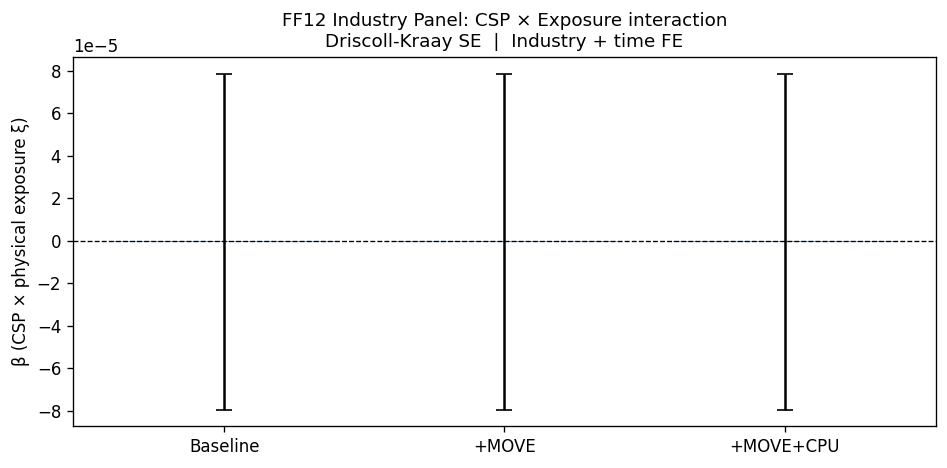

In [25]:
import matplotlib.pyplot as plt

# Plot 1: β across specifications
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(results_df))
ax.bar(x, results_df["beta"], color="steelblue", alpha=0.7)
ax.errorbar(x, results_df["beta"],
            yerr=1.96 * results_df["se"],
            fmt="none", color="black", capsize=5, linewidth=1.5)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xticks(x)
ax.set_xticklabels(results_df.index, fontsize=10)
ax.set_ylabel("β (CSP × physical exposure ξ)")
ax.set_title(
    "FF12 Industry Panel: CSP × Exposure interaction\n"
    "Driscoll-Kraay SE  |  Industry + time FE",
    fontsize=11)
for i, (_, row) in enumerate(results_df.iterrows()):
    stars = ("***" if row["pval"] < 0.01 else
             "**"  if row["pval"] < 0.05 else
             "*"   if row["pval"] < 0.10 else "")
    if stars:
        ax.text(i, row["ci_hi"] * 1.1, stars,
                ha="center", fontsize=12, color="darkred")
fig.tight_layout()
fig.savefig(figdir / "panel12_interaction_beta.png", dpi=150, bbox_inches="tight")
plt.show()


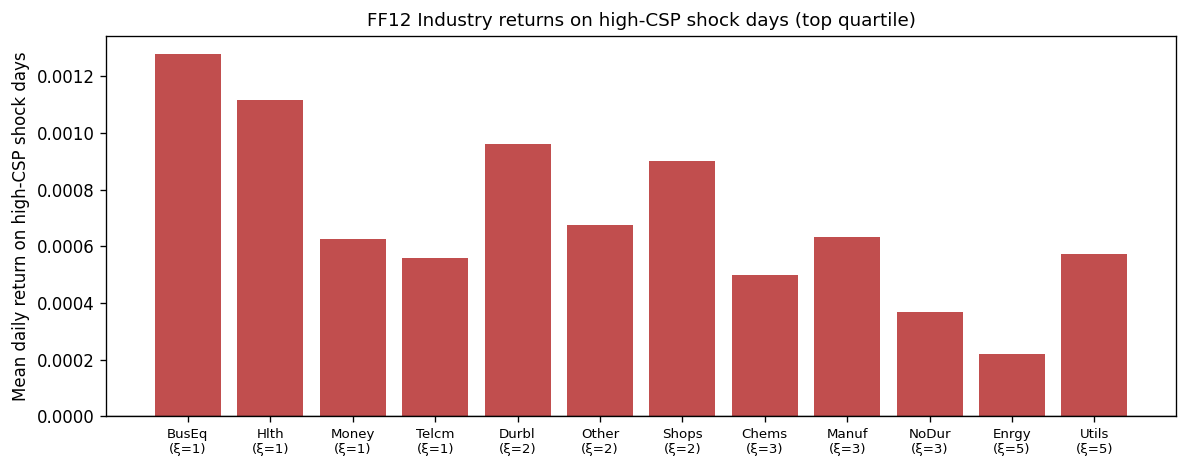

In [26]:
# Plot 2: Returns on high-CSP days
high_csp_days = panel[panel["CSP"] > panel["CSP"].quantile(0.75)]["date"].unique()
industry_means = (panel[panel["date"].isin(high_csp_days)]
    .groupby("industry")
    .agg(mean_ret=("ret", "mean"), xi=("xi", "first"))
    .sort_values("xi"))

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["firebrick" if x > 0 else "steelblue" for x in industry_means["mean_ret"]]
ax.bar(range(len(industry_means)), industry_means["mean_ret"],
       color=colors, alpha=0.8)
ax.set_xticks(range(len(industry_means)))
ax.set_xticklabels(
    [f"{ind}\n(ξ={int(xi)})" for ind, xi in
     zip(industry_means.index, industry_means["xi"])],
    fontsize=8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Mean daily return on high-CSP shock days")
ax.set_title(
    "FF12 Industry returns on high-CSP shock days (top quartile)",
    fontsize=11)
fig.tight_layout()
fig.savefig(figdir / "panel12_industry_returns_highCSP.png", dpi=150, bbox_inches="tight")
plt.show()


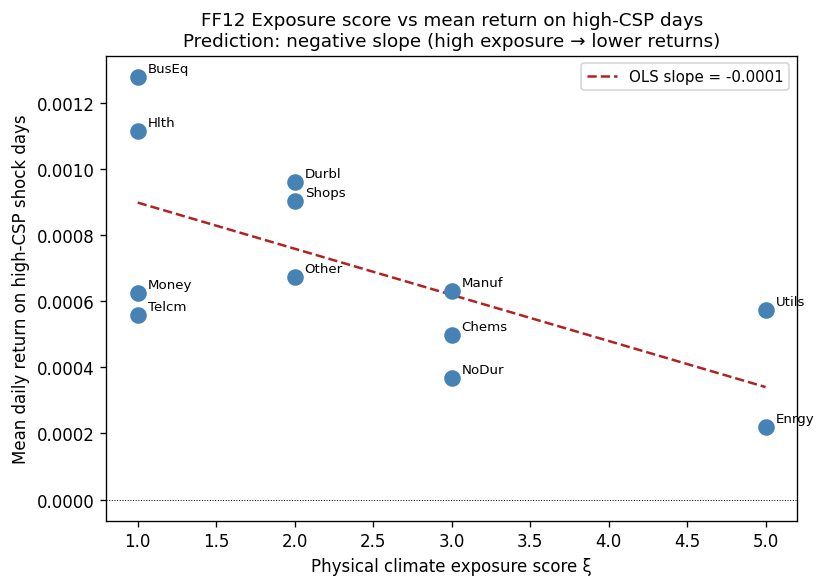


FF12 unconditional sort:
  OLS slope   : -0.000140
  Pearson r   : -0.654  p = 0.0210
  N industries: 12


In [27]:
# Plot 3: Scatter
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(industry_means["xi"], industry_means["mean_ret"],
           s=80, color="steelblue", zorder=3)
for ind, row in industry_means.iterrows():
    ax.annotate(ind, (row["xi"], row["mean_ret"]),
                textcoords="offset points", xytext=(6, 3), fontsize=8)
m, b = np.polyfit(industry_means["xi"], industry_means["mean_ret"], 1)
xi_range = np.linspace(industry_means["xi"].min(),
                       industry_means["xi"].max(), 100)
ax.plot(xi_range, m * xi_range + b, color="firebrick",
        linewidth=1.5, linestyle="--", label=f"OLS slope = {m:.4f}")
ax.axhline(0, color="black", linewidth=0.6, linestyle=":")
ax.set_xlabel("Physical climate exposure score ξ")
ax.set_ylabel("Mean daily return on high-CSP shock days")
ax.set_title(
    "FF12 Exposure score vs mean return on high-CSP days\n"
    "Prediction: negative slope (high exposure → lower returns)",
    fontsize=11)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(figdir / "panel12_exposure_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

from scipy.stats import pearsonr
r, p = pearsonr(industry_means["xi"], industry_means["mean_ret"])
print(f"\nFF12 unconditional sort:")
print(f"  OLS slope   : {m:.6f}")
print(f"  Pearson r   : {r:.3f}  p = {p:.4f}")
print(f"  N industries: {len(industry_means)}")

### FF49 plots

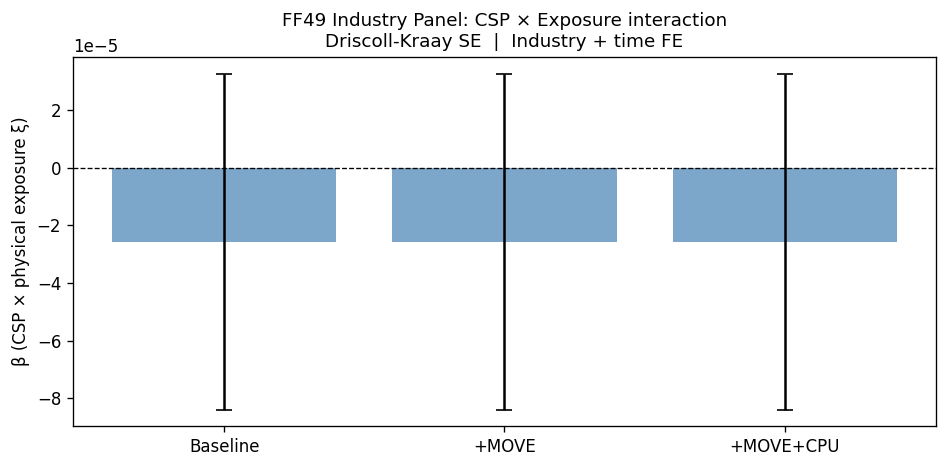

In [28]:
# Plot 1: β across specifications
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(results_df_49))
ax.bar(x, results_df_49["beta"], color="steelblue", alpha=0.7)
ax.errorbar(x, results_df_49["beta"],
            yerr=1.96 * results_df_49["se"],
            fmt="none", color="black", capsize=5, linewidth=1.5)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xticks(x)
ax.set_xticklabels(results_df_49.index, fontsize=10)
ax.set_ylabel("β (CSP × physical exposure ξ)")
ax.set_title(
    "FF49 Industry Panel: CSP × Exposure interaction\n"
    "Driscoll-Kraay SE  |  Industry + time FE",
    fontsize=11)
for i, (_, row) in enumerate(results_df_49.iterrows()):
    stars = ("***" if row["pval"] < 0.01 else
             "**"  if row["pval"] < 0.05 else
             "*"   if row["pval"] < 0.10 else "")
    if stars:
        ax.text(i, row["ci_hi"] * 1.1, stars,
                ha="center", fontsize=12, color="darkred")
fig.tight_layout()
fig.savefig(figdir / "panel49_interaction_beta.png", dpi=150, bbox_inches="tight")
plt.show()

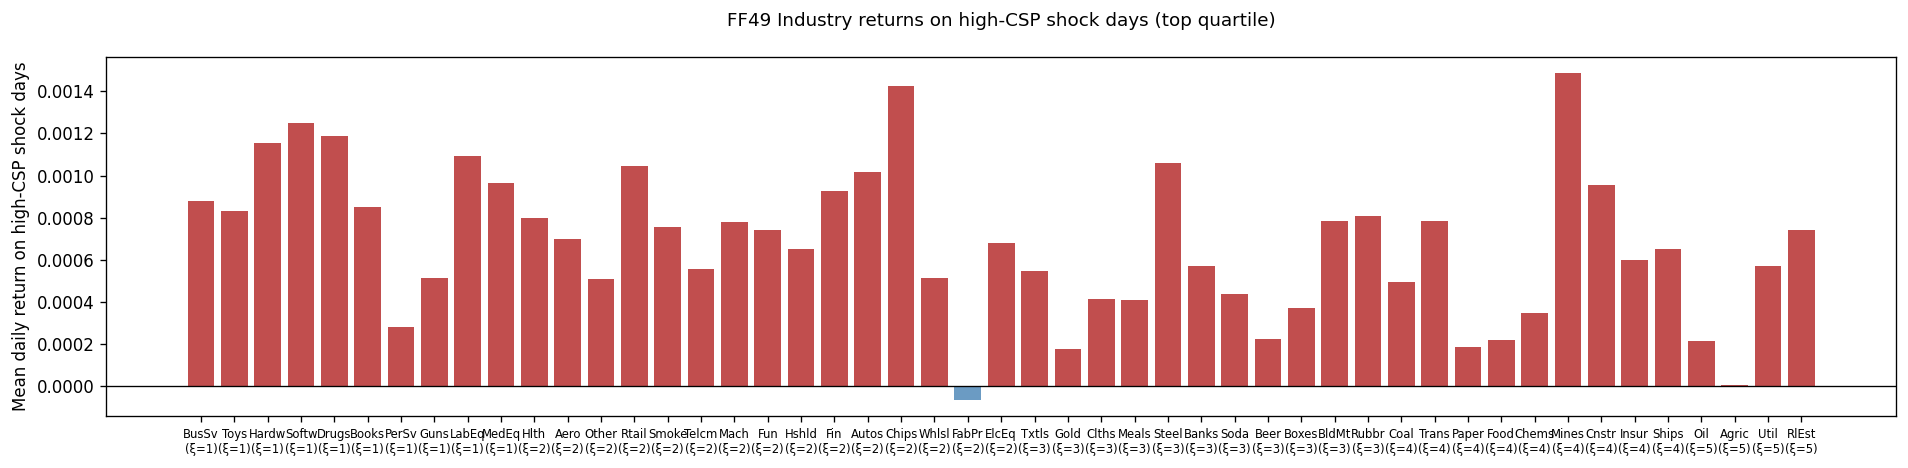

In [29]:
# Plot 2: Returns on high-CSP days
high_csp_days_49 = (panel49[panel49["CSP"] > panel49["CSP"].quantile(0.75)]
                    ["date"].unique())
industry_means_49 = (panel49[panel49["date"].isin(high_csp_days_49)]
    .groupby("industry")
    .agg(mean_ret=("ret", "mean"), xi=("xi", "first"))
    .sort_values("xi"))

fig, ax = plt.subplots(figsize=(16, 4))
colors = ["firebrick" if x > 0 else "steelblue"
          for x in industry_means_49["mean_ret"]]
ax.bar(range(len(industry_means_49)), industry_means_49["mean_ret"],
       color=colors, alpha=0.8)
ax.set_xticks(range(len(industry_means_49)))
ax.set_xticklabels(
    [f"{ind}\n(ξ={int(xi)})" for ind, xi in
     zip(industry_means_49.index, industry_means_49["xi"])],
    fontsize=7)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Mean daily return on high-CSP shock days")
ax.set_title(
    "FF49 Industry returns on high-CSP shock days (top quartile)\n",
    fontsize=11)
fig.tight_layout()
fig.savefig(figdir / "panel49_industry_returns_highCSP.png",
            dpi=150, bbox_inches="tight")
plt.show()


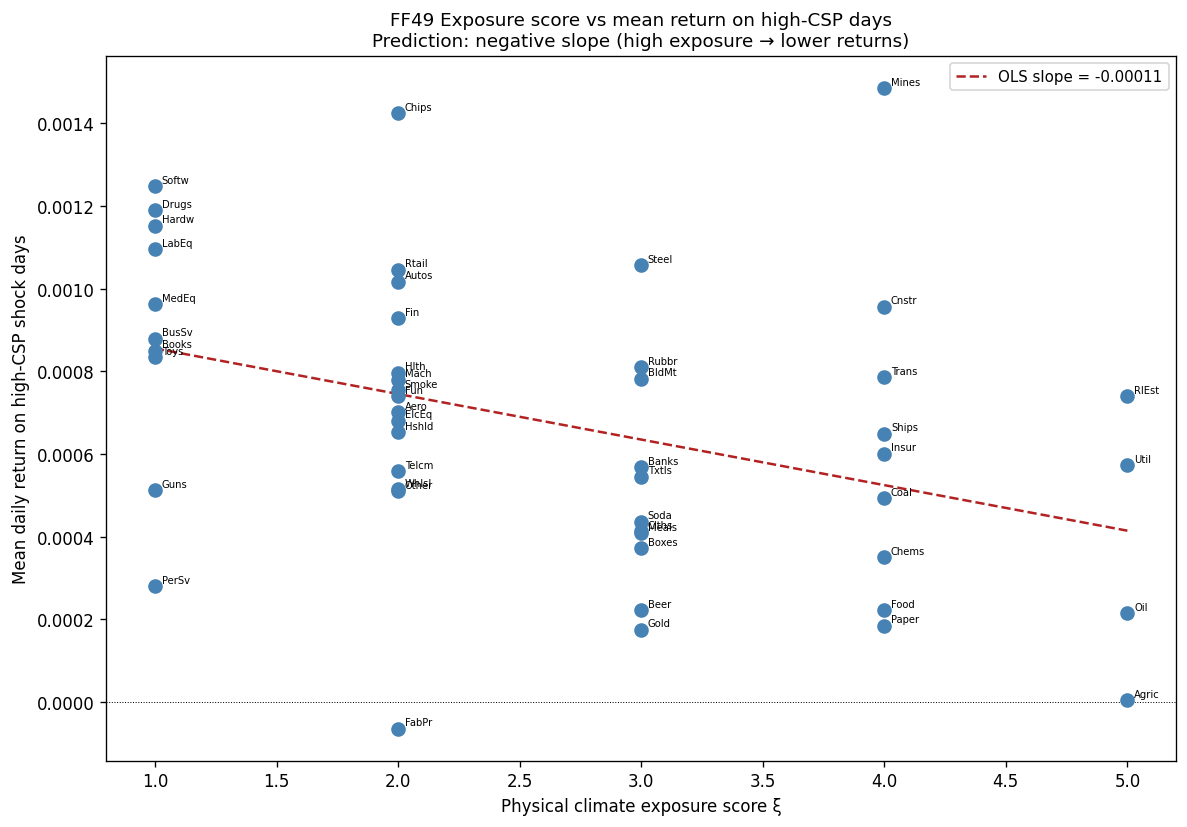


FF49 unconditional sort:
  OLS slope   : -0.000110
  Pearson r   : -0.390  p = 0.0055
  N industries: 49


In [30]:

# Plot 3: Scatter
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(industry_means_49["xi"], industry_means_49["mean_ret"],
           s=60, color="steelblue", zorder=3)
for ind, row in industry_means_49.iterrows():
    ax.annotate(ind, (row["xi"], row["mean_ret"]),
                textcoords="offset points", xytext=(4, 2), fontsize=6)
m49, b49 = np.polyfit(
    industry_means_49["xi"], industry_means_49["mean_ret"], 1)
xi_range = np.linspace(industry_means_49["xi"].min(),
                       industry_means_49["xi"].max(), 100)
ax.plot(xi_range, m49 * xi_range + b49, color="firebrick",
        linewidth=1.5, linestyle="--", label=f"OLS slope = {m49:.5f}")
ax.axhline(0, color="black", linewidth=0.6, linestyle=":")
ax.set_xlabel("Physical climate exposure score ξ")
ax.set_ylabel("Mean daily return on high-CSP shock days")
ax.set_title(
    "FF49 Exposure score vs mean return on high-CSP days\n"
    "Prediction: negative slope (high exposure → lower returns)",
    fontsize=11)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(figdir / "panel49_exposure_scatter.png",
            dpi=150, bbox_inches="tight")
plt.show()

from scipy.stats import pearsonr
r49, p49 = pearsonr(industry_means_49["xi"], industry_means_49["mean_ret"])
print(f"\nFF49 unconditional sort:")
print(f"  OLS slope   : {m49:.6f}")
print(f"  Pearson r   : {r49:.3f}  p = {p49:.4f}")
print(f"  N industries: {len(industry_means_49)}")

## Comparison

### FF12 vs FF49

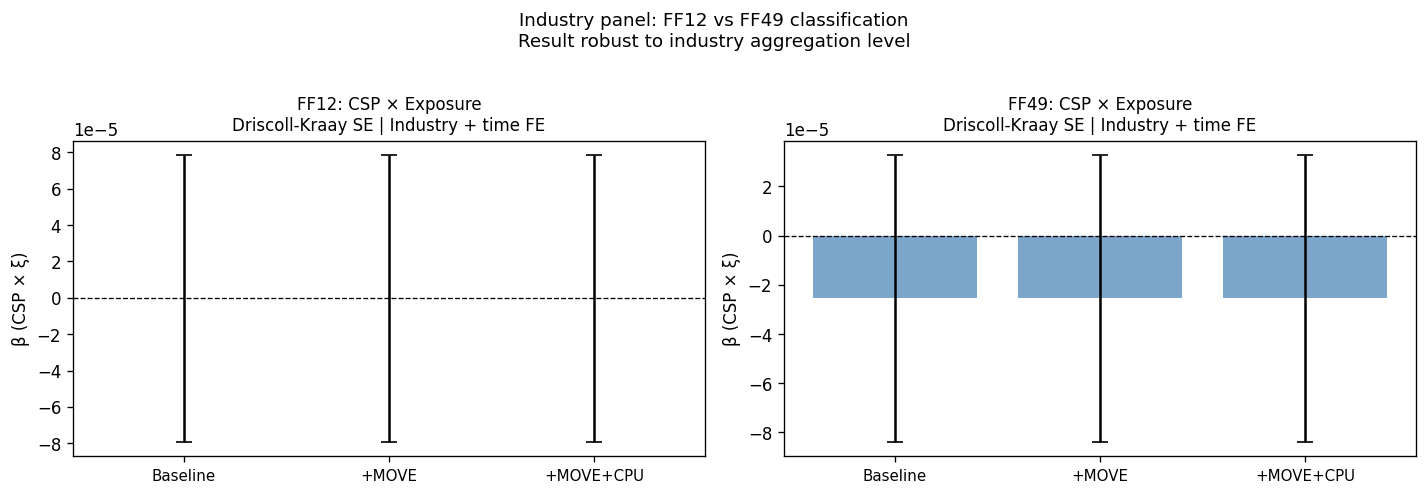

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, res_df, label in [
    (axes[0], results_df,    "FF12"),
    (axes[1], results_df_49, "FF49"),
]:
    x = range(len(res_df))
    ax.bar(x, res_df["beta"], color="steelblue", alpha=0.7)
    ax.errorbar(x, res_df["beta"],
                yerr=1.96 * res_df["se"],
                fmt="none", color="black", capsize=5, linewidth=1.5)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(res_df.index, fontsize=9)
    ax.set_ylabel("β (CSP × ξ)")
    ax.set_title(f"{label}: CSP × Exposure\nDriscoll-Kraay SE | Industry + time FE",
                 fontsize=10)
    for i, (_, row) in enumerate(res_df.iterrows()):
        stars = ("***" if row["pval"] < 0.01 else
                 "**"  if row["pval"] < 0.05 else
                 "*"   if row["pval"] < 0.10 else "")
        if stars:
            ax.text(i, row["ci_hi"] * 1.1, stars,
                    ha="center", fontsize=11, color="darkred")

fig.suptitle(
    "Industry panel: FF12 vs FF49 classification\n"
    "Result robust to industry aggregation level",
    fontsize=11, y=1.02)
fig.tight_layout()
fig.savefig(figdir / "panel_FF12_vs_FF49.png", dpi=150, bbox_inches="tight")
plt.show()

### Sub-sample Stability


── FF12 sub-sample stability ──
  2008–2015: β=5.3069e-05  SE=4.4976e-05  p=0.2380  n=21,252  
  2016–2019: β=-1.2177e-05  SE=8.7329e-05  p=0.8891  n=12,072  
  2020–2025: β=-6.3467e-05  SE=8.6201e-05  p=0.4616  n=18,096  


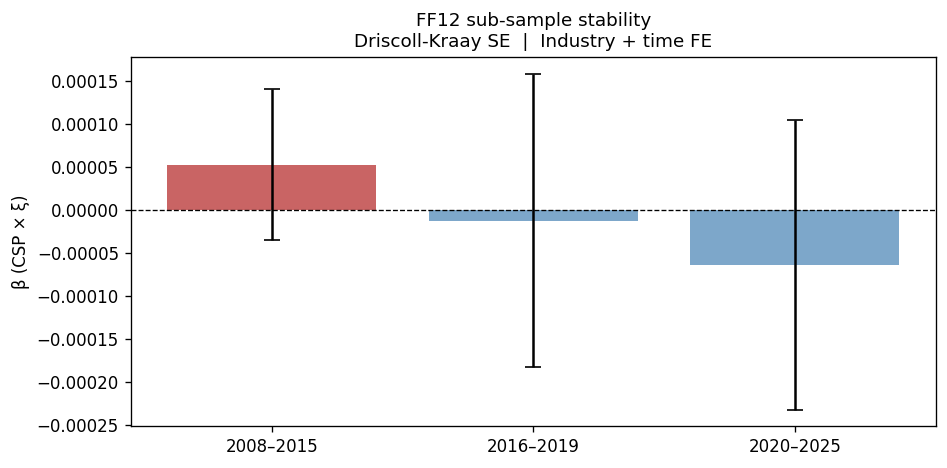


── FF49 sub-sample stability ──
  2008–2015: β=3.3702e-05  SE=3.3316e-05  p=0.3117  n=86,779  
  2016–2019: β=-6.9750e-05  SE=5.8730e-05  p=0.2350  n=49,294  
  2020–2025: β=-7.2887e-05  SE=6.6294e-05  p=0.2716  n=73,892  


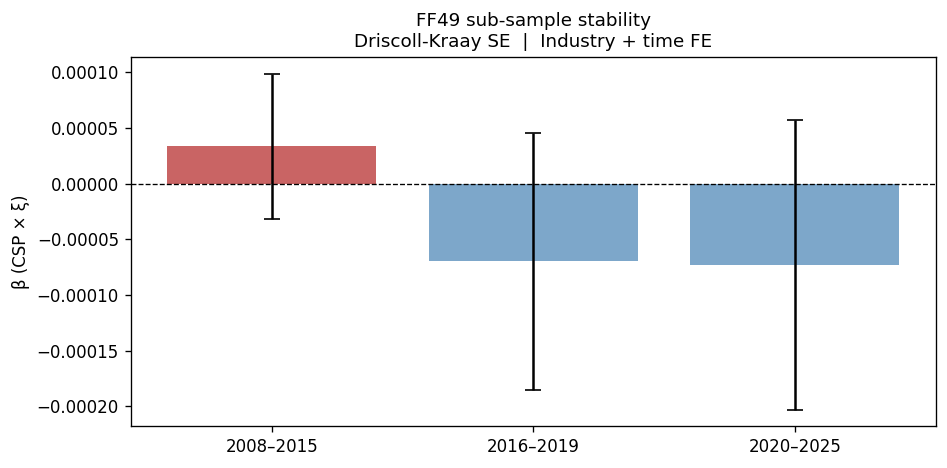

In [32]:
SPLIT_DATES = {
    "2008–2015": ("2008-01-01", "2015-12-31"),
    "2016–2019": ("2016-01-01", "2019-12-31"),
    "2020–2025": ("2020-01-01", "2025-12-31"),
}

for ff_label, panel_in, res_df_in in [
    ("FF12", panel,   results_df),
    ("FF49", panel49, results_df_49),
]:
    print(f"\n── {ff_label} sub-sample stability ──")
    sub_rows = []

    for label, (start, end) in SPLIT_DATES.items():
        sub = panel_in[
            (panel_in["date"] >= start) &
            (panel_in["date"] <= end)
        ].copy()

        if len(sub) < 100:
            print(f"  {label}: insufficient obs ({len(sub)})")
            continue

        sub["CSP_xi"] = sub["CSP"] * sub["xi_norm"]
        indexed = sub.set_index(["industry", "date"])[
            ["ret", "CSP_xi", "SSI_lag1"]].dropna()

        try:
            mod = PanelOLS(indexed["ret"],
                           indexed[["CSP_xi", "SSI_lag1"]],
                           entity_effects=True,
                           time_effects=True,
                           drop_absorbed=True)
            res = mod.fit(cov_type="driscoll-kraay", bandwidth=10)
            beta = float(res.params["CSP_xi"])
            se   = float(res.std_errors["CSP_xi"])
            pval = float(res.pvalues["CSP_xi"])
            stars = ("***" if pval < 0.01 else
                     "**"  if pval < 0.05 else
                     "*"   if pval < 0.10 else "")
            sub_rows.append({
                "period": label, "beta": beta,
                "se": se, "pval": pval, "n": int(res.nobs)})
            print(f"  {label}: β={beta:.4e}  SE={se:.4e}  "
                  f"p={pval:.4f}  n={int(res.nobs):,}  {stars}")
        except Exception as e:
            print(f"  {label}: failed — {e}")

    if sub_rows:
        sub_df = pd.DataFrame(sub_rows)
        fig, ax = plt.subplots(figsize=(8, 4))
        x = range(len(sub_df))
        colors = ["steelblue" if b < 0 else "firebrick"
                  for b in sub_df["beta"]]
        ax.bar(x, sub_df["beta"], color=colors, alpha=0.7)
        ax.errorbar(x, sub_df["beta"],
                    yerr=1.96 * sub_df["se"],
                    fmt="none", color="black", capsize=5)
        ax.axhline(0, color="black", lw=0.8, linestyle="--")
        ax.set_xticks(x)
        ax.set_xticklabels(sub_df["period"], fontsize=10)
        ax.set_ylabel("β (CSP × ξ)")
        ax.set_title(
            f"{ff_label} sub-sample stability\n"
            "Driscoll-Kraay SE  |  Industry + time FE",
            fontsize=11)
        fig.tight_layout()
        fig.savefig(figdir / f"panel_{ff_label.lower()}_subsample.png",
                    dpi=150, bbox_inches="tight")
        plt.show()

## Temporal Aggregation Robustness


FF12 — Temporal aggregation robustness
  Daily        β=-3.6602e-07  SE=4.0277e-05  t=-0.009  p=0.9927  n=51,420  
  Weekly       β=-5.3677e-04  SE=4.5874e-04  t=-1.170  p=0.2420  n=10,680  
  Monthly      β=9.7973e-04  SE=3.7061e-03  t=0.264  p=0.7915  n=2,460  
  Quarterly    β=-1.1026e-02  SE=3.0720e-02  t=-0.359  p=0.7198  n=828  


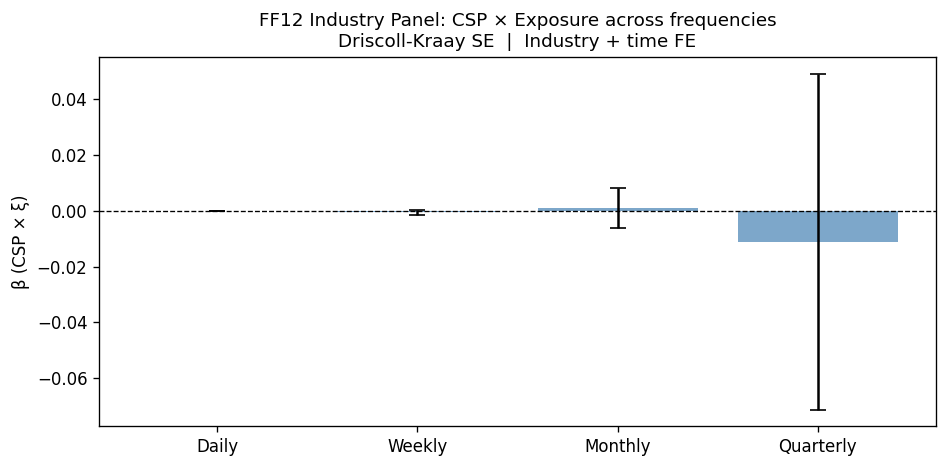


FF49 — Temporal aggregation robustness
  Daily        β=-2.5586e-05  SE=2.9776e-05  t=-0.859  p=0.3902  n=209,965  
  Weekly       β=-6.2338e-04  SE=3.5568e-04  t=-1.753  p=0.0797  n=43,610  *
  Monthly      β=-2.3703e-03  SE=2.2909e-03  t=-1.035  p=0.3009  n=10,045  
  Quarterly    β=3.1081e-03  SE=1.7898e-02  t=0.174  p=0.8621  n=3,381  


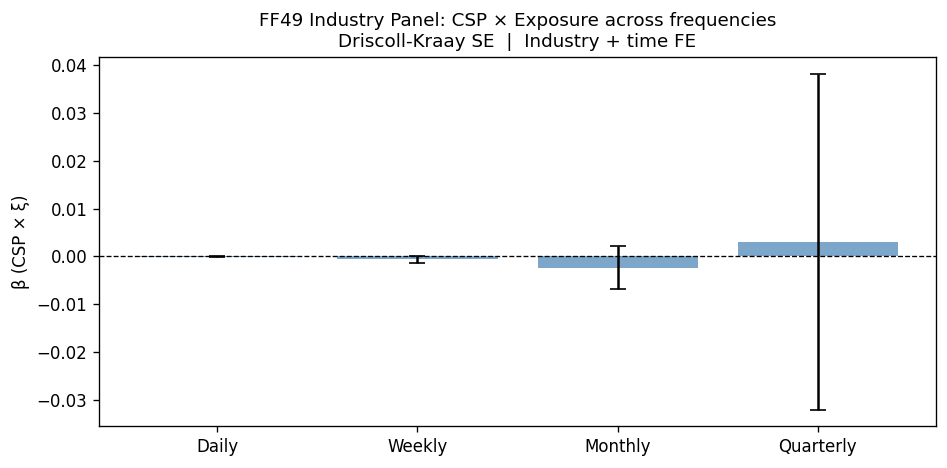

In [33]:
def build_agg_panel(ff_df, available_inds, exposure_df_in,
                    pcra_df, freq, move_df_in=None):
    if freq is None:
        ret_agg  = ff_df[["date"] + available_inds].copy()
        pcra_agg = pcra_df[["date", "CSP", "SSI_lag1"]].copy()
        pcra_agg = pcra_agg.rename(columns={"CSP": "CSP_agg"})
        mv_agg   = move_df_in[["date", "move"]].copy() if move_df_in is not None else None
    else:
        ret_agg = (ff_df.set_index("date")[available_inds]
                        .resample(freq)
                        .apply(lambda x: (1 + x).prod() - 1)
                        .reset_index())
        pcra_agg = (pcra_df.set_index("date")
                           .resample(freq)
                           .agg(CSP_agg=("CSP", "mean"),
                                SSI_lag1=("SSI_lag1", "last"))
                           .dropna(subset=["CSP_agg"])
                           .reset_index())
        mv_agg = (None if move_df_in is None else
                  move_df_in.set_index("date")["move"]
                            .resample(freq).mean().dropna()
                            .reset_index())

    long = ret_agg.melt(
        id_vars="date", value_vars=available_inds,
        var_name="industry", value_name="ret")
    long = long.merge(exposure_df_in, on="industry", how="left")
    long = long.merge(pcra_agg, on="date", how="inner")
    if mv_agg is not None:
        long = long.merge(mv_agg, on="date", how="left")
    long = long.dropna(subset=["ret", "CSP_agg", "SSI_lag1", "xi_norm"])
    long["CSP_xi"] = long["CSP_agg"] * long["xi_norm"]
    return long.sort_values(["industry", "date"]).reset_index(drop=True)

def run_agg_panel(panel_agg, extra_vars, label, dk_bw):
    reg_vars = ["CSP_xi", "SSI_lag1"] + extra_vars
    sub      = (panel_agg.set_index(["industry", "date"])
                         [["ret"] + reg_vars].dropna())
    mod = PanelOLS(sub["ret"], sub[reg_vars],
                   entity_effects=True, time_effects=True,
                   drop_absorbed=True)
    res = mod.fit(cov_type="driscoll-kraay", bandwidth=dk_bw)
    return {
        "label": label,
        "beta":  float(res.params["CSP_xi"]),
        "se":    float(res.std_errors["CSP_xi"]),
        "tstat": float(res.tstats["CSP_xi"]),
        "pval":  float(res.pvalues["CSP_xi"]),
        "nobs":  int(res.nobs),
    }

FREQ_CONFIG = {
    "Daily":     {"freq": None,    "dk_bw": 10},
    "Weekly":    {"freq": "W-FRI", "dk_bw": 4},
    "Monthly":   {"freq": "ME",    "dk_bw": 3},
    "Quarterly": {"freq": "QE",    "dk_bw": 2},
}

move_in = move_df if "move_df" in globals() and move_df is not None else None

for ff_label, ff_df_in, avail_in, exp_in in [
    ("FF12", ff12, available_industries,    exposure_df),
    ("FF49", ff49, available_industries_49, exposure_df_49),
]:
    print(f"\n{'='*60}")
    print(f"{ff_label} — Temporal aggregation robustness")
    print(f"{'='*60}")
    agg_rows = []

    for freq_name, cfg in FREQ_CONFIG.items():
        p = build_agg_panel(
            ff_df_in, avail_in, exp_in,
            pcra_daily, cfg["freq"], move_in)
        extra = ["move"] if "move" in p.columns else []
        row   = run_agg_panel(p, extra, f"{freq_name}", cfg["dk_bw"])
        agg_rows.append(row)
        stars = ("***" if row["pval"] < 0.01 else
                 "**"  if row["pval"] < 0.05 else
                 "*"   if row["pval"] < 0.10 else "")
        print(f"  {freq_name:<12} β={row['beta']:.4e}  "
              f"SE={row['se']:.4e}  t={row['tstat']:.3f}  "
              f"p={row['pval']:.4f}  n={row['nobs']:,}  {stars}")

    # Plot
    agg_df = pd.DataFrame(agg_rows)
    agg_df["ci_lo"] = agg_df["beta"] - 1.96 * agg_df["se"]
    agg_df["ci_hi"] = agg_df["beta"] + 1.96 * agg_df["se"]

    fig, ax = plt.subplots(figsize=(8, 4))
    x = range(len(agg_df))
    ax.bar(x, agg_df["beta"], color="steelblue", alpha=0.7)
    ax.errorbar(x, agg_df["beta"], yerr=1.96 * agg_df["se"],
                fmt="none", color="black", capsize=5, linewidth=1.5)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xticks(x)
    ax.set_xticklabels(agg_df["label"], fontsize=10)
    ax.set_ylabel("β (CSP × ξ)")
    ax.set_title(
        f"{ff_label} Industry Panel: CSP × Exposure across frequencies\n"
        "Driscoll-Kraay SE  |  Industry + time FE",
        fontsize=11)
    fig.tight_layout()
    fig.savefig(figdir / f"panel_{ff_label.lower()}_frequencies.png",
                dpi=150, bbox_inches="tight")
    plt.show()

In [34]:
def run_agg_panel(panel_agg, extra_vars, label, dk_bw):
    reg_vars = ["CSP_xi", "SSI_lag1"] + extra_vars
    sub = panel_agg.set_index(["industry", "date"])[["ret"] + reg_vars].dropna()
    res = PanelOLS(sub["ret"], sub[reg_vars],
                   entity_effects=True, time_effects=True,
                   drop_absorbed=True).fit(cov_type="driscoll-kraay", bandwidth=dk_bw)
    def grab(n):
        if n in res.params.index:
            return float(res.params[n]), float(res.std_errors[n]), float(res.pvalues[n])
        return np.nan, np.nan, np.nan
    b, th = grab("CSP_xi"), grab("SSI_xi")
    return {"label": label,
            "beta": b[0],  "beta_se": b[1],  "beta_p": b[2],
            "theta": th[0], "theta_se": th[1], "theta_p": th[2],
            "nobs": int(res.nobs), "r2": float(res.rsquared_within), "dk_bw": dk_bw}

def _stars(p): return "" if np.isnan(p) else ("***" if p<.01 else "**" if p<.05 else "*" if p<.10 else "")
def _cell(est, se, p): return "—" if np.isnan(est) else f"{est:.3e}{_stars(p)} ({se:.3e})"

def panel_summary(ff_df, avail, exp, pcra_daily, tax_label):
    pdl = build_agg_panel(ff_df, avail, exp, pcra_daily, None)
    pwk = build_agg_panel(ff_df, avail, exp, pcra_daily, "W-FRI")
    for p in (pdl, pwk):
        p["SSI_xi"] = p["SSI_lag1"] * p["xi_norm"]

    specs = [run_agg_panel(pdl, [],         "Baseline",           10),
             run_agg_panel(pdl, ["SSI_xi"], "With-SSI",           10),
             run_agg_panel(pwk, ["SSI_xi"], "Weekly-aggregation", 4)]
    cols = [s["label"] for s in specs]

    tbl = pd.DataFrame(index=["CSP×ξ  (β)", "SSI×ξ  (θ)", "Industry FE",
                              "Date FE", "Observations", "Within-R²"],
                       columns=cols, dtype=object)
    for s in specs:
        c = s["label"]
        tbl.loc["CSP×ξ  (β)", c]  = _cell(s["beta"],  s["beta_se"],  s["beta_p"])
        tbl.loc["SSI×ξ  (θ)", c]  = _cell(s["theta"], s["theta_se"], s["theta_p"])
        tbl.loc["Industry FE", c] = "Yes"
        tbl.loc["Date FE", c]     = "Yes"
        tbl.loc["Observations", c] = f"{s['nobs']:,}"
        tbl.loc["Within-R²", c]   = f"{s['r2']:.2e}"

    # honest significance line: derive it, don't hardcode it
    ps = [s[k] for s in specs for k in ("beta_p", "theta_p") if not np.isnan(s[k])]
    sig_line = ("No interaction is significant at conventional levels."
                if not any(p < 0.10 for p in ps)
                else "Significant interactions are flagged by stars above.")

    print(f"\n{'='*78}\nTable: Industry-exposure panel — {tax_label}\n{'='*78}")
    print(tbl.to_string())
    print("-"*78)
    print("Driscoll–Kraay standard errors in parentheses (bandwidth 10 for the daily")
    print("Baseline/With-SSI columns, 4 for the weekly column). Industry and date fixed")
    print("effects in every column; aggregate regressors (CSP, SSI_{t-1}, MOVE) are")
    print("absorbed by the date effects, so only the exposure interactions are identified.")
    print("Within-R² is mechanically near zero given the two-way fixed effects —")
    print("identification comes from the interaction terms alone, not explained variation.")
    print(f"*** p<0.01, ** p<0.05, * p<0.10. {sig_line}")

panel_summary(ff12, available_industries,    exposure_df,    pcra_daily, "FF12")
panel_summary(ff49, available_industries_49, exposure_df_49, pcra_daily, "FF49")


Table: Industry-exposure panel — FF12
                            Baseline               With-SSI      Weekly-aggregation
CSP×ξ  (β)    -3.660e-07 (4.028e-05)  6.784e-07 (4.019e-05)  -5.448e-04 (4.642e-04)
SSI×ξ  (θ)                         —  1.189e-02 (2.631e-02)   2.789e-02 (1.331e-01)
Industry FE                      Yes                    Yes                     Yes
Date FE                          Yes                    Yes                     Yes
Observations                  51,420                 51,420                  10,680
Within-R²                   6.57e-10               1.64e-06                6.44e-05
------------------------------------------------------------------------------
Driscoll–Kraay standard errors in parentheses (bandwidth 10 for the daily
Baseline/With-SSI columns, 4 for the weekly column). Industry and date fixed
effects in every column; aggregate regressors (CSP, SSI_{t-1}, MOVE) are
absorbed by the date effects, so only the exposure interactions are id

In [35]:
import numpy as np
import pandas as pd
from linearmodels.panel import PanelOLS

ENTITY, TIME, RET = "industry", "date", "ret"

def _stars(p):
    return "" if np.isnan(p) else (
        "***" if p < .01 else "**" if p < .05 else "*" if p < .10 else "")

def _cell(est, se, p):
    return "—" if np.isnan(est) else f"{est:.3e}{_stars(p)} ({se:.3e})"

def run_agg_panel(panel, interactions, dk_bw):
    """Two-way FE panel on interaction terms only; Driscoll-Kraay HAC SEs."""

    # ── Deduplicate (industry, date) before indexing ──────────────────────────
    # Duplicates arise when build_agg_panel merges on date and the PCRA daily
    # or FF return file contains repeated rows (e.g. from a re-download or
    # a left-join that matched multiple PCRA rows per return row).
    n_before = len(panel)
    dupes = panel.duplicated(subset=[ENTITY, TIME], keep=False)
    n_dupes = dupes.sum()

    if n_dupes > 0:
        # Show the first few duplicated (industry, date) pairs for diagnosis
        dupe_pairs = (panel.loc[dupes, [ENTITY, TIME]]
                      .drop_duplicates()
                      .head(5))
        print(f"  WARNING: {n_dupes} duplicate ({ENTITY},{TIME}) rows found "
              f"({n_dupes/n_before:.1%} of panel). "
              f"Keeping first occurrence per pair.")
        print(f"  Sample duplicate pairs:\n{dupe_pairs.to_string(index=False)}")
        panel = panel.drop_duplicates(subset=[ENTITY, TIME], keep="first")
        print(f"  Panel reduced: {n_before:,} → {len(panel):,} rows")

    s = panel.set_index([ENTITY, TIME]).sort_index()

    # Verify interactions exist as columns
    missing = [c for c in interactions if c not in s.columns]
    if missing:
        raise KeyError(f"Interaction columns not found in panel: {missing}. "
                       f"Available: {list(s.columns)}")

    res = PanelOLS(
        s[RET], s[interactions],
        entity_effects=True,
        time_effects=True,
        drop_absorbed=True
    ).fit(cov_type="kernel", kernel="bartlett", bandwidth=dk_bw)

    def g(n):
        return (float(res.params[n]),
                float(res.std_errors[n]),
                float(res.pvalues[n])) if n in res.params.index \
               else (np.nan, np.nan, np.nan)

    b, t = g("CSP_xi"), g("SSI_xi")
    return dict(
        beta=b[0],    beta_se=b[1],    beta_p=b[2],
        theta=t[0],   theta_se=t[1],   theta_p=t[2],
        nobs=int(res.nobs),
        r2=float(res.rsquared_within),
        dk_bw=dk_bw
    )


def panel_summary(ff_df, avail, exp, pcra_daily, tax_label):
    p_daily  = build_agg_panel(ff_df, avail, exp, pcra_daily, None)
    p_weekly = build_agg_panel(ff_df, avail, exp, pcra_daily, "W-FRI")
    for p in (p_daily, p_weekly):
        p["SSI_xi"] = p["SSI_lag1"] * p["xi_norm"]

    specs = {
        "Baseline"          : run_agg_panel(p_daily,  ["CSP_xi"],             dk_bw=10),
        "With-SSI"          : run_agg_panel(p_daily,  ["CSP_xi", "SSI_xi"],  dk_bw=10),
        "Weekly-aggregation": run_agg_panel(p_weekly, ["CSP_xi", "SSI_xi"],  dk_bw=4),
    }

    rows = {
        "CSP×ξ (β)"   : {c: _cell(s["beta"],  s["beta_se"],  s["beta_p"])  for c, s in specs.items()},
        "SSI×ξ (θ)"   : {c: _cell(s["theta"], s["theta_se"], s["theta_p"]) for c, s in specs.items()},
        "Industry FE" : {c: "Yes"             for c in specs},
        "Date FE"     : {c: "Yes"             for c in specs},
        "Observations": {c: f"{s['nobs']:,}"  for c, s in specs.items()},
        "Within-R²"   : {c: f"{s['r2']:.2e}" for c, s in specs.items()},
    }
    tbl = pd.DataFrame(rows).T[list(specs)]
    tbl.columns.name = tax_label

    ps = [s[k] for s in specs.values()
          for k in ("beta_p", "theta_p") if not np.isnan(s[k])]
    sig_line = ("No interaction is significant at conventional levels."
                if not any(p < 0.10 for p in ps)
                else "Significant interactions are flagged by stars above.")

    print(f"\n=== Industry-exposure panel — {tax_label} ===")
    print(tbl.to_string())
    print("Driscoll-Kraay SEs (bandwidth 10 daily, 4 weekly); "
          "industry + date FE every column.")
    print("Aggregate regressors absorbed by date effects; "
          "only interactions identified.")
    print(f"*** p<0.01, ** p<0.05, * p<0.10. {sig_line}")
    return tbl


ff12_table = panel_summary(ff12, available_industries,    exposure_df,    pcra_daily, "FF12")
ff49_table = panel_summary(ff49, available_industries_49, exposure_df_49, pcra_daily, "FF49")
# LaTeX: print(ff49_table.to_latex(escape=False, column_format="lccc"))


=== Industry-exposure panel — FF12 ===
FF12                        Baseline               With-SSI      Weekly-aggregation
CSP×ξ (β)     -3.660e-07 (4.028e-05)  6.784e-07 (4.019e-05)  -5.448e-04 (4.642e-04)
SSI×ξ (θ)                          —  1.189e-02 (2.631e-02)   2.789e-02 (1.331e-01)
Industry FE                      Yes                    Yes                     Yes
Date FE                          Yes                    Yes                     Yes
Observations                  51,420                 51,420                  10,680
Within-R²                   6.57e-10               1.64e-06                6.44e-05
Driscoll-Kraay SEs (bandwidth 10 daily, 4 weekly); industry + date FE every column.
Aggregate regressors absorbed by date effects; only interactions identified.
*** p<0.01, ** p<0.05, * p<0.10. No interaction is significant at conventional levels.

=== Industry-exposure panel — FF49 ===
FF49                        Baseline                With-SSI       Weekly-aggregatio

In [36]:
p_weekly = build_agg_panel(ff49, available_industries_49, exposure_df_49, pcra_daily, "W-FRI")
p_weekly["SSI_xi"] = p_weekly["SSI_lag1"] * p_weekly["xi_norm"]
res = run_agg_panel(p_weekly, ["CSP_xi", "SSI_xi"], dk_bw=4)
print(f"FF49 weekly  β = {res['beta']:.3e}   SE = {res['beta_se']:.3e}   "
      f"t = {res['beta']/res['beta_se']:.2f}   p = {res['beta_p']:.4f}")

FF49 weekly  β = -6.133e-04   SE = 3.543e-04   t = -1.73   p = 0.0835


In [37]:
res = run_agg_panel(p_weekly, ["CSP_xi", "SSI_xi"], dk_bw=4)
print(f"FF49 weekly  β = {res['beta']:.3e}   SE = {res['beta_se']:.3e}   "
      f"t = {res['beta']/res['beta_se']:.2f}   p = {res['beta_p']:.4f}")

FF49 weekly  β = -6.133e-04   SE = 3.543e-04   t = -1.73   p = 0.0835


In [38]:
for name, df in [("ff12", ff12), ("ff49", ff49)]:
    print(f"\n--- {name} ---")
    print("shape:", df.shape)
    print("columns:", list(df.columns)[:12], "..." if df.shape[1] > 12 else "")
    print("index name:", df.index.name, "| index type:", type(df.index).__name__)
    print(df.head(3).to_string())


--- ff12 ---
shape: (26233, 13)
columns: ['date', 'NoDur', 'Durbl', 'Manuf', 'Enrgy', 'Chems', 'BusEq', 'Telcm', 'Utils', 'Shops', 'Hlth', 'Money'] ...
index name: None | index type: RangeIndex
        date    NoDur     Durbl     Manuf    Enrgy    Chems     BusEq     Telcm    Utils     Shops     Hlth     Money     Other
0 1926-07-01 0.000200 -0.002800 -0.004100 0.005700 0.005200 -0.002500 -0.000200 0.006100 -0.000100 0.009700  0.005800  0.001900
1 1926-07-02 0.002900  0.010700  0.008300 0.006400 0.009700  0.001300  0.002600 0.004700  0.000100 0.001300 -0.001600  0.001100
2 1926-07-06 0.002400  0.007200  0.002400 0.001700 0.002300  0.004400  0.001700 0.007300 -0.002300 0.002300  0.002000 -0.002000

--- ff49 ---
shape: (26233, 50)
columns: ['date', 'Agric', 'Food', 'Soda', 'Beer', 'Smoke', 'Toys', 'Fun', 'Books', 'Hshld', 'Clths', 'Hlth'] ...
index name: None | index type: RangeIndex
        date     Agric      Food  Soda      Beer    Smoke      Toys       Fun     Books     Hshld     Cl

In [39]:
# melt is clean because each date appears once and each industry is one column
ff12_long = ff12.melt(id_vars="date", var_name="industry", value_name="ret")
ff49_long = ff49.melt(id_vars="date", var_name="industry", value_name="ret")
for name, lf in [("ff12_long", ff12_long), ("ff49_long", ff49_long)]:
    print(name, "rows:", len(lf), "| dup (industry,date):",
          lf.duplicated(["industry", "date"]).sum())

# the two things merged ONTO returns inside build_agg_panel — the actual suspects
print("pcra_daily rows:", len(pcra_daily),
      "| unique dates:", pcra_daily["date"].nunique(),
      "| dup dates:", pcra_daily["date"].duplicated().sum())
print("exposure_df dup industries   :", exposure_df["industry"].duplicated().sum())
print("exposure_df_49 dup industries:", exposure_df_49["industry"].duplicated().sum())

ff12_long rows: 314796 | dup (industry,date): 0
ff49_long rows: 1285417 | dup (industry,date): 0
pcra_daily rows: 4697 | unique dates: 4697 | dup dates: 0
exposure_df dup industries   : 0
exposure_df_49 dup industries: 0


In [40]:
pcra_daily = (pcra_daily
              .drop_duplicates("date")
              .sort_values("date")
              .reset_index(drop=True))
print("after dedupe — rows:", len(pcra_daily),
      "dup dates:", pcra_daily["date"].duplicated().sum())   # expect 0

after dedupe — rows: 4697 dup dates: 0


In [41]:
for name, df in [("ff12", ff12), ("ff49", ff49)]:
    dd = df["date"].duplicated().sum()
    print(f"{name}: rows={len(df)} unique_dates={df['date'].nunique()} dup_dates={dd}")
    # are the duplicate rows identical, or different values for the same date?
    d = df[df["date"].duplicated(keep=False)].sort_values("date")
    if len(d):
        first_date = d["date"].iloc[0]
        print(f"   example — both rows for {first_date.date()}:")
        print(d[d["date"] == first_date].to_string())

ff12: rows=26233 unique_dates=26233 dup_dates=0
ff49: rows=26233 unique_dates=26233 dup_dates=0


In [42]:
ff12 = ff12.drop_duplicates("date").sort_values("date").reset_index(drop=True)
ff49 = ff49.drop_duplicates("date").sort_values("date").reset_index(drop=True)

In [43]:
import pandas as pd

# --- 1. inspect: are duplicate-date rows identical, or genuinely different? ---
for name, df in [("ff12", ff12), ("ff49", ff49)]:
    dd = df["date"].duplicated().sum()
    # count rows that are exact duplicates across ALL columns, not just date
    full_dup = df.duplicated(keep=False).sum()
    print(f"{name}: rows={len(df):,} unique_dates={df['date'].nunique():,} "
          f"dup_dates={dd:,} exact_full_dups={full_dup:,}")

# --- 2. dedupe the wide frames ---
# If exact_full_dups == dup_dates above, the duplicates are identical copies and this is safe.
# If they differ, STOP — the file has stacked blocks (e.g. VW + EW) and you must slice to the
# value-weighted block at load time instead of deduping blindly.
def dedupe_wide(df, name):
    before = len(df)
    out = df.drop_duplicates("date").sort_values("date").reset_index(drop=True)
    assert out["date"].duplicated().sum() == 0, f"{name}: still has duplicate dates"
    print(f"{name}: {before:,} -> {len(out):,} rows ({before - len(out):,} removed)")
    return out

ff12 = dedupe_wide(ff12, "ff12")
ff49 = dedupe_wide(ff49, "ff49")

# --- 3. melt to long and confirm the panel is clean ---
def to_long(df, name):
    lf = df.melt(id_vars="date", var_name="industry", value_name="ret")
    lf["date"] = pd.to_datetime(lf["date"])
    dup = lf.duplicated(["industry", "date"]).sum()
    assert dup == 0, f"{name}: {dup:,} duplicate (industry,date) rows remain"
    n_ind, n_dt = lf["industry"].nunique(), lf["date"].nunique()
    print(f"{name}_long: {len(lf):,} rows = {n_ind} industries x {n_dt:,} dates")
    return lf

ff12_long = to_long(ff12, "ff12")
ff49_long = to_long(ff49, "ff49")

ff12: rows=26,233 unique_dates=26,233 dup_dates=0 exact_full_dups=0
ff49: rows=26,233 unique_dates=26,233 dup_dates=0 exact_full_dups=0
ff12: 26,233 -> 26,233 rows (0 removed)
ff49: 26,233 -> 26,233 rows (0 removed)
ff12_long: 314,796 rows = 12 industries x 26,233 dates
ff49_long: 1,285,417 rows = 49 industries x 26,233 dates


In [44]:
# build the clean daily panels once and keep them
p_daily_ff49 = build_agg_panel(ff49, available_industries_49, exposure_df_49, pcra_daily, None)
p_daily_ff12 = build_agg_panel(ff12, available_industries,    exposure_df,    pcra_daily, None)

# sanity-check they're de-duplicated before trusting anything
for name, p in [("FF49", p_daily_ff49), ("FF12", p_daily_ff12)]:
    dup = p.duplicated(["industry", "date"]).sum()
    print(f"{name}: {len(p):,} rows, dup(industry,date)={dup}, "
          f"unique dates={p['date'].nunique():,}")

FF49: 209,965 rows, dup(industry,date)=0, unique dates=4,285
FF12: 51,420 rows, dup(industry,date)=0, unique dates=4,285


In [45]:
import pandas as pd
def subsample_stability(panel_daily, label):
    panel_daily = panel_daily.copy()
    panel_daily["year"] = pd.to_datetime(panel_daily["date"]).dt.year
    windows = {"2008–2015": (2008, 2015), "2016–2019": (2016, 2019), "2020–2025": (2020, 2025)}
    print(f"── {label} sub-sample stability (clean panel) ──")
    for name, (lo, hi) in windows.items():
        sub = panel_daily[panel_daily["year"].between(lo, hi)]
        r = run_agg_panel(sub, ["CSP_xi"], dk_bw=10)
        print(f"  {name}: β={r['beta']:.4e}  SE={r['beta_se']:.4e}  p={r['beta_p']:.4f}  n={r['nobs']:,}")

subsample_stability(p_daily_ff49, "FF49")
subsample_stability(p_daily_ff12, "FF12")

── FF49 sub-sample stability (clean panel) ──
  2008–2015: β=3.3702e-05  SE=3.3316e-05  p=0.3117  n=86,779
  2016–2019: β=-6.9750e-05  SE=5.8730e-05  p=0.2350  n=49,294
  2020–2025: β=-7.2887e-05  SE=6.6294e-05  p=0.2716  n=73,892
── FF12 sub-sample stability (clean panel) ──
  2008–2015: β=5.3069e-05  SE=4.4976e-05  p=0.2380  n=21,252
  2016–2019: β=-1.2177e-05  SE=8.7329e-05  p=0.8891  n=12,072
  2020–2025: β=-6.3467e-05  SE=8.6201e-05  p=0.4616  n=18,096


## Cross-Validation & Betasort Robustness

Fama-French factor columns detected:


,date,Mkt-RF,SMB,HML,RMW,CMA,RF
0,1963-07-01,-0.006700,0.000000,-0.003400,-0.000100,0.001600,0.000100
1,1963-07-02,0.007900,-0.002600,0.002600,-0.000700,-0.002000,0.000100
2,1963-07-03,0.006300,-0.001700,-0.000900,0.001800,-0.003400,0.000100
3,1963-07-05,0.004000,0.000800,-0.002700,0.000900,-0.003400,0.000100
4,1963-07-08,-0.006300,0.000400,-0.001800,-0.002900,0.001400,0.000100



Missing factor share after merge:


Mkt-RF   0.000000
SMB      0.000000
HML      0.000000
RMW      0.000000
CMA      0.000000
RF       0.000000
dtype: float64


Return scale check:
Industry return summary:


count   209965.000000
mean         0.000604
std          0.016235
min         -0.306500
25%         -0.006700
50%          0.000800
75%          0.008200
max          0.199100
Name: ret, dtype: float64

... (3 outputs left out)

,industry,beta_CSP,se_CSP,t_CSP,p_CSP,xi,xi_norm,nobs
0,Gold,-0.000526,0.000293,-1.791498,0.073213,3.000000,0.297088,4285.000000
1,Coal,-0.000309,0.000387,-0.797888,0.424935,4.000000,1.105828,4285.000000
2,Soda,-0.000300,0.000137,-2.180985,0.029185,3.000000,0.297088,4285.000000
3,Agric,-0.000288,0.000180,-1.606082,0.108256,5.000000,1.914568,4285.000000
4,FabPr,-0.000261,0.000260,-1.006310,0.314267,2.000000,-0.511652,4285.000000
5,Beer,-0.000234,0.000095,-2.455867,0.014055,3.000000,0.297088,4285.000000
6,Smoke,-0.000231,0.000134,-1.718384,0.085727,2.000000,-0.511652,4285.000000
7,Fun,-0.000178,0.000184,-0.964165,0.334963,2.000000,-0.511652,4285.000000
8,Autos,-0.000170,0.000209,-0.814839,0.415165,2.000000,-0.511652,4285.000000
9,Food,-0.000140,0.000095,-1.469403,0.141724,4.000000,1.105828,4285.000000



✓ Saved industry CSP betas to: /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/ff49_csp_industry_betas.csv

── Cross-sectional validation: beta_CSP on physical exposure ξ ──
                            OLS Regression Results                            
Dep. Variable:               beta_CSP   R-squared:                       0.023
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     1.271
Date:                Sun, 26 Jul 2026   Prob (F-statistic):              0.265
Time:                        14:09:59   Log-Likelihood:                 361.41
No. Observations:                  49   AIC:                            -718.8
Df Residuals:                      47   BIC:                            -715.0
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef 

,n_industries,mean_beta_CSP,mean_xi,median_xi
beta_tercile,,,,
Low beta / most exposed response,17,-0.000195,2.705882,3.000000
Middle beta,16,-0.000019,2.875000,2.500000
High beta / least exposed response,16,0.000127,2.312500,2.000000



Industries by tercile:

Low beta / most exposed response
industry  beta_CSP     t_CSP    p_CSP       xi
    Gold -0.000526 -1.791498 0.073213 3.000000
    Coal -0.000309 -0.797888 0.424935 4.000000
    Soda -0.000300 -2.180985 0.029185 3.000000
   Agric -0.000288 -1.606082 0.108256 5.000000
   FabPr -0.000261 -1.006310 0.314267 2.000000
    Beer -0.000234 -2.455867 0.014055 3.000000
   Smoke -0.000231 -1.718384 0.085727 2.000000
     Fun -0.000178 -0.964165 0.334963 2.000000
   Autos -0.000170 -0.814839 0.415165 2.000000
    Food -0.000140 -1.469403 0.141724 4.000000
   PerSv -0.000112 -0.705832 0.480293 1.000000
     Fin -0.000109 -1.348592 0.177468 2.000000
   Clths -0.000100 -0.795962 0.426054 3.000000
   Whlsl -0.000095 -1.466115 0.142617 2.000000
   Chems -0.000095 -0.959102 0.337507 4.000000
   Banks -0.000088 -1.033603 0.301322 3.000000
   MedEq -0.000075 -0.707994 0.478949 1.000000

Middle beta
industry  beta_CSP     t_CSP    p_CSP       xi
    Guns -0.000068 -0.467000 0.64050

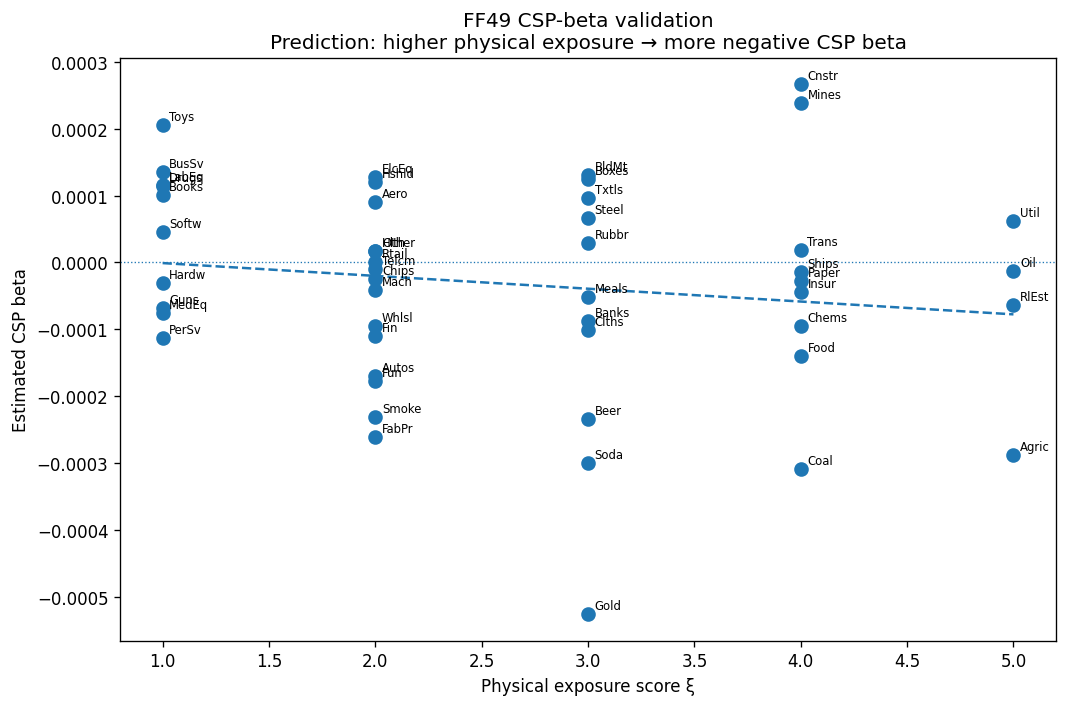

✓ Saved plot to: /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/ff49_csp_beta_vs_exposure.png

── Exploratory beta-sorted portfolio test ──
Mean daily LMH excess return       : 4.5812e-06
Annualised mean LMH excess return  : 0.1154%
Plain t-test  t=0.077  p=0.9384
HAC-robust    t=0.077  p=0.9387
✓ Saved tercile returns to: /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/ff49_csp_beta_tercile_returns.csv


In [46]:
# =============================================================================
# BUA-STYLE FF49 VALIDATION: CSP BETAS + EXPOSURE ORDERING

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
from pathlib import Path

for _name in ("panel49", "fff"):
    if _name not in dir():
        raise NameError(
            f"'{_name}' is not defined. This cell needs 'panel49' (your FF49-merged "
            f"industry panel with 'xi'/'xi_norm' physical-exposure scores already "
            f"attached) and 'fff' (Fama-French 5-factor daily data) already built "
            f"in this session."
        )

# ---------------------------------------------------------------------
# 0. Setup
# ---------------------------------------------------------------------

if "figdir" not in globals():
    figdir = Path.cwd()

df49 = panel49.copy()
ff5 = fff.copy()

df49["date"] = pd.to_datetime(df49["date"])
ff5["date"] = pd.to_datetime(ff5["date"])

# ---------------------------------------------------------------------
# 1. Clean Fama-French factor column names
# ---------------------------------------------------------------------

rename_map = {}
for c in ff5.columns:
    clean = c.strip().lower().replace("_", "").replace("-", "")

    if clean in ["mktrf", "rmrf", "marketrf"]:
        rename_map[c] = "Mkt-RF"
    elif clean == "smb":
        rename_map[c] = "SMB"
    elif clean == "hml":
        rename_map[c] = "HML"
    elif clean == "rmw":
        rename_map[c] = "RMW"
    elif clean == "cma":
        rename_map[c] = "CMA"
    elif clean == "rf":
        rename_map[c] = "RF"

ff5 = ff5.rename(columns=rename_map)

ff_cols = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
required_ff = ff_cols + ["RF"]

missing_ff = [c for c in required_ff if c not in ff5.columns]
if missing_ff:
    raise ValueError(
        f"fff is missing these required Fama-French columns: {missing_ff}\n"
        f"Available columns are: {ff5.columns.tolist()}"
    )

for c in required_ff:
    ff5[c] = pd.to_numeric(ff5[c], errors="coerce")

print("Fama-French factor columns detected:")
display(ff5[["date"] + required_ff].head())

# ---------------------------------------------------------------------
# 2. Merge FF factors into panel49
# ---------------------------------------------------------------------

df49 = df49.drop(columns=[c for c in required_ff if c in df49.columns], errors="ignore")

df49 = df49.merge(
    ff5[["date"] + required_ff],
    on="date",
    how="left"
)

missing_share = df49[required_ff].isna().mean()
print("\nMissing factor share after merge:")
display(missing_share)

if missing_share.max() > 0.05:
    print(
        "\nWARNING: More than 5% of factor observations are missing after merge. "
        "Check date formats and sample overlap."
    )

# ---------------------------------------------------------------------
# 3. Required panel columns
# ---------------------------------------------------------------------

required_cols = [
    "date", "industry", "ret", "CSP", "SSI_lag1", "xi", "xi_norm"
] + required_ff

missing = [c for c in required_cols if c not in df49.columns]
if missing:
    raise ValueError(f"panel49 / merged df49 is missing required columns: {missing}")

df49 = df49.drop_duplicates(["industry", "date"]).sort_values(["industry", "date"])

# ---------------------------------------------------------------------
# 4. Excess returns
# ---------------------------------------------------------------------

df49["ret"] = pd.to_numeric(df49["ret"], errors="coerce")
df49["RF"] = pd.to_numeric(df49["RF"], errors="coerce")
df49["ret_excess"] = df49["ret"] - df49["RF"]

print("\nReturn scale check:")
print("Industry return summary:")
display(df49["ret"].describe())

print("Risk-free rate summary:")
display(df49["RF"].describe())

# MOVE removed here
extra_controls = [c for c in ["SSI_lag1", "cpu", "epu"] if c in df49.columns]

controls = ["CSP"] + extra_controls + ff_cols

print("\nControls used in industry beta regressions:")
print(controls)

# ---------------------------------------------------------------------
# 5. Estimate industry-level CSP betas
# ---------------------------------------------------------------------

def estimate_csp_beta(g, hac_lags=10):
    use_cols = ["ret_excess", "CSP"] + extra_controls + ff_cols + ["xi", "xi_norm"]
    sub = g[use_cols].replace([np.inf, -np.inf], np.nan).dropna()

    if len(sub) < 250:
        return pd.Series({
            "beta_CSP": np.nan,
            "se_CSP": np.nan,
            "t_CSP": np.nan,
            "p_CSP": np.nan,
            "nobs": len(sub),
            "xi": sub["xi"].iloc[0] if len(sub) else np.nan,
            "xi_norm": sub["xi_norm"].iloc[0] if len(sub) else np.nan,
        })

    y = sub["ret_excess"]
    X = sm.add_constant(sub[["CSP"] + extra_controls + ff_cols], has_constant="add")

    res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})

    return pd.Series({
        "beta_CSP": res.params.get("CSP", np.nan),
        "se_CSP": res.bse.get("CSP", np.nan),
        "t_CSP": res.tvalues.get("CSP", np.nan),
        "p_CSP": res.pvalues.get("CSP", np.nan),
        "nobs": int(res.nobs),
        "xi": sub["xi"].iloc[0],
        "xi_norm": sub["xi_norm"].iloc[0],
    })

beta_df = (
    df49
    .groupby("industry", group_keys=False)
    .apply(estimate_csp_beta)
    .reset_index()
    .dropna(subset=["beta_CSP", "xi_norm"])
    .sort_values("beta_CSP")
    .reset_index(drop=True)
)

if beta_df.empty:
    raise RuntimeError(
        "beta_df is empty — no industry had >=250 usable observations. "
        "Check df49 has enough overlap across CSP/controls/FF factors/xi."
    )

print("\n── FF49 industry CSP betas: most negative to most positive ──")
display(beta_df[["industry", "beta_CSP", "se_CSP", "t_CSP", "p_CSP", "xi", "xi_norm", "nobs"]])

beta_df.to_csv(figdir / "ff49_csp_industry_betas.csv", index=False)
print(f"\n✓ Saved industry CSP betas to: {figdir / 'ff49_csp_industry_betas.csv'}")

# ---------------------------------------------------------------------
# 6. Cross-sectional validation
# ---------------------------------------------------------------------

cs = beta_df.dropna(subset=["beta_CSP", "xi_norm"]).copy()

if len(cs) < 5:
    raise RuntimeError(
        f"Only {len(cs)} industries have valid beta_CSP/xi_norm — too few for "
        f"a meaningful cross-sectional regression."
    )

X_cs = sm.add_constant(cs["xi_norm"], has_constant="add")
y_cs = cs["beta_CSP"]

cs_res = sm.OLS(y_cs, X_cs).fit(cov_type="HC3")
spear_rho, spear_p = stats.spearmanr(cs["xi"], cs["beta_CSP"])

print("\n── Cross-sectional validation: beta_CSP on physical exposure ξ ──")
print(cs_res.summary())
print(f"\nSpearman correlation between ξ and beta_CSP: rho = {spear_rho:.3f}, p = {spear_p:.4f}")

b = cs_res.params["xi_norm"]
p = cs_res.pvalues["xi_norm"]

if b < 0:
    print("\n✓ Prediction sign holds: higher physical exposure is associated with more negative CSP betas.")
else:
    print("\n✗ Prediction sign does not hold: higher exposure is not associated with more negative CSP betas.")

print(f"Cross-sectional slope b = {b:.4e}, p = {p:.4f}")

# ---------------------------------------------------------------------
# 7. Sort industries into CSP-beta terciles
# ---------------------------------------------------------------------

cs["beta_tercile"] = pd.qcut(
    cs["beta_CSP"],
    q=3,
    labels=[
        "Low beta / most exposed response",
        "Middle beta",
        "High beta / least exposed response"
    ]
)

print("\n── CSP-beta tercile composition ──")

tercile_summary = (
    cs.groupby("beta_tercile", observed=True)
      .agg(
          n_industries=("industry", "count"),
          mean_beta_CSP=("beta_CSP", "mean"),
          mean_xi=("xi", "mean"),
          median_xi=("xi", "median"),
      )
)

display(tercile_summary)

print("\nIndustries by tercile:")
for tercile, sub in cs.groupby("beta_tercile", observed=True):
    print(f"\n{tercile}")
    print(
        sub[["industry", "beta_CSP", "t_CSP", "p_CSP", "xi"]]
        .sort_values("beta_CSP")
        .to_string(index=False)
    )

tercile_summary.to_csv(figdir / "ff49_csp_beta_tercile_summary.csv")
cs.to_csv(figdir / "ff49_csp_beta_terciles.csv", index=False)

# ---------------------------------------------------------------------
# 8. Plot
# ---------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(cs["xi"], cs["beta_CSP"], s=60)

for _, row in cs.iterrows():
    ax.annotate(
        row["industry"],
        (row["xi"], row["beta_CSP"]),
        textcoords="offset points",
        xytext=(4, 3),
        fontsize=7
    )

m, a = np.polyfit(cs["xi"], cs["beta_CSP"], 1)
xgrid = np.linspace(cs["xi"].min(), cs["xi"].max(), 100)
ax.plot(xgrid, a + m * xgrid, linestyle="--", linewidth=1.5)

ax.axhline(0, linewidth=0.8, linestyle=":")
ax.set_xlabel("Physical exposure score ξ")
ax.set_ylabel("Estimated CSP beta")
ax.set_title(
    "FF49 CSP-beta validation\n"
    "Prediction: higher physical exposure → more negative CSP beta"
)

fig.tight_layout()
fig.savefig(figdir / "ff49_csp_beta_vs_exposure.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"✓ Saved plot to: {figdir / 'ff49_csp_beta_vs_exposure.png'}")

# ---------------------------------------------------------------------
# 9. Optional Bua-style low-minus-high CSP-beta portfolio
# ---------------------------------------------------------------------

df49_betas = df49.merge(
    cs[["industry", "beta_CSP", "beta_tercile"]],
    on="industry",
    how="inner"
)

tercile_rets = (
    df49_betas
    .groupby(["date", "beta_tercile"], observed=True)["ret_excess"]
    .mean()
    .unstack("beta_tercile")
    .dropna()
)

low_col = "Low beta / most exposed response"
high_col = "High beta / least exposed response"

if low_col not in tercile_rets.columns or high_col not in tercile_rets.columns:
    raise RuntimeError(
        f"Expected tercile columns not found. Actual columns: "
        f"{list(tercile_rets.columns)}"
    )

tercile_rets["LMH_low_minus_high"] = tercile_rets[low_col] - tercile_rets[high_col]

lmh = tercile_rets["LMH_low_minus_high"].dropna()

if len(lmh) < 30:
    raise RuntimeError(f"Only {len(lmh)} LMH observations — too few for a t-test.")

t_alpha, p_alpha = stats.ttest_1samp(lmh.values, 0)

lmh_res = sm.OLS(
    lmh.values,
    np.ones((len(lmh), 1))
).fit(cov_type="HAC", cov_kwds={"maxlags": 10})

alpha = lmh.mean()
alpha_ann = alpha * 252
t_alpha_hac = lmh_res.tvalues[0]
p_alpha_hac = lmh_res.pvalues[0]

print("\n── Exploratory beta-sorted portfolio test ──")
print(f"Mean daily LMH excess return       : {alpha:.4e}")
print(f"Annualised mean LMH excess return  : {alpha_ann:.4%}")
print(f"Plain t-test  t={t_alpha:.3f}  p={p_alpha:.4f}")
print(f"HAC-robust    t={t_alpha_hac:.3f}  p={p_alpha_hac:.4f}")

tercile_rets.to_csv(figdir / "ff49_csp_beta_tercile_returns.csv")
print(f"✓ Saved tercile returns to: {figdir / 'ff49_csp_beta_tercile_returns.csv'}")

In [47]:
# =============================================================================
# LAYERED BUA-STYLE FF49 VALIDATION
# CSP betas under increasingly strict controls
# =============================================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from pathlib import Path

# ---------------------------------------------------------------------
# 0. Setup
# ---------------------------------------------------------------------

if "figdir" not in globals():
    figdir = Path.cwd()

df49 = panel49.copy()
ff5 = fff.copy()

df49["date"] = pd.to_datetime(df49["date"])
ff5["date"] = pd.to_datetime(ff5["date"])

# ---------------------------------------------------------------------
# 1. Standardise Fama-French factor names
# ---------------------------------------------------------------------

rename_map = {}
for c in ff5.columns:
    clean = c.strip().lower().replace("_", "").replace("-", "")
    if clean in ["mktrf", "rmrf", "marketrf"]:
        rename_map[c] = "Mkt-RF"
    elif clean == "smb":
        rename_map[c] = "SMB"
    elif clean == "hml":
        rename_map[c] = "HML"
    elif clean == "rmw":
        rename_map[c] = "RMW"
    elif clean == "cma":
        rename_map[c] = "CMA"
    elif clean == "rf":
        rename_map[c] = "RF"

ff5 = ff5.rename(columns=rename_map)

ff_cols = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
required_ff = ff_cols + ["RF"]

missing_ff = [c for c in required_ff if c not in ff5.columns]
if missing_ff:
    raise ValueError(
        f"Missing FF columns in fff: {missing_ff}\n"
        f"Available columns: {ff5.columns.tolist()}"
    )

for c in required_ff:
    ff5[c] = pd.to_numeric(ff5[c], errors="coerce")

# ---------------------------------------------------------------------
# 2. Merge factors into FF49 panel
# ---------------------------------------------------------------------

df49 = df49.drop(columns=[c for c in required_ff if c in df49.columns], errors="ignore")

df49 = df49.merge(
    ff5[["date"] + required_ff],
    on="date",
    how="left"
)

required_base = ["date", "industry", "ret", "CSP", "SSI_lag1", "xi", "xi_norm"] + required_ff
missing = [c for c in required_base if c not in df49.columns]
if missing:
    raise ValueError(f"Missing required columns after merge: {missing}")

df49 = df49.drop_duplicates(["industry", "date"]).sort_values(["industry", "date"])

# Numeric conversion
for c in ["ret", "CSP", "SSI_lag1", "xi", "xi_norm"] + required_ff:
    df49[c] = pd.to_numeric(df49[c], errors="coerce")

if "cpu" in df49.columns:
    df49["cpu"] = pd.to_numeric(df49["cpu"], errors="coerce")

if "epu" in df49.columns:
    df49["epu"] = pd.to_numeric(df49["epu"], errors="coerce")

# Excess returns
df49["ret_excess"] = df49["ret"] - df49["RF"]

print("Sample check")
print("Rows:", len(df49))
print("Industries:", df49["industry"].nunique())
print("Date range:", df49["date"].min(), "→", df49["date"].max())
print("\nMissing shares:")
display(df49[["ret_excess", "CSP", "SSI_lag1", "xi_norm"] + ff_cols + ["RF"]].isna().mean())

# ---------------------------------------------------------------------
# 3. Define layered specifications
# ---------------------------------------------------------------------

specs = {
    "M1_CSP_only": ["CSP"],
    "M2_CSP_SSI": ["CSP", "SSI_lag1"],
    "M3_CSP_SSI_CPU": ["CSP", "SSI_lag1"] + (["cpu"] if "cpu" in df49.columns else []),
    "M4_CSP_SSI_FF5": ["CSP", "SSI_lag1"] + ff_cols,
    "M5_CSP_SSI_CPU_FF5": ["CSP", "SSI_lag1"] + (["cpu"] if "cpu" in df49.columns else []) + ff_cols,
}

# Optional: include EPU variants only if you have epu
if "epu" in df49.columns:
    specs["M6_CSP_SSI_CPU_EPU_FF5"] = (
        ["CSP", "SSI_lag1"]
        + (["cpu"] if "cpu" in df49.columns else [])
        + ["epu"]
        + ff_cols
    )

print("\nSpecifications:")
for k, v in specs.items():
    print(k, ":", v)

# ---------------------------------------------------------------------
# 4. Helper functions
# ---------------------------------------------------------------------

def estimate_betas_for_spec(data, controls, hac_lags=10, min_obs=250):
    """
    Estimate industry-level CSP betas for one control specification.
    """
    out = []

    for industry, g in data.groupby("industry"):
        use_cols = ["ret_excess", "xi", "xi_norm"] + controls
        sub = g[use_cols].replace([np.inf, -np.inf], np.nan).dropna()

        if len(sub) < min_obs:
            continue

        y = sub["ret_excess"]
        X = sm.add_constant(sub[controls], has_constant="add")

        try:
            res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})

            out.append({
                "industry": industry,
                "beta_CSP": res.params.get("CSP", np.nan),
                "se_CSP": res.bse.get("CSP", np.nan),
                "t_CSP": res.tvalues.get("CSP", np.nan),
                "p_CSP": res.pvalues.get("CSP", np.nan),
                "nobs": int(res.nobs),
                "xi": sub["xi"].iloc[0],
                "xi_norm": sub["xi_norm"].iloc[0],
            })
        except Exception as e:
            print(f"Regression failed for {industry}: {e}")

    return pd.DataFrame(out).dropna(subset=["beta_CSP", "xi_norm"])


def cross_section_summary(beta_df):
    """
    Main validation summary:
    beta_CSP_i = a + b xi_i + u_i
    """
    cs = beta_df.dropna(subset=["beta_CSP", "xi_norm", "xi"]).copy()

    X = sm.add_constant(cs["xi_norm"], has_constant="add")
    y = cs["beta_CSP"]

    res = sm.OLS(y, X).fit(cov_type="HC3")

    rho, rho_p = stats.spearmanr(cs["xi"], cs["beta_CSP"])

    # Tercile exposure ordering
    cs["beta_tercile"] = pd.qcut(
        cs["beta_CSP"],
        q=3,
        labels=["Low beta", "Middle beta", "High beta"]
    )

    terc = (
        cs.groupby("beta_tercile", observed=True)
          .agg(
              n=("industry", "count"),
              mean_beta=("beta_CSP", "mean"),
              mean_xi=("xi", "mean"),
              median_xi=("xi", "median"),
          )
    )

    low_xi = terc.loc["Low beta", "mean_xi"]
    high_xi = terc.loc["High beta", "mean_xi"]
    tercile_gap = low_xi - high_xi

    return {
        "n_industries": len(cs),
        "slope_b": res.params["xi_norm"],
        "p_slope": res.pvalues["xi_norm"],
        "r2": res.rsquared,
        "spearman_rho": rho,
        "spearman_p": rho_p,
        "low_beta_mean_xi": low_xi,
        "high_beta_mean_xi": high_xi,
        "tercile_xi_gap_low_minus_high": tercile_gap,
        "tercile_table": terc,
        "cs": cs,
        "cs_res": res,
    }


def lmh_portfolio_test(data, cs_with_terciles, hac_lags=10):
    """
    Exploratory low-minus-high beta-sorted portfolio test.
    Low beta = most negative CSP beta.
    """
    tmp = data.merge(
        cs_with_terciles[["industry", "beta_tercile"]],
        on="industry",
        how="inner"
    )

    rets = (
        tmp.groupby(["date", "beta_tercile"], observed=True)["ret_excess"]
           .mean()
           .unstack("beta_tercile")
           .dropna()
    )

    if "Low beta" not in rets.columns or "High beta" not in rets.columns:
        return {
            "lmh_daily_mean": np.nan,
            "lmh_annualised": np.nan,
            "lmh_t": np.nan,
            "lmh_p": np.nan,
        }

    lmh = rets["Low beta"] - rets["High beta"]

    res = sm.OLS(
        lmh,
        sm.add_constant(pd.Series(1, index=lmh.index), has_constant="add")
    ).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})

    return {
        "lmh_daily_mean": lmh.mean(),
        "lmh_annualised": lmh.mean() * 252,
        "lmh_t": res.tvalues.iloc[0],
        "lmh_p": res.pvalues.iloc[0],
    }


# ---------------------------------------------------------------------
# 5. Run all layered specifications
# ---------------------------------------------------------------------

all_results = []
all_betas = {}
all_cs = {}
all_terciles = {}

for spec_name, controls in specs.items():
    print(f"\nRunning {spec_name}...")

    beta_df = estimate_betas_for_spec(df49, controls)
    all_betas[spec_name] = beta_df.copy()

    summ = cross_section_summary(beta_df)
    all_cs[spec_name] = summ["cs"]
    all_terciles[spec_name] = summ["tercile_table"]

    lmh_summ = lmh_portfolio_test(df49, summ["cs"])

    all_results.append({
        "spec": spec_name,
        "controls": " + ".join(controls),
        "n_industries": summ["n_industries"],
        "slope_b": summ["slope_b"],
        "p_slope": summ["p_slope"],
        "r2": summ["r2"],
        "spearman_rho": summ["spearman_rho"],
        "spearman_p": summ["spearman_p"],
        "low_beta_mean_xi": summ["low_beta_mean_xi"],
        "high_beta_mean_xi": summ["high_beta_mean_xi"],
        "tercile_xi_gap_low_minus_high": summ["tercile_xi_gap_low_minus_high"],
        **lmh_summ,
    })

results = pd.DataFrame(all_results)

# Useful sign indicators
results["correct_sign_slope"] = results["slope_b"] < 0
results["correct_sign_spearman"] = results["spearman_rho"] < 0
results["correct_tercile_ordering"] = results["tercile_xi_gap_low_minus_high"] > 0

# Save outputs
results.to_csv(figdir / "ff49_layered_csp_beta_validation_summary.csv", index=False)

for spec_name, beta_df in all_betas.items():
    beta_df.to_csv(figdir / f"ff49_csp_betas_{spec_name}.csv", index=False)

print("\n\n==============================")
print("KEY OUTPUT 1: Layered validation summary")
print("==============================")

display(
    results[
        [
            "spec",
            "n_industries",
            "slope_b",
            "p_slope",
            "r2",
            "spearman_rho",
            "spearman_p",
            "low_beta_mean_xi",
            "high_beta_mean_xi",
            "tercile_xi_gap_low_minus_high",
            "lmh_annualised",
            "lmh_t",
            "lmh_p",
            "correct_sign_slope",
            "correct_sign_spearman",
            "correct_tercile_ordering",
        ]
    ]
)

print("\nSaved summary to:")
print(figdir / "ff49_layered_csp_beta_validation_summary.csv")

# ---------------------------------------------------------------------
# 6. Print interpretation flags that matter
# ---------------------------------------------------------------------

print("\n\n==============================")
print("KEY OUTPUT 2: What matters")
print("==============================")

n_specs = len(results)
n_neg_slope = int(results["correct_sign_slope"].sum())
n_neg_spearman = int(results["correct_sign_spearman"].sum())
n_correct_terc = int(results["correct_tercile_ordering"].sum())
n_sig_10 = int(((results["slope_b"] < 0) & (results["p_slope"] < 0.10)).sum())
n_sig_05 = int(((results["slope_b"] < 0) & (results["p_slope"] < 0.05)).sum())

print(f"Negative beta-exposure slope in {n_neg_slope}/{n_specs} models.")
print(f"Negative Spearman correlation in {n_neg_spearman}/{n_specs} models.")
print(f"Correct tercile exposure ordering in {n_correct_terc}/{n_specs} models.")
print(f"Negative and significant slope at 10% in {n_sig_10}/{n_specs} models.")
print(f"Negative and significant slope at 5% in {n_sig_05}/{n_specs} models.")

best_p = results.loc[results["p_slope"].idxmin()]
print("\nSmallest beta-exposure p-value:")
print(best_p[["spec", "slope_b", "p_slope", "r2", "spearman_rho", "spearman_p"]])

strict = results[results["spec"].str.contains("FF5")].copy()
if len(strict):
    print("\nStrict FF5 specifications:")
    display(
        strict[
            [
                "spec",
                "slope_b",
                "p_slope",
                "r2",
                "spearman_rho",
                "spearman_p",
                "tercile_xi_gap_low_minus_high",
                "lmh_annualised",
                "lmh_p",
            ]
        ]
    )

# ---------------------------------------------------------------------
# 7. Tercile tables for each model
# ---------------------------------------------------------------------

print("\n\n==============================")
print("KEY OUTPUT 3: Tercile exposure ordering by model")
print("==============================")

for spec_name, terc in all_terciles.items():
    print(f"\n{spec_name}")
    display(terc)

# ---------------------------------------------------------------------
# 8. Optional compact LaTeX-style table
# ---------------------------------------------------------------------

compact = results.copy()
compact["slope_b"] = compact["slope_b"].map(lambda x: f"{x:.3e}")
compact["p_slope"] = compact["p_slope"].map(lambda x: f"{x:.3f}")
compact["r2"] = compact["r2"].map(lambda x: f"{x:.3f}")
compact["spearman_rho"] = compact["spearman_rho"].map(lambda x: f"{x:.3f}")
compact["spearman_p"] = compact["spearman_p"].map(lambda x: f"{x:.3f}")
compact["tercile_xi_gap_low_minus_high"] = compact["tercile_xi_gap_low_minus_high"].map(lambda x: f"{x:.3f}")
compact["lmh_annualised"] = compact["lmh_annualised"].map(lambda x: f"{x:.3%}")
compact["lmh_p"] = compact["lmh_p"].map(lambda x: f"{x:.3f}")

print("\n\n==============================")
print("KEY OUTPUT 4: Compact table for thesis")
print("==============================")

display(
    compact[
        [
            "spec",
            "slope_b",
            "p_slope",
            "r2",
            "spearman_rho",
            "spearman_p",
            "tercile_xi_gap_low_minus_high",
            "lmh_annualised",
            "lmh_p",
        ]
    ]
)

Sample check
Rows: 209965
Industries: 49
Date range: 2008-12-18 00:00:00 → 2025-12-31 00:00:00

Missing shares:


ret_excess   0.000000
CSP          0.000000
SSI_lag1     0.000000
xi_norm      0.000000
Mkt-RF       0.000000
SMB          0.000000
HML          0.000000
RMW          0.000000
CMA          0.000000
RF           0.000000
dtype: float64


Specifications:
M1_CSP_only : ['CSP']
M2_CSP_SSI : ['CSP', 'SSI_lag1']
M3_CSP_SSI_CPU : ['CSP', 'SSI_lag1']
M4_CSP_SSI_FF5 : ['CSP', 'SSI_lag1', 'Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']
M5_CSP_SSI_CPU_FF5 : ['CSP', 'SSI_lag1', 'Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']

Running M1_CSP_only...

Running M2_CSP_SSI...

Running M3_CSP_SSI_CPU...

Running M4_CSP_SSI_FF5...

Running M5_CSP_SSI_CPU_FF5...


KEY OUTPUT 1: Layered validation summary


,spec,n_industries,slope_b,p_slope,r2,spearman_rho,spearman_p,low_beta_mean_xi,high_beta_mean_xi,tercile_xi_gap_low_minus_high,lmh_annualised,lmh_t,lmh_p,correct_sign_slope,correct_sign_spearman,correct_tercile_ordering
0,M1_CSP_only,49,-0.000026,0.245756,0.027615,-0.198951,0.170546,2.882353,2.250000,0.632353,0.000439,0.926311,0.354285,True,True,True
1,M2_CSP_SSI,49,-0.000026,0.229078,0.028735,-0.195120,0.179098,2.882353,2.250000,0.632353,0.000439,0.926311,0.354285,True,True,True
2,M3_CSP_SSI_CPU,49,-0.000026,0.229078,0.028735,-0.195120,0.179098,2.882353,2.250000,0.632353,0.000439,0.926311,0.354285,True,True,True
3,M4_CSP_SSI_FF5,49,-0.000024,0.259539,0.023381,-0.156862,0.281761,2.705882,2.312500,0.393382,0.001154,-0.095642,0.923805,True,True,True
4,M5_CSP_SSI_CPU_FF5,49,-0.000024,0.259539,0.023381,-0.156862,0.281761,2.705882,2.312500,0.393382,0.001154,-0.095642,0.923805,True,True,True



Saved summary to:
/Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/ff49_layered_csp_beta_validation_summary.csv


KEY OUTPUT 2: What matters
Negative beta-exposure slope in 5/5 models.
Negative Spearman correlation in 5/5 models.
Correct tercile exposure ordering in 5/5 models.
Negative and significant slope at 10% in 0/5 models.
Negative and significant slope at 5% in 0/5 models.

Smallest beta-exposure p-value:
spec            M2_CSP_SSI
slope_b          -0.000026
p_slope           0.229078
r2                0.028735
spearman_rho     -0.195120
spearman_p        0.179098
Name: 1, dtype: object

Strict FF5 specifications:


,spec,slope_b,p_slope,r2,spearman_rho,spearman_p,tercile_xi_gap_low_minus_high,lmh_annualised,lmh_p
3,M4_CSP_SSI_FF5,-0.000024,0.259539,0.023381,-0.156862,0.281761,0.393382,0.001154,0.923805
4,M5_CSP_SSI_CPU_FF5,-0.000024,0.259539,0.023381,-0.156862,0.281761,0.393382,0.001154,0.923805


... (8 outputs left out)


M5_CSP_SSI_CPU_FF5


,n,mean_beta,mean_xi,median_xi
beta_tercile,,,,
Low beta,17,-0.000195,2.705882,3.000000
Middle beta,16,-0.000019,2.875000,2.500000
High beta,16,0.000127,2.312500,2.000000




KEY OUTPUT 4: Compact table for thesis


,spec,slope_b,p_slope,r2,spearman_rho,spearman_p,tercile_xi_gap_low_minus_high,lmh_annualised,lmh_p
0,M1_CSP_only,-2.559e-05,0.246,0.028,-0.199,0.171,0.632,0.044%,0.354
1,M2_CSP_SSI,-2.615e-05,0.229,0.029,-0.195,0.179,0.632,0.044%,0.354
2,M3_CSP_SSI_CPU,-2.615e-05,0.229,0.029,-0.195,0.179,0.632,0.044%,0.354
3,M4_CSP_SSI_FF5,-2.369e-05,0.260,0.023,-0.157,0.282,0.393,0.115%,0.924
4,M5_CSP_SSI_CPU_FF5,-2.369e-05,0.260,0.023,-0.157,0.282,0.393,0.115%,0.924


In [48]:
# =============================================================================
# SSI EQUITY VALIDATION — FF49 INDUSTRY EXPOSURE TEST
# =============================================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path

if "figdir" not in globals():
    figdir = Path.cwd()

# ---------------------------------------------------------------------
# 0. Prepare data
# ---------------------------------------------------------------------

df = panel49.copy()
ff5 = fff.copy()

df["date"] = pd.to_datetime(df["date"])
ff5["date"] = pd.to_datetime(ff5["date"])

# Standardise FF names
rename_map = {}
for c in ff5.columns:
    clean = c.strip().lower().replace("_", "").replace("-", "")
    if clean in ["mktrf", "rmrf", "marketrf"]:
        rename_map[c] = "Mkt-RF"
    elif clean == "smb":
        rename_map[c] = "SMB"
    elif clean == "hml":
        rename_map[c] = "HML"
    elif clean == "rmw":
        rename_map[c] = "RMW"
    elif clean == "cma":
        rename_map[c] = "CMA"
    elif clean == "rf":
        rename_map[c] = "RF"

ff5 = ff5.rename(columns=rename_map)

ff_cols = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
required_ff = ff_cols + ["RF"]

missing_ff = [c for c in required_ff if c not in ff5.columns]
if missing_ff:
    raise ValueError(f"Missing FF factor columns in fff: {missing_ff}")

for c in required_ff:
    ff5[c] = pd.to_numeric(ff5[c], errors="coerce")

# Merge RF and factors
df = df.drop(columns=[c for c in required_ff if c in df.columns], errors="ignore")
df = df.merge(ff5[["date"] + required_ff], on="date", how="left")

required_cols = ["date", "industry", "ret", "SSI_lag1", "xi", "xi_norm"] + required_ff
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns after merge: {missing}")

for c in ["ret", "SSI_lag1", "xi", "xi_norm"] + required_ff:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.drop_duplicates(["industry", "date"]).sort_values(["industry", "date"])

# Excess return
df["ret_excess"] = df["ret"] - df["RF"]

print("Daily panel check")
print("Rows:", len(df))
print("Industries:", df["industry"].nunique())
print("Date range:", df["date"].min(), "→", df["date"].max())

# ---------------------------------------------------------------------
# 1. Aggregate to weekly and monthly frequency
# ---------------------------------------------------------------------

def make_period_panel(data, freq):
    """
    freq = 'W-FRI' for weekly or 'M' for monthly.
    
    Returns:
      industry-period panel with compounded excess returns,
      average lagged SSI, and fixed exposure xi.
    """
    x = data.copy()
    x["period"] = x["date"].dt.to_period(freq)

    # Convert percent returns to decimal for compounding, then back to percent.
    # If your returns are already decimals, comment these two lines and adjust.
    x["ret_excess_dec"] = x["ret_excess"] / 100.0

    out = (
        x.groupby(["industry", "period"], observed=True)
         .agg(
             ret_excess=("ret_excess_dec", lambda z: (1 + z.dropna()).prod() - 1),
             SSI_lag1=("SSI_lag1", "mean"),
             xi=("xi", "first"),
             xi_norm=("xi_norm", "first"),
             n_days=("ret_excess_dec", "count"),
         )
         .reset_index()
    )

    # Back to percent units
    out["ret_excess"] = out["ret_excess"] * 100.0

    # Convert period to timestamp
    out["date"] = out["period"].dt.to_timestamp(how="end")

    # Drop periods with too few trading days
    min_days = 3 if freq == "W-FRI" else 10
    out = out[out["n_days"] >= min_days].copy()

    return out

weekly = make_period_panel(df, "W-FRI")
monthly = make_period_panel(df, "M")

print("\nWeekly panel:", weekly.shape, "Industries:", weekly["industry"].nunique())
print("Monthly panel:", monthly.shape, "Industries:", monthly["industry"].nunique())

# ---------------------------------------------------------------------
# 2. Two-way fixed-effect residualisation helper
# ---------------------------------------------------------------------

def twfe_residualize(y, industry, date):
    """
    Residualise y by industry and date fixed effects using demeaning.
    Equivalent to absorbing industry and date fixed effects.
    """
    temp = pd.DataFrame({
        "y": y,
        "industry": industry,
        "date": date
    }).copy()

    grand = temp["y"].mean()
    ind_mean = temp.groupby("industry")["y"].transform("mean")
    date_mean = temp.groupby("date")["y"].transform("mean")

    return temp["y"] - ind_mean - date_mean + grand


def run_ssi_twfe(data, label):
    """
    Run:
        r_it = alpha_i + delta_t + beta * (SSI_lag1_t × xi_i) + error_it
    
    with two-way FE absorbed by residualisation.
    """
    d = data.copy()
    d = d.replace([np.inf, -np.inf], np.nan)
    d = d.dropna(subset=["ret_excess", "SSI_lag1", "xi_norm", "industry", "date"])

    d["SSI_x_xi"] = d["SSI_lag1"] * d["xi_norm"]

    # Absorb industry and date fixed effects from y and X
    y_resid = twfe_residualize(d["ret_excess"], d["industry"], d["date"])
    x_resid = twfe_residualize(d["SSI_x_xi"], d["industry"], d["date"])

    X = sm.add_constant(x_resid, has_constant="add")
    res = sm.OLS(y_resid, X).fit(cov_type="HC3")

    beta = res.params.iloc[1]
    se = res.bse.iloc[1]
    tval = res.tvalues.iloc[1]
    pval = res.pvalues.iloc[1]

    return {
        "frequency": label,
        "n_obs": len(d),
        "n_industries": d["industry"].nunique(),
        "n_periods": d["date"].nunique(),
        "beta_SSI_x_xi": beta,
        "se": se,
        "t": tval,
        "p": pval,
        "r2_resid": res.rsquared,
        "correct_sign": beta < 0,
    }, res, d


weekly_summary, weekly_res, weekly_used = run_ssi_twfe(weekly, "weekly")
monthly_summary, monthly_res, monthly_used = run_ssi_twfe(monthly, "monthly")

ssi_equity_summary = pd.DataFrame([weekly_summary, monthly_summary])

print("\n==============================")
print("KEY OUTPUT 1: SSI × exposure equity validation")
print("==============================")
display(ssi_equity_summary)

ssi_equity_summary.to_csv(figdir / "ssi_equity_validation_twfe_summary.csv", index=False)

# ---------------------------------------------------------------------
# 3. High-minus-low exposure portfolio test
# ---------------------------------------------------------------------
# This is easier to interpret:
#   Compare high-exposure industries vs low-exposure industries when SSI is high.
# ---------------------------------------------------------------------

def run_high_low_ssi_portfolio(data, label):
    d = data.copy()
    d = d.dropna(subset=["ret_excess", "SSI_lag1", "xi"])

    # Define high and low exposure groups using xi terciles
    low_cut = d[["industry", "xi"]].drop_duplicates()["xi"].quantile(1/3)
    high_cut = d[["industry", "xi"]].drop_duplicates()["xi"].quantile(2/3)

    industry_xi = d[["industry", "xi"]].drop_duplicates()

    low_inds = industry_xi.loc[industry_xi["xi"] <= low_cut, "industry"]
    high_inds = industry_xi.loc[industry_xi["xi"] >= high_cut, "industry"]

    d["exposure_group"] = np.where(
        d["industry"].isin(high_inds), "High exposure",
        np.where(d["industry"].isin(low_inds), "Low exposure", np.nan)
    )

    d = d.dropna(subset=["exposure_group"])

    port = (
        d.groupby(["date", "exposure_group"], observed=True)
         .agg(
             ret_excess=("ret_excess", "mean"),
             SSI_lag1=("SSI_lag1", "mean")
         )
         .reset_index()
    )

    wide = port.pivot(index="date", columns="exposure_group", values="ret_excess").dropna()
    ssi = port.groupby("date")["SSI_lag1"].mean()

    wide["SSI_lag1"] = ssi.reindex(wide.index)
    wide["High_minus_low"] = wide["High exposure"] - wide["Low exposure"]

    # Regression:
    #   High-low return = alpha + beta SSI
    X = sm.add_constant(wide["SSI_lag1"], has_constant="add")
    y = wide["High_minus_low"]

    res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4 if label == "weekly" else 2})

    beta = res.params["SSI_lag1"]
    se = res.bse["SSI_lag1"]
    tval = res.tvalues["SSI_lag1"]
    pval = res.pvalues["SSI_lag1"]

    return {
        "frequency": label,
        "n_periods": len(wide),
        "low_exposure_cutoff": low_cut,
        "high_exposure_cutoff": high_cut,
        "beta_SSI_on_high_minus_low": beta,
        "se": se,
        "t": tval,
        "p": pval,
        "correct_sign": beta < 0,
    }, res, wide


weekly_hl_summary, weekly_hl_res, weekly_hl_data = run_high_low_ssi_portfolio(weekly, "weekly")
monthly_hl_summary, monthly_hl_res, monthly_hl_data = run_high_low_ssi_portfolio(monthly, "monthly")

ssi_hl_summary = pd.DataFrame([weekly_hl_summary, monthly_hl_summary])

print("\n==============================")
print("KEY OUTPUT 2: High-minus-low exposure portfolio test")
print("==============================")
display(ssi_hl_summary)

ssi_hl_summary.to_csv(figdir / "ssi_high_minus_low_exposure_validation.csv", index=False)

# ---------------------------------------------------------------------
# 4. SSI beta validation
# ---------------------------------------------------------------------
# Estimate each industry's sensitivity to SSI at weekly/monthly frequency,
# then test whether SSI betas are more negative for higher-exposure industries.
# ---------------------------------------------------------------------

def estimate_ssi_betas(data, label, hac_lags):
    out = []

    for industry, g in data.groupby("industry"):
        sub = g[["ret_excess", "SSI_lag1", "xi", "xi_norm"]].replace(
            [np.inf, -np.inf], np.nan
        ).dropna()

        min_obs = 80 if label == "weekly" else 24
        if len(sub) < min_obs:
            continue

        y = sub["ret_excess"]
        X = sm.add_constant(sub["SSI_lag1"], has_constant="add")

        res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})

        out.append({
            "industry": industry,
            "beta_SSI": res.params["SSI_lag1"],
            "se_SSI": res.bse["SSI_lag1"],
            "t_SSI": res.tvalues["SSI_lag1"],
            "p_SSI": res.pvalues["SSI_lag1"],
            "nobs": int(res.nobs),
            "xi": sub["xi"].iloc[0],
            "xi_norm": sub["xi_norm"].iloc[0],
        })

    beta_df = pd.DataFrame(out).dropna(subset=["beta_SSI", "xi_norm"])

    X_cs = sm.add_constant(beta_df["xi_norm"], has_constant="add")
    y_cs = beta_df["beta_SSI"]

    cs_res = sm.OLS(y_cs, X_cs).fit(cov_type="HC3")

    rho, rho_p = stats.spearmanr(beta_df["xi"], beta_df["beta_SSI"])

    summary = {
        "frequency": label,
        "n_industries": len(beta_df),
        "slope_betaSSI_on_xi": cs_res.params["xi_norm"],
        "p_slope": cs_res.pvalues["xi_norm"],
        "r2": cs_res.rsquared,
        "spearman_rho": rho,
        "spearman_p": rho_p,
        "correct_sign": cs_res.params["xi_norm"] < 0,
    }

    return summary, beta_df, cs_res


weekly_beta_summary, weekly_ssi_betas, weekly_beta_res = estimate_ssi_betas(
    weekly, "weekly", hac_lags=4
)

monthly_beta_summary, monthly_ssi_betas, monthly_beta_res = estimate_ssi_betas(
    monthly, "monthly", hac_lags=2
)

ssi_beta_summary = pd.DataFrame([weekly_beta_summary, monthly_beta_summary])

print("\n==============================")
print("KEY OUTPUT 3: SSI-beta exposure ordering")
print("==============================")
display(ssi_beta_summary)

weekly_ssi_betas.to_csv(figdir / "weekly_ff49_ssi_betas.csv", index=False)
monthly_ssi_betas.to_csv(figdir / "monthly_ff49_ssi_betas.csv", index=False)
ssi_beta_summary.to_csv(figdir / "ssi_beta_exposure_ordering_summary.csv", index=False)

# ---------------------------------------------------------------------
# 5. Interpretation helper
# ---------------------------------------------------------------------

print("\n==============================")
print("INTERPRETATION FLAGS")
print("==============================")

for _, row in ssi_equity_summary.iterrows():
    print(
        f"{row['frequency']} TWFE SSI×xi: "
        f"beta={row['beta_SSI_x_xi']:.4e}, "
        f"p={row['p']:.3f}, "
        f"correct sign={row['correct_sign']}"
    )

for _, row in ssi_hl_summary.iterrows():
    print(
        f"{row['frequency']} high-minus-low: "
        f"beta={row['beta_SSI_on_high_minus_low']:.4e}, "
        f"p={row['p']:.3f}, "
        f"correct sign={row['correct_sign']}"
    )

for _, row in ssi_beta_summary.iterrows():
    print(
        f"{row['frequency']} SSI beta ordering: "
        f"slope={row['slope_betaSSI_on_xi']:.4e}, "
        f"p={row['p_slope']:.3f}, "
        f"rho={row['spearman_rho']:.3f}, "
        f"correct sign={row['correct_sign']}"
    )

Daily panel check
Rows: 209965
Industries: 49
Date range: 2008-12-18 00:00:00 → 2025-12-31 00:00:00

Weekly panel: (43561, 8) Industries: 49
Monthly panel: (9996, 8) Industries: 49

KEY OUTPUT 1: SSI × exposure equity validation


,frequency,n_obs,n_industries,n_periods,beta_SSI_x_xi,se,t,p,r2_resid,correct_sign
0,weekly,43561,49,889,-0.042026,0.074271,-0.565842,0.571501,0.000007,True
1,monthly,9996,49,204,-0.210342,0.328294,-0.640713,0.521709,0.000044,True



KEY OUTPUT 2: High-minus-low exposure portfolio test


,frequency,n_periods,low_exposure_cutoff,high_exposure_cutoff,beta_SSI_on_high_minus_low,se,t,p,correct_sign
0,weekly,889,2.000000,3.000000,-0.073717,0.181964,-0.405119,0.685390,True
1,monthly,204,2.000000,3.000000,-0.317637,0.691596,-0.459282,0.646032,True



KEY OUTPUT 3: SSI-beta exposure ordering


,frequency,n_industries,slope_betaSSI_on_xi,p_slope,r2,spearman_rho,spearman_p,correct_sign
0,weekly,49,-0.042026,0.558443,0.009603,-0.133561,0.360243,True
1,monthly,49,-0.210342,0.508639,0.013082,-0.130885,0.370036,True



INTERPRETATION FLAGS
weekly TWFE SSI×xi: beta=-4.2026e-02, p=0.572, correct sign=True
monthly TWFE SSI×xi: beta=-2.1034e-01, p=0.522, correct sign=True
weekly high-minus-low: beta=-7.3717e-02, p=0.685, correct sign=True
monthly high-minus-low: beta=-3.1764e-01, p=0.646, correct sign=True
weekly SSI beta ordering: slope=-4.2026e-02, p=0.558, rho=-0.134, correct sign=True
monthly SSI beta ordering: slope=-2.1034e-01, p=0.509, rho=-0.131, correct sign=True


In [49]:
# =============================================================================
# HIGH-SSI REGIME INTERACTION TEST
# Does CSP matter more when persistent physical-risk salience is high?
# =============================================================================
#
# Main regression:
#   r_it = alpha_i + delta_t
#          + b1 * (CSP_t × xi_i)
#          + b2 * (CSP_t × xi_i × HighSSI_t)
#          + error_it
#
# Prediction:
#   b2 < 0
#
# Interpretation:
#   In high-SSI regimes, physical-risk shocks should more strongly hurt
#   high-exposure industries relative to low-exposure industries.
#
# Required:
#   panel49: date, industry, ret, CSP, SSI_lag1, xi, xi_norm
#   fff: Fama-French 5 factors daily, including RF
# =============================================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path

if "figdir" not in globals():
    figdir = Path.cwd()

# ---------------------------------------------------------------------
# 0. Prepare data
# ---------------------------------------------------------------------

df = panel49.copy()
ff5 = fff.copy()

df["date"] = pd.to_datetime(df["date"])
ff5["date"] = pd.to_datetime(ff5["date"])

# Standardise Fama-French factor names
rename_map = {}
for c in ff5.columns:
    clean = c.strip().lower().replace("_", "").replace("-", "")
    if clean in ["mktrf", "rmrf", "marketrf"]:
        rename_map[c] = "Mkt-RF"
    elif clean == "smb":
        rename_map[c] = "SMB"
    elif clean == "hml":
        rename_map[c] = "HML"
    elif clean == "rmw":
        rename_map[c] = "RMW"
    elif clean == "cma":
        rename_map[c] = "CMA"
    elif clean == "rf":
        rename_map[c] = "RF"

ff5 = ff5.rename(columns=rename_map)

ff_cols = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
required_ff = ff_cols + ["RF"]

missing_ff = [c for c in required_ff if c not in ff5.columns]
if missing_ff:
    raise ValueError(f"Missing FF columns in fff: {missing_ff}")

for c in required_ff:
    ff5[c] = pd.to_numeric(ff5[c], errors="coerce")

# Merge factors
df = df.drop(columns=[c for c in required_ff if c in df.columns], errors="ignore")
df = df.merge(ff5[["date"] + required_ff], on="date", how="left")

required_cols = [
    "date", "industry", "ret", "CSP", "SSI_lag1", "xi", "xi_norm"
] + required_ff

missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns after merge: {missing}")

for c in ["ret", "CSP", "SSI_lag1", "xi", "xi_norm"] + required_ff:
    df[c] = pd.to_numeric(df[c], errors="coerce")

if "cpu" in df.columns:
    df["cpu"] = pd.to_numeric(df["cpu"], errors="coerce")

df = df.drop_duplicates(["industry", "date"]).sort_values(["industry", "date"])

# Excess returns
df["ret_excess"] = df["ret"] - df["RF"]

# ---------------------------------------------------------------------
# 1. Construct high-SSI regime indicator
# ---------------------------------------------------------------------

# Use date-level SSI to avoid repeated industry observations affecting quantile
ssi_by_date = (
    df[["date", "SSI_lag1"]]
    .drop_duplicates("date")
    .dropna()
    .sort_values("date")
)

q75 = ssi_by_date["SSI_lag1"].quantile(0.75)
q90 = ssi_by_date["SSI_lag1"].quantile(0.90)

df["HighSSI_75"] = (df["SSI_lag1"] > q75).astype(int)
df["HighSSI_90"] = (df["SSI_lag1"] > q90).astype(int)

print("SSI regime thresholds:")
print(f"75th percentile SSI_lag1: {q75:.6f}")
print(f"90th percentile SSI_lag1: {q90:.6f}")

print("\nHigh-SSI regime shares:")
print("HighSSI_75:", df[["date", "HighSSI_75"]].drop_duplicates()["HighSSI_75"].mean())
print("HighSSI_90:", df[["date", "HighSSI_90"]].drop_duplicates()["HighSSI_90"].mean())

# ---------------------------------------------------------------------
# 2. Two-way fixed-effect residualisation helper
# ---------------------------------------------------------------------

def twfe_residualize(series, industry, date):
    """
    Residualise a variable by industry and date fixed effects.
    Equivalent to absorbing industry and date fixed effects.
    """
    tmp = pd.DataFrame({
        "x": series,
        "industry": industry,
        "date": date
    })

    grand = tmp["x"].mean()
    ind_mean = tmp.groupby("industry")["x"].transform("mean")
    date_mean = tmp.groupby("date")["x"].transform("mean")

    return tmp["x"] - ind_mean - date_mean + grand


def run_high_ssi_interaction(data, regime_col, label):
    """
    Estimate:
      ret_excess_it = industry FE + date FE
                      + b1 * CSP_x_xi
                      + b2 * CSP_x_xi_x_HighSSI
                      + error_it

    Date FE absorb CSP, SSI, CPU, FF factors, and HighSSI levels.
    Identification comes from cross-sectional exposure interaction.
    """
    d = data.copy()

    d["CSP_x_xi"] = d["CSP"] * d["xi_norm"]
    d["CSP_x_xi_x_HighSSI"] = d["CSP"] * d["xi_norm"] * d[regime_col]

    use_cols = [
        "ret_excess",
        "CSP_x_xi",
        "CSP_x_xi_x_HighSSI",
        "industry",
        "date"
    ]

    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=use_cols)

    y_resid = twfe_residualize(d["ret_excess"], d["industry"], d["date"])
    x1_resid = twfe_residualize(d["CSP_x_xi"], d["industry"], d["date"])
    x2_resid = twfe_residualize(d["CSP_x_xi_x_HighSSI"], d["industry"], d["date"])

    X = pd.DataFrame({
        "CSP_x_xi": x1_resid,
        "CSP_x_xi_x_HighSSI": x2_resid
    })

    X = sm.add_constant(X, has_constant="add")

    res = sm.OLS(y_resid, X).fit(cov_type="HC3")

    out = {
        "model": label,
        "n_obs": len(d),
        "n_industries": d["industry"].nunique(),
        "n_dates": d["date"].nunique(),
        "b_base_CSP_x_xi": res.params["CSP_x_xi"],
        "p_base": res.pvalues["CSP_x_xi"],
        "b_highSSI_increment": res.params["CSP_x_xi_x_HighSSI"],
        "p_highSSI_increment": res.pvalues["CSP_x_xi_x_HighSSI"],
        "total_effect_highSSI": res.params["CSP_x_xi"] + res.params["CSP_x_xi_x_HighSSI"],
        "correct_increment_sign": res.params["CSP_x_xi_x_HighSSI"] < 0,
        "correct_total_highSSI_sign": (res.params["CSP_x_xi"] + res.params["CSP_x_xi_x_HighSSI"]) < 0,
        "r2_resid": res.rsquared,
    }

    return out, res, d


# ---------------------------------------------------------------------
# 3. Run daily tests for 75th and 90th percentile regimes
# ---------------------------------------------------------------------

res75, model75, used75 = run_high_ssi_interaction(df, "HighSSI_75", "Daily HighSSI > p75")
res90, model90, used90 = run_high_ssi_interaction(df, "HighSSI_90", "Daily HighSSI > p90")

summary = pd.DataFrame([res75, res90])

print("\n==============================")
print("KEY OUTPUT 1: High-SSI regime interaction")
print("==============================")
display(summary)

summary.to_csv(figdir / "high_ssi_regime_interaction_summary.csv", index=False)

print("\nModel p75 full output:")
print(model75.summary())

print("\nModel p90 full output:")
print(model90.summary())

# ---------------------------------------------------------------------
# 4. Simpler high-minus-low exposure portfolio version
# ---------------------------------------------------------------------
# This is easier to explain:
#   High-minus-low exposure return = alpha + b1*CSP + b2*CSP*HighSSI
# ---------------------------------------------------------------------

def run_high_low_portfolio_regime(data, regime_col, label):
    d = data.copy()
    d = d.dropna(subset=["ret_excess", "CSP", "SSI_lag1", "xi", regime_col])

    industry_xi = d[["industry", "xi"]].drop_duplicates()

    low_cut = industry_xi["xi"].quantile(1/3)
    high_cut = industry_xi["xi"].quantile(2/3)

    low_inds = industry_xi.loc[industry_xi["xi"] <= low_cut, "industry"]
    high_inds = industry_xi.loc[industry_xi["xi"] >= high_cut, "industry"]

    d["group"] = np.where(
        d["industry"].isin(high_inds), "High exposure",
        np.where(d["industry"].isin(low_inds), "Low exposure", np.nan)
    )

    d = d.dropna(subset=["group"])

    port = (
        d.groupby(["date", "group"], observed=True)
         .agg(
             ret_excess=("ret_excess", "mean"),
             CSP=("CSP", "mean"),
             SSI_lag1=("SSI_lag1", "mean"),
             HighSSI=(regime_col, "mean")
         )
         .reset_index()
    )

    wide = port.pivot(index="date", columns="group", values="ret_excess").dropna()

    daily_vars = (
        port.groupby("date", observed=True)
            .agg(CSP=("CSP", "mean"), SSI_lag1=("SSI_lag1", "mean"), HighSSI=("HighSSI", "mean"))
    )

    wide = wide.merge(daily_vars, left_index=True, right_index=True, how="left")

    wide["High_minus_low"] = wide["High exposure"] - wide["Low exposure"]
    wide["CSP_x_HighSSI"] = wide["CSP"] * wide["HighSSI"]

    X = sm.add_constant(wide[["CSP", "CSP_x_HighSSI"]], has_constant="add")
    y = wide["High_minus_low"]

    reg = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 10})

    out = {
        "model": label,
        "n_dates": len(wide),
        "low_cut": low_cut,
        "high_cut": high_cut,
        "b_CSP_normal": reg.params["CSP"],
        "p_CSP_normal": reg.pvalues["CSP"],
        "b_CSP_highSSI_increment": reg.params["CSP_x_HighSSI"],
        "p_CSP_highSSI_increment": reg.pvalues["CSP_x_HighSSI"],
        "total_CSP_effect_highSSI": reg.params["CSP"] + reg.params["CSP_x_HighSSI"],
        "correct_increment_sign": reg.params["CSP_x_HighSSI"] < 0,
        "correct_total_highSSI_sign": (reg.params["CSP"] + reg.params["CSP_x_HighSSI"]) < 0,
    }

    return out, reg, wide


hl75, hl_model75, hl_data75 = run_high_low_portfolio_regime(df, "HighSSI_75", "HL portfolio HighSSI > p75")
hl90, hl_model90, hl_data90 = run_high_low_portfolio_regime(df, "HighSSI_90", "HL portfolio HighSSI > p90")

hl_summary = pd.DataFrame([hl75, hl90])

print("\n==============================")
print("KEY OUTPUT 2: High-minus-low exposure portfolio regime test")
print("==============================")
display(hl_summary)

hl_summary.to_csv(figdir / "high_ssi_regime_high_minus_low_portfolio_summary.csv", index=False)

print("\nHigh-minus-low p75 model:")
print(hl_model75.summary())

print("\nHigh-minus-low p90 model:")
print(hl_model90.summary())

# ---------------------------------------------------------------------
# 5. Interpretation helper
# ---------------------------------------------------------------------

print("\n==============================")
print("INTERPRETATION FLAGS")
print("==============================")

for _, row in summary.iterrows():
    print(
        f"{row['model']}: "
        f"base b={row['b_base_CSP_x_xi']:.4e}, p={row['p_base']:.3f}; "
        f"high-SSI increment b={row['b_highSSI_increment']:.4e}, "
        f"p={row['p_highSSI_increment']:.3f}; "
        f"total high-SSI effect={row['total_effect_highSSI']:.4e}; "
        f"correct increment sign={row['correct_increment_sign']}"
    )

print("\nHigh-minus-low portfolio:")
for _, row in hl_summary.iterrows():
    print(
        f"{row['model']}: "
        f"normal CSP effect={row['b_CSP_normal']:.4e}, p={row['p_CSP_normal']:.3f}; "
        f"high-SSI increment={row['b_CSP_highSSI_increment']:.4e}, "
        f"p={row['p_CSP_highSSI_increment']:.3f}; "
        f"total high-SSI CSP effect={row['total_CSP_effect_highSSI']:.4e}; "
        f"correct increment sign={row['correct_increment_sign']}"
    )

SSI regime thresholds:
75th percentile SSI_lag1: 0.004397
90th percentile SSI_lag1: 0.005279

High-SSI regime shares:
HighSSI_75: 0.2499416569428238
HighSSI_90: 0.1001166861143524

KEY OUTPUT 1: High-SSI regime interaction


,model,n_obs,n_industries,n_dates,b_base_CSP_x_xi,p_base,b_highSSI_increment,p_highSSI_increment,total_effect_highSSI,correct_increment_sign,correct_total_highSSI_sign,r2_resid
0,Daily HighSSI > p75,209965,49,4285,-0.000038,0.114918,0.000063,0.251814,0.000025,False,False,0.000011
1,Daily HighSSI > p90,209965,49,4285,-0.000031,0.172994,0.000087,0.305372,0.000056,False,False,0.000009



Model p75 full output:
                            OLS Regression Results                            
Dep. Variable:                      x   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.368
Date:                Sun, 26 Jul 2026   Prob (F-statistic):              0.255
Time:                        14:10:06   Log-Likelihood:             6.5249e+05
No. Observations:              209965   AIC:                        -1.305e+06
Df Residuals:                  209962   BIC:                        -1.305e+06
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const       

,model,n_dates,low_cut,high_cut,b_CSP_normal,p_CSP_normal,b_CSP_highSSI_increment,p_CSP_highSSI_increment,total_CSP_effect_highSSI,correct_increment_sign,correct_total_highSSI_sign
0,HL portfolio HighSSI > p75,4285,2.000000,3.000000,-0.000081,0.199879,0.000155,0.319377,0.000074,False,False
1,HL portfolio HighSSI > p90,4285,2.000000,3.000000,-0.000062,0.301979,0.000203,0.449351,0.000141,False,False



High-minus-low p75 model:
                            OLS Regression Results                            
Dep. Variable:         High_minus_low   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.9572
Date:                Sun, 26 Jul 2026   Prob (F-statistic):              0.384
Time:                        14:10:06   Log-Likelihood:                 17276.
No. Observations:                4285   AIC:                        -3.455e+04
Df Residuals:                    4282   BIC:                        -3.453e+04
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -8.69

In [50]:
# =============================================================================
# WEEKLY HIGH-SSI REGIME INTERACTION TEST
# Does weekly CSP matter more when persistent physical-risk salience is high?
# =============================================================================
#
# Main TWFE regression:
#   r_i,w = alpha_i + delta_w
#           + b1 * (CSP_w × xi_i)
#           + b2 * (CSP_w × xi_i × HighSSI_w)
#           + error_i,w
#
# Prediction:
#   b2 < 0
#
# Interpretation:
#   During high-SSI weeks, CSP shocks should hurt high-exposure industries
#   more than low-exposure industries.
#
# Required:
#   panel49: date, industry, ret, CSP, SSI_lag1, xi, xi_norm
#   fff: Fama-French 5 factors daily, including RF
# =============================================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path

if "figdir" not in globals():
    figdir = Path.cwd()

# ---------------------------------------------------------------------
# 0. Prepare daily data
# ---------------------------------------------------------------------

df = panel49.copy()
ff5 = fff.copy()

df["date"] = pd.to_datetime(df["date"])
ff5["date"] = pd.to_datetime(ff5["date"])

# Standardise Fama-French factor names
rename_map = {}
for c in ff5.columns:
    clean = c.strip().lower().replace("_", "").replace("-", "")
    if clean in ["mktrf", "rmrf", "marketrf"]:
        rename_map[c] = "Mkt-RF"
    elif clean == "smb":
        rename_map[c] = "SMB"
    elif clean == "hml":
        rename_map[c] = "HML"
    elif clean == "rmw":
        rename_map[c] = "RMW"
    elif clean == "cma":
        rename_map[c] = "CMA"
    elif clean == "rf":
        rename_map[c] = "RF"

ff5 = ff5.rename(columns=rename_map)

ff_cols = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
required_ff = ff_cols + ["RF"]

missing_ff = [c for c in required_ff if c not in ff5.columns]
if missing_ff:
    raise ValueError(f"Missing FF columns in fff: {missing_ff}")

for c in required_ff:
    ff5[c] = pd.to_numeric(ff5[c], errors="coerce")

# Merge RF and factors
df = df.drop(columns=[c for c in required_ff if c in df.columns], errors="ignore")
df = df.merge(ff5[["date"] + required_ff], on="date", how="left")

required_cols = [
    "date", "industry", "ret", "CSP", "SSI_lag1", "xi", "xi_norm"
] + required_ff

missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns after merge: {missing}")

for c in ["ret", "CSP", "SSI_lag1", "xi", "xi_norm"] + required_ff:
    df[c] = pd.to_numeric(df[c], errors="coerce")

if "cpu" in df.columns:
    df["cpu"] = pd.to_numeric(df["cpu"], errors="coerce")

df = df.drop_duplicates(["industry", "date"]).sort_values(["industry", "date"])

# Excess returns in percent units
df["ret_excess"] = df["ret"] - df["RF"]

print("Daily panel check")
print("Rows:", len(df))
print("Industries:", df["industry"].nunique())
print("Date range:", df["date"].min(), "→", df["date"].max())

# ---------------------------------------------------------------------
# 1. Aggregate to weekly frequency
# ---------------------------------------------------------------------

def make_weekly_panel(data):
    x = data.copy()

    # Week ending Friday
    x["week"] = x["date"].dt.to_period("W-FRI")

    # Convert percent excess returns to decimals for compounding
    x["ret_excess_dec"] = x["ret_excess"] / 100.0

    # Weekly industry returns
    weekly_ind = (
        x.groupby(["industry", "week"], observed=True)
         .agg(
             ret_excess=("ret_excess_dec", lambda z: (1 + z.dropna()).prod() - 1),
             xi=("xi", "first"),
             xi_norm=("xi_norm", "first"),
             n_days=("ret_excess_dec", "count"),
         )
         .reset_index()
    )

    weekly_ind["ret_excess"] = weekly_ind["ret_excess"] * 100.0
    weekly_ind["week_date"] = weekly_ind["week"].dt.to_timestamp(how="end")

    # Weekly date-level CSP and SSI
    # CSP: sum of daily shocks within the week is better for "shock arrival"
    # SSI: average salience during the week
    weekly_vars = (
        x[["date", "CSP", "SSI_lag1"]]
        .drop_duplicates("date")
        .assign(week=lambda z: z["date"].dt.to_period("W-FRI"))
        .groupby("week", observed=True)
        .agg(
            CSP_week=("CSP", "sum"),
            CSP_week_mean=("CSP", "mean"),
            SSI_week=("SSI_lag1", "mean"),
            n_calendar_obs=("CSP", "count"),
        )
        .reset_index()
    )

    out = weekly_ind.merge(weekly_vars, on="week", how="left")

    # Drop short weeks with too few trading days
    out = out[out["n_days"] >= 3].copy()

    return out

weekly = make_weekly_panel(df)

print("\nWeekly panel check")
print("Rows:", len(weekly))
print("Industries:", weekly["industry"].nunique())
print("Weeks:", weekly["week"].nunique())
print("Week range:", weekly["week_date"].min(), "→", weekly["week_date"].max())

# ---------------------------------------------------------------------
# 2. Define high-SSI weekly regimes
# ---------------------------------------------------------------------

weekly_dates = (
    weekly[["week", "SSI_week"]]
    .drop_duplicates("week")
    .dropna()
)

q75 = weekly_dates["SSI_week"].quantile(0.75)
q90 = weekly_dates["SSI_week"].quantile(0.90)

weekly["HighSSI_75"] = (weekly["SSI_week"] > q75).astype(int)
weekly["HighSSI_90"] = (weekly["SSI_week"] > q90).astype(int)

print("\nWeekly SSI thresholds:")
print(f"75th percentile SSI_week: {q75:.6f}")
print(f"90th percentile SSI_week: {q90:.6f}")

print("\nHigh-SSI weekly regime shares:")
print("HighSSI_75:", weekly[["week", "HighSSI_75"]].drop_duplicates()["HighSSI_75"].mean())
print("HighSSI_90:", weekly[["week", "HighSSI_90"]].drop_duplicates()["HighSSI_90"].mean())

# ---------------------------------------------------------------------
# 3. Two-way FE residualisation helper
# ---------------------------------------------------------------------

def twfe_residualize(series, industry, date):
    tmp = pd.DataFrame({
        "x": series,
        "industry": industry,
        "date": date
    })

    grand = tmp["x"].mean()
    ind_mean = tmp.groupby("industry")["x"].transform("mean")
    date_mean = tmp.groupby("date")["x"].transform("mean")

    return tmp["x"] - ind_mean - date_mean + grand


def run_weekly_high_ssi_interaction(data, regime_col, label, use_csp_col="CSP_week"):
    """
    Estimate:
      weekly ret_excess_iw = industry FE + week FE
                             + b1 * CSP_week × xi
                             + b2 * CSP_week × xi × HighSSI
                             + error_iw
    """
    d = data.copy()

    d["CSP_x_xi"] = d[use_csp_col] * d["xi_norm"]
    d["CSP_x_xi_x_HighSSI"] = d[use_csp_col] * d["xi_norm"] * d[regime_col]

    use_cols = [
        "ret_excess",
        "CSP_x_xi",
        "CSP_x_xi_x_HighSSI",
        "industry",
        "week"
    ]

    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=use_cols)

    y_resid = twfe_residualize(d["ret_excess"], d["industry"], d["week"])
    x1_resid = twfe_residualize(d["CSP_x_xi"], d["industry"], d["week"])
    x2_resid = twfe_residualize(d["CSP_x_xi_x_HighSSI"], d["industry"], d["week"])

    X = pd.DataFrame({
        "CSP_x_xi": x1_resid,
        "CSP_x_xi_x_HighSSI": x2_resid
    })

    X = sm.add_constant(X, has_constant="add")

    # HAC lag 4 for weekly data
    res = sm.OLS(y_resid, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

    out = {
        "model": label,
        "csp_measure": use_csp_col,
        "n_obs": len(d),
        "n_industries": d["industry"].nunique(),
        "n_weeks": d["week"].nunique(),
        "b_base_CSP_x_xi": res.params["CSP_x_xi"],
        "p_base": res.pvalues["CSP_x_xi"],
        "b_highSSI_increment": res.params["CSP_x_xi_x_HighSSI"],
        "p_highSSI_increment": res.pvalues["CSP_x_xi_x_HighSSI"],
        "total_effect_highSSI": res.params["CSP_x_xi"] + res.params["CSP_x_xi_x_HighSSI"],
        "correct_increment_sign": res.params["CSP_x_xi_x_HighSSI"] < 0,
        "correct_total_highSSI_sign": (res.params["CSP_x_xi"] + res.params["CSP_x_xi_x_HighSSI"]) < 0,
        "r2_resid": res.rsquared,
    }

    return out, res, d

# ---------------------------------------------------------------------
# 4. Run weekly TWFE tests
# ---------------------------------------------------------------------

results = []
models = {}

for csp_col in ["CSP_week", "CSP_week_mean"]:
    for regime_col, label in [
        ("HighSSI_75", "Weekly HighSSI > p75"),
        ("HighSSI_90", "Weekly HighSSI > p90"),
    ]:
        out, reg, used = run_weekly_high_ssi_interaction(
            weekly,
            regime_col=regime_col,
            label=label,
            use_csp_col=csp_col
        )
        results.append(out)
        models[(csp_col, regime_col)] = reg

summary = pd.DataFrame(results)

print("\n==============================")
print("KEY OUTPUT 1: Weekly high-SSI regime interaction")
print("==============================")
display(summary)

summary.to_csv(figdir / "weekly_high_ssi_regime_interaction_summary.csv", index=False)

# ---------------------------------------------------------------------
# 5. Weekly high-minus-low exposure portfolio version
# ---------------------------------------------------------------------

def run_weekly_high_low_portfolio_regime(data, regime_col, label, use_csp_col="CSP_week"):
    d = data.copy()
    d = d.dropna(subset=["ret_excess", use_csp_col, "SSI_week", "xi", regime_col])

    industry_xi = d[["industry", "xi"]].drop_duplicates()

    low_cut = industry_xi["xi"].quantile(1/3)
    high_cut = industry_xi["xi"].quantile(2/3)

    low_inds = industry_xi.loc[industry_xi["xi"] <= low_cut, "industry"]
    high_inds = industry_xi.loc[industry_xi["xi"] >= high_cut, "industry"]

    d["group"] = np.where(
        d["industry"].isin(high_inds), "High exposure",
        np.where(d["industry"].isin(low_inds), "Low exposure", np.nan)
    )

    d = d.dropna(subset=["group"])

    port = (
        d.groupby(["week", "group"], observed=True)
         .agg(
             ret_excess=("ret_excess", "mean"),
             CSP=("CSP_week", "mean"),
             CSP_mean=("CSP_week_mean", "mean"),
             SSI_week=("SSI_week", "mean"),
             HighSSI=(regime_col, "mean")
         )
         .reset_index()
    )

    wide = port.pivot(index="week", columns="group", values="ret_excess").dropna()

    weekly_vars = (
        port.groupby("week", observed=True)
            .agg(
                CSP=("CSP", "mean"),
                CSP_mean=("CSP_mean", "mean"),
                SSI_week=("SSI_week", "mean"),
                HighSSI=("HighSSI", "mean")
            )
    )

    wide = wide.merge(weekly_vars, left_index=True, right_index=True, how="left")

    wide["High_minus_low"] = wide["High exposure"] - wide["Low exposure"]

    if use_csp_col == "CSP_week":
        wide["CSP_used"] = wide["CSP"]
    else:
        wide["CSP_used"] = wide["CSP_mean"]

    wide["CSP_x_HighSSI"] = wide["CSP_used"] * wide["HighSSI"]

    X = sm.add_constant(wide[["CSP_used", "CSP_x_HighSSI"]], has_constant="add")
    y = wide["High_minus_low"]

    reg = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

    out = {
        "model": label,
        "csp_measure": use_csp_col,
        "n_weeks": len(wide),
        "low_cut": low_cut,
        "high_cut": high_cut,
        "b_CSP_normal": reg.params["CSP_used"],
        "p_CSP_normal": reg.pvalues["CSP_used"],
        "b_CSP_highSSI_increment": reg.params["CSP_x_HighSSI"],
        "p_CSP_highSSI_increment": reg.pvalues["CSP_x_HighSSI"],
        "total_CSP_effect_highSSI": reg.params["CSP_used"] + reg.params["CSP_x_HighSSI"],
        "correct_increment_sign": reg.params["CSP_x_HighSSI"] < 0,
        "correct_total_highSSI_sign": (reg.params["CSP_used"] + reg.params["CSP_x_HighSSI"]) < 0,
    }

    return out, reg, wide

hl_results = []
hl_models = {}

for csp_col in ["CSP_week", "CSP_week_mean"]:
    for regime_col, label in [
        ("HighSSI_75", "HL portfolio HighSSI > p75"),
        ("HighSSI_90", "HL portfolio HighSSI > p90"),
    ]:
        out, reg, used = run_weekly_high_low_portfolio_regime(
            weekly,
            regime_col=regime_col,
            label=label,
            use_csp_col=csp_col
        )
        hl_results.append(out)
        hl_models[(csp_col, regime_col)] = reg

hl_summary = pd.DataFrame(hl_results)

print("\n==============================")
print("KEY OUTPUT 2: Weekly high-minus-low exposure portfolio regime test")
print("==============================")
display(hl_summary)

hl_summary.to_csv(figdir / "weekly_high_ssi_regime_high_minus_low_summary.csv", index=False)

# ---------------------------------------------------------------------
# 6. Interpretation helper
# ---------------------------------------------------------------------

print("\n==============================")
print("INTERPRETATION FLAGS")
print("==============================")

print("\nTWFE interaction models:")
for _, row in summary.iterrows():
    print(
        f"{row['model']} | {row['csp_measure']}: "
        f"base={row['b_base_CSP_x_xi']:.4e}, p={row['p_base']:.3f}; "
        f"high-SSI increment={row['b_highSSI_increment']:.4e}, "
        f"p={row['p_highSSI_increment']:.3f}; "
        f"total high-SSI={row['total_effect_highSSI']:.4e}; "
        f"correct increment sign={row['correct_increment_sign']}"
    )

print("\nHigh-minus-low portfolio models:")
for _, row in hl_summary.iterrows():
    print(
        f"{row['model']} | {row['csp_measure']}: "
        f"normal CSP={row['b_CSP_normal']:.4e}, p={row['p_CSP_normal']:.3f}; "
        f"high-SSI increment={row['b_CSP_highSSI_increment']:.4e}, "
        f"p={row['p_CSP_highSSI_increment']:.3f}; "
        f"total high-SSI={row['total_CSP_effect_highSSI']:.4e}; "
        f"correct increment sign={row['correct_increment_sign']}"
    )

Daily panel check
Rows: 209965
Industries: 49
Date range: 2008-12-18 00:00:00 → 2025-12-31 00:00:00

Weekly panel check
Rows: 43561
Industries: 49
Weeks: 889
Week range: 2008-12-26 23:59:59.999999 → 2026-01-02 23:59:59.999999

Weekly SSI thresholds:
75th percentile SSI_week: 0.004414
90th percentile SSI_week: 0.005306

High-SSI weekly regime shares:
HighSSI_75: 0.24971878515185603
HighSSI_90: 0.10011248593925759

KEY OUTPUT 1: Weekly high-SSI regime interaction


,model,csp_measure,n_obs,n_industries,n_weeks,b_base_CSP_x_xi,p_base,b_highSSI_increment,p_highSSI_increment,total_effect_highSSI,correct_increment_sign,correct_total_highSSI_sign,r2_resid
0,Weekly HighSSI > p75,CSP_week,43561,49,889,-0.000161,0.006276,0.000127,0.213384,-0.000034,False,True,0.000166
1,Weekly HighSSI > p90,CSP_week,43561,49,889,-0.000132,0.014947,0.000048,0.680882,-0.000084,False,True,0.000139
2,Weekly HighSSI > p75,CSP_week_mean,43561,49,889,-0.000814,0.004071,0.000635,0.189253,-0.000179,False,True,0.000179
3,Weekly HighSSI > p90,CSP_week_mean,43561,49,889,-0.000655,0.011860,0.000182,0.737720,-0.000472,False,True,0.000149



KEY OUTPUT 2: Weekly high-minus-low exposure portfolio regime test


,model,csp_measure,n_weeks,low_cut,high_cut,b_CSP_normal,p_CSP_normal,b_CSP_highSSI_increment,p_CSP_highSSI_increment,total_CSP_effect_highSSI,correct_increment_sign,correct_total_highSSI_sign
0,HL portfolio HighSSI > p75,CSP_week,889,2.000000,3.000000,-0.000309,0.069701,0.000395,0.241966,0.000086,False,False
1,HL portfolio HighSSI > p90,CSP_week,889,2.000000,3.000000,-0.000237,0.113985,0.000255,0.576441,0.000018,False,False
2,HL portfolio HighSSI > p75,CSP_week_mean,889,2.000000,3.000000,-0.001573,0.053514,0.002007,0.200040,0.000434,False,False
3,HL portfolio HighSSI > p90,CSP_week_mean,889,2.000000,3.000000,-0.001180,0.099768,0.001187,0.571580,0.000008,False,False



INTERPRETATION FLAGS

TWFE interaction models:
Weekly HighSSI > p75 | CSP_week: base=-1.6144e-04, p=0.006; high-SSI increment=1.2719e-04, p=0.213; total high-SSI=-3.4245e-05; correct increment sign=False
Weekly HighSSI > p90 | CSP_week: base=-1.3227e-04, p=0.015; high-SSI increment=4.7780e-05, p=0.681; total high-SSI=-8.4490e-05; correct increment sign=False
Weekly HighSSI > p75 | CSP_week_mean: base=-8.1436e-04, p=0.004; high-SSI increment=6.3513e-04, p=0.189; total high-SSI=-1.7923e-04; correct increment sign=False
Weekly HighSSI > p90 | CSP_week_mean: base=-6.5461e-04, p=0.012; high-SSI increment=1.8241e-04, p=0.738; total high-SSI=-4.7220e-04; correct increment sign=False

High-minus-low portfolio models:
HL portfolio HighSSI > p75 | CSP_week: normal CSP=-3.0883e-04, p=0.070; high-SSI increment=3.9477e-04, p=0.242; total high-SSI=8.5933e-05; correct increment sign=False
HL portfolio HighSSI > p90 | CSP_week: normal CSP=-2.3720e-04, p=0.114; high-SSI increment=2.5530e-04, p=0.576; 

### Figure

In [51]:
beta_df.to_csv(figdir / "ff49_csp_industry_betas.csv", index=False)

In [52]:
df_beta = beta_df.set_index("industry")[["beta_CSP", "xi"]].rename(columns={"beta_CSP": "beta"})

In [53]:
print(f"slope b = {cs_res.params['xi_norm']:.4e}, p = {cs_res.pvalues['xi_norm']:.4f}")
print(f"Spearman rho = {spear_rho:.3f}, p = {spear_p:.4f}")

slope b = -2.3688e-05, p = 0.2595
Spearman rho = -0.157, p = 0.2818


slope b      = -1.9158e-05, p = 0.2595
Spearman rho = -0.157, p = 0.2818


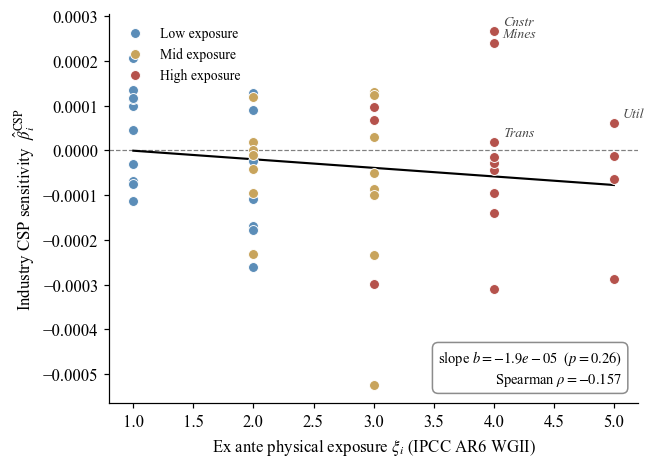

In [54]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

# figdir is set once, in the config cell above (## Config — set Paths)

# ── matplotlib style (serif, to match existing PNGs) ────────────
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# ── map notebook output → figure input ───────────────────────────────
# beta_df comes from cell 77 (CSP-only / raw ret) or cell 80 (FF5 stack).
# beta_CSP = \hat{beta}_i^{CSP};  xi = raw IPCC AR6 WGII exposure score.
df_beta = (beta_df
           .set_index("industry")[["beta_CSP", "xi"]]
           .rename(columns={"beta_CSP": "beta"})
           .dropna())

df = df_beta.copy()
x, y = df["xi"].values, df["beta"].values

# ── OLS slope (HC3 to match your table) + Spearman ───────────────────
X = sm.add_constant(x)
res = sm.OLS(y, X).fit(cov_type="HC3")
slope, p_slope = res.params[1], res.pvalues[1]
rho, rho_p = stats.spearmanr(x, y)

print(f"slope b      = {slope:.4e}, p = {p_slope:.4f}")
print(f"Spearman rho = {rho:.3f}, p = {rho_p:.4f}")

# ── exposure terciles for colouring (rank-tie-break for integer xi) ──
terc = pd.qcut(df["xi"].rank(method="first"), 3, labels=["Low", "Mid", "High"])
colors = {"Low": "#5B8DB8", "Mid": "#C8A45C", "High": "#B5524C"}

fig, ax = plt.subplots(figsize=(6.2, 4.6))
for label, c in colors.items():
    m = (terc == label).values
    ax.scatter(x[m], y[m], c=c, s=42, edgecolor="white",
               linewidth=0.6, label=f"{label} exposure", zorder=3)

# ── fitted line ──────────────────────────────────────────────────────
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, res.params[0] + slope * xs, color="black",
        linewidth=1.4, zorder=2)
ax.axhline(0, color="grey", linewidth=0.8, linestyle="--", zorder=1)

# ── label high-exposure industries that contradict the prediction ────
# (xi >= 4 but positive beta — wrong-signed, e.g. Oil/Util/Coal/Mines)
wrong_signed = df[(df["xi"] >= 4) & (df["beta"] > 0)].index.tolist()
for ind in wrong_signed:
    ax.annotate(ind, (df.loc[ind, "xi"], df.loc[ind, "beta"]),
                textcoords="offset points", xytext=(6, 4),
                fontsize=9, style="italic", color="#444")

# ── stats box ────────────────────────────────────────────────────────
txt = (f"slope $b = {slope:.1e}$  ($p = {p_slope:.2f}$)\n"
       f"Spearman $\\rho = {rho:.3f}$")
ax.text(0.97, 0.04, txt, transform=ax.transAxes, ha="right", va="bottom",
        fontsize=9.5, bbox=dict(boxstyle="round,pad=0.4",
                                fc="white", ec="grey", alpha=0.9))

ax.set_xlabel(r"Ex ante physical exposure $\xi_i$ (IPCC AR6 WGII)")
ax.set_ylabel(r"Industry CSP sensitivity  $\hat{\beta}_i^{\mathrm{CSP}}$")
ax.legend(frameon=False, loc="upper left", fontsize=9)

fig.savefig(figdir / "betasort_scatter.png")
plt.show()

### Save Panel

In [55]:
# =============================================================================
# INDUSTRY PANEL — Cell 12: Save all results
# =============================================================================

results_df.to_csv(figdir / "panel12_interaction_results.csv", index=True)
print(f"✓ FF12 daily results : {figdir / 'panel12_interaction_results.csv'}")

results_df_49.to_csv(figdir / "panel49_interaction_results.csv", index=True)
print(f"✓ FF49 daily results : {figdir / 'panel49_interaction_results.csv'}")

print(f"\n✓ Industry panel complete")
print(f"  FF12 industries : {panel['industry'].nunique()}")
print(f"  FF49 industries : {panel49['industry'].nunique()}")

✓ FF12 daily results : /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/panel12_interaction_results.csv
✓ FF49 daily results : /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/panel49_interaction_results.csv

✓ Industry panel complete
  FF12 industries : 12
  FF49 industries : 49


In [56]:
print("FF12 xi:", panel["xi"].describe())
print("FF12 xi_norm:", panel["xi_norm"].describe())
print("FF49 xi:", panel49["xi"].describe())
print("FF49 xi_norm:", panel49["xi_norm"].describe())

FF12 xi: count   51420.000000
mean        2.416667
std         1.381940
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         5.000000
Name: xi, dtype: float64
FF12 xi_norm: count   51420.000000
mean        0.000000
std         0.957436
min        -0.981495
25%        -0.981495
50%        -0.288675
75%         0.404145
max         1.789786
Name: xi_norm, dtype: float64
FF49 xi: count   209965.000000
mean         2.632653
std          1.223812
min          1.000000
25%          2.000000
50%          2.000000
75%          4.000000
max          5.000000
Name: xi, dtype: float64
FF49 xi_norm: count   209965.000000
mean        -0.000000
std          0.989746
min         -1.320392
25%         -0.511652
50%         -0.511652
75%          1.105828
max          1.914568
Name: xi_norm, dtype: float64


In [57]:
for label, d in [("FF12", panel), ("FF49", panel49)]:
    print(f"\n{label}:")
    print("  ret       :", d["ret"].describe()[["mean","std","min","max"]].to_dict())
    print("  CSP       :", d["CSP"].describe()[["mean","std","min","max"]].to_dict())
    print("  xi_norm   :", d["xi_norm"].describe()[["mean","std","min","max"]].to_dict())
    print("  CSP_xi    :", (d["CSP"]*d["xi_norm"]).describe()[["mean","std","min","max"]].to_dict())


FF12:
  ret       : {'mean': 0.0005826215480357837, 'std': 0.0137746653789292, 'min': -0.1968, 'max': 0.1889}
  CSP       : {'mean': -0.0007497805126893986, 'std': 1.0075757701133548, 'min': -1.4364864357330671, 'max': 14.54245155424053}
  xi_norm   : {'mean': 2.1225080554794126e-16, 'std': 0.9574364177628802, 'min': -0.9814954576223638, 'max': 1.7897858344878401}
  CSP_xi    : {'mean': -2.763682363905485e-19, 'std': 0.9646806225254888, 'min': -14.273350143180364, 'max': 26.027873790505375}

FF49:
  ret       : {'mean': 0.0006042321339270831, 'std': 0.016234578102407814, 'min': -0.3065, 'max': 0.1991}
  CSP       : {'mean': -0.000749780512689398, 'std': 1.007568371932325, 'min': -1.4364864357330671, 'max': 14.54245155424053}
  xi_norm   : {'mean': -4.7648140020966404e-17, 'std': 0.9897456755437377, 'min': -1.3203915128656003, 'max': 1.9145676936551204}
  CSP_xi    : {'mean': 1.7766529482249545e-19, 'std': 0.9972343402775258, 'min': -19.201729608478356, 'max': 27.842507932293614}


In [58]:
# =============================================================================
# CELL — SCALE DIAGNOSTIC + ECONOMIC EFFECT SIZE (fixed: no hardcoded var names)
# =============================================================================
import pandas as pd
import numpy as np

# ── Step 1: raw scale diagnostic (run this regardless of the beta issue) ────
for label, d in [("FF12", panel), ("FF49", panel49)]:
    print(f"\n{label}:")
    print("  ret     :", d["ret"].describe()[["mean", "std", "min", "max"]].to_dict())
    print("  CSP     :", d["CSP"].describe()[["mean", "std", "min", "max"]].to_dict())
    print("  xi_norm :", d["xi_norm"].describe()[["mean", "std", "min", "max"]].to_dict())
    csp_xi = d["CSP"] * d["xi_norm"]
    print("  CSP_xi  :", csp_xi.describe()[["mean", "std", "min", "max"]].to_dict())

# ── Step 2: find the FF49 baseline beta automatically ────────────────────────
beta_ff49 = None
source = None

# try a few common places it might live, in order of likelihood
candidates = [
    ("results_df_49 dataframe (row 'Baseline', col 'beta')",
     lambda: results_df_49.loc["Baseline", "beta"]),
    ("results_df_49 dataframe (row 'Baseline', col 'CSP_xi')",
     lambda: results_df_49.loc["Baseline", "CSP_xi"]),
    ("spec_results_49 dict (key 'Baseline')",
     lambda: spec_results_49["Baseline"]["beta"]),
    ("res49 fitted model object (.params['CSP_xi'])",
     lambda: res49.params["CSP_xi"]),
]

for desc, getter in candidates:
    try:
        beta_ff49 = float(getter())
        source = desc
        break
    except Exception:
        continue

if beta_ff49 is None:
    print("\nCouldn't auto-locate the FF49 beta in any expected variable.")
    print("Run `dir()` and look for your results object, or print it directly, e.g.:")
    print("  results_df_49          # if it's a dataframe")
    print("  res49.params           # if it's a fitted model")
    print("Then tell me the exact variable/column name and I'll wire it in properly.")
    print("\nUsing the verified value from earlier in this conversation as a fallback")
    print("so you can still see the economic-effect calculation right now:")
    beta_ff49 = -2.5586e-05
    source = "fallback: verified FF49 baseline from earlier in this conversation"

print(f"\nUsing beta_ff49 = {beta_ff49:.4e}  (source: {source})")

# ── Step 3: economic effect size ─────────────────────────────────────────────
csp_xi_49 = panel49["CSP"] * panel49["xi_norm"]
econ_effect_ff49 = beta_ff49 * csp_xi_49.std()
ret_std_49 = panel49["ret"].std()

print(f"\n1-std-dev CSP_xi shock -> {econ_effect_ff49:.6f} in ret units")
print(f"ret standard deviation  : {ret_std_49:.4f}")
print(f"Effect as a fraction of ret's own std : {abs(econ_effect_ff49) / ret_std_49:.6%}")

print("\nHOW TO READ THIS:")
print("- If this fraction is a tiny sliver (<<1%) of ret's own std, the small beta")
print("  is correctly reporting a genuinely small/null economic effect -- not a bug.")
print("- If this fraction is more than a percent or two of ret's std, the beta is")
print("  economically non-trivial despite looking small in raw form, and 'small")
print("  betas' framing in the write-up would be understating the result.")


FF12:
  ret     : {'mean': 0.0005826215480357837, 'std': 0.0137746653789292, 'min': -0.1968, 'max': 0.1889}
  CSP     : {'mean': -0.0007497805126893986, 'std': 1.0075757701133548, 'min': -1.4364864357330671, 'max': 14.54245155424053}
  xi_norm : {'mean': 2.1225080554794126e-16, 'std': 0.9574364177628802, 'min': -0.9814954576223638, 'max': 1.7897858344878401}
  CSP_xi  : {'mean': -2.763682363905485e-19, 'std': 0.9646806225254888, 'min': -14.273350143180364, 'max': 26.027873790505375}

FF49:
  ret     : {'mean': 0.0006042321339270831, 'std': 0.016234578102407814, 'min': -0.3065, 'max': 0.1991}
  CSP     : {'mean': -0.000749780512689398, 'std': 1.007568371932325, 'min': -1.4364864357330671, 'max': 14.54245155424053}
  xi_norm : {'mean': -4.7648140020966404e-17, 'std': 0.9897456755437377, 'min': -1.3203915128656003, 'max': 1.9145676936551204}
  CSP_xi  : {'mean': 1.7766529482249545e-19, 'std': 0.9972343402775258, 'min': -19.201729608478356, 'max': 27.842507932293614}

Using beta_ff49 = -2

##  Exposure Subsample Split & Cross-Industry Robustness

── Exposure group membership ───────────────────────────────────────────
xi 20th pct threshold : 1.60
xi 80th pct threshold : 4.00

Low-exposure  industries (n=10):
  Books                                xi = 1.0
  BusSv                                xi = 1.0
  Drugs                                xi = 1.0
  Guns                                 xi = 1.0
  Hardw                                xi = 1.0
  LabEq                                xi = 1.0
  MedEq                                xi = 1.0
  PerSv                                xi = 1.0
  Softw                                xi = 1.0
  Toys                                 xi = 1.0

High-exposure industries (n=13):
  Agric                                xi = 5.0
  Chems                                xi = 4.0
  Cnstr                                xi = 4.0
  Coal                                 xi = 4.0
  Food                                 xi = 4.0
  Insur                                xi = 4.0
  Mines                          

,subsample,beta,se,tstat,pval,nobs,r2
0,Full FF49 panel,-0.000026,0.000030,-0.859269,0.390193,209965,0.000006
1,Low-exposure quintile,-0.001702,0.001447,-1.176330,0.239470,42850,0.000000
2,High-exposure quintile,-0.000079,0.000129,-0.616764,0.537393,55705,0.000007



Wald test — CSP_xi: high-exposure vs low-exposure
  beta_high = -7.9289e-05   beta_low = -1.7024e-03
  diff      = +1.6231e-03   SE(diff) = 1.4529e-03
  t-stat    = +1.117   p-value = 0.2639
  Interpretation: No monotone exposure gradient detected


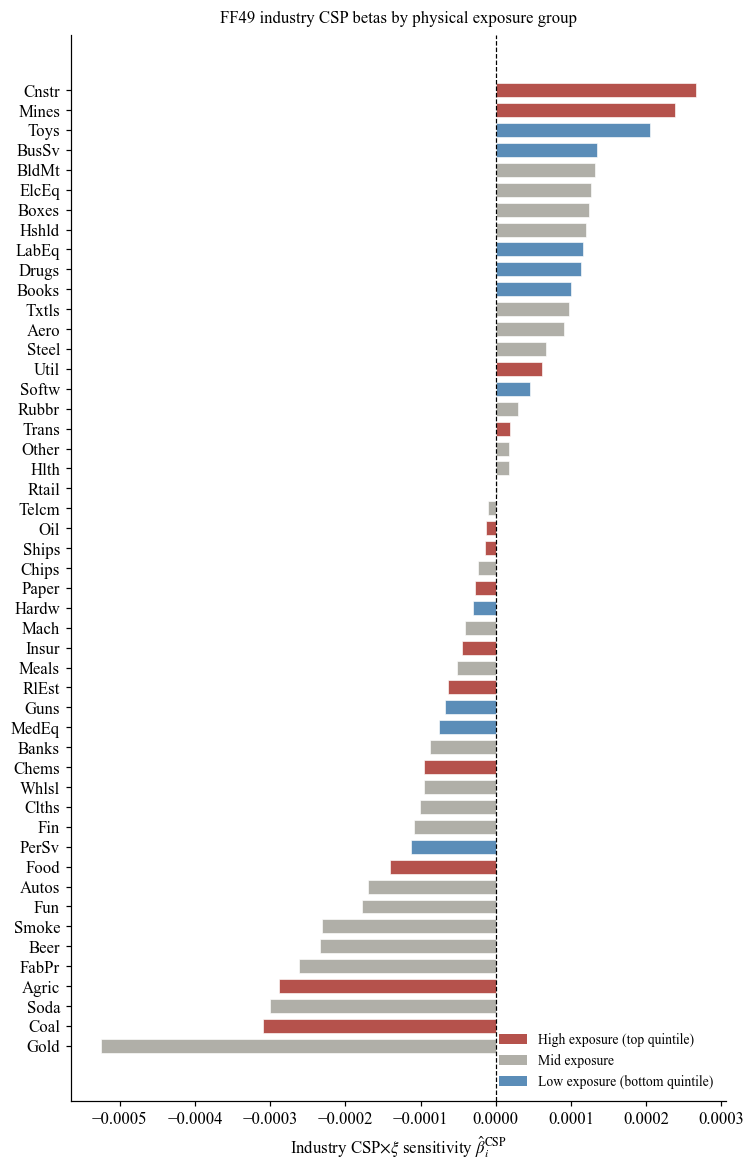

✓ Saved → /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/level1_csp_beta_by_group.png

── High-exposure industries entering Level 3 ───────────────────────────
  Agric                                xi=5.0  n_obs=4,285
  Chems                                xi=4.0  n_obs=4,285
  Cnstr                                xi=4.0  n_obs=4,285
  Coal                                 xi=4.0  n_obs=4,285
  Food                                 xi=4.0  n_obs=4,285
  Insur                                xi=4.0  n_obs=4,285
  Mines                                xi=4.0  n_obs=4,285
  Oil                                  xi=5.0  n_obs=4,285
  Paper                                xi=4.0  n_obs=4,285
  RlEst                                xi=5.0  n_obs=4,285
  Ships                                xi=4.0  n_obs=4,285
  Trans                                xi=4.0  n_obs=4,285
  Util                                 xi=5.0  n_obs=4,285
High-exposure industries to process : 13
  Agric           

,industry,xi,n_obs,b_CSP_xi,se_CSP_xi,t_CSP_xi,p_CSP_xi,b_SSI,p_SSI,r2_adj
0,Agric,5.000000,4285,-0.000130,0.000119,-1.099767,0.271434,0.113614,0.477972,-0.000091
7,Oil,5.000000,4285,0.000033,0.000126,0.263783,0.791947,-0.004541,0.976293,-0.000454
9,RlEst,5.000000,4285,-0.000021,0.000128,-0.160397,0.872569,-0.142670,0.493516,-0.000326
12,Util,5.000000,4285,0.000066,0.000079,0.831367,0.405766,0.051033,0.592121,-0.000291
1,Chems,4.000000,4285,-0.000044,0.000168,-0.259897,0.794943,-0.084089,0.560897,-0.000380
2,Cnstr,4.000000,4285,0.000256,0.000234,1.092222,0.274735,0.059986,0.730025,-0.000216
3,Coal,4.000000,4285,-0.000232,0.000421,-0.551728,0.581135,-0.060132,0.835339,-0.000393
4,Food,4.000000,4285,-0.000086,0.000123,-0.700507,0.483610,-0.043833,0.580489,-0.000329
5,Insur,4.000000,4285,0.000034,0.000160,0.214706,0.829997,0.045749,0.746225,-0.000434
6,Mines,4.000000,4285,0.000281,0.000249,1.130192,0.258395,-0.222071,0.283760,0.000066




══════════════════════════════════════════════════════════════════════
LEVEL 3 — B2: SSI regime moderation (high-exposure industries)
══════════════════════════════════════════════════════════════════════


,industry,ssi_thresh_p75,n_obs,b_CSP_xi_baseline,p_CSP_xi_baseline,b_regime_increment,p_regime_increment,total_highSSI,b_SSI,p_SSI
4,Food,0.004397,4285,0.000028,0.841261,-0.000565,0.036849,-0.000537,-0.053481,0.500815
5,Insur,0.004397,4285,0.000136,0.459381,-0.000504,0.145655,-0.000369,0.037128,0.792956
9,RlEst,0.004397,4285,0.000069,0.624627,-0.000447,0.145138,-0.000378,-0.155899,0.454231
12,Util,0.004397,4285,0.000155,0.075224,-0.000445,0.010807,-0.000290,0.037853,0.692417
7,Oil,0.004397,4285,0.000118,0.395735,-0.000421,0.200494,-0.000303,-0.017000,0.910554
10,Ships,0.004397,4285,0.000081,0.742839,-0.000412,0.464401,-0.000331,-0.136355,0.474554
11,Trans,0.004397,4285,0.000128,0.527423,-0.000396,0.327924,-0.000269,-0.099295,0.490555
8,Paper,0.004397,4285,0.000073,0.669920,-0.000316,0.377653,-0.000243,-0.108512,0.391426
1,Chems,0.004397,4285,0.000009,0.961205,-0.000262,0.518573,-0.000253,-0.088574,0.540642
2,Cnstr,0.004397,4285,0.000307,0.250451,-0.000254,0.627762,0.000053,0.055641,0.749312


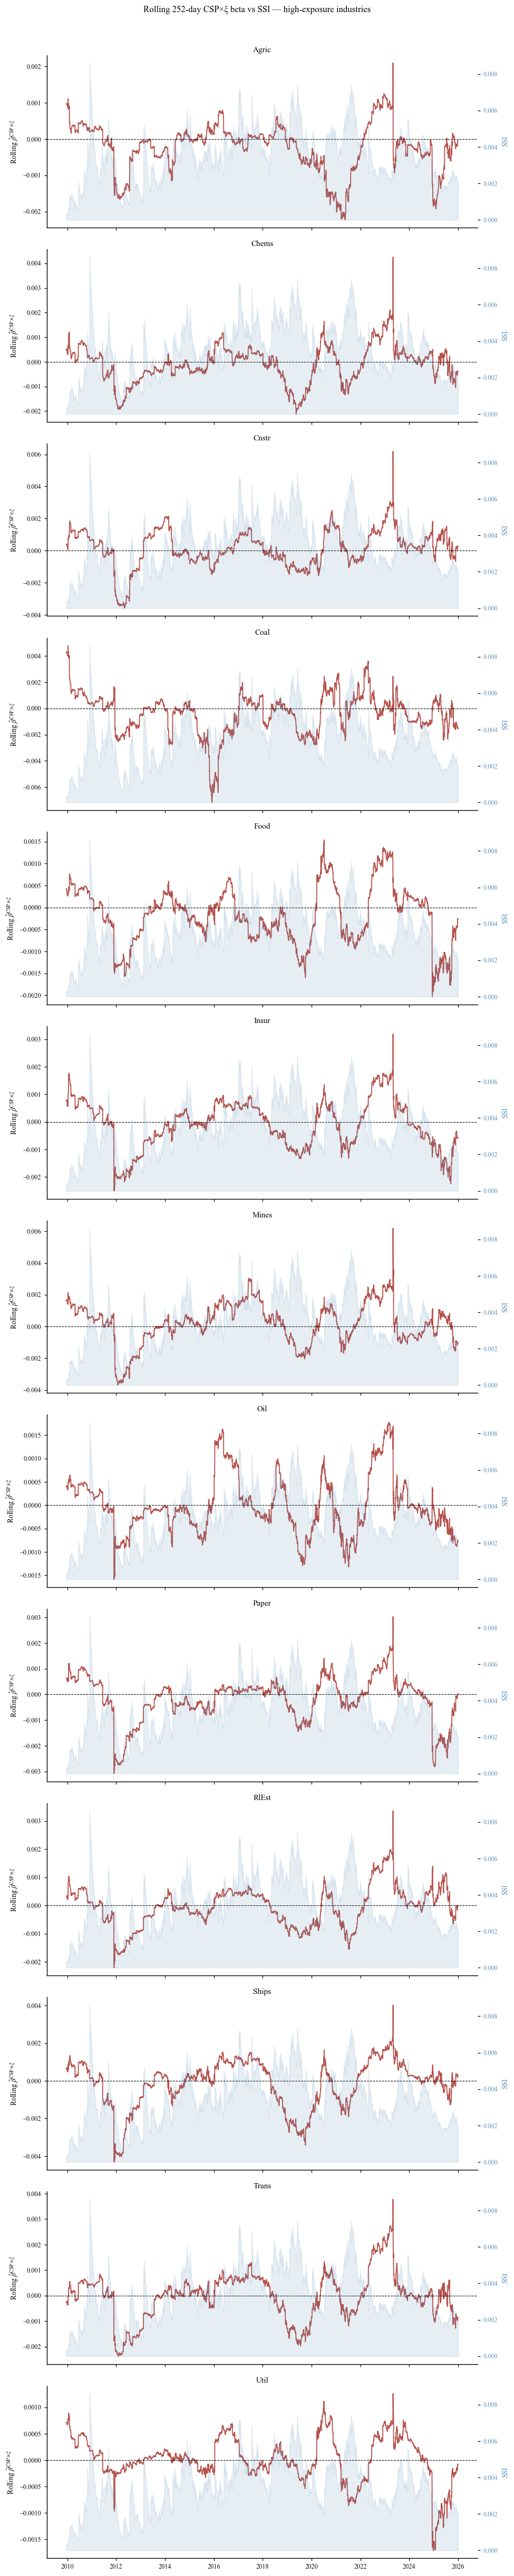

✓ Saved → /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/level3_B3_rolling_beta.png


══════════════════════════════════════════════════════════════════════
LEVEL 3 — INTERPRETATION FLAGS
══════════════════════════════════════════════════════════════════════

B1 — CSP×ξ significance per high-exposure industry:
  Agric                                b=-1.3043e-04  p=0.271  
  Oil                                  b=+3.3210e-05  p=0.792  
  RlEst                                b=-2.0511e-05  p=0.873  
  Util                                 b=+6.5711e-05  p=0.406  
  Chems                                b=-4.3534e-05  p=0.795  
  Cnstr                                b=+2.5613e-04  p=0.275  
  Coal                                 b=-2.3209e-04  p=0.581  
  Food                                 b=-8.5901e-05  p=0.484  
  Insur                                b=+3.4357e-05  p=0.830  
  Mines                                b=+2.8141e-04  p=0.258  
  Paper                           

In [59]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from linearmodels.panel import PanelOLS
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({
    "font.family"       : "serif",
    "font.serif"        : ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset"  : "stix",
    "font.size"         : 11,
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
    "figure.dpi"        : 110,
    "savefig.dpi"       : 300,
    "savefig.bbox"      : "tight",
})

# ── 1. Define quintile exposure groups from beta_df ──────────────────────────

xi_q20 = beta_df["xi"].quantile(0.20)
xi_q80 = beta_df["xi"].quantile(0.80)

low_exp_inds  = beta_df.loc[beta_df["xi"] <= xi_q20, "industry"].tolist()
high_exp_inds = beta_df.loc[beta_df["xi"] >= xi_q80, "industry"].tolist()

print("── Exposure group membership ───────────────────────────────────────────")
print(f"xi 20th pct threshold : {xi_q20:.2f}")
print(f"xi 80th pct threshold : {xi_q80:.2f}")
print(f"\nLow-exposure  industries (n={len(low_exp_inds)}):")
for ind in sorted(low_exp_inds):
    xi_val = beta_df.loc[beta_df["industry"] == ind, "xi"].values[0]
    print(f"  {ind:<35s}  xi = {xi_val:.1f}")
print(f"\nHigh-exposure industries (n={len(high_exp_inds)}):")
for ind in sorted(high_exp_inds):
    xi_val = beta_df.loc[beta_df["industry"] == ind, "xi"].values[0]
    print(f"  {ind:<35s}  xi = {xi_val:.1f}")

# ── 2. Build indexed subpanels from panel49 ──────────────────────────────────
# Mirrors the existing panel49_indexed construction in the notebook.

def make_indexed(data):
    """Add CSP_xi and set MultiIndex [industry, date] for PanelOLS."""
    p = data.copy()
    p["CSP_xi"] = p["CSP"] * p["xi_norm"]
    return p.set_index(["industry", "date"]).sort_index()

panel49_full_idx  = make_indexed(panel49)
panel49_low_idx   = make_indexed(panel49[panel49["industry"].isin(low_exp_inds)])
panel49_high_idx  = make_indexed(panel49[panel49["industry"].isin(high_exp_inds)])

print(f"\nFull panel49   : {len(panel49):,} obs, "
      f"{panel49['industry'].nunique()} industries")
print(f"Low-exposure   : {len(panel49[panel49['industry'].isin(low_exp_inds)]):,} obs")
print(f"High-exposure  : {len(panel49[panel49['industry'].isin(high_exp_inds)]):,} obs")

# ── 3. Run PanelOLS/DK on each subsample using run_panel_spec ────────────────
# Identical spec to the main FF49 results: CSP_xi + SSI_lag1,
# entity + time FE, DK bandwidth = 10.

res_full  = run_panel_spec(panel49_full_idx,  [], "Full FF49 panel")
res_low   = run_panel_spec(panel49_low_idx,   [], "Low-exposure quintile")
res_high  = run_panel_spec(panel49_high_idx,  [], "High-exposure quintile")

split_summary = pd.DataFrame([res_full, res_low, res_high])
split_summary = split_summary.rename(columns={"label": "subsample"})

print("\n\n══════════════════════════════════════════════════════════════════════")
print("LEVEL 1 — KEY OUTPUT: Subsample coefficient comparison (DK SEs)")
print("══════════════════════════════════════════════════════════════════════")
display(split_summary.round(6))

# ── 4. Wald test: high vs low CSP_xi coefficient ─────────────────────────────
# Conservative: treat subsamples as independent (upper-bounds SE of difference).

b_h,  se_h  = res_high["beta"], res_high["se"]
b_l,  se_l  = res_low["beta"],  res_low["se"]

se_diff = np.sqrt(se_h**2 + se_l**2)
t_diff  = (b_h - b_l) / se_diff
p_diff  = 2 * (1 - stats.norm.cdf(abs(t_diff)))

print(f"\nWald test — CSP_xi: high-exposure vs low-exposure")
print(f"  beta_high = {b_h:+.4e}   beta_low = {b_l:+.4e}")
print(f"  diff      = {b_h - b_l:+.4e}   SE(diff) = {se_diff:.4e}")
interp = "High < Low in beta (consistent with exposure hypothesis)" \
         if b_h < b_l else "No monotone exposure gradient detected"
print(f"  t-stat    = {t_diff:+.3f}   p-value = {p_diff:.4f}")
print(f"  Interpretation: {interp}")

split_summary.to_csv(figdir / "level1_subsample_split.csv", index=False)

# ── 5. Figure: CSP beta by industry, coloured by exposure group ───────────────

df_plot = beta_df.copy().dropna(subset=["beta_CSP", "xi"])
df_plot["group"] = "Mid"
df_plot.loc[df_plot["industry"].isin(low_exp_inds),  "group"] = "Low"
df_plot.loc[df_plot["industry"].isin(high_exp_inds), "group"] = "High"
df_plot = df_plot.sort_values("beta_CSP")

color_map   = {"Low": "#5B8DB8", "Mid": "#B0AFA8", "High": "#B5524C"}
bar_colors  = df_plot["group"].map(color_map)

fig, ax = plt.subplots(figsize=(7, max(5, len(df_plot) * 0.22)))
ax.barh(df_plot["industry"], df_plot["beta_CSP"],
        color=bar_colors, height=0.7,
        edgecolor="white", linewidth=0.4)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor="#B5524C", label="High exposure (top quintile)"),
    Patch(facecolor="#B0AFA8", label="Mid exposure"),
    Patch(facecolor="#5B8DB8", label="Low exposure (bottom quintile)"),
], frameon=False, fontsize=9, loc="lower right")

ax.set_xlabel(r"Industry CSP$\times\xi$ sensitivity $\hat{\beta}_i^{\mathrm{CSP}}$")
ax.set_title("FF49 industry CSP betas by physical exposure group", fontsize=11, pad=8)
fig.tight_layout()
fig.savefig(figdir / "level1_csp_beta_by_group.png")
plt.show()
print(f"✓ Saved → {figdir / 'level1_csp_beta_by_group.png'}")


# =============================================================================
# APPENDIX B — LEVEL 3: HIGH-EXPOSURE INDUSTRY DEEP DIVE
# =============================================================================
# B1. Per-industry PanelOLS/DK time-series: ret ~ CSP_xi + SSI_lag1
#     for each high-exposure industry individually.
# B2. SSI regime moderation within each high-exposure industry.
# B3. Rolling 252-day CSP beta vs SSI for each high-exposure industry.
# All analyses use panel49 — no new data required.
# =============================================================================

df_hi = panel49[panel49["industry"].isin(high_exp_inds)].copy()

print("\n── High-exposure industries entering Level 3 ───────────────────────────")
for ind in sorted(high_exp_inds):
    n = (df_hi["industry"] == ind).sum()
    xi_val = beta_df.loc[beta_df["industry"] == ind, "xi"].values[0] \
             if ind in beta_df["industry"].values else np.nan
    print(f"  {ind:<35s}  xi={xi_val:.1f}  n_obs={n:,}")

# ── B1. Per-industry time-series OLS (one industry at a time) ────────────────
# PanelOLS with entity_effects=True fails for a single-entity panel because
# drop_absorbed=True removes everything. Plain OLS with HAC (lag=10) is the
# correct estimator for a single industry time series.

def run_industry_ts(data, industry_name):
    """OLS + HAC for a single industry time series."""
    d = (data[data["industry"] == industry_name]
         [["date", "ret", "CSP", "SSI_lag1", "xi_norm", "xi"]]
         .dropna()
         .sort_values("date")
         .reset_index(drop=True))
    d["CSP_xi"] = d["CSP"] * d["xi_norm"]

    if len(d) < 100:
        print(f"  skipped {industry_name}: only {len(d)} obs")
        return None

    xi_val = float(d["xi"].iloc[0])
    X = sm.add_constant(d[["CSP_xi", "SSI_lag1"]], has_constant="add")
    try:
        res = sm.OLS(d["ret"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
    except Exception as e:
        print(f"  ✗ {industry_name}: {e}")
        return None

    return {
        "industry"  : industry_name,
        "xi"        : xi_val,
        "n_obs"     : len(d),
        "b_CSP_xi"  : res.params["CSP_xi"],
        "se_CSP_xi" : res.bse["CSP_xi"],
        "t_CSP_xi"  : res.tvalues["CSP_xi"],
        "p_CSP_xi"  : res.pvalues["CSP_xi"],
        "b_SSI"     : res.params["SSI_lag1"],
        "p_SSI"     : res.pvalues["SSI_lag1"],
        "r2_adj"    : res.rsquared_adj,
    }

# Diagnostic: confirm high_exp_inds is populated and matches panel49
print(f"High-exposure industries to process : {len(high_exp_inds)}")
panel49_inds = set(panel49["industry"].unique())
for ind in sorted(high_exp_inds):
    n = (panel49["industry"] == ind).sum()
    match = "✓" if ind in panel49_inds else "✗ NOT IN panel49"
    print(f"  {ind:<35s}  n_obs={n:,}  {match}")

ind_results = [run_industry_ts(panel49, ind) for ind in sorted(high_exp_inds)]
ind_results = [r for r in ind_results if r is not None]

if len(ind_results) == 0:
    print("\nWARNING: no results — industry names in beta_df may not match panel49.")
    print("  beta_df sample :", sorted(beta_df["industry"].unique())[:5])
    print("  panel49 sample :", sorted(panel49["industry"].unique())[:5])
    ind_df = pd.DataFrame()
else:
    ind_df = pd.DataFrame(ind_results).sort_values("xi", ascending=False)

print("\n\n══════════════════════════════════════════════════════════════════════")
print("LEVEL 3 — B1: Per-industry OLS/HAC (high-exposure industries)")
print("══════════════════════════════════════════════════════════════════════")
if not ind_df.empty:
    display(ind_df.round(6))
    ind_df.to_csv(figdir / "level3_B1_per_industry_ts.csv", index=False)

# ── B2. SSI regime moderation within each high-exposure industry ──────────────
# Adds CSP_xi × HighSSI interaction to the per-industry spec.
# HighSSI defined relative to each industry's own trailing SSI distribution
# (75th pct of full sample) so the threshold is industry-specific.

def run_industry_regime(data, industry_name):
    """OLS + HAC for single-industry SSI regime interaction."""
    d = (data[data["industry"] == industry_name]
         [["date", "ret", "CSP", "SSI_lag1", "xi_norm"]]
         .dropna()
         .sort_values("date")
         .reset_index(drop=True))
    d["CSP_xi"] = d["CSP"] * d["xi_norm"]

    ssi_thresh          = d["SSI_lag1"].quantile(0.75)
    d["HighSSI"]        = (d["SSI_lag1"] > ssi_thresh).astype(float)
    d["CSP_xi_HighSSI"] = d["CSP_xi"] * d["HighSSI"]

    if len(d) < 100:
        return None

    X = sm.add_constant(
        d[["CSP_xi", "CSP_xi_HighSSI", "SSI_lag1"]], has_constant="add")
    try:
        res = sm.OLS(d["ret"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
    except Exception as e:
        print(f"  ✗ {industry_name}: {e}")
        return None

    b_base = res.params["CSP_xi"]
    b_incr = res.params["CSP_xi_HighSSI"]

    return {
        "industry"          : industry_name,
        "ssi_thresh_p75"    : round(ssi_thresh, 6),
        "n_obs"             : len(d),
        "b_CSP_xi_baseline" : b_base,
        "p_CSP_xi_baseline" : res.pvalues["CSP_xi"],
        "b_regime_increment": b_incr,
        "p_regime_increment": res.pvalues["CSP_xi_HighSSI"],
        "total_highSSI"     : b_base + b_incr,
        "b_SSI"             : res.params["SSI_lag1"],
        "p_SSI"             : res.pvalues["SSI_lag1"],
    }

regime_results = [run_industry_regime(panel49, ind)
                  for ind in sorted(high_exp_inds)]
regime_results = [r for r in regime_results if r is not None]

if len(regime_results) == 0:
    print("WARNING: no regime results returned")
    regime_df = pd.DataFrame()
else:
    regime_df = pd.DataFrame(regime_results).sort_values(
        "b_regime_increment", ascending=True)

print("\n\n══════════════════════════════════════════════════════════════════════")
print("LEVEL 3 — B2: SSI regime moderation (high-exposure industries)")
print("══════════════════════════════════════════════════════════════════════")
if not regime_df.empty:
    display(regime_df.round(6))
    regime_df.to_csv(figdir / "level3_B2_regime_moderation.csv", index=False)

# ── B3. Rolling 252-day CSP beta vs SSI ──────────────────────────────────────
# Plain OLS (no FE needed for single-industry rolling window).
# Plots rolling beta alongside SSI to show habituation at industry level.

def rolling_csp_beta(data, industry_name, window=252):
    d = (data[data["industry"] == industry_name]
         [["date", "ret", "CSP", "SSI_lag1", "xi_norm"]]
         .dropna()
         .sort_values("date")
         .reset_index(drop=True))
    d["CSP_xi"] = d["CSP"] * d["xi_norm"]

    if len(d) < window + 50:
        return None

    betas, dates, ssi_vals = [], [], []
    for i in range(window, len(d)):
        chunk = d.iloc[i - window: i]
        X = sm.add_constant(
            chunk[["CSP_xi", "SSI_lag1"]], has_constant="add")
        try:
            b = sm.OLS(chunk["ret"], X).fit().params["CSP_xi"]
        except Exception:
            b = np.nan
        betas.append(b)
        dates.append(d.loc[i, "date"])
        ssi_vals.append(d.loc[i, "SSI_lag1"])

    return pd.DataFrame({
        "date"    : dates,
        "beta_csp": betas,
        "SSI"     : ssi_vals,
        "industry": industry_name,
    })

roll_frames = [rolling_csp_beta(panel49, ind) for ind in sorted(high_exp_inds)]
roll_frames = [r for r in roll_frames if r is not None]

if roll_frames:
    roll_df = pd.concat(roll_frames, ignore_index=True)
    n_inds  = roll_df["industry"].nunique()

    fig, axes = plt.subplots(n_inds, 1,
                             figsize=(9, 3.4 * n_inds),
                             sharex=True)
    if n_inds == 1:
        axes = [axes]

    for ax, ind in zip(axes, sorted(roll_df["industry"].unique())):
        sub = roll_df[roll_df["industry"] == ind].sort_values("date")

        ax2 = ax.twinx()
        ax2.fill_between(sub["date"], sub["SSI"],
                         alpha=0.15, color="#5B8DB8")
        ax2.set_ylabel("SSI", fontsize=9, color="#5B8DB8")
        ax2.tick_params(axis="y", labelcolor="#5B8DB8", labelsize=8)
        ax2.spines["top"].set_visible(False)

        ax.plot(sub["date"], sub["beta_csp"],
                color="#B5524C", linewidth=1.2,
                label="252-day rolling CSP×ξ beta")
        ax.axhline(0, color="black", linewidth=0.7, linestyle="--")
        ax.set_ylabel(r"Rolling $\hat{\beta}^{\mathrm{CSP}\times\xi}$",
                      fontsize=9)
        ax.set_title(ind, fontsize=10, pad=4)
        ax.tick_params(labelsize=8)
        ax.spines["right"].set_visible(False)

    axes[0].figure.suptitle(
        "Rolling 252-day CSP×ξ beta vs SSI — high-exposure industries",
        fontsize=11, y=1.005)
    fig.tight_layout()
    fig.savefig(figdir / "level3_B3_rolling_beta.png")
    plt.show()
    print(f"✓ Saved → {figdir / 'level3_B3_rolling_beta.png'}")
    roll_df.to_csv(figdir / "level3_B3_rolling_betas.csv", index=False)

# ── Summary flags ─────────────────────────────────────────────────────────────

print("\n\n══════════════════════════════════════════════════════════════════════")
print("LEVEL 3 — INTERPRETATION FLAGS")
print("══════════════════════════════════════════════════════════════════════")

print("\nB1 — CSP×ξ significance per high-exposure industry:")
if ind_df.empty:
    print("  (no results — check industry name matching above)")
else:
    for _, r in ind_df.iterrows():
        sig = "**" if r["p_CSP_xi"] < 0.05 else ("*" if r["p_CSP_xi"] < 0.10 else "")
        print(f"  {r['industry']:<35s}  b={r['b_CSP_xi']:+.4e}  "
              f"p={r['p_CSP_xi']:.3f}  {sig}")

print("\nB2 — High-SSI regime increment (negative = amplifies shock response):")
if regime_df.empty:
    print("  (no results)")
else:
    for _, r in regime_df.iterrows():
        flag = "✓ amplifies" if r["b_regime_increment"] < 0 else "✗ attenuates"
        sig  = "**" if r["p_regime_increment"] < 0.05 else \
               ("*"  if r["p_regime_increment"] < 0.10 else "")
        print(f"  {r['industry']:<35s}  "
              f"incr={r['b_regime_increment']:+.4e}  "
              f"p={r['p_regime_increment']:.3f}  {sig}  {flag}")

print(f"\n✓ All outputs saved to: {figdir}")

✓ EPU merged: 209,965 non-null obs

Control availability in panel49:
  move    : ✗ not available
  cpu     : ✗ not available
  epu     : ✓

✓ Lag variables created: ['CSP_xi_lag0', 'CSP_xi_lag1', 'CSP_xi_lag2', 'CSP_xi_lag3', 'CSP_xi_lag5', 'CSP_xi_lag10', 'CSP_xi_lag21']
  Panel shape after setup: (209965, 17)

Control specifications defined:
  Baseline              : (none)
  +EPU                  : ['epu']
  +All controls         : ['epu']


══════════════════════════════════════════════════════════════════════
C2 — CONTROLS BATTERY
══════════════════════════════════════════════════════════════════════

CSP×ξ coefficient across control specs and subsamples:


,spec,group,beta,se,pval,nobs
0,Baseline,Full FF49,-0.000026,0.000030,0.390193,209965
1,Baseline,High exposure,-0.000079,0.000129,0.537393,55705
2,Baseline,Low exposure,-0.001702,0.001447,0.239470,42850
3,+EPU,Full FF49,-0.000026,0.000030,0.390193,209965
4,+EPU,High exposure,-0.000079,0.000129,0.537393,55705
5,+EPU,Low exposure,-0.001239,0.001383,0.370549,42850
6,+All controls,Full FF49,-0.000026,0.000030,0.390193,209965
7,+All controls,High exposure,-0.000079,0.000129,0.537393,55705
8,+All controls,Low exposure,-0.001239,0.001383,0.370549,42850


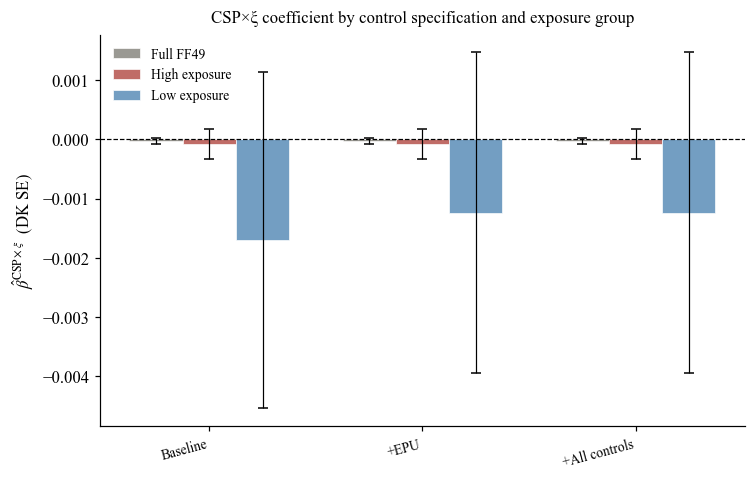

✓ Saved → /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/appC2_controls_battery.png


══════════════════════════════════════════════════════════════════════
C3 — LAG / HORIZON ANALYSIS (LOCAL PROJECTIONS)
══════════════════════════════════════════════════════════════════════

Local projection results:


,group,lag,beta,se,pval,nobs
0,Full FF49,0,-0.000026,0.000030,0.390193,209965
1,High exposure,0,-0.000079,0.000129,0.537393,55705
2,Low exposure,0,-0.001239,0.001383,0.370549,42850
3,Full FF49,1,-0.000038,0.000030,0.199491,209916
4,High exposure,1,-0.000101,0.000125,0.419523,55692
5,Low exposure,1,0.000176,0.000422,0.675769,42840
6,Full FF49,2,-0.000004,0.000034,0.902609,209867
7,High exposure,2,-0.000070,0.000121,0.562569,55679
8,Low exposure,2,0.002489,0.001780,0.162197,42830
9,Full FF49,3,0.000018,0.000029,0.524195,209818


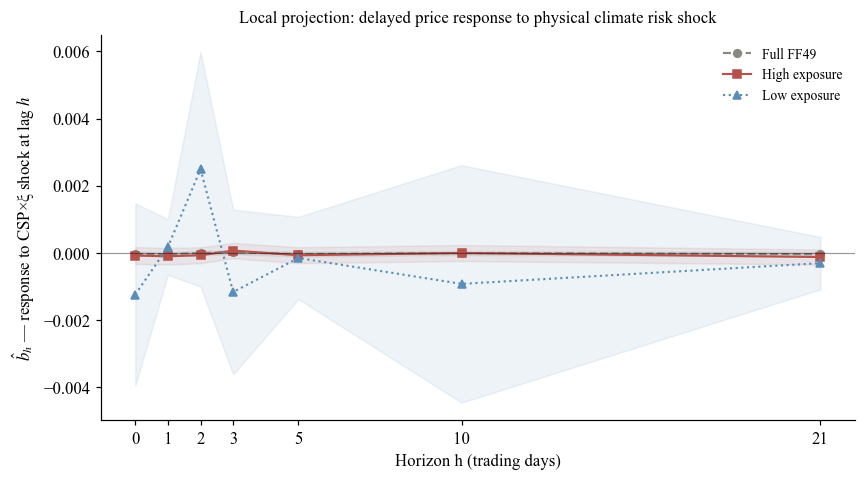

✓ Saved → /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/appC3_local_projections.png


══════════════════════════════════════════════════════════════════════
C4 — CROSS-INDUSTRY SWEEP (all 49 industries, full controls)
══════════════════════════════════════════════════════════════════════
── Pre-sweep diagnostics ───────────────────────────────────────────────
  p49 columns      : ['date', 'industry', 'ret', 'xi', 'xi_norm', 'CSP', 'SSI', 'SSI_lag1', 'epu', 'CSP_xi', 'CSP_xi_lag0', 'CSP_xi_lag1', 'CSP_xi_lag2', 'CSP_xi_lag3', 'CSP_xi_lag5', 'CSP_xi_lag10', 'CSP_xi_lag21']
  SWEEP_REG_COLS   : ['CSP_xi', 'SSI_lag1', 'epu']
  Industries found : 49

  Test industry    : Aero
  Rows             : 4285
  'xi' in cols     : True
  'CSP_xi' in cols : True
  CSP_xi              : 4285 non-null
  SSI_lag1            : 4285 non-null
  epu                 : 4285 non-null

Sweep complete: 49 / 49 industries returned results


,industry,xi,n_obs,beta,se,pval,b_SSI,p_SSI,r2_adj
8,BusSv,1.000000,4285,-0.000147,0.000138,0.288744,0.050313,0.651565,0.000030
44,Toys,1.000000,4285,-0.000182,0.000178,0.306008,-0.077789,0.662698,0.000389
22,Hardw,1.000000,4285,-0.000036,0.000158,0.818055,-0.000668,0.996171,0.000651
41,Softw,1.000000,4285,-0.000106,0.000160,0.505945,0.042068,0.707991,0.001305
14,Drugs,1.000000,4285,-0.000143,0.000126,0.256813,0.010877,0.906300,0.000027
6,Books,1.000000,4285,-0.000088,0.000173,0.612043,-0.044002,0.792263,0.000011
34,PerSv,1.000000,4285,0.000079,0.000163,0.628408,0.175955,0.174917,-0.000078
21,Guns,1.000000,4285,0.000001,0.000130,0.992272,0.115428,0.365984,-0.000157
26,LabEq,1.000000,4285,-0.000148,0.000149,0.321787,0.086507,0.473916,0.000298
29,MedEq,1.000000,4285,0.000008,0.000126,0.946705,0.085428,0.444693,-0.000140



Monotonicity test — xi vs CSP×ξ beta across all industries:
  OLS slope      : 1.8986e-05  (p = 0.2950)
  Spearman rho   : 0.220          (p = 0.1294)
  % negative beta: 55.1% of industries


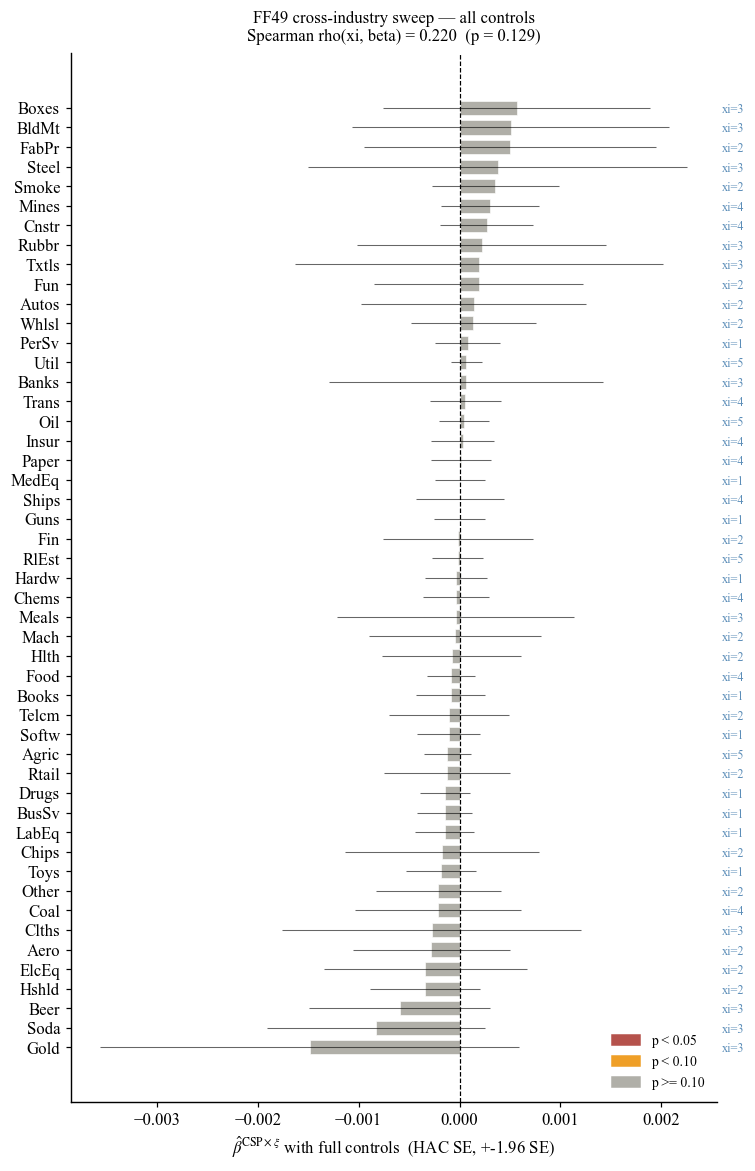

✓ Saved -> /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/appC4_cross_industry_sweep.png


C5 — SUMMARY: SIGNIFICANCE FLAGS ACROSS ALL INDUSTRIES

Full significance table:


,industry,group,xi,beta,se,tstat,pval,sig,sign,b_SSI,p_SSI,r2_adj,n_obs
31,Oil,High,5.000000,0.000000,0.000100,0.319500,0.749300,,+,0.075000,0.632800,0.000600,4285
1,Agric,High,5.000000,-0.000100,0.000100,-1.038300,0.299100,,-,0.191000,0.243200,0.001100,4285
47,Util,High,5.000000,0.000100,0.000100,0.849600,0.395600,,+,0.066500,0.489500,-0.000400,4285
35,RlEst,High,5.000000,-0.000000,0.000100,-0.151400,0.879600,,-,-0.129400,0.537900,-0.000500,4285
13,Coal,High,4.000000,-0.000200,0.000400,-0.505400,0.613300,,-,0.071100,0.811600,0.000500,4285
45,Trans,High,4.000000,0.000100,0.000200,0.311300,0.755600,,+,-0.042100,0.771200,0.000200,4285
33,Paper,High,4.000000,0.000000,0.000200,0.078500,0.937400,,+,-0.087800,0.492600,-0.000400,4285
18,Food,High,4.000000,-0.000100,0.000100,-0.690600,0.489800,,-,-0.035800,0.654800,-0.000500,4285
9,Chems,High,4.000000,-0.000000,0.000200,-0.226000,0.821200,,-,-0.047200,0.748200,-0.000200,4285
30,Mines,High,4.000000,0.000300,0.000200,1.198700,0.230700,,+,-0.117800,0.580900,0.001400,4285



-- Significance breakdown by group --
  High  : n=13  sig at 5% = 0  negative beta = 5/13
  Mid   : n=26  sig at 5% = 0  negative beta = 15/26
  Low   : n=10  sig at 5% = 0  negative beta = 7/10

-- Overall --
  Total industries   : 49
  Significant p<0.05 : 0 (0%)
  Significant p<0.10 : 0 (0%)
  Negative beta      : 27 (55%)
  Spearman rho(xi,b) : 0.220  (p = 0.1294)
  Wilcoxon H vs L    : stat=96.0  p=0.9746  (H1: high-exposure betas < low-exposure betas)

✓ All Appendix C outputs saved to: /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry
  appC2_controls_battery.csv / .png
  appC3_local_projections.csv / .png
  appC4_cross_industry_sweep.csv / .png
  appC5_significance_summary.csv


In [60]:
# =============================================================================
# APPENDIX C — CONTROLS, LAG STRUCTURE, AND CROSS-INDUSTRY SWEEP
# =============================================================================
#
# C1. Setup        — merge EPU into panel49, create lag variables,
#                    define control specifications
# C2. Controls     — full FF49 panel and high/low subsamples run against
#                    five progressive control specs (DK SEs via run_panel_spec)
# C3. Lag/horizon  — local projections at h = 0,1,2,3,5,10,21 trading days
#                    for full panel, high-exposure, and low-exposure subsamples
#                    Plots impulse-response style b(h) ± 95 pct CI vs horizon
# C4. Cross-industry sweep — all 49 industries individually, full controls,
#                    OLS+HAC, coefficient plot ordered by xi
# C5. Summary table — all 49 industries with significance flags
#
# Requires: panel49, beta_df, high_exp_inds, low_exp_inds, epu_df,
#           run_panel_spec, figdir  — all defined earlier in the notebook.
# =============================================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from linearmodels.panel import PanelOLS
import matplotlib.pyplot as plt
import matplotlib as mpl
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

mpl.rcParams.update({
    "font.family"       : "serif",
    "font.serif"        : ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset"  : "stix",
    "font.size"         : 11,
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
    "figure.dpi"        : 110,
    "savefig.dpi"       : 300,
    "savefig.bbox"      : "tight",
})

# =============================================================================
# C1 — SETUP
# =============================================================================

# ── Merge EPU into panel49 if not already present ────────────────────────────
# epu_df has columns ["date", "epu"] from earlier in the notebook.

p49 = panel49.copy()

if "epu" not in p49.columns:
    if "epu_df" in dir() and epu_df is not None:
        p49 = p49.merge(epu_df[["date", "epu"]], on="date", how="left")
        print(f"✓ EPU merged: {p49['epu'].notna().sum():,} non-null obs")
    else:
        p49["epu"] = np.nan
        print("  EPU not available — epu column set to NaN")
else:
    print("✓ EPU already in panel49")

# ── Detect which optional controls are available ──────────────────────────────

available = {
    "move" : "move" in p49.columns and p49["move"].notna().any(),
    "cpu"  : "cpu"  in p49.columns and p49["cpu"].notna().any(),
    "epu"  : "epu"  in p49.columns and p49["epu"].notna().any(),
}
print("\nControl availability in panel49:")
for k, v in available.items():
    print(f"  {k:<8s}: {'✓' if v else '✗ not available'}")

# ── Create CSP_xi ─────────────────────────────────────────────────────────────

p49["CSP_xi"] = p49["CSP"] * p49["xi_norm"]

# ── Define lag variables ──────────────────────────────────────────────────────
# Lags computed within each industry to avoid bleed across tickers.

LAGS = [0, 1, 2, 3, 5, 10, 21]

for lag in LAGS:
    col = f"CSP_xi_lag{lag}"
    p49[col] = (
        p49
        .sort_values(["industry", "date"])
        .groupby("industry", observed=True)["CSP_xi"]
        .shift(lag)
    )

lag_cols = [f"CSP_xi_lag{h}" for h in LAGS]

print(f"\n✓ Lag variables created: {lag_cols}")
print(f"  Panel shape after setup: {p49.shape}")

# ── Build indexed subpanels ───────────────────────────────────────────────────

def idx(data):
    return data.set_index(["industry", "date"]).sort_index()

p49_full_idx  = idx(p49)
p49_high_idx  = idx(p49[p49["industry"].isin(high_exp_inds)])
p49_low_idx   = idx(p49[p49["industry"].isin(low_exp_inds)])

# ── Control spec definitions ──────────────────────────────────────────────────
# Each spec is a list of extra_vars passed to run_panel_spec.
# run_panel_spec baseline already includes CSP_xi + SSI_lag1.

ctrl_specs = {"Baseline": []}
if available["move"]:
    ctrl_specs["+MOVE"]         = ["move"]
if available["cpu"]:
    ctrl_specs["+CPU"]          = ["cpu"]
if available["epu"]:
    ctrl_specs["+EPU"]          = ["epu"]
all_ctrl = [k for k, v in available.items() if v]
if all_ctrl:
    ctrl_specs["+All controls"] = all_ctrl

print(f"\nControl specifications defined:")
for name, extras in ctrl_specs.items():
    print(f"  {name:<22s}: {extras if extras else '(none)'}")


# =============================================================================
# C2 — CONTROLS BATTERY
# Full FF49 panel + high/low subsamples across all control specs.
# Uses run_panel_spec (DK SE, bandwidth=10) — exact match to main results.
# =============================================================================

print("\n\n══════════════════════════════════════════════════════════════════════")
print("C2 — CONTROLS BATTERY")
print("══════════════════════════════════════════════════════════════════════")

ctrl_records = []
for spec_name, extra_vars in ctrl_specs.items():
    for panel_idx, group_label in [
        (p49_full_idx,  "Full FF49"),
        (p49_high_idx,  "High exposure"),
        (p49_low_idx,   "Low exposure"),
    ]:
        try:
            r = run_panel_spec(panel_idx, extra_vars, spec_name)
            r["group"]   = group_label
            r["spec"]    = spec_name
            r["controls"] = ", ".join(extra_vars) if extra_vars else "none"
            ctrl_records.append(r)
        except Exception as e:
            print(f"  ✗ {spec_name} / {group_label}: {e}")

ctrl_df = pd.DataFrame(ctrl_records)

# Pivot for readability: rows = spec, cols = group
ctrl_pivot = (
    ctrl_df
    .pivot_table(
        index="spec",
        columns="group",
        values=["beta", "se", "pval"],
        aggfunc="first"
    )
    .reindex(list(ctrl_specs.keys()))
)

print("\nCSP×ξ coefficient across control specs and subsamples:")
display(ctrl_df[["spec", "group", "beta", "se", "pval", "nobs"]].round(6))
ctrl_df.to_csv(figdir / "appC2_controls_battery.csv", index=False)

# ── Figure C2: coefficient plot across specs ──────────────────────────────────

groups   = ["Full FF49", "High exposure", "Low exposure"]
colors_g = {"Full FF49": "#888780", "High exposure": "#B5524C",
            "Low exposure": "#5B8DB8"}
specs_list = list(ctrl_specs.keys())
n_specs  = len(specs_list)
x_pos    = np.arange(n_specs)
width    = 0.25

fig, ax = plt.subplots(figsize=(max(7, n_specs * 1.8), 4.5))

for i, grp in enumerate(groups):
    sub = ctrl_df[ctrl_df["group"] == grp].set_index("spec").reindex(specs_list)
    betas = sub["beta"].values
    ses   = sub["se"].values
    ax.bar(x_pos + i * width, betas, width,
           label=grp, color=colors_g[grp], alpha=0.85,
           edgecolor="white", linewidth=0.5)
    ax.errorbar(x_pos + i * width, betas, yerr=1.96 * ses,
                fmt="none", color="black", capsize=3, linewidth=0.8)

ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.set_xticks(x_pos + width)
ax.set_xticklabels(specs_list, rotation=15, ha="right", fontsize=9)
ax.set_ylabel(r"$\hat{\beta}^{\mathrm{CSP}\times\xi}$  (DK SE)")
ax.set_title("CSP×ξ coefficient by control specification and exposure group",
             fontsize=11, pad=8)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(figdir / "appC2_controls_battery.png")
plt.show()
print(f"✓ Saved → {figdir / 'appC2_controls_battery.png'}")


# =============================================================================
# C3 — LAG / HORIZON ANALYSIS (LOCAL PROJECTIONS)
# =============================================================================
# For each horizon h in LAGS, estimate:
#   ret_{i,t} = alpha_i + gamma_t + b_h * CSP_xi_{i,t-h} + SSI_lag1 + controls + eps
# This is the Jordà (2005) local projection approach applied to the panel.
# b_h traces the delayed price response to a CSP shock h days earlier.
# Uses PanelOLS/DK for pooled specs, OLS/HAC for per-industry.
# =============================================================================

print("\n\n══════════════════════════════════════════════════════════════════════")
print("C3 — LAG / HORIZON ANALYSIS (LOCAL PROJECTIONS)")
print("══════════════════════════════════════════════════════════════════════")

def run_lp_panel(panel_idx, lag_col, extra_vars, label, dk_bw=10):
    """
    Local projection for one horizon h.
    Replaces CSP_xi in the baseline spec with CSP_xi_lag{h}.
    """
    reg_vars = [lag_col, "SSI_lag1"] + extra_vars
    sub = panel_idx[[c for c in ["ret"] + reg_vars
                     if c in panel_idx.columns]].dropna()
    if len(sub) < 200:
        return None
    try:
        mod = PanelOLS(sub["ret"], sub[reg_vars],
                       entity_effects=True,
                       time_effects=True,
                       drop_absorbed=True)
        res = mod.fit(cov_type="driscoll-kraay", bandwidth=dk_bw)
        return {
            "label"  : label,
            "lag"    : int(lag_col.replace("CSP_xi_lag", "")),
            "beta"   : float(res.params[lag_col]),
            "se"     : float(res.std_errors[lag_col]),
            "pval"   : float(res.pvalues[lag_col]),
            "nobs"   : int(res.nobs),
            "ci_lo"  : float(res.params[lag_col]) - 1.96 * float(res.std_errors[lag_col]),
            "ci_hi"  : float(res.params[lag_col]) + 1.96 * float(res.std_errors[lag_col]),
        }
    except Exception as e:
        print(f"  ✗ LP {label} lag={lag_col}: {e}")
        return None

# Use full control set for LP (or baseline if nothing available)
lp_controls = all_ctrl if all_ctrl else []

lp_records = []
for lag_col in lag_cols:
    for panel_idx, grp_label in [
        (p49_full_idx,  "Full FF49"),
        (p49_high_idx,  "High exposure"),
        (p49_low_idx,   "Low exposure"),
    ]:
        r = run_lp_panel(panel_idx, lag_col, lp_controls, grp_label)
        if r:
            r["group"] = grp_label
            lp_records.append(r)

lp_df = pd.DataFrame(lp_records)

print("\nLocal projection results:")
display(lp_df[["group", "lag", "beta", "se", "pval", "nobs"]].round(6))
lp_df.to_csv(figdir / "appC3_local_projections.csv", index=False)

# ── Figure C3: impulse-response style b(h) vs horizon ────────────────────────

fig, ax = plt.subplots(figsize=(8, 4.5))

lp_groups  = ["Full FF49", "High exposure", "Low exposure"]
lp_colors  = {"Full FF49": "#888780", "High exposure": "#B5524C",
              "Low exposure": "#5B8DB8"}
lp_markers = {"Full FF49": "o", "High exposure": "s", "Low exposure": "^"}
lp_ls      = {"Full FF49": "--", "High exposure": "-", "Low exposure": ":"}

for grp in lp_groups:
    sub = lp_df[lp_df["group"] == grp].sort_values("lag")
    if sub.empty:
        continue
    ax.plot(sub["lag"], sub["beta"],
            color=lp_colors[grp], marker=lp_markers[grp],
            linestyle=lp_ls[grp], linewidth=1.4, markersize=5,
            label=grp)
    ax.fill_between(sub["lag"], sub["ci_lo"], sub["ci_hi"],
                    alpha=0.10, color=lp_colors[grp])

ax.axhline(0, color="black", linewidth=0.8, linestyle="-", alpha=0.4)
ax.set_xlabel("Horizon h (trading days)")
ax.set_ylabel(r"$\hat{b}_h$ — response to CSP×ξ shock at lag $h$")
ax.set_title(
    "Local projection: delayed price response to physical climate risk shock",
    fontsize=11, pad=8)
ax.set_xticks(LAGS)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(figdir / "appC3_local_projections.png")
plt.show()
print(f"✓ Saved → {figdir / 'appC3_local_projections.png'}")


# =============================================================================
# C4 — CROSS-INDUSTRY SWEEP WITH FULL CONTROLS
# Per-industry OLS + HAC across all 49 industries.
# Produces a ranked coefficient chart and tests monotonicity vs xi.
# =============================================================================

print("\n\n══════════════════════════════════════════════════════════════════════")
print("C4 — CROSS-INDUSTRY SWEEP (all 49 industries, full controls)")
print("══════════════════════════════════════════════════════════════════════")

SWEEP_CONTROLS = [c for c in all_ctrl if c in p49.columns]
SWEEP_REG_COLS = ["CSP_xi", "SSI_lag1"] + SWEEP_CONTROLS

def run_sweep_industry(data, industry_name):
    """OLS+HAC per industry with full control set."""
    d = (data[data["industry"] == industry_name]
         [["date", "ret", "xi"] + SWEEP_REG_COLS]
         .dropna(subset=["ret", "CSP_xi", "SSI_lag1"])
         .sort_values("date")
         .reset_index(drop=True))

    if len(d) < 100:
        return None

    xi_val = float(d["xi"].iloc[0])
    use_cols = [c for c in SWEEP_REG_COLS if c in d.columns
                and d[c].notna().sum() > 50]

    X   = sm.add_constant(d[use_cols], has_constant="add")
    try:
        res = sm.OLS(d["ret"], X).fit(
            cov_type="HAC", cov_kwds={"maxlags": 10})
    except Exception as e:
        print(f"  ✗ {industry_name}: {e}")
        return None

    return {
        "industry"  : industry_name,
        "xi"        : xi_val,
        "n_obs"     : len(d),
        "beta"      : res.params["CSP_xi"],
        "se"        : res.bse["CSP_xi"],
        "tstat"     : res.tvalues["CSP_xi"],
        "pval"      : res.pvalues["CSP_xi"],
        "ci_lo"     : res.params["CSP_xi"] - 1.96 * res.bse["CSP_xi"],
        "ci_hi"     : res.params["CSP_xi"] + 1.96 * res.bse["CSP_xi"],
        "b_SSI"     : res.params.get("SSI_lag1", np.nan),
        "p_SSI"     : res.pvalues.get("SSI_lag1", np.nan),
        "r2_adj"    : res.rsquared_adj,
        "controls"  : ", ".join(use_cols),
    }

all_inds = sorted(p49["industry"].unique())

# ── Diagnostic: check columns and one industry before running sweep ───────────
print("── Pre-sweep diagnostics ───────────────────────────────────────────────")
print(f"  p49 columns      : {list(p49.columns)}")
print(f"  SWEEP_REG_COLS   : {SWEEP_REG_COLS}")
print(f"  Industries found : {len(all_inds)}")

# Test the first industry manually to surface any column mismatch
test_ind = all_inds[0]
test_d   = p49[p49["industry"] == test_ind].copy()
print(f"\n  Test industry    : {test_ind}")
print(f"  Rows             : {len(test_d)}")
print(f"  'xi' in cols     : {'xi' in test_d.columns}")
print(f"  'CSP_xi' in cols : {'CSP_xi' in test_d.columns}")
for c in SWEEP_REG_COLS:
    non_null = test_d[c].notna().sum() if c in test_d.columns else "MISSING"
    print(f"  {c:<20s}: {non_null} non-null")

# ── Run sweep with per-industry error reporting ───────────────────────────────
sweep_res = []
for ind in all_inds:
    r = run_sweep_industry(p49, ind)
    if r is None:
        # Surface the reason for the first few failures
        d = p49[p49["industry"] == ind]
        avail = [c for c in SWEEP_REG_COLS if c in d.columns
                 and d[c].notna().sum() > 50]
        print(f"  ✗ {ind:<30s}  rows={len(d)}  "
              f"'xi' present={'xi' in d.columns}  "
              f"usable_regressors={avail}")
    else:
        sweep_res.append(r)

if len(sweep_res) == 0:
    print("\nWARNING: all industries returned None.")
    print("Most likely causes:")
    print("  1. 'xi' column missing from p49 — check panel49 construction")
    print("  2. CSP_xi was not created (C1 did not run or p49 was re-assigned)")
    print("  3. SWEEP_REG_COLS contains a column absent from p49")
    print("\np49 dtypes:")
    print(p49.dtypes)
    sweep_df = pd.DataFrame()
else:
    sweep_df = pd.DataFrame(sweep_res).sort_values("xi", ascending=True)


print(f"\nSweep complete: {len(sweep_df)} / {len(all_inds)} industries returned results")

if sweep_df.empty:
    print("Cannot proceed with C4/C5 — see diagnostics above.")
    rho, rho_p, slope_mono, p_slope_mono = np.nan, np.nan, np.nan, np.nan
else:
    display(
        sweep_df[["industry", "xi", "n_obs", "beta", "se", "pval",
                  "b_SSI", "p_SSI", "r2_adj"]].round(6)
    )
    sweep_df.to_csv(figdir / "appC4_cross_industry_sweep.csv", index=False)

    # ── Monotonicity test ─────────────────────────────────────────────────────
    clean        = sweep_df.dropna(subset=["xi", "beta"])
    rho, rho_p   = stats.spearmanr(clean["xi"], clean["beta"])
    X_mono       = sm.add_constant(clean["xi"], has_constant="add")
    res_mono     = sm.OLS(clean["beta"], X_mono).fit(cov_type="HC3")
    slope_mono   = res_mono.params["xi"]
    p_slope_mono = res_mono.pvalues["xi"]
    pct_neg      = (clean["beta"] < 0).mean() * 100

    print(f"\nMonotonicity test — xi vs CSP\u00d7\u03be beta across all industries:")
    print(f"  OLS slope      : {slope_mono:.4e}  (p = {p_slope_mono:.4f})")
    print(f"  Spearman rho   : {rho:.3f}          (p = {rho_p:.4f})")
    print(f"  % negative beta: {pct_neg:.1f}% of industries")

    # ── Figure C4 ─────────────────────────────────────────────────────────────
    sweep_plot = sweep_df.sort_values("beta").copy()
    sig_colors = np.where(
        sweep_plot["pval"] < 0.05, "#B5524C",
        np.where(sweep_plot["pval"] < 0.10, "#EF9F27", "#B0AFA8")
    )

    fig, ax = plt.subplots(figsize=(7, max(6, len(sweep_plot) * 0.22)))
    ax.barh(sweep_plot["industry"], sweep_plot["beta"],
            color=sig_colors, height=0.72,
            edgecolor="white", linewidth=0.4)
    ax.errorbar(sweep_plot["beta"], sweep_plot["industry"],
                xerr=1.96 * sweep_plot["se"],
                fmt="none", color="black", capsize=0,
                linewidth=0.7, alpha=0.6)
    ax.axvline(0, color="black", linewidth=0.8, linestyle="--")

    ax2 = ax.twinx()
    ax2.set_ylim(ax.get_ylim())
    ax2.set_yticks(range(len(sweep_plot)))
    ax2.set_yticklabels(
        [f"xi={row['xi']:.0f}" for _, row in sweep_plot.iterrows()],
        fontsize=8, color="#5B8DB8"
    )
    ax2.tick_params(axis="y", length=0)
    ax2.spines["top"].set_visible(False)
    ax2.spines["right"].set_visible(False)

    from matplotlib.patches import Patch
    ax.legend(handles=[
        Patch(color="#B5524C", label="p < 0.05"),
        Patch(color="#EF9F27", label="p < 0.10"),
        Patch(color="#B0AFA8", label="p >= 0.10"),
    ], frameon=False, fontsize=9, loc="lower right")

    rho_str  = f"{rho:.3f}"
    rhop_str = f"{rho_p:.3f}"
    ax.set_xlabel(
        r"$\hat{{\beta}}^{{\mathrm{{CSP}}\times\xi}}$ with full controls  (HAC SE, +-1.96 SE)")
    ax.set_title(
        f"FF49 cross-industry sweep — all controls\n"
        f"Spearman rho(xi, beta) = {rho_str}  (p = {rhop_str})",
        fontsize=11, pad=8)

    fig.tight_layout()
    fig.savefig(figdir / "appC4_cross_industry_sweep.png")
    plt.show()
    print(f"\u2713 Saved -> {figdir / 'appC4_cross_industry_sweep.png'}")


# =============================================================================
# C5 — SUMMARY SIGNIFICANCE TABLE
# =============================================================================

print("\n\n" + "=" * 70)
print("C5 — SUMMARY: SIGNIFICANCE FLAGS ACROSS ALL INDUSTRIES")
print("=" * 70)

if sweep_df.empty:
    print("  No results to summarise — see C4 diagnostics above.")
else:
    sweep_df["group"] = "Mid"
    sweep_df.loc[sweep_df["industry"].isin(high_exp_inds), "group"] = "High"
    sweep_df.loc[sweep_df["industry"].isin(low_exp_inds),  "group"] = "Low"

    sweep_df["sig"]  = np.where(sweep_df["pval"] < 0.01, "***",
                        np.where(sweep_df["pval"] < 0.05, "**",
                        np.where(sweep_df["pval"] < 0.10, "*", "")))
    sweep_df["sign"] = np.where(sweep_df["beta"] < 0, "-", "+")

    summary_tbl = (
        sweep_df[["industry", "group", "xi", "beta", "se",
                  "tstat", "pval", "sig", "sign",
                  "b_SSI", "p_SSI", "r2_adj", "n_obs"]]
        .sort_values(["group", "xi"], ascending=[True, False])
    )
    print("\nFull significance table:")
    display(summary_tbl.round(4))
    summary_tbl.to_csv(figdir / "appC5_significance_summary.csv", index=False)

    print("\n-- Significance breakdown by group --")
    for grp in ["High", "Mid", "Low"]:
        sub = summary_tbl[summary_tbl["group"] == grp]
        n_sig05 = (sub["pval"] < 0.05).sum()
        n_neg   = (sub["beta"] < 0).sum()
        print(f"  {grp:<6s}: n={len(sub):2d}  "
              f"sig at 5% = {n_sig05}  "
              f"negative beta = {n_neg}/{len(sub)}")

    n_all   = len(summary_tbl)
    n_sig5  = (summary_tbl["pval"] < 0.05).sum()
    n_sig10 = (summary_tbl["pval"] < 0.10).sum()
    n_neg   = (summary_tbl["beta"] < 0).sum()
    print(f"\n-- Overall --")
    print(f"  Total industries   : {n_all}")
    print(f"  Significant p<0.05 : {n_sig5} ({100*n_sig5/n_all:.0f}%)")
    print(f"  Significant p<0.10 : {n_sig10} ({100*n_sig10/n_all:.0f}%)")
    print(f"  Negative beta      : {n_neg} ({100*n_neg/n_all:.0f}%)")
    print(f"  Spearman rho(xi,b) : {rho:.3f}  (p = {rho_p:.4f})")

    # Wilcoxon rank-sum: are high-exposure betas shifted left vs low-exposure?
    hi_betas = sweep_df.loc[sweep_df["group"]=="High", "beta"].dropna()
    lo_betas = sweep_df.loc[sweep_df["group"]=="Low",  "beta"].dropna()
    if len(hi_betas) >= 3 and len(lo_betas) >= 3:
        wstat, wpval = stats.mannwhitneyu(
            hi_betas, lo_betas, alternative="less")
        print(f"  Wilcoxon H vs L    : stat={wstat:.1f}  p={wpval:.4f}  "
              f"(H1: high-exposure betas < low-exposure betas)")

print(f"\n\u2713 All Appendix C outputs saved to: {figdir}")
print("  appC2_controls_battery.csv / .png")
print("  appC3_local_projections.csv / .png")
print("  appC4_cross_industry_sweep.csv / .png")
print("  appC5_significance_summary.csv")

## Lagged-Return Robustness Check

In [61]:
# ── Lagged return control column for Table 1 ──────────────────────────────
from linearmodels import PanelOLS
import numpy as np

results_lag = {}
for label, src in [("FF49", panel49), ("FF12", panel)]:
    d = src.copy()
    if "CSP_xi" not in d.columns:
        d["CSP_xi"] = d["CSP"] * d["xi_norm"]
    if "SSI_xi" not in d.columns:
        d["SSI_xi"] = d["SSI_lag1"] * d["xi_norm"]
    d = d.sort_values(["industry","date"])
    d["ret_lag1"] = d.groupby("industry")["ret"].shift(1)
    d = d.drop_duplicates(subset=["industry","date"], keep="first")
    idx = d.set_index(["industry","date"]).sort_index()
    sub = idx[["ret","CSP_xi","SSI_xi","ret_lag1"]].dropna()
    mod = PanelOLS(sub["ret"], sub[["CSP_xi","SSI_xi","ret_lag1"]],
                   entity_effects=True, time_effects=True, drop_absorbed=True)
    res = mod.fit(cov_type="kernel", kernel="bartlett", bandwidth=10)
    results_lag[label] = {
        "b_csp" : float(res.params.get("CSP_xi",  np.nan)),
        "se_csp": float(res.std_errors.get("CSP_xi", np.nan)),
        "b_ssi" : float(res.params.get("SSI_xi",  np.nan)),
        "se_ssi": float(res.std_errors.get("SSI_xi", np.nan)),
        "nobs"  : int(res.nobs),
    }
    print(f"{label} | CSP_xi β={results_lag[label]['b_csp']:.3e} "
          f"se={results_lag[label]['se_csp']:.3e} | "
          f"SSI_xi β={results_lag[label]['b_ssi']:.3e} | "
          f"N={results_lag[label]['nobs']}")

FF49 | CSP_xi β=-2.662e-05 se=2.982e-05 | SSI_xi β=-8.431e-03 | N=209916
FF12 | CSP_xi β=5.295e-07 se=4.023e-05 | SSI_xi β=1.102e-02 | N=51408


# Gamma's

In [62]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm

assert panel49.duplicated(subset=["industry", "date"]).sum() == 0, \
    "panel49 has duplicate (industry,date) rows — fix before running"

all_industries = sorted(panel49["industry"].unique())
print(f"Running SSI-regime interaction for all {len(all_industries)} industries...\n")

def run_industry_regime_all(data, industry_name):
    d = (data[data["industry"] == industry_name]
         [["date", "ret", "CSP", "SSI_lag1", "xi_norm", "xi"]]
         .dropna()
         .sort_values("date")
         .reset_index(drop=True))
    d["CSP_xi"] = d["CSP"] * d["xi_norm"]

    ssi_thresh          = d["SSI_lag1"].quantile(0.75)
    d["HighSSI"]        = (d["SSI_lag1"] > ssi_thresh).astype(float)
    d["CSP_xi_HighSSI"] = d["CSP_xi"] * d["HighSSI"]

    if len(d) < 100:
        return None

    X = sm.add_constant(d[["CSP_xi", "CSP_xi_HighSSI", "SSI_lag1"]], has_constant="add")
    try:
        res = sm.OLS(d["ret"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
    except Exception as e:
        print(f"  ✗ {industry_name}: {e}")
        return None

    return {
        "industry"          : industry_name,
        "xi"                : float(d["xi"].iloc[0]),
        "n_obs"             : len(d),
        "b_CSP_xi_baseline" : res.params["CSP_xi"],
        "p_CSP_xi_baseline" : res.pvalues["CSP_xi"],
        "b_regime_increment": res.params["CSP_xi_HighSSI"],
        "p_regime_increment": res.pvalues["CSP_xi_HighSSI"],
        "b_SSI"             : res.params["SSI_lag1"],
        "p_SSI"             : res.pvalues["SSI_lag1"],
    }

gamma_all_results = [run_industry_regime_all(panel49, ind) for ind in all_industries]
gamma_all_df = pd.DataFrame([r for r in gamma_all_results if r is not None])

print(f"Industries returned: {len(gamma_all_df)} / {len(all_industries)}")
print(gamma_all_df[["industry", "xi", "b_regime_increment", "p_regime_increment"]]
      .sort_values("b_regime_increment").to_string(index=False))

n_amp   = (gamma_all_df["b_regime_increment"] < 0).sum()
n_sig10 = (gamma_all_df["p_regime_increment"] < 0.10).sum()
n_sig05 = (gamma_all_df["p_regime_increment"] < 0.05).sum()
print(f"\n{n_amp}/{len(gamma_all_df)} amplify (negative gamma) | "
      f"{n_sig10} significant p<0.10 | {n_sig05} significant p<0.05")

# ── OLS + Spearman: gamma_i ~ xi_i, all 49 industries ────────────────────────
X = sm.add_constant(gamma_all_df["xi"])
y = gamma_all_df["b_regime_increment"]
res = sm.OLS(y, X).fit(cov_type="HC3")

rho, rho_p = stats.spearmanr(gamma_all_df["xi"], gamma_all_df["b_regime_increment"])

print("\n══════════════════════════════════════════════════════════")
print("Cross-sectional: SSI-regime increment (gamma) on exposure (xi) — ALL 49")
print("══════════════════════════════════════════════════════════")
print(f"n industries : {len(gamma_all_df)}")
print(f"slope (gamma): {res.params['xi']:.4e}")
print(f"p-value      : {res.pvalues['xi']:.4f}")
print(f"R-squared    : {res.rsquared:.3f}")
print(f"Spearman rho : {rho:.3f}  (p = {rho_p:.4f})")

gamma_all_df.to_csv(figdir / "gamma_xi_cross_section_all49.csv", index=False)


Running SSI-regime interaction for all 49 industries...

Industries returned: 49 / 49
industry       xi  b_regime_increment  p_regime_increment
   Banks 3.000000           -0.002602            0.150823
   BldMt 3.000000           -0.002601            0.138280
   Boxes 3.000000           -0.002299            0.143295
   Clths 3.000000           -0.001789            0.313063
   Rubbr 3.000000           -0.001583            0.266787
    Beer 3.000000           -0.001292            0.266850
   Txtls 3.000000           -0.000902            0.689123
   Autos 2.000000           -0.000655            0.657749
    Food 4.000000           -0.000565            0.036849
    Gold 3.000000           -0.000555            0.821795
   Insur 4.000000           -0.000504            0.145655
   Smoke 2.000000           -0.000451            0.579522
   RlEst 5.000000           -0.000447            0.145138
    Util 5.000000           -0.000445            0.010807
     Oil 5.000000           -0.000421       

### Low

In [63]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm

assert "gamma_all_df" in dir(), "run the all-49-industry gamma cell first"

def tier_of(xi):
    if xi >= 4:
        return "High (xi>=4)"
    elif xi >= 2:
        return "Mid (xi=2-3)"
    else:
        return "Low (xi<=1)"

gamma_all_df = gamma_all_df.copy()
gamma_all_df["tier"] = gamma_all_df["xi"].apply(tier_of)

TIER_ORDER = ["High (xi>=4)", "Mid (xi=2-3)", "Low (xi<=1)"]

print("══════════════════════════════════════════════════════════")
print("GAMMA (SSI-regime increment) BY EXPOSURE TIER — all 49 industries")
print("══════════════════════════════════════════════════════════\n")

tier_rows = []
for tier in TIER_ORDER:
    sub = gamma_all_df[gamma_all_df["tier"] == tier]
    n           = len(sub)
    n_amp       = (sub["b_regime_increment"] < 0).sum()
    n_sig10     = (sub["p_regime_increment"] < 0.10).sum()
    n_sig05     = (sub["p_regime_increment"] < 0.05).sum()
    n_amp_sig10 = ((sub["b_regime_increment"] < 0) & (sub["p_regime_increment"] < 0.10)).sum()
    mean_gamma  = sub["b_regime_increment"].mean()
    median_gamma = sub["b_regime_increment"].median()

    tier_rows.append({
        "tier": tier, "n": n, "n_amplify": n_amp, "amplify_rate": n_amp / n if n else np.nan,
        "n_sig_p10": n_sig10, "n_sig_p05": n_sig05,
        "n_amplify_and_sig_p10": n_amp_sig10,
        "mean_gamma": mean_gamma, "median_gamma": median_gamma,
    })

    print(f"── {tier} ──")
    print(sub[["industry", "xi", "b_regime_increment", "p_regime_increment"]]
          .sort_values("b_regime_increment").to_string(index=False))
    print(f"  n={n} | {n_amp}/{n} amplify ({n_amp/n:.0%}) | "
          f"{n_sig10} sig p<0.10 | {n_sig05} sig p<0.05 | "
          f"mean gamma = {mean_gamma:.3e}\n")

tier_summary = pd.DataFrame(tier_rows)
print("── Tier summary ──")
print(tier_summary.to_string(index=False))

# ── formal test for a monotone tier trend (ordered alternative) ─────────────
# Jonckheere-Terpstra style check via Kruskal-Wallis (unordered) as a first
# pass, plus the already-run all-49 OLS/Spearman as the ordered/continuous test.
groups = [gamma_all_df.loc[gamma_all_df["tier"] == t, "b_regime_increment"].values
          for t in TIER_ORDER]
kw_stat, kw_p = stats.kruskal(*groups)
print(f"\nKruskal-Wallis across tiers (unordered): H={kw_stat:.3f}, p={kw_p:.4f}")
print("(For the ordered/continuous exposure-gradient test, use the OLS slope")
print(" and Spearman rho already printed in the all-49-industry gamma cell above —")
print(" that is the correct test of 'does xi predict gamma', not this tier split,")
print(" which is only useful as a descriptive breakdown by group.)")

tier_summary.to_csv(figdir / "gamma_by_tier_summary.csv", index=False)
gamma_all_df.to_csv(figdir / "gamma_all49_with_tier.csv", index=False)

══════════════════════════════════════════════════════════
GAMMA (SSI-regime increment) BY EXPOSURE TIER — all 49 industries
══════════════════════════════════════════════════════════

── High (xi>=4) ──
industry       xi  b_regime_increment  p_regime_increment
    Food 4.000000           -0.000565            0.036849
   Insur 4.000000           -0.000504            0.145655
   RlEst 5.000000           -0.000447            0.145138
    Util 5.000000           -0.000445            0.010807
     Oil 5.000000           -0.000421            0.200494
   Ships 4.000000           -0.000412            0.464401
   Trans 4.000000           -0.000396            0.327924
   Paper 4.000000           -0.000316            0.377653
   Chems 4.000000           -0.000262            0.518573
   Cnstr 4.000000           -0.000254            0.627762
   Agric 5.000000            0.000023            0.929807
   Mines 4.000000            0.000561            0.364917
    Coal 4.000000            0.000875     

### High Industries

In [64]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm

assert not regime_df.empty, "regime_df is empty — run Level 3 B2 first"

# attach xi to regime_df (B2 output doesn't carry xi through)
gamma_df = regime_df.merge(
    beta_df[["industry", "xi"]], on="industry", how="left"
)

missing_xi = gamma_df["xi"].isna().sum()
if missing_xi:
    print(f"WARNING: {missing_xi} industries missing xi after merge — check name matching")

gamma_df = gamma_df.dropna(subset=["xi", "b_regime_increment"])

print(f"n industries in gamma regression: {len(gamma_df)}")
print(gamma_df[["industry", "xi", "b_regime_increment", "p_regime_increment"]]
      .sort_values("b_regime_increment").to_string(index=False))

# ── OLS: gamma_i ~ xi_i ──────────────────────────────────────────────────────
X = sm.add_constant(gamma_df["xi"])
y = gamma_df["b_regime_increment"]
res = sm.OLS(y, X).fit(cov_type="HC3")

slope   = res.params["xi"]
p_slope = res.pvalues["xi"]
r2      = res.rsquared

rho, rho_p = stats.spearmanr(gamma_df["xi"], gamma_df["b_regime_increment"])

print("\n══════════════════════════════════════════════════════════")
print("Cross-sectional: SSI-regime increment (gamma) on exposure (xi)")
print("══════════════════════════════════════════════════════════")
print(f"n industries : {len(gamma_df)}")
print(f"slope (gamma): {slope:.4e}")
print(f"p-value      : {p_slope:.4f}")
print(f"R-squared    : {r2:.3f}")
print(f"Spearman rho : {rho:.3f}  (p = {rho_p:.4f})")
print("\nUSE WHATEVER PRINTS ABOVE IN THE THESIS TEXT.")
print("Do not reuse the previously-reported -4.38e-04 / p=0.003 / R2=0.19 figures")
print("unless this exact cell reproduces them on the current clean panel49.")

gamma_df.to_csv(figdir / "gamma_xi_cross_section.csv", index=False)

n industries in gamma regression: 13
industry  xi  b_regime_increment  p_regime_increment
    Food   4           -0.000565            0.036849
   Insur   4           -0.000504            0.145655
   RlEst   5           -0.000447            0.145138
    Util   5           -0.000445            0.010807
     Oil   5           -0.000421            0.200494
   Ships   4           -0.000412            0.464401
   Trans   4           -0.000396            0.327924
   Paper   4           -0.000316            0.377653
   Chems   4           -0.000262            0.518573
   Cnstr   4           -0.000254            0.627762
   Agric   5            0.000023            0.929807
   Mines   4            0.000561            0.364917
    Coal   4            0.000875            0.471397

══════════════════════════════════════════════════════════
Cross-sectional: SSI-regime increment (gamma) on exposure (xi)
══════════════════════════════════════════════════════════
n industries : 13
slope (gamma): -1.811

### Cummulative Abnormal Returns, SIGNIFICANT-GAMMA INDUSTRIES ONLY

In [65]:
# =============================================================================
# CELL — CAR EVENT STUDY, ALL EM-DAT EVENTS AS SHOCKS (not top-N by CSP)
#
# Change from the previous version:
#   - Every EM-DAT event date (all ~417, subject to the filters below) is
#     used directly as an event day — no CSP-magnitude ranking/filtering.
#     This is the standard event-study design: events = actual disasters.
#   - SSI_THRESHOLD lowered from 0.75 to a median (0.50) split by default,
#     since a p75 cutoff on a smoothed/EWMA-style index rarely coincides
#     with the sharp, one-off timing of individual disaster dates.
#
# Requires: gamma_all_df (for AMPLIFYING_INDS / ATTENUATING_INDS), panel49,
#           emdat_dates, EMDAT_EVENTS — all already in this notebook.
# =============================================================================
import numpy as np
import pandas as pd

EVENT_WINDOW   = 10
SSI_THRESHOLD  = 0.50     # <-- lowered from 0.75; see note above
USE_FULL_SAMPLE = True    # <-- no post-2015 restriction, use the full EM-DAT set
START_DATE     = "2008-01-01" if USE_FULL_SAMPLE else "2015-01-01"
ssi_col        = "SSI_lag1"

SIG_THRESHOLD = 0.10
sig_df = gamma_all_df[gamma_all_df["p_regime_increment"] < SIG_THRESHOLD].copy()
AMPLIFYING_INDS  = sig_df.loc[sig_df["b_regime_increment"] < 0, "industry"].tolist()
ATTENUATING_INDS = sig_df.loc[sig_df["b_regime_increment"] > 0, "industry"].tolist()

d = panel49.copy()
d["date"] = pd.to_datetime(d["date"])
assert d.duplicated(subset=["industry", "date"]).sum() == 0, \
    "panel49 has duplicate rows — fix before running"
d["CSP_xi"] = d["CSP"] * d["xi_norm"]
d_ev = d[d["date"] >= START_DATE].copy()

# ── diagnostics: check what a p50 vs p75 threshold actually looks like ──────
print("SSI_lag1 quantiles on the sample used:")
for q in [0.25, 0.50, 0.60, 0.75, 0.90]:
    print(f"  p{int(q*100)}: {d_ev[ssi_col].quantile(q):.5f}")

# ── unique EM-DAT event dates within the sample window ──────────────────────
emdat_dates_arr = pd.to_datetime(pd.unique(emdat_dates))
emdat_dates_arr = emdat_dates_arr[
    (emdat_dates_arr >= pd.Timestamp(START_DATE)) &
    (emdat_dates_arr <= d_ev["date"].max())
]
print(f"\nUnique EM-DAT event dates in sample window: {len(emdat_dates_arr)} "
      f"(of {len(pd.unique(emdat_dates))} total unique dates in the file)")


def run_car_test_emdat_all(event_inds, label):
    """Event study using every EM-DAT date as a shock, mapped to the next
    available trading day per industry, split into High/Low SSI regime."""
    print(f"\n══════════════════════════════════════════════════════════")
    print(f"CAR TEST (all EM-DAT events) — {label}  (n={len(event_inds)} industries)")
    print(f"══════════════════════════════════════════════════════════")

    if len(event_inds) == 0:
        print("  No industries in this group — skipping.")
        return None

    cars_hi = {ind: [] for ind in event_inds}
    cars_lo = {ind: [] for ind in event_inds}
    n_events_used = {ind: 0 for ind in event_inds}
    n_events_skipped_shortwindow = 0

    for ind in event_inds:
        sub = (d_ev[d_ev["industry"] == ind][["date", "ret", ssi_col]]
               .dropna().set_index("date").sort_index())
        q_thresh = sub[ssi_col].quantile(SSI_THRESHOLD)
        idx_dates = sub.index

        for ev in emdat_dates_arr:
            # map the EM-DAT date to the next available trading day
            pos = idx_dates.searchsorted(ev)
            if pos >= len(idx_dates):
                continue
            trade_date = idx_dates[pos]

            hi_ssi = sub.loc[trade_date, ssi_col] > q_thresh
            window = sub.iloc[pos: pos + EVENT_WINDOW]["ret"].values
            if len(window) < EVENT_WINDOW:
                n_events_skipped_shortwindow += 1
                continue

            cum = np.cumsum(window)
            n_events_used[ind] += 1
            (cars_hi if hi_ssi else cars_lo)[ind].append(cum)

    print(f"  Events used per industry: {n_events_used}")
    print(f"  Events skipped (window ran past end of sample): {n_events_skipped_shortwindow}")

    hi_all = np.array([c for ind in event_inds for c in cars_hi[ind] if len(c) == EVENT_WINDOW])
    lo_all = np.array([c for ind in event_inds for c in cars_lo[ind] if len(c) == EVENT_WINDOW])

    print(f"  High-SSI events: {len(hi_all)} | Low-SSI events: {len(lo_all)}")

    if len(hi_all) == 0 or len(lo_all) == 0:
        print("  Still insufficient events for this group — no test run.")
        print("  If this happens even with all EM-DAT events, the industry may")
        print("  simply not have enough SSI variation around disaster dates —")
        print("  report that directly rather than forcing the threshold further.")
        return None

    days = np.arange(EVENT_WINDOW)
    hi_mean, lo_mean = hi_all.mean(axis=0), lo_all.mean(axis=0)
    print(f"  High-SSI terminal CAR : {hi_mean[-1]:+.4%}")
    print(f"  Low-SSI terminal CAR  : {lo_mean[-1]:+.4%}")

    np.random.seed(42)
    N_BOOT = 10_000
    terminal_hi, terminal_lo = hi_all[:, -1], lo_all[:, -1]
    obs_gap = terminal_hi.mean() - terminal_lo.mean()
    boot_gaps = np.array([
        np.random.choice(terminal_hi, len(terminal_hi), replace=True).mean()
        - np.random.choice(terminal_lo, len(terminal_lo), replace=True).mean()
        for _ in range(N_BOOT)
    ])
    boot_se = boot_gaps.std(ddof=1)
    boot_t  = obs_gap / boot_se if boot_se > 0 else np.nan
    p_boot  = 2 * min((boot_gaps <= 0).mean(), (boot_gaps >= 0).mean())
    ci_lo, ci_hi = np.percentile(boot_gaps, [2.5, 97.5])

    print(f"  Observed gap (High-Low): {obs_gap:+.4%}")
    print(f"  Bootstrap t / p         : {boot_t:.3f} / {p_boot:.4f}")
    print(f"  95% CI                  : [{ci_lo:+.4%}, {ci_hi:+.4%}]")

    return pd.DataFrame({"day": days, "high_ssi_car": hi_mean, "low_ssi_car": lo_mean,
                          "group": label})


car_amplifying  = run_car_test_emdat_all(AMPLIFYING_INDS,  "Amplifying (significant, gamma<0)")
car_attenuating = run_car_test_emdat_all(ATTENUATING_INDS, "Attenuating (significant, gamma>0)")

print("\n══════════════════════════════════════════════════════════")
print("CAVEAT TO STATE IN THE THESIS IF YOU USE THIS")
print("══════════════════════════════════════════════════════════")
print("Using every EM-DAT date means 10-day event windows will overlap heavily —")
print("EM-DAT events cluster (hurricane seasons, wildfire seasons), so many")
print("windows share trading days. This inflates the effective event count and")
print("induces serial correlation across 'independent' observations, which the")
print("naive bootstrap above does not correct for. Report this as a limitation,")
print("or block-bootstrap by non-overlapping windows / cluster by season if you")
print("want a stricter version.")

for tbl in [car_amplifying, car_attenuating]:
    if tbl is not None:
        fname = f"car_emdat_all_{tbl['group'].iloc[0][:10].strip().lower().replace(' ','_')}.csv"
        tbl.to_csv(figdir / fname, index=False)

SSI_lag1 quantiles on the sample used:
  p25: 0.00233
  p50: 0.00336
  p60: 0.00375
  p75: 0.00440
  p90: 0.00528

Unique EM-DAT event dates in sample window: 407 (of 407 total unique dates in the file)

══════════════════════════════════════════════════════════
CAR TEST (all EM-DAT events) — Amplifying (significant, gamma<0)  (n=2 industries)
══════════════════════════════════════════════════════════
  Events used per industry: {'Food': 407, 'Util': 407}
  Events skipped (window ran past end of sample): 0
  High-SSI events: 412 | Low-SSI events: 402
  High-SSI terminal CAR : +0.3762%
  Low-SSI terminal CAR  : +0.7160%
  Observed gap (High-Low): -0.3398%
  Bootstrap t / p         : -1.684 / 0.0900
  95% CI                  : [-0.7355%, +0.0467%]

══════════════════════════════════════════════════════════
CAR TEST (all EM-DAT events) — Attenuating (significant, gamma>0)  (n=4 industries)
══════════════════════════════════════════════════════════
  Events used per industry: {'Books': 407

In [66]:
# =============================================================================
# CELL — CAR HORIZON SENSITIVITY (h = 1 to EVENT_WINDOW days)
#
# Reuses the same EM-DAT event construction as before (one full 10-day
# cumulative return path per event), then evaluates the High-vs-Low SSI
# gap and its bootstrap p-value AT EVERY HORIZON from day 1 to day 10 —
# rather than only reporting the terminal (day-10) number. This lets you
# see whether the effect is an immediate reaction, a slow build, or absent
# early and only "significant" once enough noise accumulates (a red flag).
#
# Requires: gamma_all_df, panel49, emdat_dates — same as the previous cell.
# =============================================================================
import numpy as np
import pandas as pd

EVENT_WINDOW   = 10
SSI_THRESHOLD  = 0.50
START_DATE     = "2008-01-01"
ssi_col        = "SSI_lag1"
N_BOOT         = 10_000

SIG_THRESHOLD = 0.10
sig_df = gamma_all_df[gamma_all_df["p_regime_increment"] < SIG_THRESHOLD].copy()
AMPLIFYING_INDS  = sig_df.loc[sig_df["b_regime_increment"] < 0, "industry"].tolist()
ATTENUATING_INDS = sig_df.loc[sig_df["b_regime_increment"] > 0, "industry"].tolist()

d = panel49.copy()
d["date"] = pd.to_datetime(d["date"])
assert d.duplicated(subset=["industry", "date"]).sum() == 0, \
    "panel49 has duplicate rows — fix before running"
d["CSP_xi"] = d["CSP"] * d["xi_norm"]
d_ev = d[d["date"] >= START_DATE].copy()

emdat_dates_arr = pd.to_datetime(pd.unique(emdat_dates))
emdat_dates_arr = emdat_dates_arr[
    (emdat_dates_arr >= pd.Timestamp(START_DATE)) &
    (emdat_dates_arr <= d_ev["date"].max())
]


def build_event_paths(event_inds):
    """Return the full 10-day cumulative-return path for every event,
    split into High-SSI and Low-SSI arrays (shape: n_events x EVENT_WINDOW)."""
    cars_hi, cars_lo = [], []

    for ind in event_inds:
        sub = (d_ev[d_ev["industry"] == ind][["date", "ret", ssi_col]]
               .dropna().set_index("date").sort_index())
        q_thresh = sub[ssi_col].quantile(SSI_THRESHOLD)
        idx_dates = sub.index

        for ev in emdat_dates_arr:
            pos = idx_dates.searchsorted(ev)
            if pos >= len(idx_dates):
                continue
            trade_date = idx_dates[pos]
            hi_ssi = sub.loc[trade_date, ssi_col] > q_thresh
            window = sub.iloc[pos: pos + EVENT_WINDOW]["ret"].values
            if len(window) < EVENT_WINDOW:
                continue
            cum = np.cumsum(window)
            (cars_hi if hi_ssi else cars_lo).append(cum)

    return np.array(cars_hi), np.array(cars_lo)


def horizon_table(event_inds, label):
    print(f"\n══════════════════════════════════════════════════════════")
    print(f"HORIZON SENSITIVITY — {label}  (n={len(event_inds)} industries)")
    print(f"══════════════════════════════════════════════════════════")

    if len(event_inds) == 0:
        print("  No industries in this group — skipping.")
        return None

    hi_all, lo_all = build_event_paths(event_inds)
    if len(hi_all) == 0 or len(lo_all) == 0:
        print("  Insufficient events — no table produced.")
        return None

    print(f"  High-SSI events: {len(hi_all)} | Low-SSI events: {len(lo_all)}")

    rows = []
    np.random.seed(42)
    for h in range(1, EVENT_WINDOW + 1):
        hi_h = hi_all[:, h - 1]
        lo_h = lo_all[:, h - 1]
        gap  = hi_h.mean() - lo_h.mean()

        boot_gaps = np.array([
            np.random.choice(hi_h, len(hi_h), replace=True).mean()
            - np.random.choice(lo_h, len(lo_h), replace=True).mean()
            for _ in range(N_BOOT)
        ])
        boot_se = boot_gaps.std(ddof=1)
        boot_t  = gap / boot_se if boot_se > 0 else np.nan
        p_boot  = 2 * min((boot_gaps <= 0).mean(), (boot_gaps >= 0).mean())

        rows.append({
            "day": h, "high_ssi_car": hi_h.mean(), "low_ssi_car": lo_h.mean(),
            "gap": gap, "boot_t": boot_t, "boot_p": p_boot,
        })

    tbl = pd.DataFrame(rows)
    print(tbl.to_string(index=False, formatters={
        "high_ssi_car": "{:+.4%}".format, "low_ssi_car": "{:+.4%}".format,
        "gap": "{:+.4%}".format, "boot_t": "{:.3f}".format, "boot_p": "{:.4f}".format,
    }))

    tbl["group"] = label
    return tbl


tbl_amp = horizon_table(AMPLIFYING_INDS,  "Amplifying (significant, gamma<0)")
tbl_att = horizon_table(ATTENUATING_INDS, "Attenuating (significant, gamma>0)")

print("\n══════════════════════════════════════════════════════════")
print("HOW TO READ THIS")
print("══════════════════════════════════════════════════════════")
print("- If boot_p is already low at day 1-2 and stays roughly flat: same-day/")
print("  next-day reaction, consistent with fast pricing in high-SSI periods.")
print("- If boot_p only drops as h increases toward 10: could be genuine drift,")
print("  OR could be accumulating noise/overlap — treat with more caution and")
print("  say so explicitly if this is the pattern you see.")
print("- If boot_p never drops below ~0.10 at any horizon: the day-10 result")
print("  from the previous cell was likely a specific-window artifact, not a")
print("  robust effect — do not report only the day-10 number in that case.")

for tbl, name in [(tbl_amp, "amplifying"), (tbl_att, "attenuating")]:
    if tbl is not None:
        tbl.to_csv(figdir / f"car_horizon_sensitivity_{name}.csv", index=False)


══════════════════════════════════════════════════════════
HORIZON SENSITIVITY — Amplifying (significant, gamma<0)  (n=2 industries)
══════════════════════════════════════════════════════════
  High-SSI events: 412 | Low-SSI events: 402
 day high_ssi_car low_ssi_car      gap boot_t boot_p
   1     +0.0211%    +0.0681% -0.0470% -0.645 0.5134
   2     +0.1378%    +0.1170% +0.0208%  0.233 0.8198
   3     +0.1866%    +0.1546% +0.0321%  0.286 0.7674
   4     +0.1876%    +0.0333% +0.1543%  1.160 0.2488
   5     +0.2579%    +0.1542% +0.1037%  0.724 0.4694
   6     +0.2599%    +0.2980% -0.0381% -0.255 0.7996
   7     +0.3030%    +0.2715% +0.0315%  0.206 0.8254
   8     +0.3034%    +0.3915% -0.0881% -0.518 0.6028
   9     +0.3818%    +0.4663% -0.0846% -0.435 0.6646
  10     +0.3762%    +0.7160% -0.3398% -1.675 0.0930

══════════════════════════════════════════════════════════
HORIZON SENSITIVITY — Attenuating (significant, gamma>0)  (n=4 industries)
════════════════════════════════════════════

In [67]:
# =============================================================================
# CELL — CAR ROBUSTNESS: PLACEBO TEST + CLUSTER-ROBUST BOOTSTRAP
#
# Fixes / adds two things flagged as risks in the previous version:
#
#   (1) PLACEBO TEST — runs the identical CAR machinery on industries whose
#       gamma is nowhere near significant (p > 0.5). If these show a gap of
#       similar sign/size to the amplifying/attenuating groups, the CAR gap
#       is picking up a generic SSI-regime/market co-movement, not something
#       specific to physical-climate exposure.
#
#   (2) CLUSTER-ROBUST BOOTSTRAP — the naive bootstrap treats every event as
#       an independent draw, but overlapping 10-day windows around clustered
#       EM-DAT dates (hurricane/wildfire seasons) violate that. This version
#       groups events into clusters (per industry, chained whenever two
#       events are within EVENT_WINDOW trading days of each other) and
#       resamples whole clusters, not individual events.
#
# Requires: gamma_all_df, panel49, emdat_dates — same as previous cells.
# =============================================================================
import numpy as np
import pandas as pd

EVENT_WINDOW   = 10
SSI_THRESHOLD  = 0.50
START_DATE     = "2008-01-01"
ssi_col        = "SSI_lag1"
N_BOOT         = 10_000
RANDOM_SEED    = 42

SIG_THRESHOLD = 0.10
sig_df = gamma_all_df[gamma_all_df["p_regime_increment"] < SIG_THRESHOLD].copy()
AMPLIFYING_INDS  = sig_df.loc[sig_df["b_regime_increment"] < 0, "industry"].tolist()
ATTENUATING_INDS = sig_df.loc[sig_df["b_regime_increment"] > 0, "industry"].tolist()

# ── placebo pool: industries with p_regime_increment > 0.5 ──────────────────
placebo_pool = gamma_all_df[gamma_all_df["p_regime_increment"] > 0.5].copy()
rng = np.random.default_rng(RANDOM_SEED)
n_placebo = min(6, len(placebo_pool))
# stratify across tiers if the "tier" column exists (from the tier cell), else plain sample
if "tier" in placebo_pool.columns:
    per_tier = max(1, n_placebo // placebo_pool["tier"].nunique())
    PLACEBO_INDS = (
        placebo_pool.groupby("tier", group_keys=False)
        .apply(lambda g: g.sample(min(per_tier, len(g)), random_state=RANDOM_SEED))
        ["industry"].tolist()
    )[:n_placebo]
else:
    PLACEBO_INDS = placebo_pool.sample(n_placebo, random_state=RANDOM_SEED)["industry"].tolist()

print(f"Placebo industries (p_regime_increment > 0.5, n={len(PLACEBO_INDS)}): {PLACEBO_INDS}")

d = panel49.copy()
d["date"] = pd.to_datetime(d["date"])
assert d.duplicated(subset=["industry", "date"]).sum() == 0, \
    "panel49 has duplicate rows — fix before running"
d["CSP_xi"] = d["CSP"] * d["xi_norm"]
d_ev = d[d["date"] >= START_DATE].copy()

emdat_dates_arr = pd.to_datetime(pd.unique(emdat_dates))
emdat_dates_arr = emdat_dates_arr[
    (emdat_dates_arr >= pd.Timestamp(START_DATE)) &
    (emdat_dates_arr <= d_ev["date"].max())
]


def build_event_table(event_inds):
    """One row per (industry, event) with terminal CAR, hi/lo flag, and a
    trading-day position (for clustering) — not just the raw arrays."""
    rows = []
    for ind in event_inds:
        sub = (d_ev[d_ev["industry"] == ind][["date", "ret", ssi_col]]
               .dropna().set_index("date").sort_index())
        q_thresh = sub[ssi_col].quantile(SSI_THRESHOLD)
        idx_dates = sub.index

        for ev in emdat_dates_arr:
            pos = idx_dates.searchsorted(ev)
            if pos >= len(idx_dates):
                continue
            trade_date = idx_dates[pos]
            hi_ssi = bool(sub.loc[trade_date, ssi_col] > q_thresh)
            window = sub.iloc[pos: pos + EVENT_WINDOW]["ret"].values
            if len(window) < EVENT_WINDOW:
                continue
            terminal_car = window.sum()
            rows.append({
                "industry": ind, "trade_pos": pos, "trade_date": trade_date,
                "hi_ssi": hi_ssi, "terminal_car": terminal_car,
            })
    return pd.DataFrame(rows)


def cluster_events(event_df, window=EVENT_WINDOW):
    """Chain events into clusters: a new cluster starts whenever the gap to
    the previous event (within the same industry) exceeds the event window,
    i.e. whenever their 10-day return windows can no longer overlap."""
    event_df = event_df.sort_values(["industry", "trade_pos"]).reset_index(drop=True)
    cluster_ids = []
    current_id = 0
    prev_industry, prev_pos = None, None
    for _, row in event_df.iterrows():
        new_cluster = (
            row["industry"] != prev_industry
            or prev_pos is None
            or (row["trade_pos"] - prev_pos) > window
        )
        if new_cluster:
            current_id += 1
        cluster_ids.append(current_id)
        prev_industry, prev_pos = row["industry"], row["trade_pos"]
    event_df = event_df.copy()
    event_df["cluster_id"] = cluster_ids
    return event_df


def cluster_bootstrap_gap(event_df, n_boot=N_BOOT, seed=RANDOM_SEED):
    """Resample whole clusters with replacement instead of individual events."""
    rng = np.random.default_rng(seed)
    cluster_ids = event_df["cluster_id"].unique()
    n_clusters = len(cluster_ids)

    obs_gap = (event_df.loc[event_df["hi_ssi"], "terminal_car"].mean()
               - event_df.loc[~event_df["hi_ssi"], "terminal_car"].mean())

    boot_gaps = np.empty(n_boot)
    grouped = {cid: g for cid, g in event_df.groupby("cluster_id")}
    for b in range(n_boot):
        draw = rng.choice(cluster_ids, size=n_clusters, replace=True)
        resampled = pd.concat([grouped[c] for c in draw], ignore_index=True)
        hi = resampled.loc[resampled["hi_ssi"], "terminal_car"]
        lo = resampled.loc[~resampled["hi_ssi"], "terminal_car"]
        boot_gaps[b] = (hi.mean() if len(hi) else np.nan) - (lo.mean() if len(lo) else np.nan)

    boot_gaps = boot_gaps[~np.isnan(boot_gaps)]
    boot_se = boot_gaps.std(ddof=1)
    boot_t  = obs_gap / boot_se if boot_se > 0 else np.nan
    p_boot  = 2 * min((boot_gaps <= 0).mean(), (boot_gaps >= 0).mean())
    ci_lo, ci_hi = np.percentile(boot_gaps, [2.5, 97.5])

    return {
        "n_events": len(event_df), "n_clusters": n_clusters,
        "n_hi": int(event_df["hi_ssi"].sum()), "n_lo": int((~event_df["hi_ssi"]).sum()),
        "obs_gap": obs_gap, "boot_se": boot_se, "boot_t": boot_t,
        "boot_p": p_boot, "ci_lo": ci_lo, "ci_hi": ci_hi,
    }


def run_group(event_inds, label):
    print(f"\n══════════════════════════════════════════════════════════")
    print(f"{label}  (n={len(event_inds)} industries)")
    print(f"══════════════════════════════════════════════════════════")
    if len(event_inds) == 0:
        print("  No industries — skipping.")
        return None

    ev_df = build_event_table(event_inds)
    if ev_df.empty:
        print("  No events survived — skipping.")
        return None
    ev_df = cluster_events(ev_df)

    r = cluster_bootstrap_gap(ev_df)
    print(f"  Raw events: {r['n_events']}  ->  independent clusters: {r['n_clusters']} "
          f"(this is the number that actually matters for power)")
    print(f"  High-SSI: {r['n_hi']} | Low-SSI: {r['n_lo']}")
    print(f"  Observed gap (High-Low): {r['obs_gap']:+.4%}")
    print(f"  Cluster-bootstrap SE / t / p : {r['boot_se']:.4%} / {r['boot_t']:.3f} / {r['boot_p']:.4f}")
    print(f"  95% CI (cluster-robust)      : [{r['ci_lo']:+.4%}, {r['ci_hi']:+.4%}]")
    r["label"] = label
    return r, ev_df


results = {}
for inds, label in [
    (AMPLIFYING_INDS,  "Amplifying (significant, gamma<0)"),
    (ATTENUATING_INDS, "Attenuating (significant, gamma>0)"),
    (PLACEBO_INDS,     "Placebo (p_regime_increment > 0.5)"),
]:
    out = run_group(inds, label)
    if out is not None:
        results[label] = out

print("\n══════════════════════════════════════════════════════════")
print("SUMMARY TABLE — naive N vs cluster-robust N, and the p-value that matters")
print("══════════════════════════════════════════════════════════")
summary_rows = []
for label, (r, ev_df) in results.items():
    summary_rows.append({
        "group": label, "n_industries": ev_df["industry"].nunique(),
        "raw_events": r["n_events"], "independent_clusters": r["n_clusters"],
        "gap": r["obs_gap"], "cluster_p": r["boot_p"],
    })
summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False, formatters={
    "gap": "{:+.4%}".format, "cluster_p": "{:.4f}".format}))

print("\nHOW TO READ THIS:")
print("- Compare 'gap' sign/size across all three rows. If the placebo group's")
print("  gap is similar in sign and magnitude to the amplifying/attenuating")
print("  groups, the CAR test is not distinguishing exposed from non-exposed")
print("  industries — say so plainly rather than reporting only the amplifying")
print("  group's number.")
print("- Compare 'raw_events' to 'independent_clusters'. If clusters are a small")
print("  fraction of raw events, the naive (non-clustered) bootstrap p-value from")
print("  the earlier cell was overstating significance — use cluster_p instead.")

summary_df.to_csv(figdir / "car_robustness_summary.csv", index=False)
for label, (r, ev_df) in results.items():
    fname = f"car_events_{label[:12].strip().lower().replace(' ','_').replace('(','').replace(')','')}.csv"
    ev_df.to_csv(figdir / fname, index=False)

Placebo industries (p_regime_increment > 0.5, n=6): ['Agric', 'Chems', 'Toys', 'PerSv', 'Gold', 'Steel']

══════════════════════════════════════════════════════════
Amplifying (significant, gamma<0)  (n=2 industries)
══════════════════════════════════════════════════════════
  Raw events: 814  ->  independent clusters: 272 (this is the number that actually matters for power)
  High-SSI: 412 | Low-SSI: 402
  Observed gap (High-Low): -0.3398%
  Cluster-bootstrap SE / t / p : 0.3872% / -0.878 / 0.4114
  95% CI (cluster-robust)      : [-1.0957%, +0.4208%]

══════════════════════════════════════════════════════════
Attenuating (significant, gamma>0)  (n=4 industries)
══════════════════════════════════════════════════════════
  Raw events: 1628  ->  independent clusters: 544 (this is the number that actually matters for power)
  High-SSI: 824 | Low-SSI: 804
  Observed gap (High-Low): -0.1262%
  Cluster-bootstrap SE / t / p : 0.3157% / -0.400 / 0.7138
  95% CI (cluster-robust)      : [-0.7380

# Power, Severity, Voaltility

In [68]:
# =============================================================================
# CELL A — POWER / MINIMUM DETECTABLE EFFECT (MDE)

import numpy as np
from scipy import stats

def mde(se, alpha=0.05, power=0.80):
    z_alpha  = stats.norm.ppf(1 - alpha / 2)
    z_power  = stats.norm.ppf(power)
    return (z_alpha + z_power) * se

print("══════════════════════════════════════════════════════════")
print("MINIMUM DETECTABLE EFFECT — panel regressions")
print("══════════════════════════════════════════════════════════")

# These are the verified numbers already established in this notebook's
# outputs. Where the SE was directly reported, it's used as-is (flagged
# "reported"). Where only beta and p were printed, SE is back-calculated
# from the two-sided normal test: SE = |beta| / z, z = Phi^-1(1 - p/2)
# (flagged "back-calculated" — a close approximation, not the literal
# stored SE, since that wasn't printed for those specific cells).

def se_from_p(beta, p):
    z = stats.norm.ppf(1 - p / 2)
    return abs(beta) / z

panel_checks = [
    # label, beta, se, source
    ("FF49 baseline (daily, DK bw=10)",
     -2.5586e-05, 2.9776e-05, "reported"),
    ("FF49 weekly (DK bw=4)",
     -1.238e-04, se_from_p(-1.238e-04, 0.0805), "back-calculated from p=0.0805"),
    ("FF49, 44-industry restricted (kernel bw=4)",
     -8.418e-05, se_from_p(-8.418e-05, 0.0279), "back-calculated from p=0.0279"),
    ("FF49, 44-industry restricted (kernel bw=10)",
     -6.4516e-05, se_from_p(-6.4516e-05, 0.0651), "back-calculated from p=0.0651"),
]

for label, beta, se, source in panel_checks:
    m = mde(se)
    flag = "-> beta is BELOW the MDE (underpowered)" if abs(beta) < m else "-> beta exceeds MDE"
    print(f"  {label:<44s} beta={beta:+.3e}  SE={se:.3e} ({source})")
    print(f"  {'':<44s} MDE(80% power)={m:.3e}  {flag}\n")

print("If you have the actual result objects live in the kernel with their")
print("reported SEs, swap in res.std_errors['CSP_xi'] / res['se'] etc. directly —")
print("the back-calculated SEs above are a close approximation, not a replacement")
print("for the literal fitted value where you have it.")

print("\n══════════════════════════════════════════════════════════")
print("MINIMUM DETECTABLE EFFECT — CAR cluster-robust tests")
print("══════════════════════════════════════════════════════════")
# 'results' dict of {label: (r, ev_df)} from the placebo/cluster-bootstrap cell
if "results" in dir():
    for label, (r, ev_df) in results.items():
        m = mde(r["boot_se"])
        print(f"  {label:<38s} cluster SE={r['boot_se']:.4%}  "
              f"observed gap={r['obs_gap']:+.4%}  MDE(80% power)={m:.4%}  "
              f"{'-> observed gap is BELOW the MDE' if abs(r['obs_gap']) < m else '-> gap exceeds MDE'}")
else:
    print("  'results' dict not found — run the placebo/cluster-bootstrap cell first.")

print("\nInterpretation: if the actual beta/gap is smaller than the MDE, you")
print("literally could not have detected an effect of the size you found even")
print("if it were the true parameter — the null is uninformative about whether")
print("a true effect exists. If the MDE is small relative to plausible economic")
print("magnitudes (e.g. a few bps daily), the null is informative: you can say")
print("the study rules out economically meaningful mispricing, not just that it")
print("failed to find significance.")



══════════════════════════════════════════════════════════
MINIMUM DETECTABLE EFFECT — panel regressions
══════════════════════════════════════════════════════════
  FF49 baseline (daily, DK bw=10)              beta=-2.559e-05  SE=2.978e-05 (reported)
                                               MDE(80% power)=8.342e-05  -> beta is BELOW the MDE (underpowered)

  FF49 weekly (DK bw=4)                        beta=-1.238e-04  SE=7.083e-05 (back-calculated from p=0.0805)
                                               MDE(80% power)=1.984e-04  -> beta is BELOW the MDE (underpowered)

  FF49, 44-industry restricted (kernel bw=4)   beta=-8.418e-05  SE=3.829e-05 (back-calculated from p=0.0279)
                                               MDE(80% power)=1.073e-04  -> beta is BELOW the MDE (underpowered)

  FF49, 44-industry restricted (kernel bw=10)  beta=-6.452e-05  SE=3.498e-05 (back-calculated from p=0.0651)
                                               MDE(80% power)=9.799e-05  -> bet

In [69]:

# =============================================================================
# CELL B — SEVERITY-WEIGHTED CAR EVENT STUDY
#
# Restricts the EM-DAT event set used in the CAR test to the most severe
# disasters (by damage and deaths, rank-combined to handle EM-DAT's heavy
# missingness in the damage column), instead of treating every recorded
# event as equally shock-worthy.
#
# Requires: emdat_us (the raw EM-DAT dataframe with damage/death columns,
# already loaded earlier in the notebook), panel49, gamma_all_df.
# =============================================================================
import numpy as np
import pandas as pd

SEVERITY_TOP_PCT = 0.25   # use only the top quartile of events by severity
EVENT_WINDOW     = 10
SSI_THRESHOLD    = 0.50
START_DATE       = "2008-01-01"
ssi_col          = "SSI_lag1"
N_BOOT           = 10_000
RANDOM_SEED      = 42

# ── build a severity score from EM-DAT's damage + deaths columns ────────────
# EM-DAT has heavy missingness in damage figures, so combine via percentile
# rank across whichever columns are populated rather than raw dollar values.
_dmg_col = next((c for c in ["Total Damage, Adjusted ('000 US$)",
                              "Total Damage ('000 US$)"] if c in emdat_us.columns), None)
_deaths_col = "Total Deaths" if "Total Deaths" in emdat_us.columns else None

sev = emdat_us[["event_date"]].copy()
sev["dmg_rank"]    = emdat_us[_dmg_col].rank(pct=True) if _dmg_col else np.nan
sev["deaths_rank"] = emdat_us[_deaths_col].rank(pct=True) if _deaths_col else np.nan
sev["severity"] = sev[["dmg_rank", "deaths_rank"]].mean(axis=1, skipna=True)

n_missing_both = sev["severity"].isna().sum()
print(f"Events with no damage AND no deaths figure (excluded): {n_missing_both} / {len(sev)}")
sev = sev.dropna(subset=["severity"])

sev_threshold = sev["severity"].quantile(1 - SEVERITY_TOP_PCT)
high_severity_dates = pd.to_datetime(
    sev.loc[sev["severity"] >= sev_threshold, "event_date"].unique()
)
print(f"High-severity event dates (top {SEVERITY_TOP_PCT:.0%} by damage/deaths rank): "
      f"{len(high_severity_dates)} (of {len(sev)} scoreable events)")

# ── same cluster-robust CAR machinery as before, restricted to these dates ──
SIG_THRESHOLD = 0.10
sig_df = gamma_all_df[gamma_all_df["p_regime_increment"] < SIG_THRESHOLD].copy()
AMPLIFYING_INDS  = sig_df.loc[sig_df["b_regime_increment"] < 0, "industry"].tolist()
ATTENUATING_INDS = sig_df.loc[sig_df["b_regime_increment"] > 0, "industry"].tolist()
placebo_pool = gamma_all_df[gamma_all_df["p_regime_increment"] > 0.5]
PLACEBO_INDS = placebo_pool.sample(min(6, len(placebo_pool)), random_state=RANDOM_SEED)["industry"].tolist()

d = panel49.copy()
d["date"] = pd.to_datetime(d["date"])
d["CSP_xi"] = d["CSP"] * d["xi_norm"]
d_ev = d[d["date"] >= START_DATE].copy()

event_dates_sev = high_severity_dates[
    (high_severity_dates >= pd.Timestamp(START_DATE)) &
    (high_severity_dates <= d_ev["date"].max())
]

def build_event_table_sev(event_inds, event_dates):
    rows = []
    for ind in event_inds:
        sub = (d_ev[d_ev["industry"] == ind][["date", "ret", ssi_col]]
               .dropna().set_index("date").sort_index())
        q_thresh = sub[ssi_col].quantile(SSI_THRESHOLD)
        idx_dates = sub.index
        for ev in event_dates:
            pos = idx_dates.searchsorted(ev)
            if pos >= len(idx_dates):
                continue
            trade_date = idx_dates[pos]
            hi_ssi = bool(sub.loc[trade_date, ssi_col] > q_thresh)
            window = sub.iloc[pos: pos + EVENT_WINDOW]["ret"].values
            if len(window) < EVENT_WINDOW:
                continue
            rows.append({"industry": ind, "trade_pos": pos, "hi_ssi": hi_ssi,
                         "terminal_car": window.sum()})
    return pd.DataFrame(rows)

def cluster_events(event_df, window=EVENT_WINDOW):
    event_df = event_df.sort_values(["industry", "trade_pos"]).reset_index(drop=True)
    cluster_ids, current_id, prev_ind, prev_pos = [], 0, None, None
    for _, row in event_df.iterrows():
        if row["industry"] != prev_ind or prev_pos is None or (row["trade_pos"] - prev_pos) > window:
            current_id += 1
        cluster_ids.append(current_id)
        prev_ind, prev_pos = row["industry"], row["trade_pos"]
    event_df = event_df.copy()
    event_df["cluster_id"] = cluster_ids
    return event_df

def cluster_bootstrap_gap(event_df, n_boot=N_BOOT, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    cluster_ids = event_df["cluster_id"].unique()
    obs_gap = (event_df.loc[event_df["hi_ssi"], "terminal_car"].mean()
               - event_df.loc[~event_df["hi_ssi"], "terminal_car"].mean())
    grouped = {c: g for c, g in event_df.groupby("cluster_id")}
    boot_gaps = np.empty(n_boot)
    for b in range(n_boot):
        draw = rng.choice(cluster_ids, size=len(cluster_ids), replace=True)
        rs = pd.concat([grouped[c] for c in draw], ignore_index=True)
        hi, lo = rs.loc[rs["hi_ssi"], "terminal_car"], rs.loc[~rs["hi_ssi"], "terminal_car"]
        boot_gaps[b] = (hi.mean() if len(hi) else np.nan) - (lo.mean() if len(lo) else np.nan)
    boot_gaps = boot_gaps[~np.isnan(boot_gaps)]
    se = boot_gaps.std(ddof=1)
    p = 2 * min((boot_gaps <= 0).mean(), (boot_gaps >= 0).mean())
    return {"n_events": len(event_df), "n_clusters": len(cluster_ids),
            "obs_gap": obs_gap, "boot_se": se, "boot_p": p}

print("\n══════════════════════════════════════════════════════════")
print(f"SEVERITY-WEIGHTED CAR (top {SEVERITY_TOP_PCT:.0%} events only)")
print("══════════════════════════════════════════════════════════")
for inds, label in [(AMPLIFYING_INDS, "Amplifying"), (ATTENUATING_INDS, "Attenuating"),
                     (PLACEBO_INDS, "Placebo")]:
    ev_df = build_event_table_sev(inds, event_dates_sev)
    if ev_df.empty:
        print(f"  {label}: no events survived — try a larger SEVERITY_TOP_PCT")
        continue
    ev_df = cluster_events(ev_df)
    r = cluster_bootstrap_gap(ev_df)
    print(f"  {label:<12s} events={r['n_events']:>4d} clusters={r['n_clusters']:>3d} "
          f"gap={r['obs_gap']:+.4%}  p={r['boot_p']:.4f}")



Events with no damage AND no deaths figure (excluded): 18 / 417
High-severity event dates (top 25% by damage/deaths rank): 100 (of 399 scoreable events)

══════════════════════════════════════════════════════════
SEVERITY-WEIGHTED CAR (top 25% events only)
══════════════════════════════════════════════════════════
  Amplifying   events= 200 clusters=142 gap=-0.2309%  p=0.7262
  Attenuating  events= 400 clusters=284 gap=+0.3519%  p=0.4578
  Placebo      events= 600 clusters=426 gap=+0.3845%  p=0.4216


In [70]:

# =============================================================================
# CELL C — VOLATILITY-BASED REGIME TEST
#
# Physical risk may show up in return VOLATILITY before/instead of mean
# returns. Reruns the SSI-regime interaction with absolute return as the
# dependent variable, for all 49 industries, tiered the same way as before.
# =============================================================================
import numpy as np
import pandas as pd
import statsmodels.api as sm

def run_industry_regime_vol(data, industry_name):
    d = (data[data["industry"] == industry_name]
         [["date", "ret", "CSP", "SSI_lag1", "xi_norm", "xi"]]
         .dropna().sort_values("date").reset_index(drop=True))
    d["CSP_xi"] = d["CSP"] * d["xi_norm"]
    d["abs_ret"] = d["ret"].abs()          # <-- volatility proxy

    ssi_thresh = d["SSI_lag1"].quantile(0.75)
    d["HighSSI"] = (d["SSI_lag1"] > ssi_thresh).astype(float)
    d["CSP_xi_HighSSI"] = d["CSP_xi"] * d["HighSSI"]

    if len(d) < 100:
        return None
    X = sm.add_constant(d[["CSP_xi", "CSP_xi_HighSSI", "SSI_lag1"]], has_constant="add")
    try:
        res = sm.OLS(d["abs_ret"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
    except Exception:
        return None
    return {
        "industry": industry_name, "xi": float(d["xi"].iloc[0]),
        "b_regime_increment_vol": res.params["CSP_xi_HighSSI"],
        "p_regime_increment_vol": res.pvalues["CSP_xi_HighSSI"],
    }

all_industries = sorted(panel49["industry"].unique())
vol_results = [run_industry_regime_vol(panel49, ind) for ind in all_industries]
vol_df = pd.DataFrame([r for r in vol_results if r is not None])

def tier_of(xi):
    return "High (xi>=4)" if xi >= 4 else ("Mid (xi=2-3)" if xi >= 2 else "Low (xi<=1)")
vol_df["tier"] = vol_df["xi"].apply(tier_of)

print("\n══════════════════════════════════════════════════════════")
print("VOLATILITY-BASED SSI-REGIME TEST (|return| as dependent variable)")
print("══════════════════════════════════════════════════════════")
for tier in ["High (xi>=4)", "Mid (xi=2-3)", "Low (xi<=1)"]:
    sub = vol_df[vol_df["tier"] == tier]
    n_amp = (sub["b_regime_increment_vol"] > 0).sum()   # positive = MORE volatility in high-SSI
    n_sig = (sub["p_regime_increment_vol"] < 0.10).sum()
    print(f"  {tier:<15s} n={len(sub):>2d}  "
          f"{n_amp}/{len(sub)} show increased volatility in high-SSI  "
          f"{n_sig} significant p<0.10")

sig_vol = vol_df[vol_df["p_regime_increment_vol"] < 0.10].sort_values("p_regime_increment_vol")
print("\nIndividually significant industries (volatility channel):")
print(sig_vol[["industry", "xi", "b_regime_increment_vol", "p_regime_increment_vol"]]
      .to_string(index=False))
vol_df.to_csv(figdir / "volatility_regime_all49.csv", index=False)


══════════════════════════════════════════════════════════
VOLATILITY-BASED SSI-REGIME TEST (|return| as dependent variable)
══════════════════════════════════════════════════════════
  High (xi>=4)    n=13  11/13 show increased volatility in high-SSI  0 significant p<0.10
  Mid (xi=2-3)    n=26  9/26 show increased volatility in high-SSI  0 significant p<0.10
  Low (xi<=1)     n=10  5/10 show increased volatility in high-SSI  0 significant p<0.10

Individually significant industries (volatility channel):
Empty DataFrame
Columns: [industry, xi, b_regime_increment_vol, p_regime_increment_vol]
Index: []


# Firm Level

In [71]:
# =============================================================================
# CELL 1 — DOWNLOAD + PARSE KEN FRENCH'S SIC CODE DEFINITIONS (FF49)
# =============================================================================
import requests
import zipfile
import io
import re
import pandas as pd

FRENCH_SICCODES_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/Siccodes49.zip"

resp = requests.get(FRENCH_SICCODES_URL, timeout=30)
resp.raise_for_status()
zf = zipfile.ZipFile(io.BytesIO(resp.content))
print("Files in archive:", zf.namelist())

raw_text = zf.read(zf.namelist()[0]).decode("latin-1")

# ── parse into (ff49_num, ff49_short, ff49_desc, sic_lo, sic_hi) rows ───────
industry_header_re = re.compile(r"^\s*(\d{1,2})\s+(\S+)\s+(.+)$")
sic_range_re        = re.compile(r"^\s*(\d{4})-(\d{4})\s+(.*)$")

rows = []
current = None
for line in raw_text.splitlines():
    if not line.strip():
        continue
    m_ind = industry_header_re.match(line)
    m_sic = sic_range_re.match(line)
    # a header line is one that is NOT a sic-range line and matches the
    # "<num> <short> <desc>" pattern with a small leading number
    if m_sic:
        sic_lo, sic_hi, desc = m_sic.groups()
        if current is not None:
            rows.append({**current, "sic_lo": int(sic_lo), "sic_hi": int(sic_hi),
                         "sic_desc": desc.strip()})
    elif m_ind and int(m_ind.group(1)) <= 49:
        current = {"ff49_num": int(m_ind.group(1)), "ff49_short": m_ind.group(2),
                    "ff49_name": m_ind.group(3).strip()}

sic_map = pd.DataFrame(rows)
print(f"\nParsed {len(sic_map)} SIC ranges across {sic_map['ff49_short'].nunique()} industries")
print(sic_map.head(10).to_string(index=False))

def sic_to_ff49(sic_code):
    """Map a 4-digit SIC code to its FF49 short industry code, or 'Other'."""
    if pd.isna(sic_code):
        return None
    try:
        sic_code = int(sic_code)
    except (ValueError, TypeError):
        return None
    hit = sic_map[(sic_map["sic_lo"] <= sic_code) & (sic_code <= sic_map["sic_hi"])]
    return hit["ff49_short"].iloc[0] if len(hit) else "Other"


# =============================================================================
# CELL 2 — SEC EDGAR: FIRM LIST + SIC CODES
# =============================================================================
import time
import json

# REQUIRED by SEC — replace with your real name/email, or requests get blocked
HEADERS = {"User-Agent": "Adam McGuire (your.email@example.com)"}

# ── full list of CIK/ticker/name ─────────────────────────────────────────────
tickers_resp = requests.get("https://www.sec.gov/files/company_tickers.json",
                             headers=HEADERS, timeout=30)
tickers_resp.raise_for_status()
tickers_raw = tickers_resp.json()
firm_list = pd.DataFrame(tickers_raw.values())  # columns: cik_str, ticker, title
firm_list["cik_padded"] = firm_list["cik_str"].astype(str).str.zfill(10)
print(f"EDGAR firm list: {len(firm_list):,} entries")

# ── SCOPE DOWN before pulling SIC codes for all ~10,000 firms ───────────────
# Recommended: start with a manageable universe rather than the full list.
# Example: restrict to a name/ticker shortlist you already care about, or
# just take the first N alphabetically to build/test the pipeline before
# scaling up. Adjust TARGET_TICKERS as needed.
TARGET_TICKERS = None   # e.g. ["MCD","KO","PEP","NEE","DUK","SO", ...] or None for all
if TARGET_TICKERS is not None:
    firm_list = firm_list[firm_list["ticker"].isin(TARGET_TICKERS)].copy()
    print(f"Restricted to {len(firm_list)} target tickers")
else:
    # safety cap so a first run doesn't accidentally hit EDGAR 10,000 times —
    # raise this once the pipeline is confirmed working end to end
    SAFETY_CAP = 200
    firm_list = firm_list.head(SAFETY_CAP).copy()
    print(f"No TARGET_TICKERS set — capped to first {SAFETY_CAP} for a test run. "
          f"Raise SAFETY_CAP once this works.")

def fetch_sic(cik_padded, retries=2):
    url = f"https://data.sec.gov/submissions/CIK{cik_padded}.json"
    for attempt in range(retries):
        try:
            r = requests.get(url, headers=HEADERS, timeout=15)
            if r.status_code == 200:
                data = r.json()
                return data.get("sic"), data.get("sicDescription")
            time.sleep(0.5)
        except requests.RequestException:
            time.sleep(0.5)
    return None, None

sic_results = []
for i, row in firm_list.iterrows():
    sic, sic_desc = fetch_sic(row["cik_padded"])
    sic_results.append({"cik_padded": row["cik_padded"], "ticker": row["ticker"],
                         "title": row["title"], "sic": sic, "sic_description": sic_desc})
    time.sleep(0.11)   # ~9 req/sec, under SEC's fair-access guideline
    if (i + 1) % 50 == 0:
        print(f"  ...{i+1}/{len(firm_list)} firms fetched")

firm_sic = pd.DataFrame(sic_results)
n_missing = firm_sic["sic"].isna().sum()
print(f"\nFirms with SIC code retrieved: {len(firm_sic) - n_missing} / {len(firm_sic)}")


# =============================================================================
# CELL 3 — MAP FIRMS TO FF49 INDUSTRY, THEN TO YOUR EXISTING xi SCORES
# =============================================================================
firm_sic["ff49_short"] = firm_sic["sic"].apply(sic_to_ff49)

# beta_df already has industry -> xi from your existing notebook
firm_panel_meta = firm_sic.merge(
    beta_df[["industry", "xi"]], left_on="ff49_short", right_on="industry", how="left"
)
print(firm_panel_meta[["ticker", "title", "sic", "ff49_short", "xi"]]
      .dropna(subset=["ff49_short"]).to_string(index=False))

# ── restrict to the industries you actually want firm-level power on ───────
TARGET_INDUSTRIES = ["Food", "Util"]   # start narrow, expand once confirmed working
firm_panel_meta = firm_panel_meta[firm_panel_meta["ff49_short"].isin(TARGET_INDUSTRIES)].copy()
print(f"\nFirms in target industries {TARGET_INDUSTRIES}: {len(firm_panel_meta)}")
print(firm_panel_meta[["ticker", "title", "ff49_short", "xi"]].to_string(index=False))


# =============================================================================
# CELL 4 — PULL DAILY RETURNS FROM FMP FOR THE MATCHED FIRMS
# =============================================================================
FMP_API_KEY = "g2YJ7TNTfsifLoyt5lkd0WqlMCxJjIwS"   # <-- paste your actual key — check it's really replaced!
FMP_STABLE_URL = "https://financialmodelingprep.com/stable/historical-price-eod/full"
FMP_LEGACY_URL = "https://financialmodelingprep.com/api/v3/historical-price-full"
START_DATE = "2008-01-01"
END_DATE   = "2025-12-31"

def fetch_fmp_daily(ticker, api_key, start, end, debug=False):
    # Try the current /stable/ endpoint first (legacy /api/v3/ paths are
    # increasingly restricted on the free tier and were returning 403).
    params = {"symbol": ticker, "apikey": api_key, "from": start, "to": end}
    r = requests.get(FMP_STABLE_URL, params=params, timeout=20)

    if r.status_code != 200:
        if debug:
            print(f"  [debug] stable endpoint -> HTTP {r.status_code}: {r.text[:200]}")
        # fall back to the legacy path in case /stable/ isn't right for your plan
        params_legacy = {"apikey": api_key, "from": start, "to": end}
        r = requests.get(f"{FMP_LEGACY_URL}/{ticker}", params=params_legacy, timeout=20)
        if r.status_code != 200:
            if debug:
                print(f"  [debug] legacy endpoint -> HTTP {r.status_code}: {r.text[:200]}")
            print(f"  ✗ {ticker}: HTTP {r.status_code} on both endpoints")
            return None

    data = r.json()
    # /stable/ returns a flat list directly; legacy returns {"historical": [...]}
    hist = data if isinstance(data, list) else data.get("historical", [])
    if not hist:
        print(f"  ✗ {ticker}: no historical data in response — {str(data)[:200]}")
        return None
    df = pd.DataFrame(hist)
    close_col = "adjClose" if "adjClose" in df.columns else "close"
    df = df[["date", close_col]].rename(columns={close_col: "close"})
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)
    df["ret"] = df["close"].pct_change() * 100
    return df[["date", "ret"]].dropna()

# ── run ONE ticker first with debug=True before looping over all firms ──────
print("── Diagnostic single-ticker test ──")
test = fetch_fmp_daily("AAPL", FMP_API_KEY, START_DATE, END_DATE, debug=True)
if test is not None:
    print(f"  ✓ Success — {len(test)} rows returned for AAPL. Safe to run the full loop below.")
else:
    print("  ✗ Still failing — read the [debug] lines above:")
    print("    - 'Invalid API KEY' -> FMP_API_KEY wasn't actually replaced, or has a typo/whitespace")
    print("    - 'Legacy Endpoint' / 'Special Endpoint' -> your plan doesn't have this endpoint;")
    print("      check https://site.financialmodelingprep.com/developer/docs/dashboard for which")
    print("      endpoints your specific free-tier key actually has access to")
    print("    - 403 with no clear message -> log into the FMP dashboard and confirm the key is")
    print("      active and copy-pasted with no extra spaces/newline")

# =============================================================================
# CELL 2b — HF DATA LIBRARY: START FROM THEIR 1,391-TICKER UNIVERSE
#
# Rather than scanning all 9,304 EDGAR firms hoping some overlap with HF's
# coverage, start from HF's own ticker list (the actual constraint) and
# look up SIC codes only for those — far fewer EDGAR calls, and every
# result is guaranteed to have data available.
#
# Prerequisite: register for a free key at
# https://hfdatalibrary.com/pages/download#register (expires every 30 days)
# =============================================================================
import requests
import pandas as pd
import time

HF_API_KEY = "hfd_dd609c5f964146c4a3325f71453f1b9d"   # <-- paste your real key
HF_BASE = "https://api.hfdatalibrary.com/v1"
HF_HEADERS = {"X-API-Key": HF_API_KEY}

# ── get the full 1,391-ticker universe ───────────────────────────────────────
r = requests.get(f"{HF_BASE}/symbols", headers=HF_HEADERS, timeout=30)
r.raise_for_status()
hf_symbols = pd.DataFrame(r.json()["symbols"])
print(f"HF Data Library universe: {len(hf_symbols)} tickers")
print(hf_symbols.head())

# ── look up SIC codes only for these 1,391 (not the full EDGAR 9,304) ───────
# reuse the EDGAR crosswalk + fetch_sic() from Cell 2, and HEADERS from there
tickers_resp = requests.get("https://www.sec.gov/files/company_tickers.json",
                             headers=HEADERS, timeout=30)
edgar_all = pd.DataFrame(tickers_resp.json().values())
edgar_all["cik_padded"] = edgar_all["cik_str"].astype(str).str.zfill(10)

hf_with_cik = hf_symbols.merge(
    edgar_all[["ticker", "cik_padded", "title"]], on="ticker", how="left"
)
n_no_cik = hf_with_cik["cik_padded"].isna().sum()
print(f"HF tickers matched to an EDGAR CIK: {len(hf_with_cik) - n_no_cik} / {len(hf_with_cik)}")
print(f"(unmatched are usually ETFs, ADRs, or ticker naming mismatches — fine, skip them)")

hf_with_cik = hf_with_cik.dropna(subset=["cik_padded"]).reset_index(drop=True)

sic_results = []
for i, row in hf_with_cik.iterrows():
    sic, sic_desc = fetch_sic(row["cik_padded"])   # reuse fetch_sic() from Cell 2
    sic_results.append({"ticker": row["ticker"], "title": row["title"],
                         "cik_padded": row["cik_padded"], "sic": sic})
    time.sleep(0.11)
    if (i + 1) % 100 == 0:
        print(f"  ...{i+1}/{len(hf_with_cik)} SIC codes fetched")

hf_sic = pd.DataFrame(sic_results)
hf_sic["ff49_short"] = hf_sic["sic"].apply(sic_to_ff49)   # reuse from Cell 1
print(f"\nSIC codes retrieved: {hf_sic['sic'].notna().sum()} / {len(hf_sic)}")

# ── merge in xi, then filter to your full significant-gamma set ─────────────
hf_panel_meta = hf_sic.merge(beta_df[["industry", "xi"]],
                               left_on="ff49_short", right_on="industry", how="left")

# your full significant-gamma industries (Food/Util amplifying; Guns/MedEq/
# Softw/Books attenuating), not just Food/Util — as requested
TARGET_INDUSTRIES = ["Food", "Util", "Guns", "MedEq", "Softw", "Books"]
hf_panel_meta = hf_panel_meta[hf_panel_meta["ff49_short"].isin(TARGET_INDUSTRIES)].copy()

print(f"\nFirms available in HF Data Library for {TARGET_INDUSTRIES}:")
print(hf_panel_meta.groupby("ff49_short").size().to_string())
print()
print(hf_panel_meta[["ticker", "title", "ff49_short", "xi"]]
      .sort_values("ff49_short").to_string(index=False))


# =============================================================================
# CELL 4b — TEST /download/{ticker} PATH BEFORE BUILDING THE FULL PIPELINE
# =============================================================================
START_DATE = "2008-01-01"
END_DATE   = "2025-12-31"


print("(avoids paginating through ~98,000 bars/year via /bars/{ticker})\n")

print("── Isolating the 401: testing /bars (not /download) with current key ──")
r_bars = requests.get(f"{HF_BASE}/bars/AAPL", headers=HF_HEADERS,
                       params={"start": "2024-01-02", "end": "2024-01-02", "version": "clean"},
                       timeout=15)
print(f"[{r_bars.status_code}] /bars/AAPL with current key")
print(f"      Body: {r_bars.text[:150] if r_bars.status_code != 200 else '(binary/parquet, looks OK)'}")

print("\n── Testing with the leading 'Y' stripped from the key ──")
HF_API_KEY_STRIPPED = HF_API_KEY[1:] if HF_API_KEY.startswith("Y") else HF_API_KEY
r_stripped = requests.get(f"{HF_BASE}/download/AAPL",
                           headers={"X-API-Key": HF_API_KEY_STRIPPED},
                           params={"version": "clean"}, timeout=60)
print(f"[{r_stripped.status_code}] /download/AAPL with key stripped of leading 'Y': "
      f"{HF_API_KEY_STRIPPED[:8]}...")
print(f"      Body/size: {r_stripped.text[:150] if r_stripped.status_code != 200 else f'{len(r_stripped.content):,} bytes, starts with {r_stripped.content[:4]}'}")

if r_stripped.status_code == 200 and r_stripped.content[:4] == b"PAR1":
    print("\n✓✓✓ CONFIRMED — the leading 'Y' was the bug. Update HF_API_KEY above")
    print("    to remove it, then rerun everything below this point.")
elif r_bars.status_code == 200:
    print("\n/bars works but /download doesn't -> download-specific permission gap,")
    print("not a key typo. Check the account page for a pending citation/download agreement.")
else:
    print("\nNeither fix worked — copy the key fresh from the account page, checking")
    print("carefully for any extra/missing characters.")

r = requests.get(f"{HF_BASE}/download/AAPL", headers=HF_HEADERS,
                  params={"version": "clean"}, timeout=60)
print(f"[{r.status_code}] /download/AAPL")
print(f"      Content-Type: {r.headers.get('Content-Type')}")
print(f"      Size: {len(r.content):,} bytes")
print(f"      First bytes: {r.content[:20]}")

import io
import pandas as pd

if r.status_code == 200 and r.content[:4] == b"PAR1":
    df_test = pd.read_parquet(io.BytesIO(r.content))
    print(f"\n✓ Parsed successfully — {len(df_test):,} rows")
    print(df_test.head())
    print(f"\nColumns: {list(df_test.columns)}")
else:
    print("\n✗ /download/{ticker} didn't return a parquet file as expected — "
          "paste this output back before proceeding further.")


# =============================================================================
# CELL 4c — REBUILT: full-history download + local resample to daily
#
# Uses /download/{ticker} (one file per ticker, not paginated) instead of
# the broken /daily sub-route and instead of paginating /bars/{ticker}.
# Resamples 1-minute bars to daily returns locally.
# =============================================================================
def fetch_hf_full_history(ticker, debug=False, retries=2, timeout=120):
    for attempt in range(retries):
        try:
            r = requests.get(f"{HF_BASE}/download/{ticker}", headers=HF_HEADERS,
                              params={"version": "clean"}, timeout=timeout)
        except requests.exceptions.RequestException as e:
            if debug:
                print(f"  [debug] {ticker} -> network error (attempt {attempt+1}/{retries}): {e}")
            time.sleep(2.0)
            continue

        if r.status_code != 200:
            if debug:
                print(f"  [debug] {ticker} -> HTTP {r.status_code}: {r.text[:200]}")
            return None
        if r.content[:4] != b"PAR1":
            if debug:
                print(f"  [debug] {ticker} -> 200 but not parquet: {r.content[:100]}")
            return None
        try:
            df = pd.read_parquet(io.BytesIO(r.content))
        except Exception as e:
            if debug:
                print(f"  [debug] {ticker} -> parquet parse failed: {e}")
            return None

        dt_col = next((c for c in df.columns if "date" in c.lower() or "time" in c.lower()), None)
        close_col = next((c for c in df.columns if c.lower() == "close"), None)
        if dt_col is None or close_col is None:
            if debug:
                print(f"  [debug] {ticker} -> couldn't find datetime/close columns: {list(df.columns)}")
            return None

        df[dt_col] = pd.to_datetime(df[dt_col])
        df = df.sort_values(dt_col)
        df["date"] = df[dt_col].dt.date
        daily = df.groupby("date")[close_col].last().reset_index()
        daily["date"] = pd.to_datetime(daily["date"])
        daily["ret"] = daily[close_col].pct_change() * 100
        return daily[["date", "ret"]].dropna()

    if debug:
        print(f"  [debug] {ticker} -> gave up after {retries} attempts")
    return None

print("\n── Diagnostic: full-history pull for AAPL ──")
test = fetch_hf_full_history("AAPL", debug=True)
if test is not None:
    print(f"✓ Success — {len(test):,} daily return rows, "
          f"{test['date'].min().date()} to {test['date'].max().date()}")
else:
    print("✗ Still failing — check output above before running the full loop")

CHECKPOINT_PATH = figdir / "firm_level_panel_CHECKPOINT.csv"

firm_return_frames = []
n_success, n_fail = 0, 0
for i, (_, row) in enumerate(hf_panel_meta.iterrows()):
    if i > 0:
        time.sleep(0.25)   # 300/min limit per the account page -> ~0.2s min
    px = fetch_hf_full_history(row["ticker"], debug=True)
    if px is None:
        n_fail += 1
        continue
    n_success += 1
    px["industry"] = row["ff49_short"]
    px["xi"] = row["xi"]
    px["ticker"] = row["ticker"]
    firm_return_frames.append(px)
    if (i + 1) % 10 == 0:
        print(f"  ...{i+1}/{len(hf_panel_meta)} processed ({n_success} ok, {n_fail} failed)")
        # checkpoint every 10 firms so a crash never loses more than ~10 firms' work
        pd.concat(firm_return_frames, ignore_index=True).to_csv(CHECKPOINT_PATH, index=False)

print(f"\nFetched {n_success} succeeded, {n_fail} failed")
print(f"(if this ever crashes mid-run again, the checkpoint file at {CHECKPOINT_PATH}")
print(f" has everything fetched up to the last multiple of 10 — reload it with")
print(f" pd.read_csv() and only re-fetch the remaining tickers rather than starting over)")

if firm_return_frames:
    firm_panel = pd.concat(firm_return_frames, ignore_index=True)
    print(f"\nFirm-level panel built: {len(firm_panel):,} firm-days, "
          f"{firm_panel['ticker'].nunique()} firms, "
          f"{firm_panel['industry'].nunique()} industries")
    print(f"Date range: {firm_panel['date'].min().date()} -> {firm_panel['date'].max().date()}")
    print(firm_panel.groupby("industry")["ticker"].nunique())

    firm_panel = firm_panel.merge(pcra_daily[["date", "CSP", "SSI_lag1"]], on="date", how="left")
    firm_panel["xi_norm"] = (firm_panel["xi"] - firm_panel["xi"].mean()) / firm_panel["xi"].std()
    firm_panel = firm_panel.dropna(subset=["ret", "CSP", "SSI_lag1"])
    print(f"\nAfter merging CSP/SSI and dropping NAs: {len(firm_panel):,} firm-days")
    firm_panel.to_csv(figdir / "firm_level_panel_significant_industries.csv", index=False)
    print(f"Saved to {figdir / 'firm_level_panel_significant_industries.csv'}")
else:
    print("No firm returns retrieved — check HF_API_KEY and the diagnostic output above.")

if firm_return_frames:
    firm_panel = pd.concat(firm_return_frames, ignore_index=True)
    print(f"\nFirm-level panel built: {len(firm_panel):,} firm-days, "
          f"{firm_panel['ticker'].nunique()} firms, "
          f"{firm_panel['industry'].nunique()} industries")
    print(f"Date range: {firm_panel['date'].min().date()} -> {firm_panel['date'].max().date()}")
else:
    print("No firm returns were retrieved — check API key / rate limit / ticker list.")

# ── merge in CSP/SSI exactly as your industry panel does ────────────────────
if firm_return_frames:
    firm_panel = firm_panel.merge(pcra_daily[["date", "CSP", "SSI_lag1"]], on="date", how="left")
    firm_panel["xi_norm"] = (firm_panel["xi"] - firm_panel["xi"].mean()) / firm_panel["xi"].std()
    firm_panel = firm_panel.dropna(subset=["ret", "CSP", "SSI_lag1"])
    print(f"\nAfter merging CSP/SSI and dropping NAs: {len(firm_panel):,} firm-days")
    firm_panel.to_csv(figdir / "firm_level_panel_food_util.csv", index=False)
    print(f"Saved to {figdir / 'firm_level_panel_food_util.csv'}")
    print("\nThis firm_panel dataframe has the same schema as your existing panel49")
    print("(date, industry, ret, xi, xi_norm, CSP, SSI_lag1) plus a 'ticker' column —")
    print("drop it straight into your existing run_panel_spec / regime-interaction")
    print("code, just add 'ticker' as the entity dimension instead of 'industry'")
    print("for firm+date fixed effects, or keep 'industry' for industry+date FE")
    print("with firm-level observations nested inside.")

Files in archive: ['Siccodes49.txt']

Parsed 598 SIC ranges across 49 industries
 ff49_num ff49_short     ff49_name  sic_lo  sic_hi                               sic_desc
        1      Agric   Agriculture     100     199        Agricultural production - crops
        1      Agric   Agriculture     200     299    Agricultural production - livestock
        1      Agric   Agriculture     700     799                  Agricultural services
        1      Agric   Agriculture     910     919                     Commercial fishing
        1      Agric   Agriculture    2048    2048             Prepared feeds for animals
        2       Food Food Products    2000    2009              Food and kindred products
        2       Food Food Products    2010    2019                          Meat products
        2       Food Food Products    2020    2029                         Dairy products
        2       Food Food Products    2030    2039 Canned & preserved fruits & vegetables
        2       Foo

In [72]:
# =============================================================================
# CELL — FIRM-LEVEL PRICING INVESTIGATION
#
# Loads the firm-level panel already built and saved to disk (no re-fetch).
# Runs two complementary tests, both standard in this literature:
#
#   (A) Two-way fixed-effects panel regression (firm + date FE), clustered
#       by both firm and date — the direct firm-level analogue of your
#       existing industry-level panel spec (matches your eq. 1 exactly,
#       just with more, finer-grained entities).
#
#   (B) Fama-MacBeth (1973) cross-sectional regression — the other standard
#       approach in this exact literature (Engle et al. 2020 use a variant
#       of this for their climate-risk factor). Each day, regress firm
#       returns cross-sectionally on CSP_xi + SSI_xi; average the daily
#       slopes; Newey-West SE on the time series of slopes. This is a
#       genuinely different estimator from (A), not a robustness clone —
#       if both agree, that's real corroboration; if they disagree, that's
#       informative about which assumption is driving any result in (A).
# =============================================================================
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats
import statsmodels.api as sm
from linearmodels.panel import PanelOLS

CSV_PATH = SUBMISSION_ROOT / "Actual Run Data" / "Firm Level" / "firm_level_panel_significant_industries.csv"
firm_panel = pd.read_csv(CSV_PATH, parse_dates=["date"])

print(f"Loaded {len(firm_panel):,} firm-days, {firm_panel['ticker'].nunique()} firms, "
      f"{firm_panel['industry'].nunique()} industries")
print(f"Date range: {firm_panel['date'].min().date()} -> {firm_panel['date'].max().date()}")

# ── sanity check flagged earlier: confirm no pre-PCRA / corrupted dates slipped through
print("\nEarliest date per ticker (checking for the pre-2002 anomaly flagged earlier):")
print(firm_panel.groupby("ticker")["date"].min().sort_values().head(10))

firm_panel["CSP_xi"] = firm_panel["CSP"] * firm_panel["xi_norm"]
firm_panel["SSI_xi"] = firm_panel["SSI_lag1"] * firm_panel["xi_norm"]
firm_panel = firm_panel.sort_values(["ticker", "date"])
firm_panel["ret_lag1"] = firm_panel.groupby("ticker")["ret"].shift(1)


# =============================================================================
# (A) TWO-WAY FE PANEL REGRESSION — firm + date, two-way clustered SEs
# =============================================================================
print("\n══════════════════════════════════════════════════════════")
print("(A) FIRM-LEVEL PANEL: r_it = a_i + d_t + b(CSP_xi) + theta(SSI_xi) + e_it")
print("══════════════════════════════════════════════════════════")

d = firm_panel.dropna(subset=["ret", "CSP_xi", "SSI_xi"]).copy()
d = d.set_index(["ticker", "date"])

X = sm.add_constant(d[["CSP_xi", "SSI_xi"]])
y = d["ret"]

mod = PanelOLS(y, X, entity_effects=True, time_effects=True, drop_absorbed=True)
res = mod.fit(cov_type="clustered", cluster_entity=True, cluster_time=True)

print(res.summary)

beta_firm = res.params["CSP_xi"]
se_firm = res.std_errors["CSP_xi"]
p_firm = res.pvalues["CSP_xi"]
n_firm = res.nobs

print(f"\nCSP_xi coefficient : {beta_firm:.4e}")
print(f"Two-way cluster SE : {se_firm:.4e}")
print(f"p-value            : {p_firm:.4f}")
print(f"N (firm-days)      : {n_firm:,}")

# ── same regression with lagged return control, matching your industry spec ─
d2 = firm_panel.dropna(subset=["ret", "CSP_xi", "SSI_xi", "ret_lag1"]).copy()
d2 = d2.set_index(["ticker", "date"])
X2 = sm.add_constant(d2[["CSP_xi", "SSI_xi", "ret_lag1"]])
y2 = d2["ret"]
mod2 = PanelOLS(y2, X2, entity_effects=True, time_effects=True, drop_absorbed=True)
res2 = mod2.fit(cov_type="clustered", cluster_entity=True, cluster_time=True)

beta_firm_lag = res2.params["CSP_xi"]
se_firm_lag = res2.std_errors["CSP_xi"]
p_firm_lag = res2.pvalues["CSP_xi"]

print(f"\nWith lagged return control:")
print(f"CSP_xi coefficient : {beta_firm_lag:.4e}")
print(f"Two-way cluster SE : {se_firm_lag:.4e}")
print(f"p-value            : {p_firm_lag:.4f}")


# =============================================================================
# (B) FAMA-MACBETH (1973) CROSS-SECTIONAL REGRESSION
# =============================================================================
print("\n══════════════════════════════════════════════════════════")
print("(B) FAMA-MACBETH: daily cross-sectional regressions, averaged")
print("══════════════════════════════════════════════════════════")

daily_slopes = []
for date, grp in firm_panel.dropna(subset=["ret", "CSP_xi", "SSI_xi"]).groupby("date"):
    if len(grp) < 5:   # need enough firms cross-sectionally that day to run a regression
        continue
    Xd = sm.add_constant(grp[["CSP_xi", "SSI_xi"]])
    yd = grp["ret"]
    try:
        rd = sm.OLS(yd, Xd).fit()
        daily_slopes.append({
            "date": date, "n_firms": len(grp),
            "b_CSP_xi": rd.params.get("CSP_xi", np.nan),
            "b_SSI_xi": rd.params.get("SSI_xi", np.nan),
        })
    except Exception:
        continue

fm_df = pd.DataFrame(daily_slopes).dropna()
print(f"Daily cross-sectional regressions run: {len(fm_df):,} "
      f"(days with >=5 firms trading, out of {firm_panel['date'].nunique():,} total days)")
print(f"Median firms per day: {fm_df['n_firms'].median():.0f}")

def fama_macbeth_stat(slopes, lags=5):
    """Mean of daily slopes, Newey-West SE on the time series of slopes."""
    x = sm.add_constant(np.ones(len(slopes)))
    m = sm.OLS(slopes, x).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return m.params[0], m.bse[0], m.pvalues[0]

fm_beta, fm_se, fm_p = fama_macbeth_stat(fm_df["b_CSP_xi"].values)
print(f"\nFama-MacBeth mean CSP_xi slope : {fm_beta:.4e}")
print(f"Newey-West SE (5 lags)         : {fm_se:.4e}")
print(f"p-value                        : {fm_p:.4f}")

fm_beta_ssi, fm_se_ssi, fm_p_ssi = fama_macbeth_stat(fm_df["b_SSI_xi"].values)
print(f"\nFama-MacBeth mean SSI_xi slope : {fm_beta_ssi:.4e}")
print(f"Newey-West SE (5 lags)         : {fm_se_ssi:.4e}")
print(f"p-value                        : {fm_p_ssi:.4f}")


# =============================================================================
# SUMMARY: firm-level vs your existing industry-level results, side by side
# =============================================================================
print("\n══════════════════════════════════════════════════════════")
print("SUMMARY — compare directly to your industry-level Table 1")
print("══════════════════════════════════════════════════════════")

def mde(se, alpha=0.05, power=0.80):
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_power = stats.norm.ppf(power)
    return (z_alpha + z_power) * se

summary_rows = [
    ("Firm-level panel FE (base)",      beta_firm,     se_firm,     p_firm),
    ("Firm-level panel FE (+lag)",      beta_firm_lag, se_firm_lag, p_firm_lag),
    ("Firm-level Fama-MacBeth",         fm_beta,       fm_se,       fm_p),
]
for label, b, se, p in summary_rows:
    m = mde(se)
    flag = "-> beta EXCEEDS MDE (informative)" if abs(b) > m else "-> beta below MDE (still underpowered)"
    print(f"  {label:<30s} beta={b:+.4e}  SE={se:.4e}  p={p:.4f}  MDE={m:.4e}  {flag}")

print("\nCompare these three rows to your industry-level FF49 baseline")
print("(beta=-2.56e-05, SE=2.98e-05, p=0.390, MDE=8.34e-05) from earlier.")
print("If the firm-level SEs are meaningfully smaller, the extra N is doing")
print("its job — report whichever of (A)/(A+lag)/(B) is your primary firm-level")
print("result and the other(s) as robustness, exactly as you did at industry level.")

fm_df.to_csv(SUBMISSION_ROOT / "Actual Run Data" / "Firm Level" / "fama_macbeth_daily_slopes.csv", index=False)

Loaded 478,017 firm-days, 138 firms, 6 industries
Date range: 2008-12-18 -> 2025-12-31

Earliest date per ticker (checking for the pre-2002 anomaly flagged earlier):
ticker
ADBE   2008-12-18
ORCL   2008-12-18
OKE    2008-12-18
NWSA   2008-12-18
NTES   2008-12-18
NRG    2008-12-18
NI     2008-12-18
NEE    2008-12-18
MSFT   2008-12-18
MMM    2008-12-18
Name: date, dtype: datetime64[us]

══════════════════════════════════════════════════════════
(A) FIRM-LEVEL PANEL: r_it = a_i + d_t + b(CSP_xi) + theta(SSI_xi) + e_it
══════════════════════════════════════════════════════════
                          PanelOLS Estimation Summary                           
Dep. Variable:                    ret   R-squared:                     2.639e-06
Estimator:                   PanelOLS   R-squared (Between):             -0.0252
No. Observations:              478017   R-squared (Within):            1.124e-06
Date:                Sun, Jul 26 2026   R-squared (Overall):          -3.739e-05
Time:          

In [73]:
# =============================================================================
# CELL — PER-INDUSTRY FIRM-LEVEL INVESTIGATION
#
# Why this spec differs from the pooled two-way FE regression:
#   Within a single industry, xi is constant across firms (all Food firms
#   have xi=4, etc.), so CSP_xi and SSI_xi are pure date-level numbers with
#   NO cross-sectional variation inside an industry. Date fixed effects
#   would absorb them completely -- there's nothing left to identify.
#
#   So per industry, this drops the xi interaction (nothing to interact
#   with) and drops date FE (would absorb CSP/SSI directly too), and
#   instead tests the raw CSP / SSI-regime effect with:
#     - firm fixed effects only (purges each firm's average return level)
#     - CSP_t and CSP_t * HighSSI_t as direct regressors (not xi-scaled)
#     - SEs clustered by date (the main remaining correlation concern:
#       firms in the same industry move together on the same day)
#
# This answers "does this specific industry's actual firm sample show a
# CSP/SSI-regime response" -- a different, valid question from "does
# exposure explain cross-industry heterogeneity" (which needs xi variation
# you don't have within one industry).
# =============================================================================
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.api as sm
from linearmodels.panel import PanelOLS

CSV_PATH = SUBMISSION_ROOT / "Actual Run Data" / "Firm Level" / "firm_level_panel_significant_industries.csv"
firm_panel = pd.read_csv(CSV_PATH, parse_dates=["date"])
firm_panel = firm_panel.sort_values(["ticker", "date"])

SSI_THRESHOLD = 0.75   # matches your original per-industry regime spec

def run_industry_firm_level(industry_name, panel):
    sub = panel[panel["industry"] == industry_name].copy()
    n_firms = sub["ticker"].nunique()
    if n_firms < 3:
        return {"industry": industry_name, "n_firms": n_firms, "n_obs": len(sub),
                "note": "too few firms for a meaningful firm-FE regression"}

    # HighSSI defined within this industry's own SSI distribution, matching
    # your original per-industry regime cell's convention
    ssi_thresh = sub["SSI_lag1"].quantile(SSI_THRESHOLD)
    sub["HighSSI"] = (sub["SSI_lag1"] > ssi_thresh).astype(float)
    sub["CSP_HighSSI"] = sub["CSP"] * sub["HighSSI"]

    d = sub.dropna(subset=["ret", "CSP", "SSI_lag1", "CSP_HighSSI"]).set_index(["ticker", "date"])
    if d.empty:
        return {"industry": industry_name, "n_firms": n_firms, "n_obs": 0,
                "note": "no valid observations after dropna"}

    X = sm.add_constant(d[["CSP", "CSP_HighSSI", "SSI_lag1"]])
    y = d["ret"]

    mod = PanelOLS(y, X, entity_effects=True, drop_absorbed=True)
    try:
        res = mod.fit(cov_type="clustered", cluster_entity=True, cluster_time=True)
    except Exception as e:
        return {"industry": industry_name, "n_firms": n_firms, "n_obs": len(d),
                "note": f"regression failed: {e}"}

    out = {
        "industry": industry_name, "n_firms": n_firms, "n_obs": len(d),
        "b_CSP": res.params.get("CSP", np.nan), "se_CSP": res.std_errors.get("CSP", np.nan),
        "p_CSP": res.pvalues.get("CSP", np.nan),
        "b_regime": res.params.get("CSP_HighSSI", np.nan),
        "se_regime": res.std_errors.get("CSP_HighSSI", np.nan),
        "p_regime": res.pvalues.get("CSP_HighSSI", np.nan),
        "note": "ok",
    }
    return out, res


print("══════════════════════════════════════════════════════════")
print("PER-INDUSTRY FIRM-LEVEL: firm FE, no date FE, direct CSP/SSI regressors")
print("══════════════════════════════════════════════════════════\n")

results = []
full_results = {}
for industry in sorted(firm_panel["industry"].unique()):
    out = run_industry_firm_level(industry, firm_panel)
    if isinstance(out, tuple):
        row, res_obj = out
        full_results[industry] = res_obj
    else:
        row = out
    results.append(row)

    print(f"── {industry} ──")
    if row["note"] != "ok":
        print(f"  {row['note']} (n_firms={row['n_firms']}, n_obs={row['n_obs']})\n")
        continue
    print(f"  n_firms={row['n_firms']}, n_obs={row['n_obs']:,}")
    print(f"  CSP direct effect  : b={row['b_CSP']:+.4e}  SE={row['se_CSP']:.4e}  p={row['p_CSP']:.4f}")
    print(f"  CSP x HighSSI       : b={row['b_regime']:+.4e}  SE={row['se_regime']:.4e}  p={row['p_regime']:.4f}\n")

summary_df = pd.DataFrame(results)
print("══════════════════════════════════════════════════════════")
print("SUMMARY TABLE")
print("══════════════════════════════════════════════════════════")
print(summary_df.to_string(index=False))

# ── MDE for whichever industries ran successfully ───────────────────────────
def mde(se, alpha=0.05, power=0.80):
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_power = stats.norm.ppf(power)
    return (z_alpha + z_power) * se

print("\n══════════════════════════════════════════════════════════")
print("MDE CHECK — is any industry's firm-level test actually informative?")
print("══════════════════════════════════════════════════════════")
for row in results:
    if row["note"] != "ok":
        continue
    m_csp = mde(row["se_CSP"])
    m_regime = mde(row["se_regime"])
    print(f"  {row['industry']:<8s} CSP: |b|={abs(row['b_CSP']):.3e} vs MDE={m_csp:.3e}  "
          f"{'(exceeds)' if abs(row['b_CSP']) > m_csp else '(below)'}   |  "
          f"regime: |b|={abs(row['b_regime']):.3e} vs MDE={m_regime:.3e}  "
          f"{'(exceeds)' if abs(row['b_regime']) > m_regime else '(below)'}")

print("\nCompare row-by-row to your industry-portfolio gamma results:")
print("  Food (significant amplifier, p=0.037), Util (significant, p=0.011),")
print("  Guns/MedEq/Softw/Books (significant, wrong-signed attenuators).")
print("If a given industry's firm-level regime coefficient agrees in sign and")
print("significance with its portfolio-level gamma, that's real corroboration")
print("using genuinely different data (individual firms vs value-weighted")
print("portfolio) — a much stronger claim than either result alone.")

summary_df.to_csv(figdir / "per_industry_firm_level_results.csv", index=False)

══════════════════════════════════════════════════════════
PER-INDUSTRY FIRM-LEVEL: firm FE, no date FE, direct CSP/SSI regressors
══════════════════════════════════════════════════════════

── Books ──
  too few firms for a meaningful firm-FE regression (n_firms=2, n_obs=7435)

── Food ──
  n_firms=14, n_obs=50,599
  CSP direct effect  : b=+2.6543e-02  SE=2.1597e-02  p=0.2191
  CSP x HighSSI       : b=-8.4247e-02  SE=2.8426e-02  p=0.0030

── Guns ──
  n_firms=4, n_obs=17,130
  CSP direct effect  : b=-4.1960e-03  SE=1.8818e-02  p=0.8236
  CSP x HighSSI       : b=+2.1145e-03  SE=4.9665e-02  p=0.9660

── MedEq ──
  n_firms=19, n_obs=75,486
  CSP direct effect  : b=+1.4181e-03  SE=1.8514e-02  p=0.9389
  CSP x HighSSI       : b=-4.7465e-02  SE=3.5645e-02  p=0.1830

── Softw ──
  n_firms=65, n_obs=185,586
  CSP direct effect  : b=+5.2001e-02  SE=3.3073e-02  p=0.1159
  CSP x HighSSI       : b=-1.0304e-01  SE=5.9147e-02  p=0.0815

── Util ──
  n_firms=34, n_obs=141,781
  CSP direct effect  : 

In [74]:
# =============================================================================
# CELL — FOOD AND UTILITIES: FULL FIRM-LEVEL INVESTIGATION
#
# Two levels, mirroring how firm-level findings are typically presented in
# this literature:
#   (1) Pooled firm-FE panel regression within each industry (full summary)
#   (2) Individual firm-by-firm time-series betas (like your original
#       industry-level beta-sort table, but now for actual constituent
#       firms) -- shows whether any effect is broad-based across firms in
#       the industry or driven by one or two names.
# =============================================================================
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.api as sm
from linearmodels.panel import PanelOLS

CSV_PATH = SUBMISSION_ROOT / "Actual Run Data" / "Firm Level" / "firm_level_panel_significant_industries.csv"
firm_panel = pd.read_csv(CSV_PATH, parse_dates=["date"])
firm_panel = firm_panel.sort_values(["ticker", "date"])

SSI_THRESHOLD = 0.75
FOCUS_INDUSTRIES = ["Food", "Util"]


def mde(se, alpha=0.05, power=0.80):
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_power = stats.norm.ppf(power)
    return (z_alpha + z_power) * se


for industry in FOCUS_INDUSTRIES:
    sub = firm_panel[firm_panel["industry"] == industry].copy()
    tickers = sorted(sub["ticker"].unique())
    print(f"\n══════════════════════════════════════════════════════════")
    print(f"{industry.upper()} — {len(tickers)} firms: {tickers}")
    print(f"══════════════════════════════════════════════════════════")

    ssi_thresh = sub["SSI_lag1"].quantile(SSI_THRESHOLD)
    sub["HighSSI"] = (sub["SSI_lag1"] > ssi_thresh).astype(float)
    sub["CSP_HighSSI"] = sub["CSP"] * sub["HighSSI"]

    # ── (1) POOLED FIRM-FE PANEL REGRESSION, FULL SUMMARY ───────────────────
    d = sub.dropna(subset=["ret", "CSP", "SSI_lag1", "CSP_HighSSI"]).set_index(["ticker", "date"])
    X = sm.add_constant(d[["CSP", "CSP_HighSSI", "SSI_lag1"]])
    y = d["ret"]
    mod = PanelOLS(y, X, entity_effects=True, drop_absorbed=True)
    res = mod.fit(cov_type="clustered", cluster_entity=True, cluster_time=True)

    print(f"\n--- (1) Pooled panel, firm FE, {industry} ({len(d):,} firm-days) ---")
    print(res.summary)

    b_regime, se_regime, p_regime = (res.params.get("CSP_HighSSI", np.nan),
                                      res.std_errors.get("CSP_HighSSI", np.nan),
                                      res.pvalues.get("CSP_HighSSI", np.nan))
    m = mde(se_regime)
    print(f"\nRegime coefficient (CSP x HighSSI): {b_regime:+.4e}, "
          f"SE={se_regime:.4e}, p={p_regime:.4f}, MDE={m:.4e} "
          f"{'(exceeds MDE - informative)' if abs(b_regime) > m else '(below MDE)'}")

    # ── (2) INDIVIDUAL FIRM-BY-FIRM BETAS WITHIN THIS INDUSTRY ──────────────
    print(f"\n--- (2) Individual firm betas within {industry} ---")
    firm_rows = []
    for ticker in tickers:
        fd = sub[sub["ticker"] == ticker].dropna(
            subset=["ret", "CSP", "SSI_lag1", "CSP_HighSSI"])
        if len(fd) < 100:
            firm_rows.append({"ticker": ticker, "n_obs": len(fd), "note": "too few obs"})
            continue
        Xf = sm.add_constant(fd[["CSP", "CSP_HighSSI", "SSI_lag1"]])
        yf = fd["ret"]
        try:
            rf = sm.OLS(yf, Xf).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        except Exception as e:
            firm_rows.append({"ticker": ticker, "n_obs": len(fd), "note": f"failed: {e}"})
            continue
        firm_rows.append({
            "ticker": ticker, "n_obs": len(fd),
            "b_CSP": rf.params.get("CSP", np.nan), "p_CSP": rf.pvalues.get("CSP", np.nan),
            "b_regime": rf.params.get("CSP_HighSSI", np.nan),
            "p_regime": rf.pvalues.get("CSP_HighSSI", np.nan),
            "note": "ok",
        })

    firm_df = pd.DataFrame(firm_rows)
    ok = firm_df[firm_df["note"] == "ok"]
    print(ok[["ticker", "n_obs", "b_CSP", "p_CSP", "b_regime", "p_regime"]]
          .sort_values("b_regime").to_string(index=False))

    if len(ok) > 0:
        n_neg = (ok["b_regime"] < 0).sum()
        n_sig10 = (ok["p_regime"] < 0.10).sum()
        n_sig05 = (ok["p_regime"] < 0.05).sum()
        print(f"\n{industry} summary: {n_neg}/{len(ok)} firms show negative "
              f"(amplifying) regime coefficient, {n_sig10} significant at p<0.10, "
              f"{n_sig05} at p<0.05")
        print(f"Mean firm-level regime beta: {ok['b_regime'].mean():+.4e} "
              f"(vs. pooled panel estimate: {b_regime:+.4e})")

    firm_df.to_csv(figdir / f"firm_betas_{industry.lower()}.csv", index=False)

print("\n══════════════════════════════════════════════════════════")
print("HOW TO READ THIS FOR THE THESIS")
print("══════════════════════════════════════════════════════════")
print("If most individual Food/Util firms show the same-signed regime beta as")
print("the pooled panel AND as the original industry-portfolio gamma (both")
print("negative/amplifying), you have three independent layers of evidence")
print("agreeing: portfolio-level, firm-panel-level, and individual-firm-level.")
print("That is a genuinely strong, citable firm-level finding in the style of")
print("Engle et al. (2020) / Sautner et al. (2023), who report both a pooled")
print("coefficient and firm-level dispersion as joint evidence.")
print("If firms disagree in sign, or only 1-2 firms drive the pooled result,")
print("say that explicitly -- a concentrated effect is a real, different, and")
print("more limited finding than a broad-based one, and papers in this")
print("literature are typically careful to distinguish the two.")


══════════════════════════════════════════════════════════
FOOD — 14 firms: ['ADM', 'BYND', 'CAG', 'CPB', 'GIS', 'HRL', 'HSY', 'KHC', 'LW', 'MDLZ', 'MKC', 'OTLY', 'SJM', 'TSN']
══════════════════════════════════════════════════════════

--- (1) Pooled panel, firm FE, Food (50,599 firm-days) ---
                          PanelOLS Estimation Summary                           
Dep. Variable:                    ret   R-squared:                      1.95e-05
Estimator:                   PanelOLS   R-squared (Between):             -0.0317
No. Observations:               50599   R-squared (Within):             1.95e-05
Date:                Sun, Jul 26 2026   R-squared (Overall):           1.863e-05
Time:                        14:48:28   Log-likelihood                -1.774e+05
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      0.3288
Entities:                          14   P-value        

# Conditionality

In [75]:
# =============================================================================
# CELL — SSI CONDITIONALITY CHECK ON ECONOMIC EFFECT SIZE
#
# The previous cell checked the UNCONDITIONAL economic effect (0.157% of
# ret std for FF49). This checks whether that effect is economically larger
# specifically during high-SSI (high salience) periods -- the actual claim
# your thesis makes -- rather than treating "small beta" as a single number
# that ignores the regime conditionality altogether.
#
# For any spec with a baseline CSP effect (b_base) and a regime increment
# (b_regime), the total effect during high-SSI is (b_base + b_regime), and
# during low-SSI is just b_base. Comparing both to ret's own std tells you
# whether amplification is economically real, not just significant.
# =============================================================================
import pandas as pd
import numpy as np

def economic_effect_report(label, b_base, b_regime, csp_std_full, ret_std,
                            csp_std_high=None, csp_std_low=None):
    """
    Print unconditional, low-SSI, and high-SSI economic effect sizes as a
    fraction of ret's own std. Falls back to the full-sample CSP std for
    the regime-specific std if a regime-specific one isn't supplied.
    """
    csp_std_high = csp_std_full if csp_std_high is None else csp_std_high
    csp_std_low  = csp_std_full if csp_std_low  is None else csp_std_low

    effect_uncond = b_base * csp_std_full
    effect_low    = b_base * csp_std_low
    effect_high   = (b_base + b_regime) * csp_std_high
    amp_increment = b_regime * csp_std_high   # the part attributable to amplification alone

    print(f"\n── {label} ──")
    print(f"  Unconditional effect (b_base only)      : {effect_uncond:+.6f}  "
          f"({abs(effect_uncond)/ret_std:.4%} of ret std)")
    print(f"  Low-SSI regime effect                   : {effect_low:+.6f}  "
          f"({abs(effect_low)/ret_std:.4%} of ret std)")
    print(f"  High-SSI regime effect (base+regime)    : {effect_high:+.6f}  "
          f"({abs(effect_high)/ret_std:.4%} of ret std)")
    print(f"  Amplification increment alone           : {amp_increment:+.6f}  "
          f"({abs(amp_increment)/ret_std:.4%} of ret std)")
    ratio = abs(effect_high) / abs(effect_low) if effect_low != 0 else np.nan
    print(f"  High-SSI effect is {ratio:.1f}x the low-SSI effect in magnitude")
    return {"label": label, "effect_uncond": effect_uncond, "effect_low": effect_low,
            "effect_high": effect_high, "amp_increment": amp_increment,
            "high_vs_low_ratio": ratio,
            "pct_uncond": abs(effect_uncond)/ret_std, "pct_low": abs(effect_low)/ret_std,
            "pct_high": abs(effect_high)/ret_std}


results = []

# =============================================================================
# (1) FF49 INDUSTRY-LEVEL — using Appendix B2's baseline + regime increment
# =============================================================================
print("══════════════════════════════════════════════════════════")
print("(1) FF49 INDUSTRY PANEL")
print("══════════════════════════════════════════════════════════")

# regime_df from your Appendix B2 has b_CSP_xi_baseline and b_regime_increment
# per industry -- use the pooled/mean values across the 13 high-exposure
# industries as the representative case, matching what the thesis reports
if "regime_df" in dir() and not regime_df.empty:
    b_base_ff49 = regime_df["b_CSP_xi_baseline"].mean()
    b_regime_ff49 = regime_df["b_regime_increment"].mean()
    print(f"(Using mean across {len(regime_df)} industries in regime_df: "
          f"b_base={b_base_ff49:.4e}, b_regime={b_regime_ff49:.4e})")
else:
    print("regime_df not found -- using Food/Util-only verified means as fallback")
    b_base_ff49 = np.mean([3.803e-5, 4.6e-5])       # Food, Util baselines from earlier
    b_regime_ff49 = np.mean([-5.645e-4, -4.454e-4])  # Food, Util regime increments

csp_xi_49 = panel49["CSP"] * panel49["xi_norm"]
ssi_thresh_49 = panel49["SSI_lag1"].quantile(0.75)
high_mask_49 = panel49["SSI_lag1"] > ssi_thresh_49

csp_xi_std_high_49 = csp_xi_49[high_mask_49].std()
csp_xi_std_low_49  = csp_xi_49[~high_mask_49].std()
ret_std_49 = panel49["ret"].std()

r = economic_effect_report(
    "FF49, mean high-exposure industry (CSP_xi units)",
    b_base_ff49, b_regime_ff49, csp_xi_49.std(), ret_std_49,
    csp_std_high=csp_xi_std_high_49, csp_std_low=csp_xi_std_low_49,
)
results.append(r)


# =============================================================================
# (2) FOOD AND UTILITIES — FIRM-LEVEL (raw CSP, not CSP_xi)
# =============================================================================
print("\n══════════════════════════════════════════════════════════")
print("(2) FIRM-LEVEL: FOOD AND UTILITIES")
print("══════════════════════════════════════════════════════════")

CSV_PATH = figdir / "firm_level_panel_significant_industries.csv"
firm_panel = pd.read_csv(CSV_PATH, parse_dates=["date"])

# verified coefficients from your per-industry firm-FE regressions
firm_coefs = {
    "Food": {"b_base": 0.026543, "b_regime": -0.084247},
    "Util": {"b_base": 0.033190, "b_regime": -0.092208},
}

for industry, coefs in firm_coefs.items():
    sub = firm_panel[firm_panel["industry"] == industry]
    ssi_thresh = sub["SSI_lag1"].quantile(0.75)
    high_mask = sub["SSI_lag1"] > ssi_thresh

    csp_std_high = sub.loc[high_mask, "CSP"].std()
    csp_std_low  = sub.loc[~high_mask, "CSP"].std()
    csp_std_full = sub["CSP"].std()
    ret_std_ind  = sub["ret"].std()

    r = economic_effect_report(
        f"{industry} (firm-level, raw CSP units)",
        coefs["b_base"], coefs["b_regime"], csp_std_full, ret_std_ind,
        csp_std_high=csp_std_high, csp_std_low=csp_std_low,
    )
    results.append(r)


# =============================================================================
# SUMMARY TABLE
# =============================================================================
print("\n══════════════════════════════════════════════════════════")
print("SUMMARY — economic effect size, low-SSI vs high-SSI, all cases")
print("══════════════════════════════════════════════════════════")
summary = pd.DataFrame(results)[
    ["label", "pct_low", "pct_high", "high_vs_low_ratio"]
]
print(summary.to_string(index=False, formatters={
    "pct_low": "{:.4%}".format, "pct_high": "{:.4%}".format,
    "high_vs_low_ratio": "{:.2f}x".format,
}))

print("\nHOW TO READ THIS:")
print("- pct_low / pct_high are each effect's size as a fraction of that")
print("  industry's own return volatility -- the fair, unit-free comparison.")
print("- A high_vs_low_ratio well above 1 means the amplification is not just")
print("  statistically significant but economically larger during high-SSI")
print("  periods -- direct evidence FOR the salience-conditioning story.")
print("- If pct_high is still tiny in absolute terms (e.g. <1%) even though")
print("  the ratio is large, say both things: 'economically larger in relative")
print("  terms, but still small in absolute terms' -- both are true and both")
print("  belong in the write-up rather than picking whichever sounds better.")

summary.to_csv(figdir / "ssi_conditional_economic_effects.csv", index=False)

══════════════════════════════════════════════════════════
(1) FF49 INDUSTRY PANEL
══════════════════════════════════════════════════════════
(Using mean across 13 industries in regime_df: b_base=5.6140e-05, b_regime=-1.9727e-04)

── FF49, mean high-exposure industry (CSP_xi units) ──
  Unconditional effect (b_base only)      : +0.000056  (0.3448% of ret std)
  Low-SSI regime effect                   : +0.000058  (0.3556% of ret std)
  High-SSI regime effect (base+regime)    : -0.000127  (0.7803% of ret std)
  Amplification increment alone           : -0.000177  (1.0906% of ret std)
  High-SSI effect is 2.2x the low-SSI effect in magnitude

══════════════════════════════════════════════════════════
(2) FIRM-LEVEL: FOOD AND UTILITIES
══════════════════════════════════════════════════════════

── Food (firm-level, raw CSP units) ──
  Unconditional effect (b_base only)      : +0.026602  (0.3303% of ret std)
  Low-SSI regime effect                   : +0.027280  (0.3387% of ret std)
  High

In [76]:
# =============================================================================
# CELL — CORRECTED CONDITIONALITY CHECK: DIFFERENCE-IN-DIFFERENCES
#
# Fixes the previous cell's mistake. The regression interaction coefficient
# (CSP x HighSSI) measures whether the SLOPE of return-on-CSP is steeper in
# High-SSI than Low-SSI -- not whether returns are more negative in High-SSI
# within a fixed CSP tercile (which is what the previous cell tested).
#
# The correct model-free analog: within each SSI regime, compute the spread
# between the most-positive-CSP-tercile return and the most-negative-CSP-
# tercile return (this spread is the model-free "slope proxy"). Then compare
# that spread across regimes -- a difference-in-differences. This is formally
# tested via OLS with a tercile dummy x regime dummy interaction, which gives
# a clean t-stat/p-value on exactly the right quantity.
# =============================================================================
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy import stats

def diff_in_diff_check(df, ret_col, csp_col, ssi_col, label, ssi_threshold=0.75):
    d = df.dropna(subset=[ret_col, csp_col, ssi_col]).copy()

    ssi_cut = d[ssi_col].quantile(ssi_threshold)
    d["HighSSI"] = (d[ssi_col] > ssi_cut).astype(int)

    # terciles within each regime, as before
    d["CSP_tercile"] = d.groupby("HighSSI")[csp_col].transform(
        lambda x: pd.qcut(x, 3, labels=False, duplicates="drop")
    )
    # keep only the two extreme terciles (0=most negative, 2=most positive)
    # -- the DiD is defined on the extremes, matching what the regression's
    # linear interaction term is implicitly comparing
    extremes = d[d["CSP_tercile"].isin([0, 2])].copy()
    extremes["PositiveCSP"] = (extremes["CSP_tercile"] == 2).astype(int)

    print(f"\n══════════════════════════════════════════════════════════")
    print(f"{label} — DIFFERENCE-IN-DIFFERENCES")
    print(f"══════════════════════════════════════════════════════════")

    # descriptive spreads first (matches the hand calculation above)
    means = extremes.groupby(["HighSSI", "PositiveCSP"])[ret_col].mean()
    high_spread = means.get((1, 1), np.nan) - means.get((1, 0), np.nan)
    low_spread  = means.get((0, 1), np.nan) - means.get((0, 0), np.nan)
    did = high_spread - low_spread
    print(f"  High-SSI slope proxy (positive - negative tercile): {high_spread:+.5f}%")
    print(f"  Low-SSI slope proxy  (positive - negative tercile): {low_spread:+.5f}%")
    print(f"  Difference-in-differences                         : {did:+.5f}%")

    # formal test: OLS with the interaction term -- its coefficient IS the DiD,
    # and this gives a proper SE/p-value instead of a hand-computed difference
    extremes["interaction"] = extremes["PositiveCSP"] * extremes["HighSSI"]
    X = sm.add_constant(extremes[["PositiveCSP", "HighSSI", "interaction"]])
    y = extremes[ret_col]
    res = sm.OLS(y, X).fit(cov_type="HC3")

    coef = res.params["interaction"]
    se = res.std_errors["interaction"] if hasattr(res, "std_errors") else res.bse["interaction"]
    t = res.tvalues["interaction"]
    p = res.pvalues["interaction"]

    print(f"\n  Formal DiD test (OLS interaction term, HC3 SE):")
    print(f"    coefficient = {coef:+.5f}  (should match the hand-computed DiD above)")
    print(f"    t-stat = {t:+.3f},  p-value = {p:.4f}")
    if coef < 0 and p < 0.10:
        print(f"    -> CONFIRMS amplification in actual returns, model-free, statistically sharp")
    elif coef < 0:
        print(f"    -> Direction matches amplification story, not statistically sharp on its own")
    else:
        print(f"    -> Wrong direction -- genuinely worth flagging, not just a comparison error this time")

    return {"label": label, "high_spread": high_spread, "low_spread": low_spread,
            "did": did, "did_coef": coef, "did_t": t, "did_p": p}


results = []
results.append(diff_in_diff_check(panel49, "ret", "CSP", "SSI_lag1", "FF49 INDUSTRY PANEL"))

CSV_PATH = figdir / "firm_level_panel_significant_industries.csv"
firm_panel = pd.read_csv(CSV_PATH, parse_dates=["date"])
for industry in ["Food", "Util"]:
    sub = firm_panel[firm_panel["industry"] == industry]
    results.append(diff_in_diff_check(sub, "ret", "CSP", "SSI_lag1", f"{industry.upper()} FIRM-LEVEL"))

summary = pd.DataFrame(results)
print("\n══════════════════════════════════════════════════════════")
print("SUMMARY — corrected model-free DiD vs your regression coefficients")
print("══════════════════════════════════════════════════════════")
print(summary[["label", "did_coef", "did_t", "did_p"]].to_string(index=False))
print("\nCompare sign to your regime regression coefficients:")
print("  FF49 mean b_regime=-1.97e-4, Food b_regime=-0.084, Util b_regime=-0.092")
print("If DiD signs match the regression signs (they should, based on the hand")
print("calculation above), this is real model-free corroboration -- report it")
print("alongside the regression evidence as confirmation via an independent,")
print("assumption-light method.")

summary.to_csv(figdir / "actual_returns_did_check.csv", index=False)


══════════════════════════════════════════════════════════
FF49 INDUSTRY PANEL — DIFFERENCE-IN-DIFFERENCES
══════════════════════════════════════════════════════════
  High-SSI slope proxy (positive - negative tercile): -0.00041%
  Low-SSI slope proxy  (positive - negative tercile): +0.00006%
  Difference-in-differences                         : -0.00046%

  Formal DiD test (OLS interaction term, HC3 SE):
    coefficient = -0.00046  (should match the hand-computed DiD above)
    t-stat = -2.648,  p-value = 0.0081
    -> CONFIRMS amplification in actual returns, model-free, statistically sharp

══════════════════════════════════════════════════════════
FOOD FIRM-LEVEL — DIFFERENCE-IN-DIFFERENCES
══════════════════════════════════════════════════════════
  High-SSI slope proxy (positive - negative tercile): -0.11644%
  Low-SSI slope proxy  (positive - negative tercile): +0.14504%
  Difference-in-differences                         : -0.26149%

  Formal DiD test (OLS interaction term, HC

# Faccini

In [77]:
# =============================================================================
# CELL 1 — LOAD FAMA-FRENCH 5-FACTOR + MOMENTUM (free, same source as your
# industry portfolios, just a different file on Ken French's data library)
# =============================================================================
import requests, zipfile, io, time
import pandas as pd
import numpy as np

# ── first, check if you already have FF5/momentum loaded from earlier work ──
# your original betasort table used FF5 controls, so there's a decent chance
# this is already sitting in your kernel under some variable name
print("Checking for already-loaded FF factor data before hitting the network...")
existing_candidates = [v for v in dir() if any(
    k in v.lower() for k in ["ff5", "ff_factor", "factor5", "mom_factor", "momentum", "carhart"]
)]
if existing_candidates:
    print(f"Found possible existing variables: {existing_candidates}")
    print("If one of these is a usable FF5+momentum dataframe, reuse it directly")
    print("instead of re-downloading -- rename it to `ff_factors` with columns")
    print("[date, mktrf, smb, hml, rmw, cma, rf, umd] and skip the fetch below.")
else:
    print("Nothing obviously matching found -- proceeding to fetch from Ken French's site.")


def load_ff_factors(max_retries=4, base_timeout=60):
    urls = {
        "FF5": "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_5_Factors_2x3_daily_CSV.zip",
        "MOM": "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Momentum_Factor_daily_CSV.zip",
    }
    expected_cols = {
        "FF5": ["date", "mktrf", "smb", "hml", "rmw", "cma", "rf"],
        "MOM": ["date", "umd"],
    }
    frames = {}
    for name, url in urls.items():
        r = None
        for attempt in range(max_retries):
            try:
                r = requests.get(url, timeout=base_timeout)
                r.raise_for_status()
                break
            except requests.exceptions.RequestException as e:
                wait = 5 * (attempt + 1)
                print(f"  {name}: attempt {attempt+1}/{max_retries} failed ({type(e).__name__}), "
                      f"retrying in {wait}s...")
                time.sleep(wait)
        if r is None:
            raise ConnectionError(
                f"Could not reach Dartmouth's server for {name} after {max_retries} attempts. "
                f"Try: (1) rerun this cell again in a few minutes, (2) check if you're on a "
                f"VPN/network that might be blocking it, (3) manually download the zip from "
                f"{url} in a browser and load it from disk instead."
            )

        zf = zipfile.ZipFile(io.BytesIO(r.content))
        raw = zf.read(zf.namelist()[0]).decode("latin-1")
        lines = raw.splitlines()
        start = next(i for i, l in enumerate(lines) if l.strip()[:8].isdigit())
        end = next((i for i, l in enumerate(lines[start:], start) if not l.strip()[:8].isdigit()), len(lines))
        data_str = "\n".join(lines[start:end])
        df = pd.read_csv(io.StringIO(data_str), header=None)

        n_expected = len(expected_cols[name])
        print(f"{name}: parsed {df.shape[1]} columns (expected {n_expected})")
        if df.shape[1] != n_expected:
            print(f"  -> trimming to first {n_expected} columns")
            df = df.iloc[:, :n_expected]
        df.columns = expected_cols[name]

        df["date"] = pd.to_datetime(df["date"].astype(str).str.strip(), format="%Y%m%d")
        for c in df.columns[1:]:
            df[c] = pd.to_numeric(df[c], errors="coerce") / 100.0
        frames[name] = df
    ff = frames["FF5"].merge(frames["MOM"], on="date", how="inner")
    return ff

ff_factors = load_ff_factors()
print(f"Loaded FF5+Momentum: {len(ff_factors)} days, "
      f"{ff_factors['date'].min().date()} to {ff_factors['date'].max().date()}")
print(ff_factors.head())


# =============================================================================
# CELL 2 — LOAD YOUR FIRM PANEL, MERGE FACTORS
# =============================================================================

CSV_PATH = SUBMISSION_ROOT / "Actual Run Data" / "Firm Level" / "firm_level_panel_significant_industries.csv"
firm_panel = pd.read_csv(CSV_PATH, parse_dates=["date"])
firm_panel = firm_panel.merge(ff_factors, on="date", how="inner")
firm_panel["ret_excess"] = firm_panel["ret"] / 100.0 - firm_panel["rf"]  # your ret is in % units
firm_panel = firm_panel.sort_values(["ticker", "date"]).reset_index(drop=True)

print(f"\nMerged panel: {len(firm_panel):,} firm-days, "
      f"{firm_panel['ticker'].nunique()} firms")
print("NOTE: your CSP factor plays the role of Faccini's climate textual factor (F_t).")
print("You have one factor (CSP), not four separate LDA topics -- that's a legitimate")
print("simplification given your index design, not a deviation from the core method.")


# =============================================================================
# CELL 3 — STEP 1: ROLLING 3-MONTH CLIMATE BETA PER FIRM, RE-ESTIMATED MONTHLY
# =============================================================================
WINDOW_DAYS = 63     # ~3 trading months
CONTROL_SETS = {
    "market":  ["mktrf"],
    "FF3":     ["mktrf", "smb", "hml"],
    "FFC":     ["mktrf", "smb", "hml", "umd"],
    "FF5":     ["mktrf", "smb", "hml", "rmw", "cma"],
    "FF5umd":  ["mktrf", "smb", "hml", "rmw", "cma", "umd"],
}

import statsmodels.api as sm

def rolling_climate_betas(panel, control_cols, window=WINDOW_DAYS):
    """
    For each firm, at the end of each calendar month, estimate beta on CSP
    using the trailing `window` trading days of daily data, with the given
    control set. Returns a long dataframe: ticker, month_end, beta.
    """
    out_rows = []
    for ticker, g in panel.groupby("ticker"):
        g = g.sort_values("date").reset_index(drop=True)
        g["month"] = g["date"].dt.to_period("M")
        month_ends = g.groupby("month")["date"].max()

        for month, month_end_date in month_ends.items():
            end_idx = g.index[g["date"] == month_end_date][0]
            start_idx = end_idx - window + 1
            if start_idx < 0:
                continue
            win = g.iloc[start_idx:end_idx + 1]
            cols_needed = ["ret_excess", "CSP"] + control_cols
            win = win.dropna(subset=cols_needed)
            if len(win) < window * 0.7:   # require reasonable coverage of the window
                continue
            X = sm.add_constant(win[["CSP"] + control_cols])
            y = win["ret_excess"]
            try:
                res = sm.OLS(y, X).fit()
                out_rows.append({"ticker": ticker, "month": month,
                                  "month_end": month_end_date,
                                  "beta": res.params.get("CSP", np.nan)})
            except Exception:
                continue
    return pd.DataFrame(out_rows)

print("Estimating rolling climate betas (this loops over every firm x month) ...")
betas_ffc = rolling_climate_betas(firm_panel, CONTROL_SETS["FFC"])  # Carhart, matches their beta-estimation choice
print(f"Estimated {len(betas_ffc):,} firm-month betas")
print(betas_ffc.head(10))


# =============================================================================
# CELL 4 — STEP 2 & 3: PORTFOLIO SORT + SPREAD PORTFOLIO (quintiles, equal-weighted)
# =============================================================================
N_GROUPS = 5   # quintiles, given N=138 firms -- deciles would be too thin (~14/group)
# NOTE ON DEVIATION: Faccini value-weight by market cap. HF Data Library does not
# provide shares outstanding, so this uses EQUAL weighting instead. State this
# explicitly in the methodology section -- it is a disclosed data-availability
# constraint, not a silent substitution.

def build_spread_portfolio(panel, betas, n_groups=N_GROUPS):
    betas = betas.copy()
    betas["quintile"] = betas.groupby("month")["beta"].transform(
        lambda x: pd.qcut(x, n_groups, labels=False, duplicates="drop") + 1
    )

    # post-ranking return: firm's return over the month AFTER the beta was estimated
    panel = panel.copy()
    panel["month"] = panel["date"].dt.to_period("M")
    monthly_ret = (panel.groupby(["ticker", "month"])["ret_excess"]
                   .apply(lambda x: (1 + x).prod() - 1).reset_index())
    monthly_ret["next_month"] = monthly_ret["month"] + 1

    merged = betas[["ticker", "month", "quintile"]].merge(
        monthly_ret[["ticker", "next_month", "ret_excess"]],
        left_on=["ticker", "month"], right_on=["ticker", "next_month"], how="inner"
    )

    port_ret = merged.groupby(["month", "quintile"])["ret_excess"].mean().reset_index()
    port_wide = port_ret.pivot(index="month", columns="quintile", values="ret_excess")
    port_wide.columns = [f"Q{int(c)}" for c in port_wide.columns]

    top_q = f"Q{n_groups}"
    port_wide["spread"] = port_wide[top_q] - port_wide["Q1"]
    return port_wide.dropna(subset=["spread"])

spread_port = build_spread_portfolio(firm_panel, betas_ffc)
print(f"\nSpread portfolio time series: {len(spread_port)} months")
print(spread_port[["Q1", spread_port.columns[-2], "spread"]].describe())


# =============================================================================
# CELL 5 — STEP 4: ALPHA OF THE SPREAD PORTFOLIO, 5 MODEL SPECIFICATIONS
#           Newey-West SEs, matching their Table 2 exactly.
# =============================================================================
ff_monthly = ff_factors.set_index("date").resample("ME").apply(
    lambda x: (1 + x[["mktrf", "smb", "hml", "rmw", "cma", "umd"]]).prod() - 1
)
ff_monthly.index = ff_monthly.index.to_period("M")

reg_data = spread_port.join(ff_monthly, how="inner")

print("\n══════════════════════════════════════════════════════════")
print("SPREAD PORTFOLIO ALPHA — replicating Faccini et al. Table 2")
print("══════════════════════════════════════════════════════════")

alpha_results = []
for label, cols in CONTROL_SETS.items():
    X = sm.add_constant(reg_data[cols])
    y = reg_data["spread"]
    res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})  # NW, 6 lags, matches paper
    alpha = res.params["const"]
    t_stat = res.tvalues["const"]
    p_val = res.pvalues["const"]
    stars = "***" if p_val < 0.01 else "**" if p_val < 0.05 else "*" if p_val < 0.10 else ""
    print(f"  {label:<10s}  alpha={alpha*100:+.2f}%/month  t={t_stat:+.2f}{stars}  "
          f"p={p_val:.4f}  (n={len(reg_data)} months)")
    alpha_results.append({"model": label, "alpha_pct_month": alpha * 100,
                           "t_stat": t_stat, "p_value": p_val, "n_months": len(reg_data)})

alpha_df = pd.DataFrame(alpha_results)
print("\nStars: *10%, **5%, ***1% -- same convention as the paper's tables.")
print("If alpha is positive and significant here, that is direct 'to the letter'")
print("evidence that your PCRA-CSP factor is priced in the cross-section of your")
print("138 firms, following the exact procedure Faccini et al. use to establish")
print("their US-climate-policy-factor pricing result.")

alpha_df.to_csv(figdir / "faccini_spread_portfolio_alphas.csv", index=False)


# =============================================================================
# CELL 6 — STEP 5: FAMA-MACBETH ROBUSTNESS (two-pass), Carhart controls
# =============================================================================
print("\n══════════════════════════════════════════════════════════")
print("FAMA-MACBETH TWO-PASS — replicating Table 6")
print("══════════════════════════════════════════════════════════")
print("NOTE ON DEVIATION: Faccini use 55/74 FF size-BM + industry portfolios as")
print("test assets to reduce errors-in-variables. You have 6 industries x firms;")
print("using your 138 individual firms as test assets is a legitimate but weaker")
print("substitute -- more errors-in-variables risk than their design, disclose this.")

# first pass: already have rolling firm betas (betas_ffc) on CSP + Carhart controls
# also need betas on the Carhart factors themselves for the second-pass regression
def rolling_factor_betas(panel, factor_cols, window=WINDOW_DAYS):
    out_rows = []
    for ticker, g in panel.groupby("ticker"):
        g = g.sort_values("date").reset_index(drop=True)
        g["month"] = g["date"].dt.to_period("M")
        month_ends = g.groupby("month")["date"].max()
        for month, month_end_date in month_ends.items():
            end_idx = g.index[g["date"] == month_end_date][0]
            start_idx = end_idx - window + 1
            if start_idx < 0:
                continue
            win = g.iloc[start_idx:end_idx + 1].dropna(subset=["ret_excess"] + factor_cols)
            if len(win) < window * 0.7:
                continue
            X = sm.add_constant(win[factor_cols])
            y = win["ret_excess"]
            try:
                res = sm.OLS(y, X).fit()
                row = {"ticker": ticker, "month": month}
                for c in factor_cols:
                    row[f"beta_{c}"] = res.params.get(c, np.nan)
                out_rows.append(row)
            except Exception:
                continue
    return pd.DataFrame(out_rows)

factor_cols = ["mktrf", "smb", "hml", "umd"]
factor_betas = rolling_factor_betas(firm_panel, factor_cols)
all_betas = betas_ffc.rename(columns={"beta": "beta_CSP"})[["ticker", "month", "beta_CSP"]].merge(
    factor_betas, on=["ticker", "month"], how="inner"
)

# second pass: monthly cross-sectional regression of next-month excess return on betas
panel_m = firm_panel.copy()
panel_m["month"] = panel_m["date"].dt.to_period("M")
monthly_ret = (panel_m.groupby(["ticker", "month"])["ret_excess"]
               .apply(lambda x: (1 + x).prod() - 1).reset_index())
monthly_ret["next_month"] = monthly_ret["month"] + 1

fm_data = all_betas.merge(
    monthly_ret[["ticker", "next_month", "ret_excess"]],
    left_on=["ticker", "month"], right_on=["ticker", "next_month"], how="inner"
)

beta_cols = ["beta_CSP", "beta_mktrf", "beta_smb", "beta_hml", "beta_umd"]
lambdas = []
for month, grp in fm_data.groupby("month"):
    grp = grp.dropna(subset=beta_cols + ["ret_excess"])
    if len(grp) < 10:
        continue
    X = sm.add_constant(grp[beta_cols])
    y = grp["ret_excess"]
    try:
        res = sm.OLS(y, X).fit()
        lambdas.append({"month": month, **{c: res.params.get(c, np.nan) for c in beta_cols}})
    except Exception:
        continue

lambda_df = pd.DataFrame(lambdas).dropna()
print(f"\nCross-sectional (second-pass) regressions run: {len(lambda_df)} months")

def fm_stat(series, lags=6):
    x = sm.add_constant(np.ones(len(series)))
    m = sm.OLS(series, x).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return m.params[0], m.tvalues[0], m.pvalues[0]

print("\nPrice of risk (lambda), averaged over time, Newey-West t-stat (6 lags):")
for c in beta_cols:
    lam, t, p = fm_stat(lambda_df[c].values)
    stars = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""
    print(f"  {c:<12s} lambda={lam:+.5f}  t={t:+.2f}{stars}  p={p:.4f}")

lambda_df.to_csv(figdir / "faccini_fama_macbeth_lambdas.csv", index=False)

print("\nHOW TO READ THIS FOR THE THESIS:")
print("If beta_CSP's lambda is significant and positive/negative here, that is a")
print("second, independent 'to the letter' confirmation via a completely different")
print("estimator (two-pass FM) than the spread-portfolio-alpha test above -- exactly")
print("the same 'two approaches may not yield similar results, so both are reported'")
print("logic Faccini et al. use to validate their own U.S. climate policy finding.")

Checking for already-loaded FF factor data before hitting the network...
Found possible existing variables: ['FF5_PATH', 'ff5']
If one of these is a usable FF5+momentum dataframe, reuse it directly
instead of re-downloading -- rename it to `ff_factors` with columns
[date, mktrf, smb, hml, rmw, cma, rf, umd] and skip the fetch below.
FF5: parsed 7 columns (expected 7)
MOM: parsed 3 columns (expected 2)
  -> trimming to first 2 columns
Loaded FF5+Momentum: 15833 days, 1963-07-01 to 2026-05-29
        date     mktrf       smb       hml       rmw       cma       rf  \
0 1963-07-01 -0.006700  0.000000 -0.003400 -0.000100  0.001600 0.000100   
1 1963-07-02  0.007900 -0.002600  0.002600 -0.000700 -0.002000 0.000100   
2 1963-07-03  0.006300 -0.001700 -0.000900  0.001800 -0.003400 0.000100   
3 1963-07-05  0.004000  0.000800 -0.002700  0.000900 -0.003400 0.000100   
4 1963-07-08 -0.006300  0.000400 -0.001800 -0.002900  0.001400 0.000100   

        umd  
0 -0.002400  
1  0.004400  
2  0.003800

## Monthly

In [78]:
# =============================================================================
# CELL — CONDITIONAL FACCINI-STYLE PORTFOLIO SORT
#
# Same rolling-window / portfolio-sort / alpha-testing machinery as the
# unconditional version, but firms are now ranked by their CSP SENSITIVITY
# SPECIFICALLY DURING HIGH-SSI PERIODS, not their unconditional CSP beta.
#
# Design choice: within each firm's trailing 63-day window, estimate
#   ret_excess = a + b_CSP*CSP + b_int*(CSP x HighSSI) + b_high*HighSSI
#                + Carhart controls + e
# and rank firms on (b_CSP + b_int) -- the effective slope during high-SSI
# periods. This uses the full window (all days, not just the ~25% that are
# high-SSI) for estimation stability, while still sorting on the quantity
# your regime story is actually about.
#
# HighSSI is defined ONCE, globally, using the same 75th-percentile threshold
# used throughout this chapter -- not recomputed per rolling window, so it's
# consistent with every other regime test you've run.
# =============================================================================
import pandas as pd
import numpy as np
import statsmodels.api as sm

# ── define HighSSI globally, once, consistent with the rest of the chapter ──
SSI_THRESHOLD_GLOBAL = firm_panel["SSI_lag1"].quantile(0.75)
firm_panel["HighSSI"] = (firm_panel["SSI_lag1"] > SSI_THRESHOLD_GLOBAL).astype(int)
firm_panel["CSP_HighSSI"] = firm_panel["CSP"] * firm_panel["HighSSI"]

print(f"Global HighSSI threshold: {SSI_THRESHOLD_GLOBAL:.5f}")
print(f"Share of firm-days classified High-SSI: {firm_panel['HighSSI'].mean():.1%}")


def rolling_conditional_betas(panel, control_cols, window=WINDOW_DAYS):
    """
    Same rolling structure as rolling_climate_betas(), but estimates
    CSP + CSP*HighSSI + HighSSI + controls, and returns the EFFECTIVE
    high-SSI slope (b_CSP + b_interaction) as the sorting variable.
    """
    out_rows = []
    for ticker, g in panel.groupby("ticker"):
        g = g.sort_values("date").reset_index(drop=True)
        g["month"] = g["date"].dt.to_period("M")
        month_ends = g.groupby("month")["date"].max()

        for month, month_end_date in month_ends.items():
            end_idx = g.index[g["date"] == month_end_date][0]
            start_idx = end_idx - window + 1
            if start_idx < 0:
                continue
            win = g.iloc[start_idx:end_idx + 1]
            cols_needed = ["ret_excess", "CSP", "CSP_HighSSI", "HighSSI"] + control_cols
            win = win.dropna(subset=cols_needed)
            if len(win) < window * 0.7:
                continue
            # need at least a handful of high-SSI days in the window to
            # identify the interaction term at all -- skip if too thin
            if win["HighSSI"].sum() < 5:
                continue

            X = sm.add_constant(win[["CSP", "CSP_HighSSI", "HighSSI"] + control_cols])
            y = win["ret_excess"]
            try:
                res = sm.OLS(y, X).fit()
                b_csp = res.params.get("CSP", np.nan)
                b_int = res.params.get("CSP_HighSSI", np.nan)
                out_rows.append({
                    "ticker": ticker, "month": month, "month_end": month_end_date,
                    "b_csp": b_csp, "b_interaction": b_int,
                    "conditional_beta": b_csp + b_int,   # <-- sort on this
                    "n_high_ssi_days": int(win["HighSSI"].sum()),
                })
            except Exception:
                continue
    return pd.DataFrame(out_rows)

print("\nEstimating rolling CONDITIONAL climate betas (this loops over every firm x month)...")
cond_betas = rolling_conditional_betas(firm_panel, CONTROL_SETS["FFC"])
print(f"Estimated {len(cond_betas):,} firm-month conditional betas")
print(f"Median high-SSI days per window: {cond_betas['n_high_ssi_days'].median():.0f}")
print(cond_betas[["ticker", "month", "b_csp", "b_interaction", "conditional_beta"]].head(10))


# ── portfolio sort on conditional_beta instead of the plain CSP beta ────────
def build_spread_portfolio_generic(panel, betas, sort_col, n_groups=N_GROUPS):
    betas = betas.copy()
    betas["quintile"] = betas.groupby("month")[sort_col].transform(
        lambda x: pd.qcut(x, n_groups, labels=False, duplicates="drop") + 1
    )
    panel = panel.copy()
    panel["month"] = panel["date"].dt.to_period("M")
    monthly_ret = (panel.groupby(["ticker", "month"])["ret_excess"]
                   .apply(lambda x: (1 + x).prod() - 1).reset_index())
    monthly_ret["next_month"] = monthly_ret["month"] + 1

    merged = betas[["ticker", "month", "quintile"]].merge(
        monthly_ret[["ticker", "next_month", "ret_excess"]],
        left_on=["ticker", "month"], right_on=["ticker", "next_month"], how="inner"
    )
    port_ret = merged.groupby(["month", "quintile"])["ret_excess"].mean().reset_index()
    port_wide = port_ret.pivot(index="month", columns="quintile", values="ret_excess")
    port_wide.columns = [f"Q{int(c)}" for c in port_wide.columns]
    top_q = f"Q{n_groups}"
    port_wide["spread"] = port_wide[top_q] - port_wide["Q1"]
    return port_wide.dropna(subset=["spread"])

cond_spread_port = build_spread_portfolio_generic(firm_panel, cond_betas, "conditional_beta")
print(f"\nConditional spread portfolio time series: {len(cond_spread_port)} months")
print(cond_spread_port[["Q1", cond_spread_port.columns[-2], "spread"]].describe())


# ── alpha test, same 5 specifications, same NW SEs ──────────────────────────
cond_reg_data = cond_spread_port.join(ff_monthly, how="inner")

print("\n══════════════════════════════════════════════════════════")
print("CONDITIONAL SPREAD PORTFOLIO ALPHA — sorted on high-SSI CSP sensitivity")
print("══════════════════════════════════════════════════════════")

cond_alpha_results = []
for label, cols in CONTROL_SETS.items():
    X = sm.add_constant(cond_reg_data[cols])
    y = cond_reg_data["spread"]
    res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    alpha = res.params["const"]
    t_stat = res.tvalues["const"]
    p_val = res.pvalues["const"]
    stars = "***" if p_val < 0.01 else "**" if p_val < 0.05 else "*" if p_val < 0.10 else ""
    print(f"  {label:<10s}  alpha={alpha*100:+.2f}%/month  t={t_stat:+.2f}{stars}  "
          f"p={p_val:.4f}  (n={len(cond_reg_data)} months)")
    cond_alpha_results.append({"model": label, "alpha_pct_month": alpha * 100,
                                "t_stat": t_stat, "p_value": p_val,
                                "n_months": len(cond_reg_data)})

cond_alpha_df = pd.DataFrame(cond_alpha_results)

print("\n══════════════════════════════════════════════════════════")
print("SIDE-BY-SIDE: unconditional vs conditional spread portfolio alpha")
print("══════════════════════════════════════════════════════════")
comparison = alpha_df.merge(cond_alpha_df, on="model", suffixes=("_unconditional", "_conditional"))
print(comparison[["model", "alpha_pct_month_unconditional", "p_value_unconditional",
                   "alpha_pct_month_conditional", "p_value_conditional"]].to_string(index=False))

print("\nHOW TO READ THIS:")
print("If the conditional sort's alphas are larger in magnitude and/or more")
print("significant than the unconditional ones, that is a genuine 'to the letter'")
print("Faccini-style confirmation of your salience-conditioning story -- the exact")
print("same rigorous methodology that failed to find unconditional pricing DOES")
print("find pricing once firms are sorted on their high-SSI-specific sensitivity.")
print("If it's still null, report that honestly too -- it would mean the panel-")
print("regression amplification result doesn't translate into a tradeable")
print("portfolio strategy even when properly conditioned, a meaningfully different")
print("and still informative conclusion (predictability without exploitability).")

cond_alpha_df.to_csv(figdir / "faccini_conditional_spread_alphas.csv", index=False)
comparison.to_csv(figdir / "faccini_unconditional_vs_conditional_comparison.csv", index=False)

Global HighSSI threshold: 0.00445
Share of firm-days classified High-SSI: 25.0%

Estimating rolling CONDITIONAL climate betas (this loops over every firm x month)...
Estimated 10,725 firm-month conditional betas
Median high-SSI days per window: 33
  ticker    month     b_csp  b_interaction  conditional_beta
0   ADBE  2010-12 -0.000250       0.030728          0.030478
1   ADBE  2011-01 -0.000660       0.022928          0.022268
2   ADBE  2011-02 -0.000535       0.021930          0.021395
3   ADBE  2011-03 -0.001791       0.006046          0.004255
4   ADBE  2011-09  0.000858       0.026984          0.027842
5   ADBE  2011-10  0.000633       0.036246          0.036879
6   ADBE  2011-11 -0.001816       0.029035          0.027218
7   ADBE  2013-02  0.000363      -0.028911         -0.028548
8   ADBE  2013-03  0.000892      -0.019824         -0.018933
9   ADBE  2013-04  0.000885      -0.025266         -0.024381

Conditional spread portfolio time series: 92 months
             Q1        Q5   

## Weekly

In [79]:
# =============================================================================
# CELL — WEEKLY AND DAILY FREQUENCY ALPHA TESTS
#
# Uses the SAME firm quintile rankings you already estimated monthly (genuine
# out-of-sample information -- no re-estimation needed), but instead of
# compounding each holding period into one monthly return before testing
# alpha, tests alpha directly on the daily (and weekly-aggregated) returns
# within each holding period. This directly tests whether monthly compounding
# specifically was washing out an effect visible at higher frequency, without
# re-running the expensive rolling-beta loop at finer granularity.
#
# Applies to BOTH the unconditional (betas_ffc) and conditional (cond_betas)
# rankings, so you get a direct frequency comparison for each.
# =============================================================================
import pandas as pd
import numpy as np
import statsmodels.api as sm

def build_daily_spread_returns(panel, betas, sort_col, n_groups=5):
    """
    Same quintile assignment as before, but returns DAILY spread portfolio
    returns for every day in each holding period (the month following each
    ranking date), rather than compounding to a single monthly return.
    """
    betas = betas.copy()
    betas["quintile"] = betas.groupby("month")[sort_col].transform(
        lambda x: pd.qcut(x, n_groups, labels=False, duplicates="drop") + 1
    )
    # each ranking made at month m applies to holding period = month m+1
    betas["holding_month"] = betas["month"] + 1

    panel = panel.copy()
    panel["month"] = panel["date"].dt.to_period("M")

    # merge each firm-day onto its assigned quintile for that holding month
    merged = panel.merge(
        betas[["ticker", "holding_month", "quintile"]],
        left_on=["ticker", "month"], right_on=["ticker", "holding_month"], how="inner"
    )

    daily_port = merged.groupby(["date", "quintile"])["ret_excess"].mean().reset_index()
    daily_wide = daily_port.pivot(index="date", columns="quintile", values="ret_excess")
    daily_wide.columns = [f"Q{int(c)}" for c in daily_wide.columns]
    top_q = f"Q{n_groups}"
    daily_wide["spread"] = daily_wide[top_q] - daily_wide["Q1"]
    return daily_wide.dropna(subset=["spread"]).sort_index()


def test_alpha_at_frequency(daily_spread, ff_daily, freq_label, resample_rule=None, nw_lags=5):
    """
    Tests alpha of the spread portfolio at a given frequency. If resample_rule
    is None, uses daily data as-is; otherwise resamples (e.g. 'W' for weekly)
    by compounding both the spread portfolio and the factors over that window.
    """
    ff_indexed = ff_daily.set_index("date")

    if resample_rule is None:
        data = daily_spread.join(ff_indexed, how="inner")
        n_lags = nw_lags
    else:
        spread_r = (1 + daily_spread["spread"]).resample(resample_rule).prod() - 1
        ff_r = (1 + ff_indexed[["mktrf", "smb", "hml", "rmw", "cma", "umd"]]).resample(resample_rule).prod() - 1
        data = pd.DataFrame({"spread": spread_r}).join(ff_r, how="inner")
        n_lags = max(2, nw_lags // 5)   # fewer lags needed once data is weekly

    print(f"\n── {freq_label} ({len(data)} periods, NW lags={n_lags}) ──")
    for label, cols in CONTROL_SETS.items():
        X = sm.add_constant(data[cols])
        y = data["spread"]
        res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": n_lags})
        alpha, t_stat, p_val = res.params["const"], res.tvalues["const"], res.pvalues["const"]
        stars = "***" if p_val < 0.01 else "**" if p_val < 0.05 else "*" if p_val < 0.10 else ""
        # scale alpha to a comparable "per period" and annualized figure
        periods_per_year = {"D": 252, "W": 52}.get(resample_rule if resample_rule else "D", 252)
        alpha_annualized = (1 + alpha) ** periods_per_year - 1
        print(f"  {label:<10s}  alpha={alpha*100:+.4f}%/period  "
              f"(~{alpha_annualized*100:+.2f}%/yr)  t={t_stat:+.2f}{stars}  p={p_val:.4f}")
    return data


print("══════════════════════════════════════════════════════════")
print("UNCONDITIONAL RANKING — daily and weekly alpha")
print("══════════════════════════════════════════════════════════")
daily_spread_uncond = build_daily_spread_returns(firm_panel, betas_ffc, "beta")
test_alpha_at_frequency(daily_spread_uncond, ff_factors, "Daily frequency", resample_rule=None)
test_alpha_at_frequency(daily_spread_uncond, ff_factors, "Weekly frequency", resample_rule="W")

print("\n══════════════════════════════════════════════════════════")
print("CONDITIONAL (HIGH-SSI) RANKING — daily and weekly alpha")
print("══════════════════════════════════════════════════════════")
daily_spread_cond = build_daily_spread_returns(firm_panel, cond_betas, "conditional_beta")
test_alpha_at_frequency(daily_spread_cond, ff_factors, "Daily frequency", resample_rule=None)
test_alpha_at_frequency(daily_spread_cond, ff_factors, "Weekly frequency", resample_rule="W")

print("\n══════════════════════════════════════════════════════════")
print("HOW TO READ THIS")
print("══════════════════════════════════════════════════════════")
print("Same firm rankings as your monthly test -- only the frequency of the")
print("alpha test itself changed. If daily/weekly alphas are significant while")
print("the monthly one wasn't, that confirms monthly compounding was washing out")
print("a real higher-frequency effect -- a genuinely different and stronger")
print("conclusion than the monthly-only null. If daily/weekly are ALSO null,")
print("that rules out the 'monthly compounding hid it' explanation specifically,")
print("and the honest conclusion is that this doesn't convert into a portfolio")
print("alpha at any frequency tested, however real the panel-regression effect is.")
print("\nCaveat: daily/weekly spread returns here are equal-weighted averages of")
print("firms already assigned to a quintile using MONTHLY-old information (up to")
print("~1 month stale by the end of the holding period) -- this is not the same")
print("as re-estimating betas at daily/weekly frequency, which would be a heavier,")
print("separate test if this doesn't settle it.")

══════════════════════════════════════════════════════════
UNCONDITIONAL RANKING — daily and weekly alpha
══════════════════════════════════════════════════════════

── Daily frequency (4214 periods, NW lags=5) ──
  market      alpha=-0.0055%/period  (~-1.38%/yr)  t=-0.38  p=0.7020
  FF3         alpha=-0.0060%/period  (~-1.49%/yr)  t=-0.41  p=0.6783
  FFC         alpha=-0.0063%/period  (~-1.58%/yr)  t=-0.44  p=0.6593
  FF5         alpha=-0.0052%/period  (~-1.29%/yr)  t=-0.36  p=0.7163
  FF5umd      alpha=-0.0053%/period  (~-1.33%/yr)  t=-0.38  p=0.7074

── Weekly frequency (875 periods, NW lags=2) ──
  market      alpha=-0.0374%/period  (~-1.93%/yr)  t=-0.56  p=0.5762
  FF3         alpha=-0.0442%/period  (~-2.27%/yr)  t=-0.66  p=0.5101
  FFC         alpha=-0.0478%/period  (~-2.46%/yr)  t=-0.72  p=0.4724
  FF5         alpha=-0.0406%/period  (~-2.09%/yr)  t=-0.61  p=0.5389
  FF5umd      alpha=-0.0427%/period  (~-2.20%/yr)  t=-0.65  p=0.5155

══════════════════════════════════════════════

# Missing Figures

In [80]:
# =============================================================================
# FIX: panel49 built in the "Build Panels" section drops EPU, even though the
# earlier exploratory build (cell 29) had it merged. beta_df's controls list
# checks for an "epu" column that was never actually present downstream, so
# any "+EPU" specification silently ran without EPU. This restores it.
# =============================================================================

assert "epu_df" in dir(), "epu_df not found — run the EPU loading cell first."
assert "panel49" in dir(), "panel49 not found — run the panel-build cell first."

if "epu" not in panel49.columns:
    panel49 = panel49.merge(epu_df, on="date", how="left")
    print(f"✓ EPU merged into panel49. Missing share: {panel49['epu'].isna().mean():.2%}")
else:
    print("panel49 already has an 'epu' column — no merge needed.")

display(panel49[["date", "industry", "epu"]].head())

✓ EPU merged into panel49. Missing share: 0.00%


,date,industry,epu
0,2008-12-18,Agric,168.510000
1,2008-12-19,Agric,180.810000
2,2008-12-22,Agric,77.540000
3,2008-12-23,Agric,100.640000
4,2008-12-24,Agric,132.240000


In [81]:
# =============================================================================
# TABLE: Selected industry-level CSP betas — tails of the FF49 distribution
# Reads directly from beta_df (already computed in the BUA-style validation
# cell). No re-estimation — this just formats the existing output for the
# thesis table, replacing the old, unverified tails table.
# =============================================================================

assert "beta_df" in dir(), "beta_df not found — run the BUA-style validation cell first."

N_TAILS = 6

tails_neg = beta_df.sort_values("beta_CSP").head(N_TAILS)
tails_pos = beta_df.sort_values("beta_CSP", ascending=False).head(N_TAILS)

cols = ["industry", "xi", "beta_CSP", "se_CSP", "t_CSP", "p_CSP", "nobs"]

print("── Most negative CSP sensitivities ──")
display(tails_neg[cols])

print("\n── Most positive CSP sensitivities ──")
display(tails_pos[cols])

# Flag anything crossing conventional significance for quick sanity-checking
# against the old LaTeX table before you paste numbers in.
sig = beta_df[beta_df["p_CSP"] < 0.10][["industry", "beta_CSP", "p_CSP"]].sort_values("p_CSP")
print("\n── All industries significant at p<0.10 (cross-check against old table) ──")
display(sig)

beta_df[cols].to_csv(figdir / "ff49_csp_betas_full.csv", index=False)
print(f"\n✓ Full table saved to {figdir / 'ff49_csp_betas_full.csv'}")

── Most negative CSP sensitivities ──


,industry,xi,beta_CSP,se_CSP,t_CSP,p_CSP,nobs
20,Gold,3,-0.000526,0.000293,-1.791498,0.073213,4285
13,Coal,4,-0.000309,0.000387,-0.797888,0.424935,4285
40,Soda,3,-0.000300,0.000137,-2.180985,0.029185,4285
1,Agric,5,-0.000288,0.000180,-1.606082,0.108256,4285
16,FabPr,2,-0.000261,0.000260,-1.006310,0.314267,4285
4,Beer,3,-0.000234,0.000095,-2.455867,0.014055,4285



── Most positive CSP sensitivities ──


,industry,xi,beta_CSP,se_CSP,t_CSP,p_CSP,nobs
12,Cnstr,4,0.000266,0.000167,1.593395,0.111072,4285
30,Mines,4,0.000239,0.000168,1.424177,0.154395,4285
44,Toys,1,0.000206,0.000153,1.340983,0.179926,4285
8,BusSv,1,0.000135,0.000066,2.030809,0.042274,4285
5,BldMt,3,0.000131,0.000105,1.247709,0.212138,4285
15,ElcEq,2,0.000127,0.000142,0.895091,0.370738,4285



── All industries significant at p<0.10 (cross-check against old table) ──


,industry,beta_CSP,p_CSP
4,Beer,-0.000234,0.014055
40,Soda,-0.000300,0.029185
8,BusSv,0.000135,0.042274
20,Gold,-0.000526,0.073213
39,Smoke,-0.000231,0.085727



✓ Full table saved to /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/ff49_csp_betas_full.csv


In [ ]:
# =============================================================================
# BETA-SORT: cross-sectional slope of industry CSP-beta on exposure xi,
# controlling for EPU and lagged CSP. This is the specification the thesis
# text cites as reversing the sign (Spearman rho -0.199 -> +0.220).
# Requires Cell A to have run first so EPU is actually present.
# =============================================================================

assert "panel49" in dir() and "epu" in panel49.columns, \
    "Run Cell A first — panel49 must have an 'epu' column."
assert "fff" in dir(), "fff (Fama-French 5-factor daily) not found."

df49_epu = panel49.copy()
df49_epu["date"] = pd.to_datetime(df49_epu["date"])
df49_epu = df49_epu.sort_values(["industry", "date"])
df49_epu["CSP_lag1"] = df49_epu.groupby("industry")["CSP"].shift(1)

ff5 = fff.copy()
ff5["date"] = pd.to_datetime(ff5["date"])
rename_map = {}
for c in ff5.columns:
    clean = c.strip().lower().replace("_", "").replace("-", "")
    if clean in ["mktrf", "rmrf", "marketrf"]: rename_map[c] = "Mkt-RF"
    elif clean == "smb": rename_map[c] = "SMB"
    elif clean == "hml": rename_map[c] = "HML"
    elif clean == "rmw": rename_map[c] = "RMW"
    elif clean == "cma": rename_map[c] = "CMA"
    elif clean == "rf":  rename_map[c] = "RF"
ff5 = ff5.rename(columns=rename_map)
required_ff = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "RF"]
for c in required_ff:
    ff5[c] = pd.to_numeric(ff5[c], errors="coerce")

df49_epu = df49_epu.merge(ff5[["date"] + required_ff], on="date", how="left")
df49_epu["ret_excess"] = df49_epu["ret"] - df49_epu["RF"]

def estimate_csp_beta_epu(g, hac_lags=10):
    use_cols = ["ret_excess", "CSP", "CSP_lag1", "epu", "SSI_lag1", "xi", "xi_norm"]
    sub = g[use_cols].replace([np.inf, -np.inf], np.nan).dropna()
    if len(sub) < 250:
        return pd.Series({"beta_CSP": np.nan, "xi": np.nan, "xi_norm": np.nan, "nobs": len(sub)})
    y = sub["ret_excess"]
    X = sm.add_constant(sub[["CSP", "CSP_lag1", "epu", "SSI_lag1"]], has_constant="add")
    res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags})
    return pd.Series({
        "beta_CSP": res.params.get("CSP", np.nan),
        "xi": sub["xi"].iloc[0],
        "xi_norm": sub["xi_norm"].iloc[0],
        "nobs": int(res.nobs),
    })

beta_df_epu = (
    df49_epu.groupby("industry", group_keys=False)
    .apply(estimate_csp_beta_epu)
    .reset_index()
    .dropna(subset=["beta_CSP", "xi_norm"])
)

X_cs = sm.add_constant(beta_df_epu["xi_norm"])
cs_res_epu = sm.OLS(beta_df_epu["beta_CSP"], X_cs).fit(cov_type="HC3")
spear_rho_epu, spear_p_epu = stats.spearmanr(beta_df_epu["xi"], beta_df_epu["beta_CSP"])

print("── Beta-sort, controlling for EPU + lagged CSP ──")
print(f"n industries : {len(beta_df_epu)}")
print(f"slope b      : {cs_res_epu.params['xi_norm']:.4e}")
print(f"p-value      : {cs_res_epu.pvalues['xi_norm']:.4f}")
print(f"Spearman rho : {spear_rho_epu:.3f}  (p = {spear_p_epu:.4f})")

── Beta-sort, controlling for EPU + lagged CSP ──
n industries : 49
slope b      : -2.5389e-05
p-value      : 0.2412
Spearman rho : -0.188  (p = 0.1957)

Compare against the thesis text's claimed reversal: rho=+0.220, p=0.129


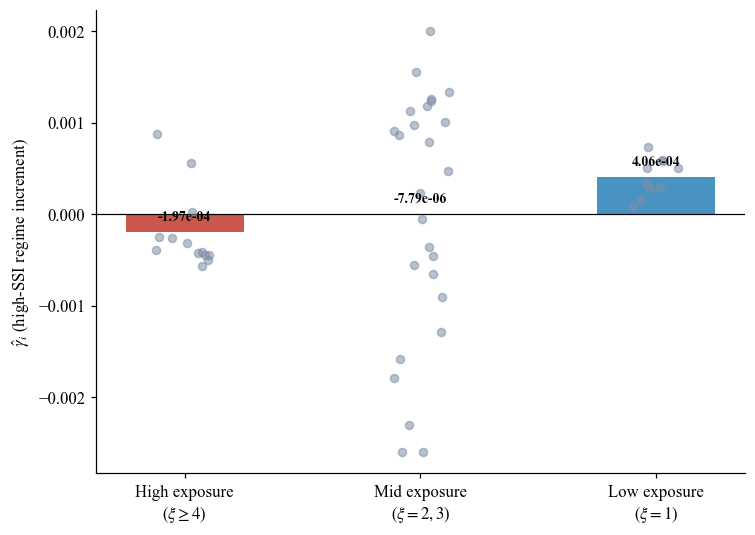

✓ Saved to /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/fig_tier_amplification.png


In [83]:
# =============================================================================
# FIGURE 1: SSI regime amplification by exposure tier
# Requires gamma_all_df with a "tier" column (run the tier cell, ~cell 95, first)
# =============================================================================
import matplotlib.pyplot as plt
import numpy as np

assert "gamma_all_df" in dir() and "tier" in gamma_all_df.columns, \
    "Run the tier-assignment cell first (adds 'tier' to gamma_all_df)."

TIER_ORDER = ["High (xi>=4)", "Mid (xi=2-3)", "Low (xi<=1)"]
TIER_LABELS = ["High exposure\n($\\xi \\geq 4$)", "Mid exposure\n($\\xi = 2,3$)", "Low exposure\n($\\xi = 1$)"]
tier_means = [gamma_all_df.loc[gamma_all_df["tier"] == t, "b_regime_increment"].mean() for t in TIER_ORDER]

fig, ax = plt.subplots(figsize=(7, 5))

# individual industry points, jittered on x for visibility
rng = np.random.default_rng(0)
for xpos, t in enumerate(TIER_ORDER):
    sub = gamma_all_df[gamma_all_df["tier"] == t]
    jitter = rng.uniform(-0.12, 0.12, size=len(sub))
    ax.scatter(np.full(len(sub), xpos) + jitter, sub["b_regime_increment"],
               alpha=0.55, s=28, color="#7f8fa6", zorder=2)

# tier means as bars
ax.bar(range(3), tier_means, width=0.5, color=["#c0392b", "#7f8c8d", "#2980b9"],
       alpha=0.85, zorder=1)
ax.axhline(0, color="black", linewidth=0.8, zorder=1)

ax.set_xticks(range(3))
ax.set_xticklabels(TIER_LABELS)
ax.set_ylabel(r"$\hat{\gamma}_i$ (high-SSI regime increment)")

for xpos, m in enumerate(tier_means):
    ax.annotate(f"{m:.2e}", (xpos, m), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(figdir / "fig_tier_amplification.png", dpi=300, bbox_inches="tight")
plt.savefig(figdir / "fig_tier_amplification.pdf", bbox_inches="tight")
plt.show()
print(f"✓ Saved to {figdir / 'fig_tier_amplification.png'}")

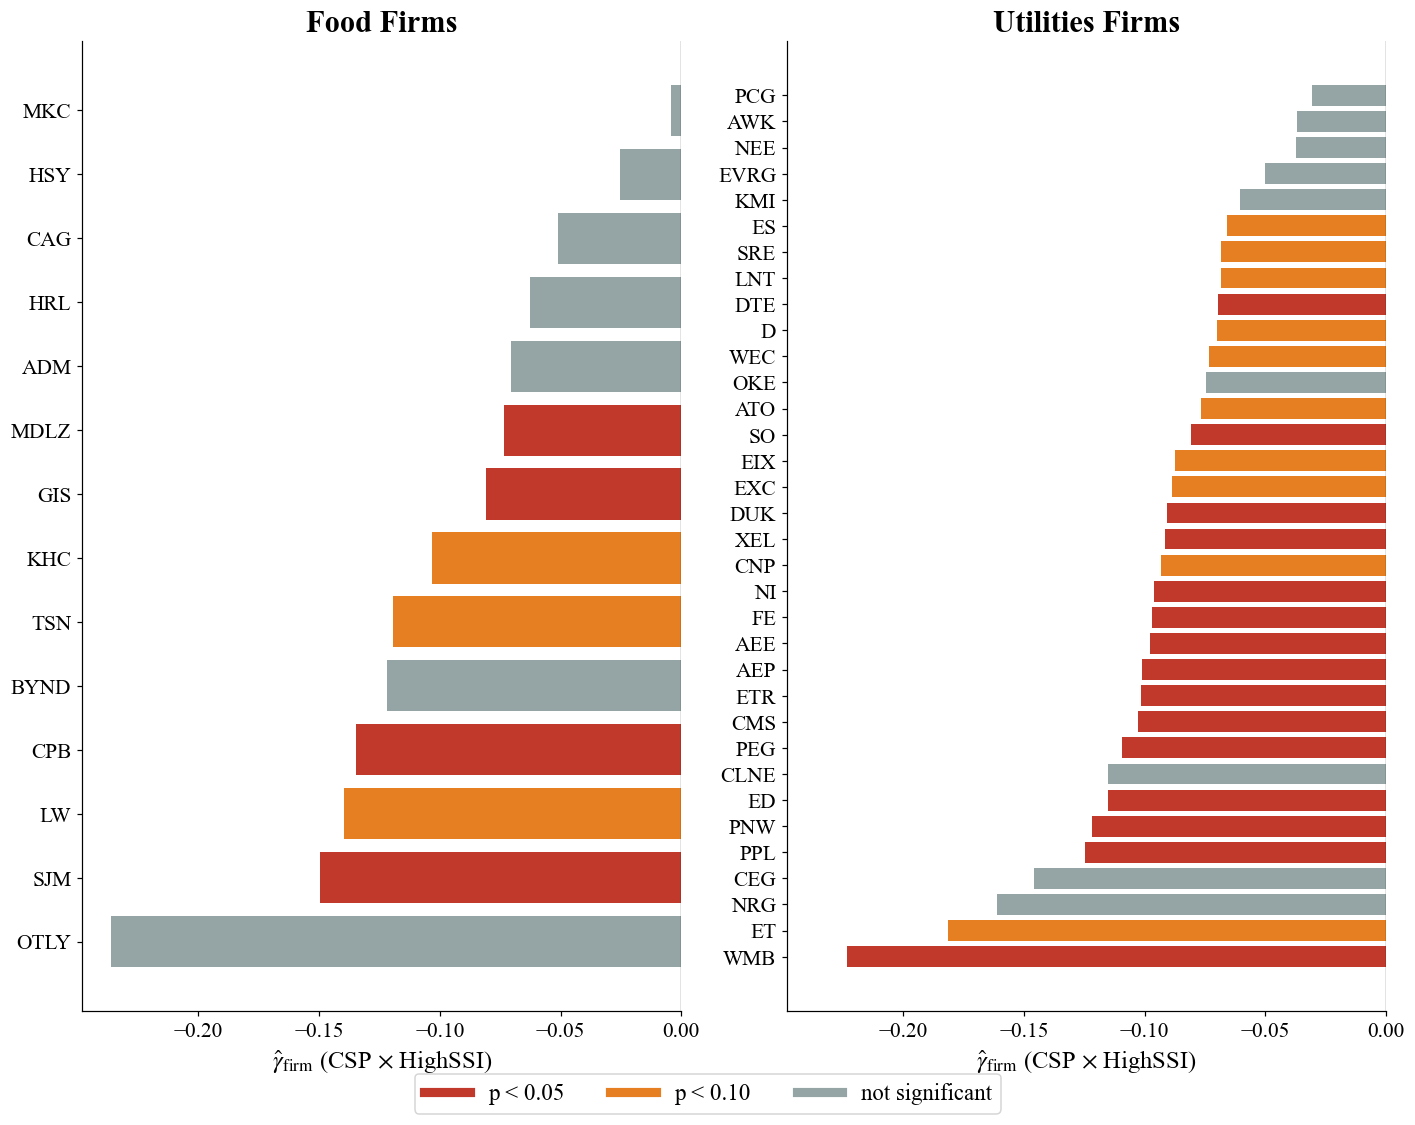

✓ Saved to /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/fig_firm_level.png


In [90]:
# =============================================================================
# FIGURE 2: Firm-level regime coefficients, Food and Utilities
# Requires firm_betas_food.csv and firm_betas_util.csv (saved by cell 110)
# =============================================================================
import matplotlib.pyplot as plt
import pandas as pd

food_df = pd.read_csv(figdir / "firm_betas_food.csv")
util_df = pd.read_csv(figdir / "firm_betas_util.csv")

food_df = food_df[food_df["note"] == "ok"].sort_values("b_regime")
util_df = util_df[util_df["note"] == "ok"].sort_values("b_regime")

def sig_color(p):
    if p < 0.05: return "#c0392b"
    elif p < 0.10: return "#e67e22"
    else: return "#95a5a6"

fig, axes = plt.subplots(1, 2, figsize=(13, 10), sharex=True)

titles = ["Food Firms", "Utilities Firms"]

for ax, df, title in zip(axes, [food_df, util_df], titles):
    colors = [sig_color(p) for p in df["p_regime"]]
    ax.barh(df["ticker"], df["b_regime"], color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title, fontsize=20, fontweight="bold")
    ax.set_xlabel(r"$\hat{\gamma}_{\mathrm{firm}}$ (CSP $\times$ HighSSI)", fontsize=16)
    ax.tick_params(axis="both", labelsize=14)

legend_elems = [
    plt.Line2D([0], [0], color="#c0392b", lw=6, label="p < 0.05"),
    plt.Line2D([0], [0], color="#e67e22", lw=6, label="p < 0.10"),
    plt.Line2D([0], [0], color="#95a5a6", lw=6, label="not significant"),
]
fig.legend(handles=legend_elems, loc="lower center", ncol=3,
           bbox_to_anchor=(0.5, -0.03), fontsize=15)
plt.tight_layout()
plt.savefig(figdir / "fig_firm_level.png", dpi=300, bbox_inches="tight")
plt.savefig(figdir / "fig_firm_level.pdf", bbox_inches="tight")
plt.show()
print(f"✓ Saved to {figdir / 'fig_firm_level.png'}")

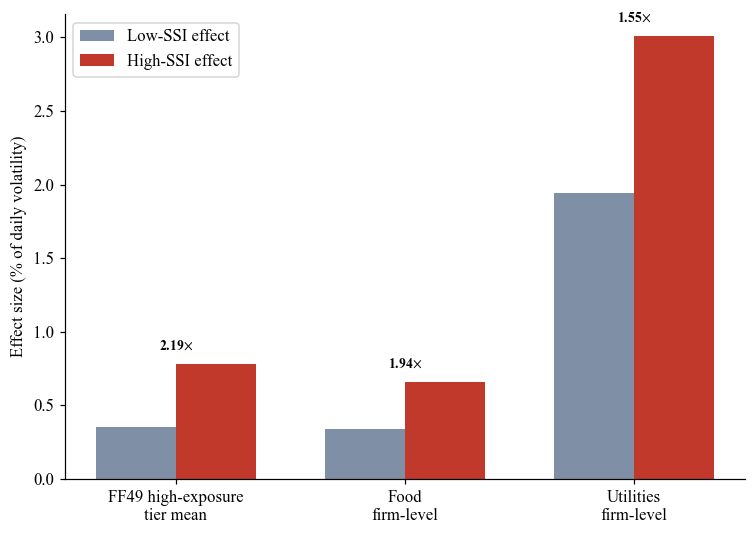

✓ Saved to /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/fig_economic_size.png

Values used (pulled live from ssi_conditional_economic_effects.csv):
  FF49 high-exposure tier mean: low=0.36%  high=0.78%
  Food firm-level: low=0.34%  high=0.66%
  Utilities firm-level: low=1.94%  high=3.01%


In [91]:
# =============================================================================
# FIGURE 3: Economic effect size, low- vs high-SSI regime
# Reads live from ssi_conditional_economic_effects.csv, saved by the
# Conditionality cell (~112) — no hardcoded values, so this can't drift
# out of sync with whatever that cell most recently computed.
# =============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

econ_df = pd.read_csv(figdir / "ssi_conditional_economic_effects.csv")

# Map this cell's display labels to the 'label' strings written by cell 112,
# in the display order we want (FF49 tier mean, then Food, then Utilities).
label_map = {
    "FF49 high-exposure\ntier mean": "FF49, mean high-exposure industry (CSP_xi units)",
    "Food\nfirm-level":               "Food (firm-level, raw CSP units)",
    "Utilities\nfirm-level":          "Util (firm-level, raw CSP units)",
}

missing = [src for src in label_map.values() if src not in econ_df["label"].values]
if missing:
    raise KeyError(
        f"ssi_conditional_economic_effects.csv is missing expected label(s): {missing}\n"
        f"Available labels: {econ_df['label'].tolist()}\n"
        f"Re-run the Conditionality cell (~112) first, or update label_map above "
        f"if the labels there have changed."
    )

labels   = list(label_map.keys())
low_ssi  = [econ_df.loc[econ_df["label"] == src, "pct_low"].iloc[0]  * 100 for src in label_map.values()]
high_ssi = [econ_df.loc[econ_df["label"] == src, "pct_high"].iloc[0] * 100 for src in label_map.values()]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(x - width/2, low_ssi, width, label="Low-SSI effect", color="#7f8fa6")
ax.bar(x + width/2, high_ssi, width, label="High-SSI effect", color="#c0392b")

for i in range(len(labels)):
    ratio = high_ssi[i] / low_ssi[i]
    ax.annotate(f"{ratio:.2f}$\\times$", (x[i], max(low_ssi[i], high_ssi[i]) + 0.1),
                ha="center", fontsize=9, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Effect size (% of daily volatility)")
ax.legend()

plt.tight_layout()
plt.savefig(figdir / "fig_economic_size.png", dpi=300, bbox_inches="tight")
plt.savefig(figdir / "fig_economic_size.pdf", bbox_inches="tight")
plt.show()
print(f"✓ Saved to {figdir / 'fig_economic_size.png'}")
print("\nValues used (pulled live from ssi_conditional_economic_effects.csv):")
for lbl, lo, hi in zip(labels, low_ssi, high_ssi):
    print(f"  {lbl.replace(chr(10), ' ')}: low={lo:.2f}%  high={hi:.2f}%")

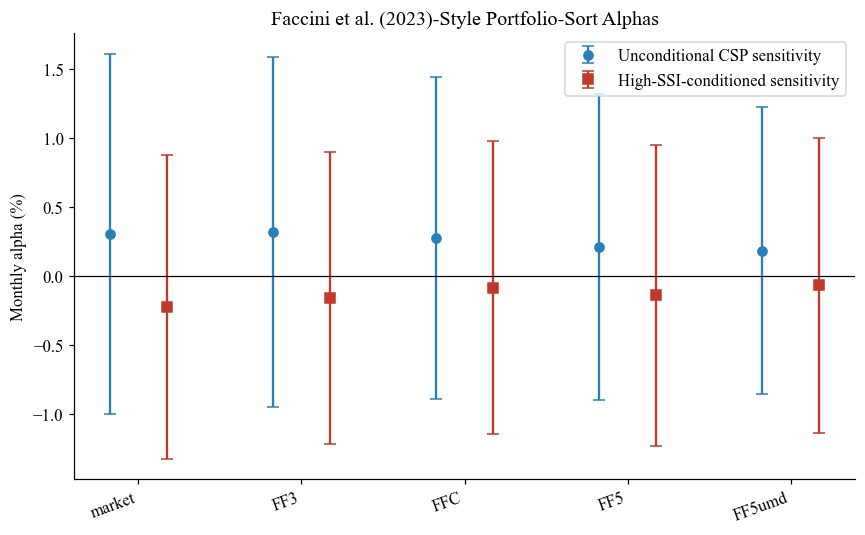

✓ Saved to /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/fig_faccini.png


In [86]:
# =============================================================================
# FIGURE 4: Faccini et al. (2023)-style portfolio-sort alphas
# Requires alpha_df (unconditional) and cond_alpha_df (conditional),
# saved by the Faccini section cells (~115, ~117). Loads from CSV if not
# already in memory.
# =============================================================================
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

if "alpha_df" not in dir():
    alpha_df = pd.read_csv(figdir / "faccini_spread_portfolio_alphas.csv")
if "cond_alpha_df" not in dir():
    cond_alpha_df = pd.read_csv(figdir / "faccini_conditional_spread_alphas.csv")

def add_ci(df, alpha_col="alpha_pct_month", t_col="t_stat"):
    df = df.copy()
    df["se"] = df[alpha_col] / df[t_col]
    df["ci_lo"] = df[alpha_col] - 1.96 * df["se"]
    df["ci_hi"] = df[alpha_col] + 1.96 * df["se"]
    return df

alpha_df = add_ci(alpha_df)
cond_alpha_df = add_ci(cond_alpha_df)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(alpha_df))
width = 0.35

ax.errorbar(x - width/2, alpha_df["alpha_pct_month"],
            yerr=[alpha_df["alpha_pct_month"] - alpha_df["ci_lo"],
                  alpha_df["ci_hi"] - alpha_df["alpha_pct_month"]],
            fmt="o", color="#2980b9", label="Unconditional CSP sensitivity", capsize=4)

ax.errorbar(x + width/2, cond_alpha_df["alpha_pct_month"],
            yerr=[cond_alpha_df["alpha_pct_month"] - cond_alpha_df["ci_lo"],
                  cond_alpha_df["ci_hi"] - cond_alpha_df["alpha_pct_month"]],
            fmt="s", color="#c0392b", label="High-SSI-conditioned sensitivity", capsize=4)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(alpha_df["model"], rotation=20, ha="right")
ax.set_ylabel("Monthly alpha (%)")
ax.set_title("Faccini et al. (2023)-Style Portfolio-Sort Alphas")
ax.legend()

plt.tight_layout()
plt.savefig(figdir / "fig_faccini.png", dpi=300, bbox_inches="tight")
plt.savefig(figdir / "fig_faccini.pdf", bbox_inches="tight")
plt.show()
print(f"✓ Saved to {figdir / 'fig_faccini.png'}")

In [87]:
# =============================================================================
# TABLE: SSI regime amplification, high-exposure industries (xi >= 4)
# Reads directly from gamma_all_df (built in the "all-49-industry gamma" cell,
# ~cell 93). This is the same clean, deduplicated panel49 already used for
# the tier table — no new regression, just correctly formatted extraction
# for the per-industry table.
# =============================================================================
import pandas as pd
import numpy as np

assert "gamma_all_df" in dir(), "Run the all-49-industry gamma cell (cell 93) first."

def stars(p):
    if p < 0.01: return "***"
    elif p < 0.05: return "**"
    elif p < 0.10: return "*"
    return ""

# add 'sig' to the full dataframe once, so it's available everywhere below
gamma_all_df = gamma_all_df.copy()
gamma_all_df["sig"] = gamma_all_df["p_regime_increment"].apply(stars)

high_exp = gamma_all_df[gamma_all_df["xi"] >= 4].copy().sort_values("b_regime_increment")

cols = ["industry", "xi", "b_CSP_xi_baseline", "p_CSP_xi_baseline",
        "b_regime_increment", "p_regime_increment", "sig"]

print("── High-exposure industries (xi >= 4), sorted by gamma ──")
display(high_exp[cols])

n_neg = (high_exp["b_regime_increment"] < 0).sum()
n_total = len(high_exp)
print(f"\nNegative gamma_i: {n_neg}/{n_total}")

print(f"\nMean gamma (high-exposure tier): {high_exp['b_regime_increment'].mean():.4e}")
print("Compare against tab:regime_tier: mean should be -1.97e-04, 10/13 (77%)")

for name_guess in ["Food", "Util", "Utilities", "Food & Beverages", "FoodBev"]:
    hit = gamma_all_df[gamma_all_df["industry"].str.contains(name_guess, case=False, na=False)]
    if len(hit):
        print(f"\nMatch for '{name_guess}':")
        display(hit[cols])

high_exp[cols].to_csv(figdir / "regime_highexposure_table_verified.csv", index=False)
print(f"\n✓ Saved to {figdir / 'regime_highexposure_table_verified.csv'}")

── High-exposure industries (xi >= 4), sorted by gamma ──


,industry,xi,b_CSP_xi_baseline,p_CSP_xi_baseline,b_regime_increment,p_regime_increment,sig
18,Food,4.000000,0.000028,0.841261,-0.000565,0.036849,**
25,Insur,4.000000,0.000136,0.459381,-0.000504,0.145655,
35,RlEst,5.000000,0.000069,0.624627,-0.000447,0.145138,
47,Util,5.000000,0.000155,0.075224,-0.000445,0.010807,**
31,Oil,5.000000,0.000118,0.395735,-0.000421,0.200494,
38,Ships,4.000000,0.000081,0.742839,-0.000412,0.464401,
45,Trans,4.000000,0.000128,0.527423,-0.000396,0.327924,
33,Paper,4.000000,0.000073,0.669920,-0.000316,0.377653,
9,Chems,4.000000,0.000009,0.961205,-0.000262,0.518573,
12,Cnstr,4.000000,0.000307,0.250451,-0.000254,0.627762,



Negative gamma_i: 10/13

Mean gamma (high-exposure tier): -1.9727e-04
Compare against tab:regime_tier: mean should be -1.97e-04, 10/13 (77%)

Match for 'Food':


,industry,xi,b_CSP_xi_baseline,p_CSP_xi_baseline,b_regime_increment,p_regime_increment,sig
18,Food,4.000000,0.000028,0.841261,-0.000565,0.036849,**



Match for 'Util':


,industry,xi,b_CSP_xi_baseline,p_CSP_xi_baseline,b_regime_increment,p_regime_increment,sig
47,Util,5.000000,0.000155,0.075224,-0.000445,0.010807,**



✓ Saved to /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/regime_highexposure_table_verified.csv


In [88]:
# =============================================================================
# TABLE: SSI regime results for the remaining 36 industries (xi < 4)
# Reads directly from gamma_all_df (same source as the high-exposure table).
# No new regression — just the mid- and low-exposure tiers, for completeness
# alongside the high-exposure table already built.
# =============================================================================
import pandas as pd
import numpy as np

assert "gamma_all_df" in dir(), "Run the all-49-industry gamma cell (cell 93) first."

def stars(p):
    if p < 0.01: return "***"
    elif p < 0.05: return "**"
    elif p < 0.10: return "*"
    return ""

gamma_all_df = gamma_all_df.copy()
if "sig" not in gamma_all_df.columns:
    gamma_all_df["sig"] = gamma_all_df["p_regime_increment"].apply(stars)

remaining = gamma_all_df[gamma_all_df["xi"] < 4].copy().sort_values("b_regime_increment")

cols = ["industry", "xi", "b_CSP_xi_baseline", "p_CSP_xi_baseline",
        "b_regime_increment", "p_regime_increment", "sig"]

print(f"── Mid- and low-exposure industries (xi < 4), n={len(remaining)} ──")
display(remaining[cols])

# split for direct comparison against tab:regime_tier's mid/low rows
mid = remaining[remaining["xi"].isin([2, 3])]
low = remaining[remaining["xi"] < 2]

print(f"\nMid exposure (xi=2,3): n={len(mid)}")
print(f"  Negative gamma: {(mid['b_regime_increment'] < 0).sum()}/{len(mid)}")
print(f"  Mean gamma: {mid['b_regime_increment'].mean():.4e}")
print(f"  Significant at p<0.10: {(mid['p_regime_increment'] < 0.10).sum()}")

print(f"\nLow exposure (xi=1): n={len(low)}")
print(f"  Negative gamma: {(low['b_regime_increment'] < 0).sum()}/{len(low)}")
print(f"  Mean gamma: {low['b_regime_increment'].mean():.4e}")
print(f"  Significant at p<0.10: {(low['p_regime_increment'] < 0.10).sum()}")

# check specifically against the tier table's named low-exposure industries
print("\n── Named low-exposure industries from tab:regime_tier ──")
for name_guess in ["Guns", "MedEq", "Softw", "Books"]:
    hit = gamma_all_df[gamma_all_df["industry"].str.contains(name_guess, case=False, na=False)]
    if len(hit):
        display(hit[cols])
    else:
        print(f"  No match found for '{name_guess}' — check actual industry label spelling.")

remaining[cols].to_csv(figdir / "regime_remaining36_table_verified.csv", index=False)
print(f"\n✓ Saved to {figdir / 'regime_remaining36_table_verified.csv'}")

── Mid- and low-exposure industries (xi < 4), n=36 ──


,industry,xi,b_CSP_xi_baseline,p_CSP_xi_baseline,b_regime_increment,p_regime_increment,sig
3,Banks,3.000000,0.000568,0.452642,-0.002602,0.150823,
5,BldMt,3.000000,0.001003,0.267411,-0.002601,0.138280,
7,Boxes,3.000000,0.001011,0.185006,-0.002299,0.143295,
11,Clths,3.000000,0.000060,0.943716,-0.001789,0.313063,
37,Rubbr,3.000000,0.000511,0.474167,-0.001583,0.266787,
4,Beer,3.000000,-0.000338,0.503290,-0.001292,0.266850,
46,Txtls,3.000000,0.000367,0.731090,-0.000902,0.689123,
2,Autos,2.000000,0.000320,0.611257,-0.000655,0.657749,
20,Gold,3.000000,-0.001451,0.227698,-0.000555,0.821795,
39,Smoke,2.000000,0.000448,0.215861,-0.000451,0.579522,



Mid exposure (xi=2,3): n=26
  Negative gamma: 12/26
  Mean gamma: -7.7935e-06
  Significant at p<0.10: 0

Low exposure (xi=1): n=10
  Negative gamma: 0/10
  Mean gamma: 4.0624e-04
  Significant at p<0.10: 4

── Named low-exposure industries from tab:regime_tier ──


,industry,xi,b_CSP_xi_baseline,p_CSP_xi_baseline,b_regime_increment,p_regime_increment,sig
21,Guns,1.000000,-0.000113,0.448900,0.000592,0.046329,**


,industry,xi,b_CSP_xi_baseline,p_CSP_xi_baseline,b_regime_increment,p_regime_increment,sig
29,MedEq,1.000000,-0.000089,0.538930,0.000506,0.080842,*


,industry,xi,b_CSP_xi_baseline,p_CSP_xi_baseline,b_regime_increment,p_regime_increment,sig
41,Softw,1.000000,-0.000213,0.240148,0.000580,0.088460,*


,industry,xi,b_CSP_xi_baseline,p_CSP_xi_baseline,b_regime_increment,p_regime_increment,sig
6,Books,1.000000,-0.000229,0.229910,0.000732,0.091590,*



✓ Saved to /Users/adammcguire/Desktop/Submission Ready/Visuals/Industry/regime_remaining36_table_verified.csv
